# Replikasi: *Mission-Phase Feature Learning for eVTOL Li-Ion Battery Prognostics* (Batteries 2026, 12, 322)
Benchmark **leakage-safe, cell-held-out** untuk **SOC, SOH(m+5), RUL90/85/80** pada dataset CMU eVTOL (22 sel VAH, 19 sel setelah penyaringan label).

**Catatan kejujuran replikasi (baca dulu):**
1. Repo resmi memuat skrip *benchmark* terkoreksi (`sequence_benchmark.py`, `baseline_gate.py`, `aggregate_benchmark.py`) dan spesifikasi prosedural (`preprocessing_and_targets.md`, `pipeline.json`), tetapi **paket `evt_battery/` (rekonstruksi mentah → fitur) tidak ikut ter-commit**. Tabel fitur yang ada di repo adalah versi *legacy*. Karena itu tahap rekonstruksi di notebook ini **ditulis ulang dari spesifikasi tertulis**; angka akhir bisa berbeda tipis dari paper (cek jumlah sampel di sel audit: target 18.513 / 5.814 / 9.595 / 8.257).
2. Arsitektur (Attention-LSTM-MoE, MP-Transformer), loop pelatihan, split LOCO, dan *scaler* mengikuti kode resmi (jumlah parameter Transformer = 160.417, identik dengan log repo).
3. Isi Tabel 2a (20 fitur fase), hiperparameter pohon (Tabel 4) dan konfigurasi ablasi (Tabel 7) **direkonstruksi** dari deskripsi paper + repo karena teks tabel tidak bisa diakses; sesuaikan di `evtol/config.py` / `evtol/tables.py` bila paper memakai nama lain.
4. Mode `PROFILE="smoke"` hanya uji cepat (3 sel, 3 epoch). Angka paper hanya bisa didekati dengan `PROFILE="full"` (GPU disarankan, beberapa jam).

## 1. Setup lingkungan & unduh data

In [ ]:
import subprocess, sys, importlib, importlib.util, os
need = {"xgboost":"xgboost","catboost":"catboost","lightgbm":"lightgbm","seaborn":"seaborn","sklearn":"scikit-learn","torch":"torch"}
miss = [p for m,p in need.items() if importlib.util.find_spec(m) is None]
if miss: subprocess.check_call([sys.executable,"-m","pip","install","-q",*miss])
# repo resmi: dipakai sebagai referensi (spesifikasi, angka terbit); pipeline di bawah mandiri
if not os.path.exists("/content/official_repo"):
    subprocess.call(["git","clone","--depth","1","https://github.com/MusaWiston/Mission-Phase-Feature-Learning-for-eVTOL-Battery-Prognostics-with-ML.git","/content/official_repo"])
import torch; print("torch", torch.__version__, "| GPU:", torch.cuda.is_available())

torch 2.11.0+cpu | GPU: False


Modul Python (`evtol/`) ditulis ke disk oleh sel-sel `%%writefile` berikut. Setiap modul berdiri sendiri dan dijelaskan di docstring-nya.

In [ ]:
from pathlib import Path

pkg = Path("/content/evtol")
pkg.mkdir(parents=True, exist_ok=True)

(pkg / "__init__.py").write_text(
    '"""eVTOL replication package."""\n',
    encoding="utf-8"
)

print("Folder package berhasil dibuat:", pkg)
print("File __init__.py:", (pkg / "__init__.py").exists())

Folder package berhasil dibuat: /content/evtol
File __init__.py: True


In [ ]:
%%writefile /content/evtol/config.py
"""Central configuration. Values come from the official repo (config/pipeline.json,
sequence_benchmark.py, baseline_gate.py). Changing any value = a different protocol."""
from pathlib import Path

SEED = 1337
EXCLUDED_CELLS = ["VAH06", "VAH07", "VAH09"]          # excluded from health benchmark -> 19 cells
SOH_K = 5                                              # SOH horizon (missions)
THRESHOLDS = [90.0, 85.0, 80.0]                        # EOL thresholds (% of BOL capacity)
MAX_STEPS_MISSION = 20                                 # causal mission history
MAX_STEPS_PHASE = 16                                   # SOC phase window

REST_CURRENT_A = 0.05
MAX_SAMPLE_GAP_S = 60.0
FLIGHT_CODES = [4, 5, 6]                               # take-off, cruise, landing
CHARGE_CODES = [0, 1]                                  # CC, CV
PHASE_NAMES = {0: "CC", 1: "CV", 2: "CV-to-Rest", 3: "Rest-to-Take-off", 4: "Take-off",
               5: "Cruise", 6: "Landing", 7: "Landing-to-Rest", 8: "Rest1", 9: "Rest2"}

# ---- Table 1: C/5 RPT detector (all four criteria must hold, no score, no fallback) ----
RPT = dict(
    nominal_capacity_ah=3.0, reference_c_rate=0.2, current_rel_tol=0.35,
    min_ref_current_time_fraction=0.70,
    min_start_voltage_v=4.10, max_end_voltage_v=2.55, min_voltage_span_v=1.40,
    min_capacity_ah=1.50, max_capacity_ah=3.75,        # 0.5 and 1.25 x 3.0 Ah
    min_discharge_duration_s=7200.0,
    expected_spacing_missions=50, spacing_tolerance_missions=5,   # audit only
)
CV_SETPOINT_V = {"VAH07": 4.0, "VAH23": 4.1}
DEFAULT_CV_SETPOINT_V = 4.2

# ---- Table 2a: 20 phase-level predictors (taxonomy reconstructed from the paper text +
#      repo feature_dictionary.csv; verify names against the paper's Table 2) ----
PHASE_FEATURES = [
    "ph_dur_s", "ph_energy_Wh_abs", "ph_mean_I_A", "ph_max_abs_I_A", "ph_mean_C_rate",
    "ph_max_C_rate", "ph_mean_P_W_abs", "ph_max_P_W_abs", "ph_V_start", "ph_V_end",
    "ph_V_mean", "ph_V_min", "ph_V_drop", "ph_vi_slope_ohm", "ph_T_mean_C",
    "ph_T_max_C", "ph_T_start_C", "ph_dT_C", "ph_thermal_slope_K_s", "ph_thermal_gain_K_W",
]
# ---- Table 2b: 20 mission-level predictors ("manuscript20" manifest of baseline_gate.py) ----
MISSION_FEATURES = [
    "chg_total_dur_s", "chg_energy_Wh", "chg_mean_I_A", "chg_mean_C_rate", "chg_cc_dur_s",
    "chg_cc_energy_Wh", "chg_cv_dur_s", "chg_cv_energy_Wh", "chg_cv_fraction", "cv_setpoint_V",
    "dis_total_dur_s", "dis_flight_Wh_abs", "dis_mean_C_rate", "dis_max_C_rate",
    "dis_vi_R_ohm_med", "temp_mean_C", "temp_max_C_max", "gap_count", "chg_cum_Wh", "dis_cum_Wh",
]
MISSION_FEATURE_GROUPS = {
    "Charging (CC/CV)": MISSION_FEATURES[:10],
    "Flight discharge": MISSION_FEATURES[10:15],
    "Thermal / data quality": MISSION_FEATURES[15:18],
    "Cumulative throughput (causal)": MISSION_FEATURES[18:],
}

# task -> (target column(s), upper clamp)
TASKS = {
    "soh":   (["SOH_m_plus_5_pct"], 100.0),
    "rul90": (["RUL90_missions"], None),
    "rul85": (["RUL85_missions"], None),
    "rul80": (["RUL80_missions"], None),
    "rul_joint": (["RUL90_missions", "RUL85_missions", "RUL80_missions"], None),
}

# ---- Table 4: fixed hyper-parameters ----
HP = dict(hidden=96, dropout=0.15, batch_size=64, max_epochs=60, patience=8, lr=2e-3,
          weight_decay=1e-4, grad_clip=1.0, n_experts=6, topk=2, moe_balance_weight=0.02,
          mono_weight=0.02, n_heads=4, ffn=384, tcn_kernel=3, tcn_levels=3, inner_folds=3)
TREE_HP = dict(n_estimators=600, min_samples_leaf=2, lr=0.05, max_depth=6, subsample=0.8, colsample=0.8)

# Published reference points available in the official repo (aggregate_benchmark / baseline_gate)
PUBLISHED_SUPPORT = {"soh": (18513, 19), "rul90": (5814, 19), "rul85": (9595, 16), "rul80": (8257, 8)}
PUBLISHED_TREES = {  # pooled MAE from the repo's baseline_gate.py (Extra Trees / RF, last-mission features)
    "soh": {"extra_trees": 0.610, "random_forest": 0.635},
    "rul90": {"extra_trees": 24.934, "random_forest": 24.698},
    "rul85": {"extra_trees": 44.149, "random_forest": 47.294},
    "rul80": {"extra_trees": 119.172, "random_forest": 118.905},
}


Writing /content/evtol/config.py


In [ ]:
%%writefile /content/evtol/data_io.py
"""Download / load the CMU eVTOL dataset (KiltHub / figshare article 14226830)."""
import json, zipfile, urllib.request
from pathlib import Path
import numpy as np, pandas as pd

REQUIRED = ["time_s", "Ecell_V", "I_mA", "QDischarge_mA_h", "QCharge_mA_h",
            "Temperature__C", "cycleNumber", "Ns"]


def download_cmu(dest="/content/cmu_evtol", article_id=14226830):
    """Uses the public figshare API (works in Colab). Returns directory with VAH*.csv."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    meta = json.load(urllib.request.urlopen(f"https://api.figshare.com/v2/articles/{article_id}"))
    for f in meta["files"]:
        out = dest / f["name"]
        if out.exists() and out.stat().st_size == f["size"]:
            continue
        print("downloading", f["name"], f"{f['size']/1e6:.1f} MB")
        urllib.request.urlretrieve(f["download_url"], out)
        if out.suffix == ".zip":
            with zipfile.ZipFile(out) as z:
                z.extractall(dest)
    return dest


def find_cell_files(root, pattern="VAH*.csv"):
    files = sorted(Path(root).rglob(pattern))
    if not files:
        raise FileNotFoundError(f"no {pattern} under {root}")
    return files


def load_cell(path):
    """Read one cell; fail (do not impute) on missing/non-finite required values."""
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    lower = {c.lower(): c for c in df.columns}
    rename = {}
    for r in REQUIRED:
        if r in df.columns: continue
        if r.lower() in lower: rename[lower[r.lower()]] = r
    df = df.rename(columns=rename)
    missing = [c for c in REQUIRED if c not in df.columns]
    if missing:
        raise ValueError(f"{path}: missing columns {missing}; found {list(df.columns)}")
    df = df[REQUIRED].astype(float)
    if not np.isfinite(df.to_numpy()).all():
        raise ValueError(f"{path}: non-finite values in required columns")
    return df.reset_index(drop=True)


Writing /content/evtol/data_io.py


In [ ]:
%%writefile /content/evtol/reconstruct.py
"""Chronological reconstruction, Table-1 RPT detector, phase/mission features, leakage-safe targets.

Equations
  dt_i       : seconds inside a phase run; first row of a run and gaps > 60 s contribute 0
  E_s        = sum_i V_i I_i dt_i / 3600                                   [Wh]
  Q_j        = (max Qdis - min Qdis) / 1000                                [Ah]  (per RPT)
  SOH_j      = 100 Q_j / Q_0   (Q_0 = first chronological valid RPT)
  SOH(m)     = linear interpolation between bracketing RPTs; NaN outside (no extrapolation)
  y_SOH(m)   = SOH(m+5)
  m_EOL,th   = min{m : SOH(m) <= th};  RUL_th(m) = max(0, m_EOL - m); NaN + censored if never reached
  SOC_i      = clip_[0,100]( 100 + 100 * sum_{k<=i} I_k dt_k/3600 / Q_m )  (coulomb counting from take-off)
"""
import numpy as np, pandas as pd
from . import config as C


# --------------------------------------------------------------------------- rows
def prepare_rows(raw: pd.DataFrame) -> pd.DataFrame:
    t = raw.time_s.to_numpy(); cyc = raw.cycleNumber.to_numpy(); ns = raw.Ns.to_numpy().astype(int)
    n = len(raw)
    new_cyc = np.ones(n, bool)
    new_cyc[1:] = (cyc[1:] != cyc[:-1]) | (t[1:] < t[:-1])        # counter change OR clock reset
    cid = np.cumsum(new_cyc)
    new_run = new_cyc.copy(); new_run[1:] |= ns[1:] != ns[:-1]
    rid = np.cumsum(new_run)
    dt_raw = np.zeros(n); dt_raw[1:] = t[1:] - t[:-1]; dt_raw[new_run] = 0.0
    gap = dt_raw > C.MAX_SAMPLE_GAP_S
    dt = np.where(gap, 0.0, dt_raw)
    I = raw.I_mA.to_numpy() / 1000.0
    return pd.DataFrame(dict(cid=cid, rid=rid, raw_cycle=cyc, ns=ns, t=t, V=raw.Ecell_V.to_numpy(), I=I,
                             Qdis=raw.QDischarge_mA_h.to_numpy(), T=raw.Temperature__C.to_numpy(),
                             dt=dt, gap=gap.astype(int)))


# --------------------------------------------------------------------------- Table 1
def detect_rpt(df: pd.DataFrame, cfg=C.RPT) -> pd.DataFrame:
    """Protocol-based C/5 RPT detector; returns one audited row per reconstructed cycle."""
    ref = cfg["nominal_capacity_ah"] * cfg["reference_c_rate"]
    lo, hi = ref * (1 - cfg["current_rel_tol"]), ref * (1 + cfg["current_rel_tol"])   # 0.39-0.81 A
    D = (df.I < -C.REST_CURRENT_A).to_numpy()
    absI = df.I.abs().to_numpy()
    c5 = D & (absI >= lo) & (absI <= hi)
    g = df.assign(dtD=df.dt.to_numpy() * D, dtC5=df.dt.to_numpy() * c5).groupby("cid")
    idx = pd.DataFrame({
        "raw_cycle": g.raw_cycle.first(),
        "dis_dur_s": g.dtD.sum(), "c5_dur_s": g.dtC5.sum(),
        "q_dis_ah": (g.Qdis.max() - g.Qdis.min()) / 1000.0,
    })
    dd = df[D].groupby("cid")
    idx["v_start"] = dd.V.first(); idx["v_min"] = dd.V.min()
    idx = idx.fillna({"dis_dur_s": 0, "c5_dur_s": 0})
    idx["v_span"] = idx.v_start - idx.v_min
    idx["c5_fraction"] = np.where(idx.dis_dur_s > 0, idx.c5_dur_s / idx.dis_dur_s.replace(0, np.nan), 0.0)
    idx["current_ok"] = idx.c5_fraction >= cfg["min_ref_current_time_fraction"]
    idx["voltage_ok"] = ((idx.v_start >= cfg["min_start_voltage_v"]) & (idx.v_min <= cfg["max_end_voltage_v"])
                         & (idx.v_span >= cfg["min_voltage_span_v"]))
    idx["capacity_ok"] = idx.q_dis_ah.between(cfg["min_capacity_ah"], cfg["max_capacity_ah"])
    idx["duration_ok"] = idx.dis_dur_s >= cfg["min_discharge_duration_s"]
    idx["is_capacity_test"] = idx.current_ok & idx.voltage_ok & idx.capacity_ok & idx.duration_ok
    return idx


def _has_flight_subsequence(seq):
    need = list(C.FLIGHT_CODES); k = 0
    for s in seq:
        if k < len(need) and s == need[k]: k += 1
    return k == len(need)


def index_cycles(df):
    idx = detect_rpt(df)
    runs = df.groupby("rid").agg(cid=("cid", "first"), ns=("ns", "first"))
    seqs = runs.groupby("cid").ns.apply(list)
    idx["has_flight"] = seqs.reindex(idx.index).apply(_has_flight_subsequence)
    idx["is_mission"] = idx.has_flight & ~idx.is_capacity_test
    idx["mission_id"] = np.where(idx.is_mission, np.cumsum(idx.is_mission.to_numpy()), 0)
    before = np.cumsum(idx.is_mission.to_numpy()) - idx.is_mission.to_numpy()      # complete missions before
    idx["missions_before"] = before
    return idx


def capacity_tests(cell_id, idx):
    rpt = idx[idx.is_capacity_test].copy()
    rpt = rpt.reset_index().rename(columns={"cid": "cycle_instance_id"})
    if rpt.empty:
        return rpt.assign(cell_id=cell_id, position=[], capacity_ah=[], soh_pct=[], spacing=[], spacing_flag=[])
    rpt["cell_id"] = cell_id
    rpt["position"] = rpt.missions_before
    rpt["capacity_ah"] = rpt.q_dis_ah
    rpt["soh_pct"] = 100.0 * rpt.capacity_ah / rpt.capacity_ah.iloc[0]
    rpt["spacing"] = rpt.position.diff()
    e, tol = C.RPT["expected_spacing_missions"], C.RPT["spacing_tolerance_missions"]
    rpt["spacing_flag"] = rpt.spacing.notna() & ((rpt.spacing - e).abs() > tol)     # audit only
    return rpt[["cell_id", "cycle_instance_id", "raw_cycle", "position", "capacity_ah", "soh_pct",
                "c5_fraction", "v_start", "v_min", "dis_dur_s", "spacing", "spacing_flag"]]


# --------------------------------------------------------------------------- SOH / RUL labels
def soh_anchors(rpt):
    """Position -> SOH anchors. Duplicate positions -> median, except the first anchor (first chronological RPT)."""
    if rpt.empty: return np.array([]), np.array([])
    pos = rpt.position.to_numpy(); soh = rpt.soh_pct.to_numpy()
    P, S = np.unique(pos), []
    for i, p in enumerate(P):
        v = soh[pos == p]
        S.append(v[0] if i == 0 else float(np.median(v)))
    return P.astype(float), np.asarray(S, float)


def interpolate_soh(rpt, n_missions):
    P, S = soh_anchors(rpt)
    m = np.arange(1, n_missions + 1, dtype=float)
    if len(P) < 2: return np.full(n_missions, np.nan)
    return np.interp(m, P, S, left=np.nan, right=np.nan)      # no extrapolation / fill


def make_targets(soh):
    """soh: SOH at mission end for missions 1..M (NaN where unsupported)."""
    M = len(soh); out = {}
    fut = np.full(M, np.nan); fut[:M - C.SOH_K] = soh[C.SOH_K:]
    out["SOH_m_plus_5_pct"] = fut                                  # NaN unless both ends are interpolated
    out["dSOH_5_pct"] = np.where(np.isfinite(fut) & np.isfinite(soh), np.maximum(0, soh - fut), np.nan)
    finite = np.isfinite(soh); m = np.arange(1, M + 1)
    for th in C.THRESHOLDS:
        hit = np.where(finite & (soh <= th))[0]
        key = f"RUL{int(th)}"
        if len(hit):
            eol = m[hit[0]]
            out[f"{key}_missions"] = np.where(finite, np.maximum(0, eol - m), np.nan).astype(float)
            out[f"{key}_censored"] = np.zeros(M, bool)
        else:                                                       # right-censored: never substitute last mission
            out[f"{key}_missions"] = np.full(M, np.nan)
            out[f"{key}_censored"] = finite.copy()
    return out


# --------------------------------------------------------------------------- features
def run_table(df, mission_cyc_ids, q0):
    """Aggregate per phase run for mission cycles. Predictors only; targets added later."""
    d = df[df.cid.isin(mission_cyc_ids)].copy()
    d["P"] = d.V * d.I; d["E"] = d.P * d.dt / 3600.0; d["Idt"] = d.I * d.dt; d["aIdt"] = d.I.abs() * d.dt
    d["absI"] = d.I.abs(); d["absP"] = d.P.abs(); d["VI"] = d.V * d.I; d["I2"] = d.I * d.I
    g = d.groupby("rid")
    r = pd.DataFrame({"cid": g.cid.first(), "ns": g.ns.first(), "n": g.size(),
                      "dur": g.dt.sum(), "E": g.E.sum(), "Idt": g.Idt.sum(), "aIdt": g.aIdt.sum(),
                      "I_mean": g.I.mean(), "I_max_abs": g.absI.max(), "P_mean_abs": g.absP.mean(), "P_max_abs": g.absP.max(),
                      "V_start": g.V.first(), "V_end": g.V.last(), "V_mean": g.V.mean(), "V_min": g.V.min(),
                      "T_mean": g["T"].mean(), "T_max": g["T"].max(), "T_start": g["T"].first(), "T_end": g["T"].last(),
                      "mV": g.V.mean(), "mI": g.I.mean(), "mVI": g.VI.mean(), "mI2": g.I2.mean()})
    var = r.mI2 - r.mI ** 2
    r["vi_slope"] = np.where(var > 1e-6, (r.mVI - r.mV * r.mI) / var.where(var > 1e-6), np.nan)
    dur = r.dur.replace(0, np.nan)
    f = pd.DataFrame(index=r.index)
    f["ph_dur_s"] = r.dur
    f["ph_energy_Wh_abs"] = r.E.abs()
    f["ph_mean_I_A"] = r.I_mean
    f["ph_max_abs_I_A"] = r.I_max_abs
    f["ph_mean_C_rate"] = (r.aIdt / dur) / q0
    f["ph_max_C_rate"] = r.I_max_abs / q0
    f["ph_mean_P_W_abs"] = r.P_mean_abs
    f["ph_max_P_W_abs"] = r.P_max_abs
    f["ph_V_start"] = r.V_start; f["ph_V_end"] = r.V_end; f["ph_V_mean"] = r.V_mean; f["ph_V_min"] = r.V_min
    f["ph_V_drop"] = r.V_start - r.V_end
    f["ph_vi_slope_ohm"] = r.vi_slope
    f["ph_T_mean_C"] = r.T_mean; f["ph_T_max_C"] = r.T_max; f["ph_T_start_C"] = r.T_start
    f["ph_dT_C"] = r.T_end - r.T_start
    f["ph_thermal_slope_K_s"] = (r.T_max - r.T_mean) / dur
    f["ph_thermal_gain_K_W"] = f.ph_thermal_slope_K_s / r.P_mean_abs.replace(0, np.nan)
    return r, f[C.PHASE_FEATURES]


def mission_features(cell_id, r, cyc_rows, idx, q0):
    """One chronological row per mission (predictors only)."""
    mis = idx[idx.is_mission]
    rows = []
    chg = r[r.ns.isin(C.CHARGE_CODES)].groupby("cid"); fl = r[r.ns.isin(C.FLIGHT_CODES)].groupby("cid")
    cc = r[r.ns == 0].groupby("cid"); cv = r[r.ns == 1].groupby("cid")
    f = pd.DataFrame(index=mis.index)
    s = lambda grp, col: grp[col].sum().reindex(mis.index).fillna(0.0)
    f["chg_total_dur_s"] = s(chg, "dur"); f["chg_energy_Wh"] = s(chg, "E")
    f["chg_cc_dur_s"] = s(cc, "dur"); f["chg_cc_energy_Wh"] = s(cc, "E")
    f["chg_cv_dur_s"] = s(cv, "dur"); f["chg_cv_energy_Wh"] = s(cv, "E")
    Idt = s(chg, "Idt"); aIdt_f = s(fl, "aIdt")
    f["chg_mean_I_A"] = Idt / f.chg_total_dur_s.replace(0, np.nan)
    f["chg_mean_C_rate"] = f.chg_mean_I_A / q0
    f["chg_cv_fraction"] = f.chg_cv_dur_s / f.chg_total_dur_s.replace(0, np.nan)
    f["cv_setpoint_V"] = C.CV_SETPOINT_V.get(cell_id, C.DEFAULT_CV_SETPOINT_V)
    f["dis_total_dur_s"] = s(fl, "dur"); f["dis_flight_Wh_abs"] = s(fl, "E").abs()
    f["dis_mean_C_rate"] = (aIdt_f / f.dis_total_dur_s.replace(0, np.nan)) / q0
    f["dis_max_C_rate"] = fl.I_max_abs.max().reindex(mis.index) / q0
    f["dis_vi_R_ohm_med"] = fl.vi_slope.median().reindex(mis.index)
    f["temp_mean_C"] = cyc_rows.T_mean.reindex(mis.index); f["temp_max_C_max"] = cyc_rows.T_max.reindex(mis.index)
    f["gap_count"] = cyc_rows.gap.reindex(mis.index)
    f["chg_cum_Wh"] = f.chg_energy_Wh.cumsum(); f["dis_cum_Wh"] = f.dis_flight_Wh_abs.cumsum()   # causal
    f.insert(0, "mission_id", mis.mission_id.astype(int)); f.insert(0, "cycle_instance_id", mis.index)
    f.insert(0, "cell_id", cell_id)
    return f.reset_index(drop=True)


def soc_per_run(df, r, mission_map, qm_by_mission):
    """Coulomb-counted SOC change per flight phase run (target context; never a predictor)."""
    d = df[df.cid.isin(mission_map.index)][["cid", "rid", "ns", "I", "dt"]].copy()
    d["flight"] = d.ns.isin(C.FLIGHT_CODES).astype(int)
    d["started"] = d.groupby("cid").flight.cummax()
    d["x"] = d.I * d.dt / 3600.0 * d.started
    d["cum"] = d.groupby("cid").x.cumsum()
    q = d.cid.map(mission_map).map(qm_by_mission)
    d["soc"] = np.clip(100.0 + 100.0 * d.cum / q, 0, 100)
    d.loc[q.isna(), "soc"] = np.nan
    g = d[d.flight == 1].groupby("rid")
    return (g.soc.last() - g.soc.first())


# --------------------------------------------------------------------------- one cell
def build_cell(cell_id, raw, verbose=True):
    df = prepare_rows(raw)
    idx = index_cycles(df)
    rpt = capacity_tests(cell_id, idx)
    q0 = float(rpt.capacity_ah.iloc[0]) if len(rpt) else C.RPT["nominal_capacity_ah"]
    mis_idx = idx[idx.is_mission]
    n_m = len(mis_idx)
    soh = interpolate_soh(rpt, n_m)
    tg = make_targets(soh)
    r, fph = run_table(df, set(mis_idx.index), q0)
    cyc_rows = df[df.cid.isin(mis_idx.index)].groupby("cid").agg(T_mean=("T", "mean"), T_max=("T", "max"), gap=("gap", "sum"))
    mf = mission_features(cell_id, r, cyc_rows, idx, q0)
    mf["SOH_end_pct"] = soh
    for k, v in tg.items(): mf[k] = v
    # SOC context
    cid2m = mis_idx.mission_id
    qm = pd.Series(soh / 100.0 * q0, index=cid2m.to_numpy())           # mission capacity (Ah)
    dsoc = soc_per_run(df, r, cid2m, qm)
    ph = pd.concat([r[["cid", "ns"]], fph], axis=1)
    ph = ph[ph.ns.isin(C.FLIGHT_CODES + C.CHARGE_CODES + [2, 3, 7, 8, 9])].reset_index().rename(columns={"rid": "run_id"})
    ph.insert(0, "mission_id", ph.cid.map(cid2m).astype(int)); ph.insert(0, "cell_id", cell_id)
    ph["seg_id"] = ph.groupby("mission_id").cumcount()
    ph["phase_name"] = ph.ns.map(C.PHASE_NAMES)
    ph["is_flight"] = ph.ns.isin(C.FLIGHT_CODES)
    ph["dis_dSOC"] = ph.run_id.map(dsoc)                                  # target context
    ph["dis_dSOC_baseline"] = ph.run_id.map(100.0 * r.Idt / 3600.0 / q0)  # admissible physics baseline
    ph = ph.drop(columns=["cid"]).rename(columns={"ns": "Ns"})
    audit = dict(cell_id=cell_id, cycles=len(idx), rpts=int(idx.is_capacity_test.sum()), missions=int(n_m),
                 q0_ah=q0, soh_supported=int(np.isfinite(soh).sum()), soh_m5_rows=int(np.isfinite(tg["SOH_m_plus_5_pct"]).sum()),
                 spacing_flags=int(rpt.spacing_flag.sum()) if len(rpt) else 0,
                 **{f"{k}_rows": int(np.isfinite(tg[f"{k}_missions"]).sum()) for k in ("RUL90", "RUL85", "RUL80")})
    if verbose: print(audit)
    return dict(cycle_index=idx.reset_index().rename(columns={"cid": "cycle_instance_id"}).assign(cell_id=cell_id),
                rpt=rpt, missions=mf, phases=ph, audit=audit)


def build_all(files, out_dir=None, load=None, exclude=C.EXCLUDED_CELLS, verbose=True):
    """Process every raw cell. Excluded cells are audited but removed from the health benchmark tables."""
    from .data_io import load_cell
    load = load or load_cell
    parts = {k: [] for k in ("cycle_index", "rpt", "missions", "phases")}; audits = []
    for p in files:
        cell = p.stem.split("_")[0].upper() if hasattr(p, "stem") else str(p)
        res = build_cell(cell, load(p), verbose)
        res["audit"]["excluded_from_health_benchmark"] = cell in exclude
        audits.append(res["audit"])
        for k in parts: parts[k].append(res[k])
    out = {k: pd.concat(v, ignore_index=True) for k, v in parts.items()}
    out["audit"] = pd.DataFrame(audits)
    keep = ~out["missions"].cell_id.isin(exclude)
    out["missions_bench"] = out["missions"][keep].reset_index(drop=True)
    out["phases_bench"] = out["phases"][~out["phases"].cell_id.isin(exclude)].reset_index(drop=True)
    if out_dir is not None:
        from pathlib import Path
        Path(out_dir).mkdir(parents=True, exist_ok=True)
        for k, v in out.items(): v.to_csv(Path(out_dir) / f"{k}.csv", index=False)
    return out


Writing /content/evtol/reconstruct.py


In [ ]:
%%writefile /content/evtol/windows.py
"""Sliding-window samples (stride 1, right-padded + validity mask, never crossing a cell boundary)."""
import re
import numpy as np, pandas as pd
from . import config as C

FORBIDDEN = [r"rul", r"eol", r"soh", r"dsoc", r"soc_", r"target", r"future", r"remain", r"label", r"capacity_ah"]


def assert_leakage_safe(features):
    bad = [f for f in features if any(re.search(p, f.lower()) for p in FORBIDDEN)]
    if bad: raise AssertionError(f"target/label-like predictors rejected: {bad}")


def _pad(seq_list, T, D):
    x = np.full((len(seq_list), T, D), np.nan, np.float32); m = np.zeros((len(seq_list), T), bool)
    for i, s in enumerate(seq_list):
        x[i, :len(s)] = s; m[i, :len(s)] = True
    return x, m


def build_mission_samples(missions, task, features=C.MISSION_FEATURES, max_steps=C.MAX_STEPS_MISSION):
    assert_leakage_safe(features)
    cols, _ = C.TASKS[task]
    seqs, ys, cells, mids = [], [], [], []
    for cell, g in missions.groupby("cell_id", sort=True):
        g = g.sort_values("mission_id").reset_index(drop=True)
        X = g[features].to_numpy(np.float32); Y = g[cols].to_numpy(np.float64)
        for i in np.flatnonzero(np.isfinite(Y).any(axis=1)):
            seqs.append(X[max(0, i - max_steps + 1): i + 1]); ys.append(Y[i])
            cells.append(cell); mids.append(int(g.mission_id[i]))
    x, m = _pad(seqs, max_steps, len(features))
    return dict(x=x, mask=m, y=np.asarray(ys, np.float32), cell=np.asarray(cells), mission_id=np.asarray(mids),
                targets=cols, features=list(features), task=task)


def build_phase_samples(phases, features=C.PHASE_FEATURES, max_steps=C.MAX_STEPS_PHASE):
    """SOC task: flight-phase features up to phase t within ONE mission -> observed dSOC of phase t+1."""
    assert_leakage_safe(features)
    seqs, ys, cells, mids, segs = [], [], [], [], []
    fl = phases[phases.is_flight]
    for (cell, mid), g in fl.groupby(["cell_id", "mission_id"], sort=True):
        g = g.sort_values("seg_id"); X = g[features].to_numpy(np.float32); y = g.dis_dSOC.to_numpy(float)
        for end in range(len(g) - 1):
            if not np.isfinite(y[end + 1]): continue
            seqs.append(X[max(0, end - max_steps + 1): end + 1]); ys.append([y[end + 1]])
            cells.append(cell); mids.append(int(mid)); segs.append(int(g.seg_id.iloc[end + 1]))
    x, m = _pad(seqs, max_steps, len(features))
    return dict(x=x, mask=m, y=np.asarray(ys, np.float32), cell=np.asarray(cells), mission_id=np.asarray(mids),
                targets=["dis_dSOC_next"], features=list(features), task="soc")


def flatten_history(x, mask):
    """Tree-model input: the same 20-mission history, newest step last, NaN-padded on the left."""
    N, T, D = x.shape; out = np.full((N, T, D), np.nan, np.float32)
    L = mask.sum(1)
    for i in range(N): out[i, T - L[i]:] = x[i, :L[i]]
    return np.concatenate([out.reshape(N, T * D), L[:, None].astype(np.float32)], axis=1)


def last_step(x, mask):
    L = mask.sum(1); return x[np.arange(len(x)), L - 1]


def audit_support(samples_by_task):
    rows = []
    for t, s in samples_by_task.items():
        pub = C.PUBLISHED_SUPPORT.get(t)
        rows.append(dict(task=t, n=len(s["y"]), cells=len(np.unique(s["cell"])),
                         published_n=pub[0] if pub else None, published_cells=pub[1] if pub else None))
    return pd.DataFrame(rows)


Writing /content/evtol/windows.py


In [ ]:
%%writefile /content/evtol/models.py
"""Sequence models. All take (x [B,T,D] standardized, mask [B,T] bool) and return (y [B,k], attn, gate_logits).
Right-padded inputs; the last valid step is index mask.sum(1)-1."""
import math
import torch, torch.nn as nn, torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from . import config as C

H, DROP = C.HP["hidden"], C.HP["dropout"]


def _lengths(mask): return mask.sum(1).to(torch.int64)
def _gather_last(h, mask): return h[torch.arange(h.size(0), device=h.device), _lengths(mask) - 1]


class TimeAttention(nn.Module):
    """alpha = softmax( (W_q h_T)(W_k H)^T / sqrt(d) ) over valid steps; context = alpha W_v H."""
    def __init__(self, w):
        super().__init__(); self.q, self.k, self.v = nn.Linear(w, w), nn.Linear(w, w), nn.Linear(w, w)
    def forward(self, hidden, query, mask):
        q = self.q(query).unsqueeze(1); k = self.k(hidden); v = self.v(hidden)
        logits = ((q * k).sum(-1) / math.sqrt(k.size(-1))).masked_fill(~mask, -1e9)
        a = torch.softmax(logits, 1)
        return torch.bmm(a.unsqueeze(1), v).squeeze(1), a


def _head(d_in, n_out):
    return nn.Sequential(nn.Linear(d_in, H), nn.ReLU(), nn.Dropout(DROP), nn.Linear(H, n_out))


class AttentionLSTMMoE(nn.Module):
    """Masked LSTM -> temporal attention pool -> [context ; h_T] -> gate (E experts) -> top-k sparse mixture.
    y = sum_{e in topk} pi_e * Expert_e(z),  pi = softmax over the k largest gate logits.
    use_moe=False  -> plain Attention-LSTM head;  use_attention=False -> h_T only (context := h_T)."""
    def __init__(self, d_in, n_out=1, n_experts=C.HP["n_experts"], topk=C.HP["topk"], use_moe=True,
                 use_attention=True, nonneg=False):
        super().__init__()
        self.lstm = nn.LSTM(d_in, H, batch_first=True)
        self.att = TimeAttention(H); self.use_attention = use_attention
        self.use_moe, self.topk, self.nonneg, self.E = use_moe, topk, nonneg, n_experts
        if use_moe:
            self.gate = nn.Linear(2 * H, n_experts)
            self.experts = nn.ModuleList([_head(2 * H, n_out) for _ in range(n_experts)])
        else:
            self.head = _head(2 * H, n_out)
    def forward(self, x, mask):
        packed = pack_padded_sequence(x, _lengths(mask).cpu(), batch_first=True, enforce_sorted=False)
        hp, (hT, _) = self.lstm(packed)
        h, _ = pad_packed_sequence(hp, batch_first=True, total_length=x.size(1)); hT = hT[-1]
        if self.use_attention: ctx, a = self.att(h, hT, mask)
        else: ctx, a = hT, None
        z = torch.cat([ctx, hT], -1); gl = None
        if self.use_moe:
            gl = self.gate(z); prob = torch.softmax(gl, -1)
            k = min(self.topk or self.E, self.E)
            tv, ti = torch.topk(prob, k, -1)
            sparse = torch.zeros_like(prob).scatter(1, ti, tv)
            sparse = sparse / sparse.sum(-1, keepdim=True).clamp_min(1e-12)
            outs = torch.stack([e(z) for e in self.experts], 1)            # [B,E,k_out]
            y = (sparse.unsqueeze(-1) * outs).sum(1)
        else:
            y = self.head(z)
        return (F.softplus(y) if self.nonneg else y), a, gl


class PositionalEncoding(nn.Module):
    def __init__(self, w, T=C.MAX_STEPS_MISSION + 4):
        super().__init__()
        pos = torch.arange(T).float().unsqueeze(1); div = torch.exp(torch.arange(0, w, 2).float() * (-math.log(10000.0) / w))
        pe = torch.zeros(T, w); pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x): return x + self.pe[:, :x.size(1)]


class MissionPhaseTransformer(nn.Module):
    """Linear projection + sinusoidal PE + 1 pre-norm encoder layer (4 heads, FFN 384) + mask-aware attention pool."""
    def __init__(self, d_in, n_out=1, nonneg=False):
        super().__init__()
        self.proj = nn.Linear(d_in, H); self.pos = PositionalEncoding(H)
        layer = nn.TransformerEncoderLayer(H, C.HP["n_heads"], C.HP["ffn"], DROP, "relu", batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, 1, enable_nested_tensor=False)
        self.att = TimeAttention(H); self.head = _head(2 * H, n_out); self.nonneg = nonneg
    def forward(self, x, mask):
        h = self.enc(self.pos(self.proj(x)), src_key_padding_mask=~mask)
        last = _gather_last(h, mask); ctx, a = self.att(h, last, mask)
        y = self.head(torch.cat([ctx, last], -1))
        return (F.softplus(y) if self.nonneg else y), a, None


class GRUNet(nn.Module):
    def __init__(self, d_in, n_out=1):
        super().__init__(); self.rnn = nn.GRU(d_in, H, batch_first=True); self.head = _head(H, n_out)
    def forward(self, x, mask):
        _, hT = self.rnn(pack_padded_sequence(x, _lengths(mask).cpu(), batch_first=True, enforce_sorted=False))
        return self.head(hT[-1]), None, None


class BiLSTMNet(nn.Module):
    def __init__(self, d_in, n_out=1):
        super().__init__(); self.rnn = nn.LSTM(d_in, H, batch_first=True, bidirectional=True); self.head = _head(2 * H, n_out)
    def forward(self, x, mask):
        _, (hT, _) = self.rnn(pack_padded_sequence(x, _lengths(mask).cpu(), batch_first=True, enforce_sorted=False))
        return self.head(torch.cat([hT[-2], hT[-1]], -1)), None, None


class _TCNBlock(nn.Module):
    def __init__(self, cin, cout, k, dil):
        super().__init__(); self.pad = (k - 1) * dil
        self.c1 = nn.Conv1d(cin, cout, k, dilation=dil); self.c2 = nn.Conv1d(cout, cout, k, dilation=dil)
        self.drop = nn.Dropout(DROP); self.res = nn.Conv1d(cin, cout, 1) if cin != cout else nn.Identity()
    def forward(self, x):                                      # x [B,C,T]; causal left padding
        y = self.drop(F.relu(self.c1(F.pad(x, (self.pad, 0))))); y = self.drop(F.relu(self.c2(F.pad(y, (self.pad, 0)))))
        return F.relu(y + self.res(x))


class TCNNet(nn.Module):
    """Causal dilated TCN (dilations 1,2,4); read-out at last valid step (right padding is never seen causally)."""
    def __init__(self, d_in, n_out=1):
        super().__init__()
        ch = [d_in] + [H] * C.HP["tcn_levels"]
        self.blocks = nn.Sequential(*[_TCNBlock(ch[i], ch[i + 1], C.HP["tcn_kernel"], 2 ** i) for i in range(C.HP["tcn_levels"])])
        self.head = _head(H, n_out)
    def forward(self, x, mask):
        h = self.blocks(x.transpose(1, 2)).transpose(1, 2)
        return self.head(_gather_last(h, mask)), None, None


class GRN(nn.Module):
    """Gated residual network (TFT): LN( x + GLU(W2 ELU(W1 x)) )."""
    def __init__(self, d, dout=None):
        super().__init__(); dout = dout or d
        self.f1, self.f2, self.glu = nn.Linear(d, d), nn.Linear(d, d), nn.Linear(d, 2 * dout)
        self.skip = nn.Linear(d, dout) if dout != d else nn.Identity(); self.ln = nn.LayerNorm(dout); self.drop = nn.Dropout(DROP)
    def forward(self, x):
        h = self.drop(self.f2(F.elu(self.f1(x)))); return self.ln(self.skip(x) + F.glu(self.glu(h), -1))


class TFTLite(nn.Module):
    """Temporal-Fusion-Transformer-style model: per-step variable selection (softmax-weighted GRNs) -> LSTM encoder
    -> gated skip -> masked multi-head self-attention -> GRN -> last valid step. (Compact TFT; no static covariates.)"""
    def __init__(self, d_in, n_out=1):
        super().__init__()
        self.d_in = d_in; self.var_proj = nn.ModuleList([nn.Linear(1, H) for _ in range(d_in)])
        self.var_grn = nn.ModuleList([GRN(H) for _ in range(d_in)]); self.sel = nn.Linear(d_in, d_in)
        self.lstm = nn.LSTM(H, H, batch_first=True); self.gate_ln = nn.LayerNorm(H); self.gate = nn.Linear(H, 2 * H)
        self.mha = nn.MultiheadAttention(H, C.HP["n_heads"], dropout=DROP, batch_first=True); self.post = GRN(H)
        self.head = _head(H, n_out)
    def forward(self, x, mask):
        emb = torch.stack([g(p(x[..., i:i + 1])) for i, (p, g) in enumerate(zip(self.var_proj, self.var_grn))], 2)  # B,T,D,H
        w = torch.softmax(self.sel(x), -1).unsqueeze(-1); z = (emb * w).sum(2)                                        # B,T,H
        hp, _ = self.lstm(pack_padded_sequence(z, _lengths(mask).cpu(), batch_first=True, enforce_sorted=False))
        h, _ = pad_packed_sequence(hp, batch_first=True, total_length=x.size(1))
        h = self.gate_ln(z + F.glu(self.gate(h), -1))
        att, a = self.mha(h, h, h, key_padding_mask=~mask, need_weights=True)
        h = self.post(h + att)
        return self.head(_gather_last(h, mask)), None, None


def make_model(name, d_in, n_out=1, **kw):
    if name == "attention_lstm_moe": return AttentionLSTMMoE(d_in, n_out, **kw)
    if name == "attention_lstm": return AttentionLSTMMoE(d_in, n_out, use_moe=False, **kw)
    if name == "mission_phase_transformer": return MissionPhaseTransformer(d_in, n_out)
    if name == "bilstm": return BiLSTMNet(d_in, n_out)
    if name == "gru": return GRUNet(d_in, n_out)
    if name == "tcn": return TCNNet(d_in, n_out)
    if name == "tft": return TFTLite(d_in, n_out)
    raise KeyError(name)

SEQ_MODELS = ["attention_lstm_moe", "mission_phase_transformer", "bilstm", "gru", "tcn", "tft"]


Writing /content/evtol/models.py


In [ ]:
%%writefile /content/evtol/loco.py
"""Outer Leave-One-Cell-Out (LOCO) protocol. Scaling, imputation, target normalisation, early stopping and
isotonic calibration only ever see TRAINING / inner-VALIDATION cells; the test cell is untouched until scoring."""
import json, math, random, time
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from sklearn.isotonic import IsotonicRegression
from . import config as C
from .models import make_model
from .windows import flatten_history, last_step

HP = C.HP
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def set_seed(seed=C.SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


# ------------------------------------------------------------------ splits / scaling
def balanced_inner_folds(cells, train_idx, n_folds=HP["inner_folds"]):
    """Deterministic, sample-count-balanced assignment of training cells to inner folds (fold 0 = validation)."""
    counts = pd.Series(cells[train_idx]).value_counts().to_dict(); tot = [0] * n_folds; out = {}
    for cell, n in sorted(counts.items(), key=lambda kv: (-kv[1], kv[0])):
        f = min(range(n_folds), key=lambda i: (tot[i], i)); out[str(cell)] = f; tot[f] += int(n)
    return out


def loco_split(cells, test_cell):
    all_idx = np.arange(len(cells)); test = all_idx[cells == test_cell]; outer = all_idx[cells != test_cell]
    a = balanced_inner_folds(cells, outer)
    val_cells = sorted(c for c, f in a.items() if f == 0)
    val = outer[np.isin(cells[outer], val_cells)]; tr = outer[~np.isin(cells[outer], val_cells)]
    assert not set(cells[test]) & set(cells[outer]), "test cell leaked into training"
    return tr, val, test, val_cells


class FoldScaler:
    """Median-impute + z-score fitted on valid TRAIN rows only; padded positions forced to 0."""
    def fit(self, x, mask):
        v = x[mask]; self.med = np.nanmedian(v, 0); self.med = np.where(np.isfinite(self.med), self.med, 0.0)
        f = np.where(np.isfinite(v), v, self.med); self.mu = f.mean(0); sd = f.std(0); self.sd = np.where(sd > 1e-8, sd, 1.0)
        return self
    def transform(self, x, mask):
        z = (np.where(np.isfinite(x), x, self.med) - self.mu) / self.sd; z[~mask] = 0.0; return z.astype(np.float32)


class DS(Dataset):
    def __init__(self, x, m, y, idx): self.x, self.m, self.y = torch.from_numpy(x[idx]), torch.from_numpy(m[idx]), torch.from_numpy(y[idx])
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.x[i], self.m[i], self.y[i]


# ------------------------------------------------------------------ neural training
def _upper(task, k):
    u = C.TASKS[task][1] if task in C.TASKS else None
    return np.array([np.inf if u is None else u] * k)


@torch.no_grad()
def predict(model, loader, mean, std, upper):
    model.eval(); out = []
    for x, m, _ in loader:
        o, _, _ = model(x.to(DEVICE), m.to(DEVICE)); out.append(o.cpu().numpy())
    p = np.concatenate(out) * std + mean
    return np.clip(p, 0.0, upper)


def masked_smooth_l1(out, y):
    ok = torch.isfinite(y); y0 = torch.where(ok, y, torch.zeros_like(y))
    l = nn.functional.smooth_l1_loss(out, y0, reduction="none", beta=1.0)
    return (l * ok).sum() / ok.sum().clamp_min(1)


def train_fold(model_name, x, m, y, tr, va, task, ckpt, model_kw=None, mono=False, balance=True, hp=HP, max_epochs=None):
    set_seed(); k = y.shape[1]; model_kw = model_kw or {}
    mean = np.nanmean(y[tr], 0); std = np.nanstd(y[tr], 0); std = np.where(std < 1e-8, 1.0, std)
    ys = ((y - mean) / std).astype(np.float32)
    model = make_model(model_name, x.shape[-1], k, **model_kw).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=hp["lr"], weight_decay=hp["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, "min", factor=0.5, patience=3)
    g = torch.Generator().manual_seed(C.SEED)
    tl = DataLoader(DS(x, m, ys, tr), batch_size=hp["batch_size"], shuffle=True, generator=g)
    vl = DataLoader(DS(x, m, ys, va), batch_size=hp["batch_size"])
    upper = _upper(task, k); mean_t = torch.tensor(mean, dtype=torch.float32, device=DEVICE); std_t = torch.tensor(std, dtype=torch.float32, device=DEVICE)
    best, best_ep, wait, log = math.inf, -1, 0, []
    ckpt.parent.mkdir(parents=True, exist_ok=True); t0 = time.perf_counter()
    for ep in range(1, (max_epochs or hp["max_epochs"]) + 1):
        model.train(); run = n = 0
        for bx, bm, by in tl:
            bx, bm, by = bx.to(DEVICE), bm.to(DEVICE), by.to(DEVICE)
            out, _, gl = model(bx, bm); task_loss = masked_smooth_l1(out, by); loss = task_loss
            if gl is not None and balance:                               # load-balancing: ||mean(pi) - 1/E||^2
                pm = torch.softmax(gl, -1).mean(0); loss = loss + hp["moe_balance_weight"] * ((pm - 1.0 / pm.numel()) ** 2).sum()
            if mono and k == 3:                                          # RUL80 >= RUL85 >= RUL90  (columns 90,85,80)
                po = out * std_t + mean_t
                pen = (torch.relu(po[:, 0] - po[:, 1]) + torch.relu(po[:, 1] - po[:, 2])).mean() / std_t.mean()
                loss = loss + hp["mono_weight"] * pen
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), hp["grad_clip"]); opt.step()
            run += float(task_loss.detach()) * len(by); n += len(by)
        pv = predict(model, vl, mean, std, upper); tv = y[va]
        err = np.abs(pv - tv); val_mae_cols = np.nanmean(err, 0)
        val_score = float(np.mean(val_mae_cols / std)) if k > 1 else float(val_mae_cols[0])
        sched.step(val_score)
        log.append(dict(epoch=ep, train_loss=run / max(1, n), val_score=val_score, lr=opt.param_groups[0]["lr"]))
        if val_score + 1e-6 < best: best, best_ep, wait = val_score, ep, 0; torch.save(model.state_dict(), ckpt)
        else:
            wait += 1
            if wait >= hp["patience"]: break
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE, weights_only=True))
    info = dict(best_epoch=best_ep, best_val=best, epochs_run=len(log), train_seconds=time.perf_counter() - t0,
                n_params=sum(p.numel() for p in model.parameters()), mean=mean.tolist(), std=std.tolist())
    return model, log, info, (mean, std, upper)


def _long(task, model_name, cell, mids, y, pred, pred_cal, targets, extra=None):
    rows = []
    for j, t in enumerate(targets):
        ok = np.isfinite(y[:, j])
        rows.append(pd.DataFrame(dict(task=task if len(targets) == 1 else t, model=model_name, test_cell=cell, mission_id=mids[ok],
                                      target=t, y_true=y[ok, j], y_pred=pred[ok, j], y_pred_cal=pred_cal[ok, j],
                                      **(extra or {}))))
    d = pd.concat(rows, ignore_index=True); d["error"] = d.y_pred - d.y_true; d["error_cal"] = d.y_pred_cal - d.y_true
    return d


def evaluate_neural(samples, model_name, out_dir, label=None, model_kw=None, mono=False, balance=True,
                    cells=None, hp=HP, max_epochs=None, verbose=True):
    """Outer LOCO for one (task, model). Resumable: finished folds are cached under out_dir."""
    task = samples["task"]; x_raw, mask, y, cell, mid = samples["x"], samples["mask"], samples["y"], samples["cell"], samples["mission_id"]
    label = label or model_name; folds, preds = [], []
    todo = sorted(np.unique(cell)) if cells is None else list(cells)
    for fi, test_cell in enumerate(todo, 1):
        fd = Path(out_dir) / task / label / test_cell; fp, fr = fd / "predictions.csv", fd / "fold.json"
        if fp.exists() and fr.exists():
            preds.append(pd.read_csv(fp)); folds.append(json.loads(fr.read_text())); continue
        tr, va, te, val_cells = loco_split(cell, test_cell)
        sc = FoldScaler().fit(x_raw[tr], mask[tr]); x = sc.transform(x_raw, mask)
        model, log, info, (mean, std, upper) = train_fold(model_name, x, mask, y, tr, va, task, fd / "best.pt", model_kw, mono, balance, hp, max_epochs)
        mk = lambda idx: DataLoader(DS(x, mask, ((y - mean) / std).astype(np.float32), idx), batch_size=hp["batch_size"])
        t0 = time.perf_counter(); pt = predict(model, mk(te), mean, std, upper); inf_ms = 1000 * (time.perf_counter() - t0) / len(te)
        # post-hoc isotonic calibration fitted on inner-validation cells only (never on the test cell)
        pv = predict(model, mk(va), mean, std, upper); pc = pt.copy()
        for j in range(y.shape[1]):
            ok = np.isfinite(y[va, j])
            if ok.sum() >= 30 and np.ptp(pv[ok, j]) > 0:
                pc[:, j] = IsotonicRegression(out_of_bounds="clip").fit(pv[ok, j], y[va, j][ok]).predict(pt[:, j])
        d = _long(task, label, test_cell, mid[te], y[te], pt, pc, samples["targets"])
        mae = float(d.error.abs().mean())
        rec = dict(task=task, model=label, test_cell=test_cell, val_cells=";".join(val_cells), train_n=len(tr), val_n=len(va),
                   test_n=len(te), test_mae=mae, inference_ms=inf_ms, **{k: v for k, v in info.items() if k not in ("mean", "std")})
        fd.mkdir(parents=True, exist_ok=True); d.to_csv(fp, index=False); fr.write_text(json.dumps(rec))
        pd.DataFrame(log).to_csv(fd / "log.csv", index=False)
        preds.append(d); folds.append(rec)
        if verbose: print(f"{task:9s} {label:26s} {fi:02d}/{len(todo)} {test_cell} MAE={mae:.3f} ep={info['best_epoch']} {info['train_seconds']:.0f}s", flush=True)
    return pd.concat(preds, ignore_index=True), pd.DataFrame(folds)


# ------------------------------------------------------------------ trees
def make_tree(name):
    P = C.TREE_HP; s = C.SEED
    if name == "random_forest":
        from sklearn.ensemble import RandomForestRegressor
        return RandomForestRegressor(n_estimators=P["n_estimators"], min_samples_leaf=P["min_samples_leaf"], n_jobs=-1, random_state=s)
    if name == "extra_trees":
        from sklearn.ensemble import ExtraTreesRegressor
        return ExtraTreesRegressor(n_estimators=P["n_estimators"], min_samples_leaf=P["min_samples_leaf"], n_jobs=-1, random_state=s)
    if name == "xgboost":
        from xgboost import XGBRegressor
        return XGBRegressor(n_estimators=P["n_estimators"], learning_rate=P["lr"], max_depth=P["max_depth"], subsample=P["subsample"],
                            colsample_bytree=P["colsample"], tree_method="hist", n_jobs=-1, random_state=s)
    if name == "catboost":
        from catboost import CatBoostRegressor
        return CatBoostRegressor(iterations=P["n_estimators"], learning_rate=P["lr"], depth=P["max_depth"], random_seed=s, verbose=0, thread_count=-1)
    if name == "lightgbm":
        from lightgbm import LGBMRegressor
        return LGBMRegressor(n_estimators=P["n_estimators"], learning_rate=P["lr"], num_leaves=63, subsample=P["subsample"], subsample_freq=1,
                             colsample_bytree=P["colsample"], n_jobs=-1, random_state=s, verbose=-1)
    raise KeyError(name)

TREE_MODELS = ["random_forest", "xgboost", "catboost", "lightgbm"]


def tree_matrix(samples, history="flat20"):
    return flatten_history(samples["x"], samples["mask"]) if history == "flat20" else last_step(samples["x"], samples["mask"])


def evaluate_trees(samples, model_name, history="flat20", cells=None, verbose=True):
    from sklearn.impute import SimpleImputer
    task = samples["task"]; X = tree_matrix(samples, history); y, cell, mid = samples["y"], samples["cell"], samples["mission_id"]
    upper = _upper(task, y.shape[1]); preds = []
    todo = sorted(np.unique(cell)) if cells is None else list(cells)
    for fi, test_cell in enumerate(todo, 1):
        te = np.flatnonzero(cell == test_cell); tr = np.flatnonzero(cell != test_cell)
        imp = SimpleImputer(strategy="median", keep_empty_features=True).fit(X[tr])          # train-only imputation
        Xtr, Xte = imp.transform(X[tr]), imp.transform(X[te]); pt = np.zeros((len(te), y.shape[1]))
        for j in range(y.shape[1]):
            ok = np.isfinite(y[tr, j]); mdl = make_tree(model_name).fit(Xtr[ok], y[tr, j][ok]); pt[:, j] = mdl.predict(Xte)
        pt = np.clip(pt, 0, upper)
        d = _long(task, model_name, test_cell, mid[te], y[te], pt, np.full_like(pt, np.nan), samples["targets"]); preds.append(d)
        if verbose: print(f"{task:9s} {model_name:14s} {fi:02d}/{len(todo)} {test_cell} MAE={d.error.abs().mean():.3f}", flush=True)
    return pd.concat(preds, ignore_index=True)


# ------------------------------------------------------------------ row-random control (leaky by design)
def evaluate_row_random(samples, model_name, kind="tree", n_splits=5, history="flat20", max_epochs=None, verbose=True):
    """Control: random-row K-fold ignores cell identity -> neighbouring missions of the SAME cell land in train and test.
    Preprocessing is still fit on training rows only, so any gain over LOCO is cell/trajectory leakage, not scaling leakage."""
    from sklearn.model_selection import KFold
    from sklearn.impute import SimpleImputer
    task = samples["task"]; y, cell, mid = samples["y"], samples["cell"], samples["mission_id"]; N = len(y)
    upper = _upper(task, y.shape[1]); preds = []
    for f, (tr, te) in enumerate(KFold(n_splits, shuffle=True, random_state=C.SEED).split(np.arange(N))):
        if kind == "tree":
            X = tree_matrix(samples, history); imp = SimpleImputer(strategy="median", keep_empty_features=True).fit(X[tr])
            mdl = make_tree(model_name).fit(imp.transform(X[tr]), y[tr, 0]); pt = np.clip(mdl.predict(imp.transform(X[te]))[:, None], 0, upper)
        else:
            rng = np.random.default_rng(C.SEED + f); perm = rng.permutation(tr); nv = max(1, int(0.15 * len(tr))); va, trn = perm[:nv], perm[nv:]
            sc = FoldScaler().fit(samples["x"][trn], samples["mask"][trn]); x = sc.transform(samples["x"], samples["mask"])
            model, _, _, (mean, std, up) = train_fold(model_name, x, samples["mask"], y, trn, va, task, Path("/tmp/rowrand") / f"{model_name}_{f}.pt", None, False, True, HP, max_epochs)
            pt = predict(model, DataLoader(DS(x, samples["mask"], ((y - mean) / std).astype(np.float32), te), batch_size=HP["batch_size"]), mean, std, up)
        d = pd.DataFrame(dict(task=task, model=model_name, test_cell=cell[te], mission_id=mid[te], y_true=y[te, 0], y_pred=pt[:, 0]))
        d["error"] = d.y_pred - d.y_true; preds.append(d)
        if verbose: print(f"row-random {task} {model_name} fold {f+1}/{n_splits} MAE={d.error.abs().mean():.3f}", flush=True)
    return pd.concat(preds, ignore_index=True)


# ------------------------------------------------------------------ metrics
def summarize(pred, err_col="error"):
    """Pooled MAE/RMSE + cell-level Macro MAE, P90 and worst cell (Table 5 columns)."""
    rows = []
    for (task, model), g in pred.groupby(["task", "model"], sort=False):
        e = g[err_col].dropna(); gc = g.dropna(subset=[err_col]).assign(a=lambda d: d[err_col].abs()).groupby("test_cell").a.mean()
        rows.append(dict(task=task, model=model, cells=gc.size, N=len(e), MAE=e.abs().mean(), RMSE=float(np.sqrt((e ** 2).mean())),
                         MacroMAE=gc.mean(), P90_cell_MAE=float(np.percentile(gc, 90)), Worst_cell_MAE=gc.max(), Worst_cell=gc.idxmax()))
    return pd.DataFrame(rows)


Writing /content/evtol/loco.py


In [ ]:
%%writefile /content/evtol/tables.py
"""Tables 1-7. Tables 1, 2a/2b, 3, 4, 7(config) are descriptive (generated from config.py); Tables 5, 6, 7(results) are computed."""
import numpy as np, pandas as pd
from . import config as C
from .loco import summarize

MODEL_LABEL = {"attention_lstm_moe": "Attention-LSTM-MoE", "mission_phase_transformer": "MP-Transformer", "bilstm": "BiLSTM",
               "gru": "GRU", "tcn": "TCN", "tft": "TFT", "random_forest": "Random Forest", "xgboost": "XGBoost",
               "catboost": "CatBoost", "lightgbm": "LightGBM", "extra_trees": "Extra Trees", "attention_lstm": "Attention-LSTM"}


def table1():
    r = C.RPT; ref = r["nominal_capacity_ah"] * r["reference_c_rate"]
    return pd.DataFrame([
        ["Reference current", f">= {r['min_ref_current_time_fraction']:.0%} of valid discharge time with |I| in "
         f"{ref*(1-r['current_rel_tol']):.2f}-{ref*(1+r['current_rel_tol']):.2f} A (C/5 = {ref:.1f} A, +/-{r['current_rel_tol']:.0%})"],
        ["Full voltage range", f"V_start >= {r['min_start_voltage_v']} V; V_min <= {r['max_end_voltage_v']} V; span >= {r['min_voltage_span_v']} V"],
        ["Plausible capacity", f"within-cycle (max-min) QDischarge in {r['min_capacity_ah']}-{r['max_capacity_ah']} Ah"],
        ["Sufficient duration", f"valid discharge duration >= {r['min_discharge_duration_s']:.0f} s"],
        ["Decision rule", "ALL four true; no score, no best-candidate fallback; incomplete RPTs stay invalid"],
        ["Cadence audit (not a rule)", f"missions between RPTs vs {r['expected_spacing_missions']} +/- {r['spacing_tolerance_missions']} (flag only)"],
        ["Label screening", f"cells {', '.join(C.EXCLUDED_CELLS)} excluded from the health benchmark (19 cells remain of 22)"],
    ], columns=["Criterion", "Checked-in rule"])


_PH_DESC = {
 "ph_dur_s": ("Time", "s", "sum of valid dt in the phase run"), "ph_energy_Wh_abs": ("Energy", "Wh", "|sum V I dt / 3600|"),
 "ph_mean_I_A": ("Current", "A", "mean signed current"), "ph_max_abs_I_A": ("Current", "A", "max |I|"),
 "ph_mean_C_rate": ("C-rate", "1/h", "time-weighted |I| / Q0"), "ph_max_C_rate": ("C-rate", "1/h", "max |I| / Q0 (Q0 = first RPT capacity)"),
 "ph_mean_P_W_abs": ("Power", "W", "mean |V I|"), "ph_max_P_W_abs": ("Power", "W", "max |V I|"),
 "ph_V_start": ("Voltage", "V", "first sample"), "ph_V_end": ("Voltage", "V", "last sample"), "ph_V_mean": ("Voltage", "V", "mean"),
 "ph_V_min": ("Voltage", "V", "minimum"), "ph_V_drop": ("Voltage", "V", "V_start - V_end"),
 "ph_vi_slope_ohm": ("Resistance proxy", "ohm", "OLS slope dV/dI inside phase"),
 "ph_T_mean_C": ("Temperature", "degC", "mean"), "ph_T_max_C": ("Temperature", "degC", "max"), "ph_T_start_C": ("Temperature", "degC", "first sample"),
 "ph_dT_C": ("Temperature", "degC", "T_end - T_start"), "ph_thermal_slope_K_s": ("Thermal response", "K/s", "(Tmax - Tmean)/duration"),
 "ph_thermal_gain_K_W": ("Thermal response", "K/W", "thermal slope / mean |P|"),
}
_MS_DESC = {
 "chg_total_dur_s": "CC+CV charge duration", "chg_energy_Wh": "charge energy", "chg_mean_I_A": "time-weighted charge current",
 "chg_mean_C_rate": "mean charge C-rate (/Q0)", "chg_cc_dur_s": "CC duration", "chg_cc_energy_Wh": "CC energy", "chg_cv_dur_s": "CV duration",
 "chg_cv_energy_Wh": "CV energy", "chg_cv_fraction": "CV / (CC+CV) duration", "cv_setpoint_V": "per-cell CV set-point (4.2 V; VAH07 4.0; VAH23 4.1)",
 "dis_total_dur_s": "take-off+cruise+landing duration", "dis_flight_Wh_abs": "|flight energy|", "dis_mean_C_rate": "time-weighted flight C-rate",
 "dis_max_C_rate": "peak flight C-rate", "dis_vi_R_ohm_med": "median dV/dI over flight phases", "temp_mean_C": "mean cell temperature",
 "temp_max_C_max": "peak cell temperature", "gap_count": "sample gaps > 60 s (data-quality flag)", "chg_cum_Wh": "cumulative charge energy to mission m",
 "dis_cum_Wh": "cumulative flight energy to mission m",
}


def table2a():
    spec = pd.DataFrame([
        ["SOC", "phase sequence (<=16 flight phases, one mission)", "20 phase features", "observed dSOC of next phase (coulomb counting)"],
        ["SOH", "mission history (<=20 missions)", "20 mission features", f"SOH(m+{C.SOH_K}) from linear RPT interpolation"],
        ["RUL90/85/80", "mission history (<=20 missions)", "20 mission features", "missions to first SOH <= threshold (right-censored -> excluded)"],
    ], columns=["Task", "Input window", "Predictors", "Target"])
    ph = pd.DataFrame([[f, *_PH_DESC[f]] for f in C.PHASE_FEATURES], columns=["Feature", "Family", "Unit", "Definition"])
    return spec, ph


def table2b():
    rows = [[g, f, _MS_DESC[f]] for g, fs in C.MISSION_FEATURE_GROUPS.items() for f in fs]
    return pd.DataFrame(rows, columns=["Family", "Feature", "Physical interpretation"])


def table3(param_counts=None):
    pc = param_counts or {}
    rows = [
     ["Attention-LSTM-MoE", "sequence (proposed)", "masked LSTM(96) + temporal attention + 6 experts, top-2 gate, load-balance 0.02", pc.get("attention_lstm_moe")],
     ["MP-Transformer", "sequence", "Linear->sinusoidal PE->1 pre-norm encoder (4 heads, FFN 384)->masked attention pool", pc.get("mission_phase_transformer")],
     ["BiLSTM", "sequence", "bidirectional LSTM(96), [h_fwd;h_bwd] -> MLP", pc.get("bilstm")],
     ["GRU", "sequence", "GRU(96) last hidden -> MLP", pc.get("gru")],
     ["TCN", "sequence", "3 causal dilated residual blocks (k=3, d=1,2,4), last valid step -> MLP", pc.get("tcn")],
     ["TFT (compact)", "sequence", "variable selection GRNs -> LSTM -> gated skip -> MHA(4) -> GRN", pc.get("tft")],
     ["Random Forest", "tree control", "600 trees, min_samples_leaf=2, flattened 20-mission history", None],
     ["XGBoost", "tree control", "600 trees, lr 0.05, depth 6, subsample/colsample 0.8", None],
     ["CatBoost", "tree control", "600 iters, lr 0.05, depth 6", None],
     ["LightGBM", "tree control", "600 trees, lr 0.05, 63 leaves, subsample/colsample 0.8", None],
     ["Optimisation (sequence)", "optimisation", "Adam lr 2e-3, wd 1e-4, SmoothL1(beta=1), grad-clip 1, ReduceLROnPlateau(0.5, p=3), early stop p=8, <=60 epochs", None],
    ]
    return pd.DataFrame(rows, columns=["Model", "Type", "Configuration", "Parameters"])


def table4():
    h, t = C.HP, C.TREE_HP
    rows = [["Seed", C.SEED], ["Hidden width / dropout", f"{h['hidden']} / {h['dropout']}"], ["Batch size", h["batch_size"]],
            ["Max epochs / early-stop patience", f"{h['max_epochs']} / {h['patience']}"], ["LR / weight decay", f"{h['lr']} / {h['weight_decay']}"],
            ["Gradient clip", h["grad_clip"]], ["MoE experts / top-k / balance weight", f"{h['n_experts']} / {h['topk']} / {h['moe_balance_weight']}"],
            ["Monotonic penalty weight (joint RUL)", h["mono_weight"]], ["History length", f"{C.MAX_STEPS_MISSION} missions (SOC: {C.MAX_STEPS_PHASE} phases)"],
            ["SOH horizon K", C.SOH_K], ["RUL thresholds", "90 / 85 / 80 %"], ["Outer validation", "Leave-One-Cell-Out over 19 cells"],
            ["Inner validation", f"{h['inner_folds']} sample-balanced cell folds; fold 0 = validation"],
            ["Preprocessing", "median-impute + z-score fitted on training rows only; target z-scored on training cells"],
            ["Calibration", "isotonic regression fitted on inner-validation cells only"], ["Tree settings", str(t)]]
    return pd.DataFrame(rows, columns=["Item", "Value"])


def table5(pred, models=None):
    s = summarize(pred[pred.task == "soh"]); s["Model"] = s.model.map(MODEL_LABEL)
    s = s.set_index("Model").loc[[MODEL_LABEL[m] for m in (models or s.model) if MODEL_LABEL[m] in set(s.index)]] if models else s.set_index("Model")
    return s[["MAE", "RMSE", "MacroMAE", "P90_cell_MAE", "Worst_cell_MAE", "Worst_cell", "cells", "N"]].round(3).reset_index()


def table6(pred_topk):
    """pred_topk: predictions with label 'moe_top{k}' for RUL85."""
    s = summarize(pred_topk[pred_topk.task == "rul85"]); s["k"] = s.model.str.extract(r"top(\d)").astype(int)
    return s.sort_values("k")[["k", "MAE", "RMSE", "MacroMAE", "P90_cell_MAE", "Worst_cell_MAE"]].round(3).reset_index(drop=True)


ABLATIONS = {   # label -> (description, model, model_kw, mono, balance, joint, calibrated)
    "A0 full":        ("Attention-LSTM-MoE, top-2, attention, balance 0.02", "attention_lstm_moe", {}, False, True, False, False),
    "A1 +isotonic":   ("A0 + post-hoc isotonic calibration", "attention_lstm_moe", {}, False, True, False, True),
    "A2 no-MoE":      ("single MLP head (Attention-LSTM)", "attention_lstm", {}, False, True, False, False),
    "A3 no-attn":     ("context := h_T (attention removed)", "attention_lstm_moe", {"use_attention": False}, False, True, False, False),
    "A4 dense-gate":  ("all 6 experts, soft gate (no top-k sparsity)", "attention_lstm_moe", {"topk": None}, False, True, False, False),
    "A5 no-balance":  ("load-balance weight 0", "attention_lstm_moe", {}, False, False, False, False),
    "A6 joint+mono":  ("joint RUL90/85/80 head + monotonic penalty", "attention_lstm_moe", {}, True, True, True, False),
    "A7 joint":       ("joint RUL90/85/80 head, no penalty", "attention_lstm_moe", {}, False, True, True, False),
}


def table7(results=None):
    rows = [[k, v[0], "post-hoc isotonic (inner-val cells)" if v[6] else "uncalibrated", "joint" if v[5] else "single", "yes" if v[3] else "no"]
            for k, v in ABLATIONS.items()]
    t = pd.DataFrame(rows, columns=["ID", "Configuration", "Calibration status", "Output head", "Monotone penalty"])
    if results is not None: t = t.merge(results, on="ID", how="left")
    return t


def monotonicity_violation(pred_joint):
    """Fraction of (cell, mission) with RUL90 > RUL85 or RUL85 > RUL80 (physically inconsistent)."""
    p = pred_joint.pivot_table(index=["test_cell", "mission_id"], columns="target", values="y_pred").dropna()
    a, b, c = p["RUL90_missions"], p["RUL85_missions"], p["RUL80_missions"]
    return float(((a > b + 1e-6) | (b > c + 1e-6)).mean())


Writing /content/evtol/tables.py


In [ ]:
%%writefile /content/evtol/figures.py
"""Figures 1-7. Okabe-Ito colour-blind-safe palette; every figure is saved as PNG (300 dpi) and SVG."""
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from .tables import MODEL_LABEL

OI = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#F0E442", "#000000"]
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})


def _save(fig, out, name):
    out = Path(out); out.mkdir(parents=True, exist_ok=True)
    fig.savefig(out / f"{name}.png", dpi=300, bbox_inches="tight"); fig.savefig(out / f"{name}.svg", bbox_inches="tight")


def _box(ax, x, y, w, h, text, fc="#E8F1FA", ec="#0072B2", fs=8, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec=ec, lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else "normal", wrap=True)


def _arrow(ax, p, q, **kw):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=11, lw=1.2, color=kw.get("color", "#333"), connectionstyle=kw.get("cs", "arc3")))


def fig1_workflow(out="figures"):
    fig, ax = plt.subplots(figsize=(11, 5.2)); ax.set_xlim(0, 11); ax.set_ylim(0, 5.2); ax.axis("off")
    cols = ["#E8F1FA", "#FDF1DC", "#E3F4EC", "#F7E6EF"]
    steps = [("Raw telemetry\n(22 cells, 21k cycles)\ntime, V, I, Q, T, Ns", 0), ("Cycle reconstruction\ncounter change or\nclock reset = new cycle", 1),
             ("Table-1 C/5 RPT\ndetector (4 rules)\n-> Q_j, Q_0", 2), ("Label screening\nexclude VAH06/07/09\n-> 19 cells", 3)]
    for i, (t, c) in enumerate(steps):
        _box(ax, 0.2 + i * 2.7, 3.7, 2.3, 1.2, t, cols[i % 4], fs=8);
        if i: _arrow(ax, (0.2 + i * 2.7 - 0.4, 4.3), (0.2 + i * 2.7, 4.3))
    _box(ax, 0.2, 1.9, 3.2, 1.2, "Feature engineering (causal)\n20 phase + 20 mission features\nQ_0 from first RPT only", "#E3F4EC", "#009E73")
    _box(ax, 3.9, 1.9, 3.2, 1.2, "Leakage-safe targets\nSOH(m+5) interpolation, no extrapolation\nRUL90/85/80 right-censored; SOC coulomb", "#F7E6EF", "#CC79A7")
    _box(ax, 7.6, 1.9, 3.2, 1.2, "Windows (stride 1, mask)\nSOC: <=16 phases | SOH/RUL: <=20 missions\nnever cross a cell", "#FDF1DC", "#E69F00")
    _arrow(ax, (9.3, 3.7), (9.3, 3.1), cs="arc3,rad=0"); _arrow(ax, (7.6, 2.5), (7.1, 2.5)); _arrow(ax, (3.9, 2.5), (3.4, 2.5))
    _box(ax, 0.2, 0.2, 5.0, 1.2, "Outer LOCO (19 folds): test cell untouched\ninner 3 balanced cell folds -> validation\nimpute/scale/normalise on TRAIN only", "#E8F1FA")
    _box(ax, 5.6, 0.2, 5.2, 1.2, "Models: Attention-LSTM-MoE, MP-Transformer, BiLSTM, GRU, TCN, TFT\nRF, XGBoost, CatBoost, LightGBM  ->  SOC, SOH, RUL", "#FDF1DC", "#E69F00")
    _arrow(ax, (1.8, 1.9), (1.8, 1.4)); _arrow(ax, (5.2, 0.8), (5.6, 0.8))
    ax.set_title("Figure 1. Leakage-safe mission-phase prognostics workflow", loc="left", fontweight="bold"); _save(fig, out, "fig1_workflow"); return fig


def fig2_moe(out="figures"):
    fig, ax = plt.subplots(figsize=(12, 4.8)); ax.set_xlim(0, 12.6); ax.set_ylim(0, 4.8); ax.axis("off")
    _box(ax, 0.1, 1.9, 1.5, 0.9, "Input window\nX in R^{T x 20}\n+ mask", "#E8F1FA")
    _box(ax, 2.0, 1.9, 1.5, 0.9, "Masked LSTM\n(96)", "#E3F4EC", "#009E73")
    _box(ax, 3.9, 3.0, 1.9, 0.9, "Temporal attention\nsoftmax(q.K/sqrt d)", "#FDF1DC", "#E69F00")
    _box(ax, 3.9, 0.8, 1.9, 0.9, "Last state h_T", "#E3F4EC", "#009E73")
    _box(ax, 6.2, 1.9, 1.5, 0.9, "concat\n[context ; h_T]", "#EEE", "#555")
    _box(ax, 8.3, 3.6, 2.2, 0.8, "Gate: softmax(W z)\ntop-2, renormalised", "#F7E6EF", "#CC79A7", fs=7.5)
    for i in range(6):
        on = i in (1, 4)
        _box(ax, 8.3 + (i % 3) * 0.75, 1.0 + (i // 3) * 0.95, 0.65, 0.65, f"E{i+1}", "#FDF1DC" if on else "#F4F4F4", "#E69F00" if on else "#999")
    _box(ax, 11.0, 1.9, 1.4, 0.9, "sum pi_e * y_e\nSOC / SOH /\nRUL head", "#E8F1FA", fs=7.5)
    for p, q in [((1.6, 2.35), (2.0, 2.35)), ((3.5, 2.6), (3.9, 3.4)), ((3.5, 2.1), (3.9, 1.3)), ((5.8, 3.4), (6.2, 2.7)),
                 ((5.8, 1.3), (6.2, 2.0)), ((7.7, 2.6), (8.3, 3.9)), ((7.7, 2.3), (8.2, 2.1)), ((10.6, 2.1), (11.0, 2.3))]:
        _arrow(ax, p, q)
    _arrow(ax, (9.4, 3.6), (9.4, 3.0), color="#CC79A7")
    ax.text(6.3, 0.25, "Loss = SmoothL1 + 0.02 * ||mean(softmax gate) - 1/E||^2   (+ optional monotone penalty enforcing RUL80 >= RUL85 >= RUL90)", ha="center", fontsize=8)
    ax.set_title("Figure 2. Attention-LSTM-MoE (six experts, top-2 sparse routing)", loc="left", fontweight="bold"); _save(fig, out, "fig2_attention_lstm_moe"); return fig


def fig3_transformer(out="figures"):
    fig, ax = plt.subplots(figsize=(6.4, 6.4)); ax.set_xlim(0, 6.4); ax.set_ylim(0, 7); ax.axis("off")
    items = [("Mission / phase sequence (T x 20) + mask", "#E8F1FA", "#0072B2"), ("Linear projection to d=96", "#E3F4EC", "#009E73"), ("+ sinusoidal positional encoding", "#EEE", "#555"),
             ("Pre-norm Transformer encoder layer\n4-head self-attention (padding masked) + FFN 384", "#FDF1DC", "#E69F00"), ("Last valid token h_T  |  attention pool (context)", "#F7E6EF", "#CC79A7"),
             ("concat -> MLP head (task-specific)", "#E8F1FA", "#0072B2"), ("SOC / SOH(m+5) / RUL90-85-80", "#E3F4EC", "#009E73")]
    for i, (t, fc, ec) in enumerate(items):
        y = 6.1 - i * 0.95; _box(ax, 0.6, y, 5.2, 0.7, t, fc, ec, fs=8.5)
        if i: _arrow(ax, (3.2, y + 0.95), (3.2, y + 0.7))
    ax.set_title("Figure 3. Mission-phase Transformer encoder", loc="left", fontweight="bold"); _save(fig, out, "fig3_mp_transformer"); return fig


def _cell_mae(pred, task, models, err="error"):
    g = pred[pred.task == task].assign(a=lambda d: d[err].abs()).groupby(["model", "test_cell"]).a.mean().unstack()
    return g.reindex([m for m in models if m in g.index])


def _heat(ax, M, title, cmap="YlOrRd", log=False):
    from matplotlib.colors import LogNorm
    v = M.to_numpy(float); norm = LogNorm(vmin=max(np.nanmin(v), 1e-3), vmax=np.nanmax(v)) if log else None
    im = ax.imshow(v, aspect="auto", cmap=cmap, norm=norm)
    ax.set_xticks(range(M.shape[1]), M.columns, rotation=90, fontsize=7); ax.set_yticks(range(M.shape[0]), [MODEL_LABEL.get(m, m) for m in M.index], fontsize=8)
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            if np.isfinite(v[i, j]): ax.text(j, i, f"{v[i, j]:.1f}" if np.nanmax(v) > 20 else f"{v[i, j]:.2f}", ha="center", va="center", fontsize=6)
    ax.set_title(title, fontsize=9, loc="left", fontweight="bold"); return im


def fig4_soh_heatmap(pred, models, out="figures"):
    M = _cell_mae(pred, "soh", models); fig, ax = plt.subplots(figsize=(11, 0.55 * len(M) + 1.6))
    im = _heat(ax, M, "Figure 4. SOH(m+5) cell-level MAE (% SOH) under outer LOCO"); fig.colorbar(im, ax=ax, label="MAE (% SOH)", fraction=0.02); _save(fig, out, "fig4_soh_heatmap"); return fig


def fig5_rul_heatmaps(pred, models, out="figures"):
    fig, axs = plt.subplots(3, 1, figsize=(11, 8.5), constrained_layout=True)
    for ax, t in zip(axs, ["rul90", "rul85", "rul80"]):
        M = _cell_mae(pred, t, models)
        if M.empty: ax.axis("off"); continue
        im = _heat(ax, M, f"Figure 5. {t.upper()} cell-level MAE (missions)"); fig.colorbar(im, ax=ax, fraction=0.02)
    _save(fig, out, "fig5_rul_heatmaps"); return fig


def fig6_true_vs_pred(pred, model="attention_lstm_moe", mae_table=None, out="figures"):
    tasks = [("soh", "SOH(m+5) [%]"), ("rul90", "RUL90 [missions]"), ("rul85", "RUL85 [missions]"), ("rul80", "RUL80 [missions]")]
    fig = plt.figure(figsize=(12, 7.2)); gs = fig.add_gridspec(2, 4, height_ratios=[1, 0.9])
    for i, (t, lab) in enumerate(tasks):
        ax = fig.add_subplot(gs[0, i]); d = pred[(pred.task == t) & (pred.model == model)]
        if d.empty: ax.axis("off"); continue
        ax.scatter(d.y_true, d.y_pred, s=4, alpha=0.35, c=OI[0], rasterized=True); lo, hi = np.nanmin(d.y_true), np.nanmax(d.y_true)
        ax.plot([lo, hi], [lo, hi], "k--", lw=1); ax.set_xlabel("True"); ax.set_ylabel("Predicted"); ax.set_title(f"{lab}\nMAE={d.error.abs().mean():.2f}", fontsize=9)
    ax = fig.add_subplot(gs[1, :]); order = [m for m in MODEL_LABEL if m in set(pred.model)]; w = 0.8 / len(order); x = np.arange(len(tasks))
    for k, m in enumerate(order):
        v = [pred[(pred.task == t) & (pred.model == m)].error.abs().mean() for t, _ in tasks]
        ax.bar(x + k * w, v, w, label=MODEL_LABEL[m], color=OI[k % 8]);
    ax.set_yscale("log"); ax.set_xticks(x + 0.4 - w / 2, [l for _, l in tasks]); ax.set_ylabel("pooled MAE (log scale)"); ax.legend(ncol=5, fontsize=7, frameon=False)
    fig.suptitle("Figure 6. True vs predicted (Attention-LSTM-MoE) and log-scale MAE across models", x=0.01, ha="left", fontweight="bold"); fig.tight_layout(); _save(fig, out, "fig6_true_vs_pred"); return fig


def fig7_cell_distribution(pred, models, out="figures"):
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.2)); rng = np.random.default_rng(0)
    for ax, (t, lab) in zip(axs, [("soh", "SOH(m+5): cell-level MAE (% SOH)"), ("rul85", "RUL85: cell-level MAE (missions)")]):
        M = _cell_mae(pred, t, models)
        if M.empty: ax.axis("off"); continue
        data = [M.loc[m].dropna().to_numpy() for m in M.index]; ax.boxplot(data, showfliers=False, widths=0.55)
        for i, d in enumerate(data): ax.scatter(i + 1 + rng.uniform(-0.12, 0.12, len(d)), d, s=12, c=OI[i % 8], zorder=3)
        ax.set_xticks(range(1, len(M) + 1), [MODEL_LABEL.get(m, m) for m in M.index], rotation=30, ha="right"); ax.set_title(lab, fontsize=9, loc="left")
    fig.suptitle("Figure 7. Distribution of cell-level MAE across held-out cells", x=0.01, ha="left", fontweight="bold"); fig.tight_layout(); _save(fig, out, "fig7_cell_error_distribution"); return fig


Writing /content/evtol/figures.py


In [ ]:
%%writefile /content/evtol/runner.py
"""Orchestration helpers used by the notebook (everything is resumable through cached fold files)."""
from pathlib import Path
import numpy as np, pandas as pd
from . import config as C, loco as L, tables as T
from .models import SEQ_MODELS

PROFILES = {   # smoke = quick sanity run; full = paper protocol (19 outer folds, 60 epochs, 600 trees)
    "smoke": dict(cells=3, epochs=3, trees=60),
    "full": dict(cells=None, epochs=None, trees=C.TREE_HP["n_estimators"]),
}


def _cells(samples, prof):
    cs = sorted(np.unique(samples["cell"])); return cs if prof["cells"] is None else cs[: prof["cells"]]


def run_trees(S, tasks, profile="smoke", models=L.TREE_MODELS, history="flat20", out="outputs"):
    prof = PROFILES[profile]; C.TREE_HP["n_estimators"] = prof["trees"]; res = []
    for t in tasks:
        for m in models:
            f = Path(out) / "preds" / f"{t}__{m}__{history}.csv"
            if f.exists(): res.append(pd.read_csv(f)); continue
            p = L.evaluate_trees(S[t], m, history, cells=_cells(S[t], prof)); f.parent.mkdir(parents=True, exist_ok=True); p.to_csv(f, index=False); res.append(p)
    return pd.concat(res, ignore_index=True)


def run_sequence(S, tasks, profile="smoke", models=SEQ_MODELS, out="outputs"):
    prof = PROFILES[profile]; res, folds = [], []
    for t in tasks:
        for m in models:
            p, f = L.evaluate_neural(S[t], m, Path(out) / "neural", cells=_cells(S[t], prof), max_epochs=prof["epochs"])
            res.append(p); folds.append(f)
    return pd.concat(res, ignore_index=True), pd.concat(folds, ignore_index=True)


def run_topk(S, profile="smoke", ks=(1, 2, 3), task="rul85", out="outputs"):
    prof = PROFILES[profile]; res = []
    for k in ks:
        p, _ = L.evaluate_neural(S[task], "attention_lstm_moe", Path(out) / "neural", label=f"moe_top{k}", model_kw=dict(topk=k),
                                 cells=_cells(S[task], prof), max_epochs=prof["epochs"]); res.append(p)
    return pd.concat(res, ignore_index=True)


def run_ablations(S, profile="smoke", task="rul85", out="outputs"):
    prof = PROFILES[profile]; rows = []; cache = {}
    for ID, (desc, model, kw, mono, bal, joint, cal) in T.ABLATIONS.items():
        key = "joint" if joint else "single"; skey = (model, str(kw), mono, bal, key)
        samples = S["rul_joint"] if joint else S[task]
        if skey not in cache:
            cache[skey], _ = L.evaluate_neural(samples, model, Path(out) / "neural", label="abl_" + ID.split()[0], model_kw=kw, mono=mono,
                                               balance=bal, cells=_cells(samples, prof), max_epochs=prof["epochs"])
        p = cache[skey]; p = p[p.target == "RUL85_missions"] if joint else p
        e = (p.error_cal if cal else p.error).abs(); pc = p.assign(a=e).groupby("test_cell").a.mean()
        row = dict(ID=ID, MAE_RUL85=e.mean(), MacroMAE=pc.mean(), Worst_cell=pc.max())
        if joint: row["monotone_violation"] = T.monotonicity_violation(cache[skey])
        rows.append(row)
    return pd.DataFrame(rows)


def run_row_random(S, tasks=("soh", "rul85"), profile="smoke", out="outputs"):
    prof = PROFILES[profile]; C.TREE_HP["n_estimators"] = prof["trees"]; rows = []
    for t in tasks:
        for kind, m in [("tree", "random_forest"), ("nn", "attention_lstm_moe")]:
            r = L.evaluate_row_random(S[t], m, kind=kind, max_epochs=prof["epochs"], n_splits=5 if profile == "full" else 2, verbose=False)
            rows.append(dict(task=t, model=m, protocol="row-random", MAE=r.error.abs().mean()))
    return pd.DataFrame(rows)


Writing /content/evtol/runner.py


In [ ]:
import sys; sys.path.insert(0, "/content")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from evtol import config as C, data_io, reconstruct as R, windows as W, loco as L, models as M, tables as T, figures as F, runner as RU
PROFILE  = "smoke"        # "smoke" (uji cepat) atau "full" (protokol paper, 19 fold LOCO, 60 epoch)
DATA_DIR = "/content/cmu_evtol"
OUT      = Path("/content/outputs"); OUT.mkdir(exist_ok=True, parents=True)
L.set_seed(); print("profile:", PROFILE, "| device:", L.DEVICE)

profile: smoke | device: cuda


In [ ]:
# Unduh CMU eVTOL (figshare 14226830, CC-BY-4.0). Lewati bila CSV VAH*.csv sudah ada di DATA_DIR.
if not list(Path(DATA_DIR).rglob("VAH*.csv")):
    data_io.download_cmu(DATA_DIR)
files = data_io.find_cell_files(DATA_DIR); print(len(files), "file sel:", [f.stem for f in files][:5], "...")

downloading README.txt 0.0 MB
downloading VAH23.csv 52.9 MB
downloading VAH07.csv 20.9 MB
downloading VAH22.csv 39.0 MB
downloading VAH15.csv 36.9 MB
downloading VAH02.csv 102.4 MB
downloading VAH12.csv 133.3 MB
downloading VAH30.csv 59.5 MB
downloading VAH10.csv 95.1 MB
downloading VAH25.csv 40.3 MB
downloading VAH09.csv 68.8 MB
downloading VAH28.csv 77.4 MB
downloading VAH05.csv 101.6 MB
downloading VAH11.csv 138.4 MB
downloading VAH20.csv 39.7 MB
downloading VAH16.csv 34.7 MB
downloading VAH24.csv 65.0 MB
downloading VAH06.csv 80.5 MB
downloading VAH27.csv 39.5 MB
downloading VAH17.csv 65.6 MB
downloading VAH01.csv 110.9 MB
downloading VAH13.csv 65.1 MB
downloading VAH26.csv 72.1 MB
downloading VAH01_impedance.csv 0.0 MB
downloading VAH02_impedance.csv 0.0 MB
downloading VAH05_impedance.csv 0.0 MB
downloading VAH06_impedance.csv 0.0 MB
downloading VAH07_impedance.csv 0.0 MB
downloading VAH09_impedance.csv 0.0 MB
downloading VAH10_impedance.csv 0.0 MB
downloading VAH11_impedance.csv 

## 2. Rekonstruksi siklus, detektor RPT C/5 (Tabel 1) & penyaringan sel
**Rekonstruksi kronologis.** `cycleNumber` adalah *counter* tester yang tidak akurat global, jadi siklus baru dimulai saat counter berubah **atau** `time_s` mundur. Fase baru tiap `Ns` berubah. Selisih waktu $dt$ di baris pertama fase = 0 dan celah > 60 s tidak dihitung.

**Detektor RPT (semua empat aturan harus benar, tanpa skor/fallback):**
$$\text{RPT}=\mathbb 1[\underbrace{\tfrac{\sum dt_{0.39\le|I|\le0.81}}{\sum dt_{I<-0.05}}\ge0.70}_{\text{arus C/5}}]\cdot\mathbb 1[V_{start}\ge4.10,\;V_{min}\le2.55,\;\Delta V\ge1.40]\cdot\mathbb 1[1.50\le Q\le3.75]\cdot\mathbb 1[\textstyle\sum dt\ge7200]$$
$$Q_j=\frac{\max Q_{dis}-\min Q_{dis}}{1000}\ [\mathrm{Ah}]$$
Sel **VAH06, VAH07, VAH09** diaudit tetapi dikeluarkan dari benchmark kesehatan → 19 sel.

In [ ]:
TABLES = OUT/"tables"; TABLES.mkdir(exist_ok=True)
# Filter file agar data impedansi tidak ikut diproses
from pathlib import Path

files = [
    Path(f) for f in files
    if Path(f).name.startswith("VAH")
    and "impedance" not in Path(f).name.lower()
]

print("Jumlah file setelah filter:", len(files))
print("Contoh file:", [f.name for f in files[:5]])
D = R.build_all(files, out_dir=OUT/"processed")        # cycle_index, rpt, missions, phases (+ *_bench tanpa sel terkecualikan)
display(T.table1().style.set_caption("Tabel 1. Detektor RPT C/5 berbasis protokol"))
print("\nAudit per sel:"); display(D["audit"])
print("RPT per sel:"); display(D["rpt"].groupby("cell_id").agg(n_rpt=("capacity_ah","size"), q0_ah=("capacity_ah","first"), q_last_ah=("capacity_ah","last"), cadence_flags=("spacing_flag","sum")))
T.table1().to_csv(TABLES/"table1.csv", index=False)

Jumlah file setelah filter: 22
Contoh file: ['VAH01.csv', 'VAH02.csv', 'VAH05.csv', 'VAH06.csv', 'VAH07.csv']
{'cell_id': 'VAH01', 'cycles': 845, 'rpts': 18, 'missions': 827, 'q0_ah': 3.0893384109590203, 'soh_supported': 827, 'soh_m5_rows': 822, 'spacing_flags': 1, 'RUL90_rows': 827, 'RUL85_rows': 827, 'RUL80_rows': 0}
{'cell_id': 'VAH02', 'cycles': 623, 'rpts': 14, 'missions': 609, 'q0_ah': 3.10482003380251, 'soh_supported': 609, 'soh_m5_rows': 604, 'spacing_flags': 1, 'RUL90_rows': 609, 'RUL85_rows': 609, 'RUL80_rows': 0}
{'cell_id': 'VAH05', 'cycles': 2715, 'rpts': 30, 'missions': 1514, 'q0_ah': 3.03322348113219, 'soh_supported': 1478, 'soh_m5_rows': 1473, 'spacing_flags': 1, 'RUL90_rows': 1478, 'RUL85_rows': 1478, 'RUL80_rows': 1478}
{'cell_id': 'VAH06', 'cycles': 23538, 'rpts': 20, 'missions': 940, 'q0_ah': 3.03996431553695, 'soh_supported': 914, 'soh_m5_rows': 909, 'spacing_flags': 1, 'RUL90_rows': 914, 'RUL85_rows': 914, 'RUL80_rows': 0}
{'cell_id': 'VAH07', 'cycles': 2008, 'rpt

,Criterion,Checked-in rule
0,Reference current,">= 70% of valid discharge time with |I| in 0.39-0.81 A (C/5 = 0.6 A, +/-35%)"
1,Full voltage range,V_start >= 4.1 V; V_min <= 2.55 V; span >= 1.4 V
2,Plausible capacity,within-cycle (max-min) QDischarge in 1.5-3.75 Ah
3,Sufficient duration,valid discharge duration >= 7200 s
4,Decision rule,"ALL four true; no score, no best-candidate fallback; incomplete RPTs stay invalid"
5,Cadence audit (not a rule),missions between RPTs vs 50 +/- 5 (flag only)
6,Label screening,"cells VAH06, VAH07, VAH09 excluded from the health benchmark (19 cells remain of 22)"



Audit per sel:


,cell_id,cycles,rpts,missions,q0_ah,soh_supported,soh_m5_rows,spacing_flags,RUL90_rows,RUL85_rows,RUL80_rows,excluded_from_health_benchmark
0,VAH01,845,18,827,3.089338,827,822,1,827,827,0,False
1,VAH02,623,14,609,3.104820,609,604,1,609,609,0,False
2,VAH05,2715,30,1514,3.033223,1478,1473,1,1478,1478,1478,False
3,VAH06,23538,20,940,3.039964,914,909,1,914,914,0,True
4,VAH07,2008,6,266,3.033792,249,244,0,0,0,0,True
5,VAH09,22052,23,783,3.036058,757,752,10,757,757,757,True
6,VAH10,1430,29,1399,3.085545,1399,1394,3,1399,1399,1399,False
7,VAH11,2246,44,2201,3.049508,2201,2196,3,2201,2201,2201,False
8,VAH12,2347,47,2300,3.060796,2300,2295,0,2300,2300,2300,False
9,VAH13,1040,21,1018,3.045314,1018,1013,2,1018,1018,1018,False


RPT per sel:


,n_rpt,q0_ah,q_last_ah,cadence_flags
cell_id,,,,
VAH01,18,3.089338,2.547207,1
VAH02,14,3.104820,2.584658,1
VAH05,30,3.033223,2.339970,1
VAH06,20,3.039964,2.455233,1
VAH07,6,3.033792,2.812748,0
VAH09,23,3.036058,2.414038,10
VAH10,29,3.085545,2.313123,3
VAH11,44,3.049508,2.208086,3
VAH12,47,3.060796,2.248278,0


## 3. Rekayasa fitur fase-misi (Tabel 2a & 2b) — *leakage-safe*
Semua fitur **kausal**: hanya memakai data sampai akhir misi $m$. C-rate dinormalisasi dengan $Q_0$ (RPT pertama, diketahui saat awal umur) — **bukan** kapasitas interpolasi masa depan. Kolom target/konteks (`SOH_end_pct`, `RUL*`, `dis_dSOC`) tidak boleh masuk predictor; `windows.assert_leakage_safe` menolak nama berpola target.
$$\Delta t_s=\sum_i dt_i,\quad E_s=\sum_i \frac{V_iI_i\,dt_i}{3600},\quad \text{C-rate}=\frac{|I|}{Q_0},\quad R_{vi}=\frac{\mathrm{Cov}(V,I)}{\mathrm{Var}(I)}$$

In [ ]:
spec, ph_tab = T.table2a(); t2b = T.table2b()
display(spec.style.set_caption("Tabel 2a. Spesifikasi prediktor & benchmark"))
display(ph_tab.style.set_caption("Tabel 2a (lanjutan). 20 fitur fase"))
display(t2b.style.set_caption("Tabel 2b. Taksonomi 20 fitur misi"))
for n,t in [("table2a_spec",spec),("table2a_phase",ph_tab),("table2b",t2b)]: t.to_csv(TABLES/f"{n}.csv", index=False)
ms, ph = D["missions_bench"], D["phases_bench"]
print(ms.shape, ph.shape); display(ms[C.MISSION_FEATURES].describe().T[["count","mean","std","min","max"]].round(3))

,Task,Input window,Predictors,Target
0,SOC,"phase sequence (<=16 flight phases, one mission)",20 phase features,observed dSOC of next phase (coulomb counting)
1,SOH,mission history (<=20 missions),20 mission features,SOH(m+5) from linear RPT interpolation
2,RUL90/85/80,mission history (<=20 missions),20 mission features,missions to first SOH <= threshold (right-censored -> excluded)


,Feature,Family,Unit,Definition
0,ph_dur_s,Time,s,sum of valid dt in the phase run
1,ph_energy_Wh_abs,Energy,Wh,|sum V I dt / 3600|
2,ph_mean_I_A,Current,A,mean signed current
3,ph_max_abs_I_A,Current,A,max |I|
4,ph_mean_C_rate,C-rate,1/h,time-weighted |I| / Q0
5,ph_max_C_rate,C-rate,1/h,max |I| / Q0 (Q0 = first RPT capacity)
6,ph_mean_P_W_abs,Power,W,mean |V I|
7,ph_max_P_W_abs,Power,W,max |V I|
8,ph_V_start,Voltage,V,first sample
9,ph_V_end,Voltage,V,last sample


,Family,Feature,Physical interpretation
0,Charging (CC/CV),chg_total_dur_s,CC+CV charge duration
1,Charging (CC/CV),chg_energy_Wh,charge energy
2,Charging (CC/CV),chg_mean_I_A,time-weighted charge current
3,Charging (CC/CV),chg_mean_C_rate,mean charge C-rate (/Q0)
4,Charging (CC/CV),chg_cc_dur_s,CC duration
5,Charging (CC/CV),chg_cc_energy_Wh,CC energy
6,Charging (CC/CV),chg_cv_dur_s,CV duration
7,Charging (CC/CV),chg_cv_energy_Wh,CV energy
8,Charging (CC/CV),chg_cv_fraction,CV / (CC+CV) duration
9,Charging (CC/CV),cv_setpoint_V,per-cell CV set-point (4.2 V; VAH07 4.0; VAH23 4.1)


(18819, 32) (132456, 29)


,count,mean,std,min,max
chg_total_dur_s,18819.0,4301.889,866.237,0.000,12451.229
chg_energy_Wh,18819.0,6.489,0.959,0.000,15.571
chg_mean_I_A,18818.0,1.387,0.299,0.152,2.748
chg_mean_C_rate,18818.0,0.451,0.094,0.050,0.875
chg_cc_dur_s,18819.0,1404.447,553.160,0.000,6587.123
chg_cc_energy_Wh,18819.0,4.494,0.984,0.000,11.663
chg_cv_dur_s,18819.0,2897.441,795.663,0.000,7638.335
chg_cv_energy_Wh,18819.0,1.995,0.280,0.000,3.907
chg_cv_fraction,18818.0,0.670,0.102,0.164,1.000
cv_setpoint_V,18819.0,4.196,0.019,4.100,4.200


## 4. Target aman-bocor (SOH, RUL, SOC)
* **SOH**: $SOH_j=100\,Q_j/Q_0$; SOH tiap misi = interpolasi linier **antar** RPT yang mengapit (tanpa ekstrapolasi/ffill/bfill). Target horizon: $y^{SOH}_m=SOH_{m+5}$ (K=5; sama dengan kolom `SOH_m_plus_5_pct` pada repo). Misi setelah RPT terakhir → NaN, bukan sampel terawasi.
* **RUL** per ambang $\theta\in\{90,85,80\}$: $m_{EOL,\theta}=\min\{m:SOH_m\le\theta\}$, $RUL_\theta(m)=\max(0,m_{EOL,\theta}-m)$. Jika ambang tak pernah tercapai → **right-censored**: target NaN (tidak diganti misi terakhir) dan sampel dikeluarkan.
* **SOC** (coulomb counting dari lepas landas, kapasitas misi $Q_m=SOH_m Q_0/100$): $SOC_i=\mathrm{clip}_{[0,100]}\big(100+100\sum_{k\le i}I_kdt_k/3600/Q_m\big)$; target = $\Delta SOC$ fase berikutnya dari jendela ≤16 fase dalam satu misi.

In [ ]:
S = {t: W.build_mission_samples(ms, t) for t in ["soh","rul90","rul85","rul80","rul_joint"]}
S["soc"] = W.build_phase_samples(ph)
sup = W.audit_support(S); display(sup)   # bandingkan n/cells dengan published_n / published_cells
cens = ms.groupby("cell_id")[[c for c in ms.columns if c.endswith("_censored")]].sum(); print("Misi tersensor kanan per sel:"); display(cens.T)

,task,n,cells,published_n,published_cells
0,soh,18560,19,18513.0,19.0
1,rul90,18655,19,5814.0,19.0
2,rul85,16979,16,9595.0,16.0
3,rul80,10510,7,8257.0,8.0
4,rul_joint,18655,19,NaN,NaN
5,soc,37312,19,NaN,NaN


Misi tersensor kanan per sel:


cell_id,VAH01,VAH02,VAH05,VAH10,VAH11,VAH12,VAH13,VAH15,VAH16,VAH17,VAH20,VAH22,VAH23,VAH24,VAH25,VAH26,VAH27,VAH28,VAH30
RUL90_censored,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
RUL85_censored,0,0,0,0,0,0,0,498,498,0,0,0,680,0,0,0,0,0,0
RUL80_censored,827,609,0,0,0,0,0,498,498,0,596,499,680,782,538,0,570,1151,897


## 5. Arsitektur model (Tabel 3 & 4)
**Attention-LSTM-MoE**: LSTM bermasker (96) → atensi temporal $\alpha=\mathrm{softmax}(q(h_T)K(H)^\top/\sqrt d)$ → $z=[\alpha V;\,h_T]$ → gate $\pi=\mathrm{softmax}(Wz)$, **top-k=2** (renormalisasi) atas 6 expert: $\hat y=\sum_{e\in\text{top-}k}\tilde\pi_e\,f_e(z)$. Loss: $\mathcal L=\mathrm{SmoothL1}+\lambda_{bal}\|\bar\pi-\tfrac1E\|^2$ ($\lambda_{bal}=0.02$) dan, pada varian RUL gabungan, penalti monotonisitas $\lambda_{mono}\,\overline{\mathrm{ReLU}(\hat y_{90}-\hat y_{85})+\mathrm{ReLU}(\hat y_{85}-\hat y_{80})}$ (RUL80 ≥ RUL85 ≥ RUL90).
**MP-Transformer**: proyeksi linear → *sinusoidal PE* → 1 encoder *pre-norm* (4 head, FFN 384) → token valid terakhir + pooling atensi → MLP. **BiLSTM, GRU, TCN (dilasi kausal 1-2-4), TFT-lite** sebagai pembanding. **Pohon** (RF/XGB/CatBoost/LightGBM) menerima riwayat 20 misi yang sama, diratakan (400 kolom + panjang).

In [ ]:
pc = {m: sum(p.numel() for p in M.make_model(m, 20).parameters()) for m in M.SEQ_MODELS}; print("parameter:", pc)
t3, t4 = T.table3(pc), T.table4(); display(t3.style.set_caption("Tabel 3")); display(t4.style.set_caption("Tabel 4"))
t3.to_csv(TABLES/"table3.csv", index=False); t4.to_csv(TABLES/"table4.csv", index=False)

parameter: {'attention_lstm_moe': 186156, 'mission_phase_transformer': 160417, 'bilstm': 109249, 'gru': 43393, 'tcn': 156001, 'tft': 930469}


,Model,Type,Configuration,Parameters
0,Attention-LSTM-MoE,sequence (proposed),"masked LSTM(96) + temporal attention + 6 experts, top-2 gate, load-balance 0.02",186156.000000
1,MP-Transformer,sequence,"Linear->sinusoidal PE->1 pre-norm encoder (4 heads, FFN 384)->masked attention pool",160417.000000
2,BiLSTM,sequence,"bidirectional LSTM(96), [h_fwd;h_bwd] -> MLP",109249.000000
3,GRU,sequence,GRU(96) last hidden -> MLP,43393.000000
4,TCN,sequence,"3 causal dilated residual blocks (k=3, d=1,2,4), last valid step -> MLP",156001.000000
5,TFT (compact),sequence,variable selection GRNs -> LSTM -> gated skip -> MHA(4) -> GRN,930469.000000
6,Random Forest,tree control,"600 trees, min_samples_leaf=2, flattened 20-mission history",nan
7,XGBoost,tree control,"600 trees, lr 0.05, depth 6, subsample/colsample 0.8",nan
8,CatBoost,tree control,"600 iters, lr 0.05, depth 6",nan
9,LightGBM,tree control,"600 trees, lr 0.05, 63 leaves, subsample/colsample 0.8",nan


,Item,Value
0,Seed,1337
1,Hidden width / dropout,96 / 0.15
2,Batch size,64
3,Max epochs / early-stop patience,60 / 8
4,LR / weight decay,0.002 / 0.0001
5,Gradient clip,1.000000
6,MoE experts / top-k / balance weight,6 / 2 / 0.02
7,Monotonic penalty weight (joint RUL),0.020000
8,History length,20 missions (SOC: 16 phases)
9,SOH horizon K,5


## 6. Protokol Leave-One-Cell-Out (outer LOCO)
Untuk tiap sel uji: 18 sel sisa dibagi 3 *inner fold* seimbang-sampel; fold 0 = validasi (early stopping + kalibrasi isotonik), sisanya = latih. **Imputasi median, mean/std fitur, dan normalisasi target hanya dipasang pada baris latih**; `loco_split` memiliki *assert* bahwa sel uji tidak muncul di latih. Fold di-*cache* sehingga bisa dilanjutkan bila sesi Colab putus.

In [ ]:
%pip install -q catboost

In [ ]:
TASKS_H = ["soh","rul90","rul85","rul80"]
tree_pred = RU.run_trees(S, TASKS_H, PROFILE, out=OUT)
seq_pred, seq_folds = RU.run_sequence(S, TASKS_H, PROFILE, out=OUT)
ALL = pd.concat([tree_pred.assign(calibrated=False), seq_pred], ignore_index=True); ALL.to_csv(OUT/"all_predictions.csv", index=False)
soc_pred, _ = RU.run_sequence(S, ["soc"], PROFILE, models=["attention_lstm_moe","mission_phase_transformer","gru"], out=OUT)
display(L.summarize(ALL).round(3))

,task,model,cells,N,MAE,RMSE,MacroMAE,P90_cell_MAE,Worst_cell_MAE,Worst_cell
0,soh,random_forest,3,2899,0.899,1.109,0.947,1.240,1.348,VAH01
1,soh,xgboost,3,2899,0.880,1.046,0.978,1.338,1.431,VAH01
2,soh,catboost,3,2899,0.979,1.121,1.057,1.417,1.531,VAH01
3,soh,lightgbm,3,2899,0.870,1.057,0.970,1.353,1.457,VAH01
4,rul90,random_forest,3,2914,15.336,34.369,17.851,32.998,38.555,VAH01
5,rul90,xgboost,3,2914,17.988,35.295,20.041,34.471,40.118,VAH01
6,rul90,catboost,3,2914,22.288,39.898,25.323,39.176,43.499,VAH01
7,rul90,lightgbm,3,2914,17.843,34.337,19.991,34.063,39.418,VAH01
8,rul85,random_forest,3,2914,52.554,81.571,65.756,108.915,118.519,VAH01
9,rul85,xgboost,3,2914,53.090,79.351,60.958,104.648,120.040,VAH01


### Kontrol: pembagian acak baris (row-random) vs LOCO
Pembagian acak menaruh misi tetangga dari sel yang sama di latih & uji → MAE tampak jauh lebih baik. Selisihnya = bocor lintas-sel, bukan kemampuan generalisasi.

In [36]:
# ============================================================
# ROW-RANDOM SOH RANDOM FOREST
# FOLD 1/5 — RESUMABLE EVERY 20 TREES
# ============================================================

import os
import gc
import json
import time
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.model_selection import KFold
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

from evtol import config as C
from evtol import loco as L

# ------------------------------------------------------------
# KONFIGURASI
# ------------------------------------------------------------

TASK = "soh"
FOLD = 1
N_SPLITS = 5
TOTAL_TREES = 600
STEP_TREES = 20

ROOT = Path(
    "/content/drive/MyDrive/eVTOL_row_random_recovery/"
    "warmstart_checkpoints"
)

ROOT.mkdir(parents=True, exist_ok=True)

MODEL_PATH = ROOT / f"{TASK}_rf_fold{FOLD}_model.joblib"
META_PATH = ROOT / f"{TASK}_rf_fold{FOLD}_metadata.json"
RESULT_PATH = ROOT / f"{TASK}_rf_fold{FOLD}_result.csv"
PRED_PATH = ROOT / f"{TASK}_rf_fold{FOLD}_predictions.csv"

print("=" * 70)
print("RESUMABLE RANDOM FOREST")
print("=" * 70)
print("Task       :", TASK)
print("Fold       :", FOLD, "/", N_SPLITS)
print("Total trees:", TOTAL_TREES)
print("Step       :", STEP_TREES)
print("Checkpoint :", ROOT)

# ------------------------------------------------------------
# SIAPKAN DATA
# ------------------------------------------------------------

samples = S[TASK]

X = L.tree_matrix(samples, history="flat20")
y = samples["y"][:, 0]

folds = list(
    KFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=C.SEED
    ).split(np.arange(len(y)))
)

tr, te = folds[FOLD - 1]

imputer = SimpleImputer(
    strategy="median",
    keep_empty_features=True
)

X_train = imputer.fit_transform(X[tr])
X_test = imputer.transform(X[te])

print("\nTrain:", len(tr), "| Test:", len(te))
print("Features:", X_train.shape[1])

# ------------------------------------------------------------
# LOAD CHECKPOINT ATAU BUAT MODEL BARU
# ------------------------------------------------------------

if RESULT_PATH.exists():
    print("\n✅ Fold ini sudah selesai!")
    display(pd.read_csv(RESULT_PATH))

else:
    if MODEL_PATH.exists():
        model = joblib.load(MODEL_PATH)
        current_trees = model.n_estimators

        print(
            f"\n♻️ RESUME dari {current_trees} pohon",
            flush=True
        )

    else:
        model = RandomForestRegressor(
            n_estimators=STEP_TREES,
            min_samples_leaf=2,
            n_jobs=-1,
            random_state=C.SEED,
            warm_start=True
        )

        current_trees = 0

        print("\n🆕 Memulai model baru", flush=True)

    # --------------------------------------------------------
    # TRAINING BERTAHAP
    # --------------------------------------------------------

    start = time.time()

    while current_trees < TOTAL_TREES:

        next_trees = min(
            current_trees + STEP_TREES,
            TOTAL_TREES
        )

        model.set_params(n_estimators=next_trees)

        print(
            f"\n🌲 Training {current_trees} → "
            f"{next_trees}/{TOTAL_TREES} pohon...",
            flush=True
        )

        t0 = time.time()

        model.fit(X_train, y[tr])

        elapsed = time.time() - t0

        # Simpan secara atomik: file sementara lalu rename
        tmp_model = ROOT / f"{TASK}_rf_fold{FOLD}_model.tmp"

        joblib.dump(model, tmp_model)
        os.replace(tmp_model, MODEL_PATH)

        metadata = {
            "task": TASK,
            "fold": FOLD,
            "n_splits": N_SPLITS,
            "trees_completed": next_trees,
            "total_trees": TOTAL_TREES,
            "step_trees": STEP_TREES,
            "random_state": C.SEED,
            "min_samples_leaf": 2,
            "n_train": len(tr),
            "n_test": len(te),
            "last_step_seconds": round(elapsed, 2)
        }

        META_PATH.write_text(
            json.dumps(metadata, indent=2)
        )

        current_trees = next_trees

        print(
            f"✅ Tersimpan: {current_trees}/{TOTAL_TREES} "
            f"| Step: {elapsed:.1f} detik",
            flush=True
        )

        gc.collect()

    # --------------------------------------------------------
    # EVALUASI
    # --------------------------------------------------------

    print("\n📊 Menghitung MAE...", flush=True)

    upper = C.TASKS[TASK][1]

    pred = np.clip(
        model.predict(X_test),
        0,
        upper
    )

    errors = y[te] - pred
    mae = float(np.abs(errors).mean())

    predictions = pd.DataFrame({
        "task": TASK,
        "model": "random_forest",
        "protocol": "row-random",
        "fold": FOLD,
        "cell": samples["cell"][te],
        "mission_id": samples["mission_id"][te],
        "y_true": y[te],
        "y_pred": pred,
        "error": errors
    })

    predictions.to_csv(PRED_PATH, index=False)

    result = pd.DataFrame([{
        "task": TASK,
        "model": "random_forest",
        "protocol": "row-random",
        "fold": FOLD,
        "n_splits": N_SPLITS,
        "trees": TOTAL_TREES,
        "n_train": len(tr),
        "n_test": len(te),
        "MAE": mae,
        "elapsed_seconds": round(time.time() - start, 2)
    }])

    result.to_csv(RESULT_PATH, index=False)

    print("\n" + "=" * 70)
    print("🎉 FOLD 1 SELESAI!")
    print("=" * 70)
    print("MAE:", round(mae, 6))
    print("Prediksi:", PRED_PATH)
    print("Hasil:", RESULT_PATH)

    del model
    gc.collect()

RESUMABLE RANDOM FOREST
Task       : soh
Fold       : 1 / 5
Total trees: 600
Step       : 20
Checkpoint : /content/drive/MyDrive/eVTOL_row_random_recovery/warmstart_checkpoints

Train: 14810 | Test: 3703
Features: 401

🆕 Memulai model baru

🌲 Training 0 → 20/600 pohon...
✅ Tersimpan: 20/600 | Step: 116.4 detik

🌲 Training 20 → 40/600 pohon...
✅ Tersimpan: 40/600 | Step: 117.3 detik

🌲 Training 40 → 60/600 pohon...
✅ Tersimpan: 60/600 | Step: 115.0 detik

🌲 Training 60 → 80/600 pohon...
✅ Tersimpan: 80/600 | Step: 113.8 detik

🌲 Training 80 → 100/600 pohon...
✅ Tersimpan: 100/600 | Step: 113.1 detik

🌲 Training 100 → 120/600 pohon...
✅ Tersimpan: 120/600 | Step: 112.0 detik

🌲 Training 120 → 140/600 pohon...
✅ Tersimpan: 140/600 | Step: 111.0 detik

🌲 Training 140 → 160/600 pohon...
✅ Tersimpan: 160/600 | Step: 122.4 detik

🌲 Training 160 → 180/600 pohon...
✅ Tersimpan: 180/600 | Step: 115.0 detik

🌲 Training 180 → 200/600 pohon...
✅ Tersimpan: 200/600 | Step: 114.2 detik

🌲 Training 20

In [37]:
# ============================================================
# VALIDASI HASIL FOLD 1
# Tidak menjalankan training
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path(
    "/content/drive/MyDrive/eVTOL_row_random_recovery/"
    "warmstart_checkpoints"
)

result = pd.read_csv(ROOT / "soh_rf_fold1_result.csv")
pred = pd.read_csv(ROOT / "soh_rf_fold1_predictions.csv")

print("=" * 60)
print("VALIDASI SOH RANDOM FOREST FOLD 1")
print("=" * 60)

print("Jumlah prediksi:", len(pred))
print("MAE tersimpan :", result["MAE"].iloc[0])

mae_check = np.mean(
    np.abs(pred["y_true"] - pred["y_pred"])
)

print("MAE dihitung ulang:", mae_check)

assert np.isclose(
    mae_check,
    result["MAE"].iloc[0],
    rtol=1e-6,
    atol=1e-8
), "MAE tidak konsisten!"

print("\n✅ MAE konsisten dengan file prediksi")
print("✅ Fold 1 tersimpan dan dapat diaudit")

VALIDASI SOH RANDOM FOREST FOLD 1
Jumlah prediksi: 3703
MAE tersimpan : 0.0484980198237953
MAE dihitung ulang: 0.04849804597024759

✅ MAE konsisten dengan file prediksi
✅ Fold 1 tersimpan dan dapat diaudit


In [40]:
# ============================================================
# ROW-RANDOM SOH RANDOM FOREST
# FOLD 2/5 — RESUMABLE EVERY 20 TREES
# ============================================================

import os
import gc
import json
import time
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.model_selection import KFold
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

from evtol import config as C
from evtol import loco as L

# ------------------------------------------------------------
# 1. KONFIGURASI
# ------------------------------------------------------------

TASK = "soh"
FOLD = 2
N_SPLITS = 5

TOTAL_TREES = 600
STEP_TREES = 20

ROOT = Path(
    "/content/drive/MyDrive/eVTOL_row_random_recovery/"
    "warmstart_checkpoints"
)

ROOT.mkdir(parents=True, exist_ok=True)

MODEL_PATH = ROOT / f"{TASK}_rf_fold{FOLD}_model.joblib"
META_PATH = ROOT / f"{TASK}_rf_fold{FOLD}_metadata.json"
RESULT_PATH = ROOT / f"{TASK}_rf_fold{FOLD}_result.csv"
PRED_PATH = ROOT / f"{TASK}_rf_fold{FOLD}_predictions.csv"

print("=" * 70)
print("🌲 RESUMABLE RANDOM FOREST — FOLD 2/5")
print("=" * 70)
print("Task       :", TASK)
print("Fold       :", FOLD, "/", N_SPLITS)
print("Total trees:", TOTAL_TREES)
print("Step       :", STEP_TREES)
print("Checkpoint :", ROOT)
print("=" * 70, flush=True)

# ------------------------------------------------------------
# 2. SIAPKAN DATA
# ------------------------------------------------------------

samples = S[TASK]

X = L.tree_matrix(samples, history="flat20")
y = samples["y"][:, 0]

folds = list(
    KFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=C.SEED
    ).split(np.arange(len(y)))
)

tr, te = folds[FOLD - 1]

imputer = SimpleImputer(
    strategy="median",
    keep_empty_features=True
)

X_train = imputer.fit_transform(X[tr])
X_test = imputer.transform(X[te])

print("\n📊 DATASET")
print("Train   :", len(tr))
print("Test    :", len(te))
print("Features:", X_train.shape[1], flush=True)

# ------------------------------------------------------------
# 3. LOAD CHECKPOINT ATAU MULAI BARU
# ------------------------------------------------------------

if RESULT_PATH.exists():

    print("\n✅ FOLD 2 SUDAH SELESAI!")
    print("Hasil yang tersimpan:")
    print(pd.read_csv(RESULT_PATH).to_string(index=False))

else:

    if MODEL_PATH.exists():

        model = joblib.load(MODEL_PATH)

        # Pastikan checkpoint memang model Fold 2
        assert isinstance(model, RandomForestRegressor), (
            "Checkpoint bukan RandomForestRegressor!"
        )

        assert model.warm_start is True, (
            "Checkpoint tidak menggunakan warm_start!"
        )

        assert model.random_state == C.SEED, (
            "Random state checkpoint berbeda!"
        )

        assert model.min_samples_leaf == 2, (
            "Parameter min_samples_leaf berbeda!"
        )

        current_trees = len(model.estimators_)

        assert current_trees <= TOTAL_TREES, (
            "Jumlah pohon checkpoint melebihi target!"
        )

        print("\n♻️ CHECKPOINT DITEMUKAN!")
        print(
            f"Melanjutkan dari {current_trees}/{TOTAL_TREES} pohon",
            flush=True
        )

    else:

        model = RandomForestRegressor(
            n_estimators=STEP_TREES,
            min_samples_leaf=2,
            n_jobs=-1,
            random_state=C.SEED,
            warm_start=True
        )

        current_trees = 0

        print("\n🆕 MEMULAI TRAINING FOLD 2 DARI NOL", flush=True)

    # --------------------------------------------------------
    # 4. TRAINING BERTAHAP
    # --------------------------------------------------------

    start = time.time()

    while current_trees < TOTAL_TREES:

        next_trees = min(
            current_trees + STEP_TREES,
            TOTAL_TREES
        )

        print("\n" + "-" * 70)
        print(
            f"🌲 TRAINING POHON {current_trees + 1} "
            f"SAMPAI {next_trees} / {TOTAL_TREES}",
            flush=True
        )

        t0 = time.time()

        model.set_params(n_estimators=next_trees)

        model.fit(X_train, y[tr])

        elapsed = time.time() - t0

        # ----------------------------------------------------
        # SIMPAN CHECKPOINT MODEL
        # ----------------------------------------------------

        tmp_model = ROOT / f"{TASK}_rf_fold{FOLD}_model.tmp"

        joblib.dump(model, tmp_model)
        os.replace(tmp_model, MODEL_PATH)

        metadata = {
            "task": TASK,
            "model": "random_forest",
            "protocol": "row-random",
            "fold": FOLD,
            "n_splits": N_SPLITS,
            "trees_completed": next_trees,
            "total_trees": TOTAL_TREES,
            "step_trees": STEP_TREES,
            "random_state": C.SEED,
            "min_samples_leaf": 2,
            "n_train": len(tr),
            "n_test": len(te),
            "last_step_seconds": round(elapsed, 2)
        }

        META_PATH.write_text(
            json.dumps(metadata, indent=2)
        )

        current_trees = next_trees

        # ----------------------------------------------------
        # TAMPILKAN PROGRESS
        # ----------------------------------------------------

        progress_pct = current_trees / TOTAL_TREES * 100

        filled = int(progress_pct / 5)
        bar = "█" * filled + "░" * (20 - filled)

        print(
            f"✅ CHECKPOINT TERSIMPAN: "
            f"{current_trees}/{TOTAL_TREES} POHON",
            flush=True
        )

        print(
            f"📈 [{bar}] {progress_pct:.1f}%",
            flush=True
        )

        print(
            f"⏱️ Waktu training tahap ini: "
            f"{elapsed:.1f} detik",
            flush=True
        )

        gc.collect()

    # --------------------------------------------------------
    # 5. EVALUASI FOLD 2
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("📊 TRAINING 600 POHON SELESAI")
    print("Menghitung MAE Fold 2...", flush=True)

    upper = C.TASKS[TASK][1]

    pred = np.clip(
        model.predict(X_test),
        0,
        upper
    )

    errors = y[te] - pred
    mae = float(np.abs(errors).mean())

    predictions = pd.DataFrame({
        "task": TASK,
        "model": "random_forest",
        "protocol": "row-random",
        "fold": FOLD,
        "cell": samples["cell"][te],
        "mission_id": samples["mission_id"][te],
        "y_true": y[te],
        "y_pred": pred,
        "error": errors
    })

    predictions.to_csv(PRED_PATH, index=False)

    result = pd.DataFrame([{
        "task": TASK,
        "model": "random_forest",
        "protocol": "row-random",
        "fold": FOLD,
        "n_splits": N_SPLITS,
        "trees": TOTAL_TREES,
        "n_train": len(tr),
        "n_test": len(te),
        "MAE": mae,
        "elapsed_seconds": round(time.time() - start, 2)
    }])

    result.to_csv(RESULT_PATH, index=False)

    print("\n" + "=" * 70)
    print("🎉🎉 FOLD 2/5 BERHASIL SELESAI! 🎉🎉")
    print("=" * 70)

    print(f"🌲 Total pohon : {TOTAL_TREES}")
    print(f"📊 MAE Fold 2  : {mae:.8f}")
    print(f"💾 Model       : {MODEL_PATH}")
    print(f"💾 Prediksi    : {PRED_PATH}")
    print(f"💾 Hasil       : {RESULT_PATH}")

    print("=" * 70)

    del model
    gc.collect()

🌲 RESUMABLE RANDOM FOREST — FOLD 2/5
Task       : soh
Fold       : 2 / 5
Total trees: 600
Step       : 20
Checkpoint : /content/drive/MyDrive/eVTOL_row_random_recovery/warmstart_checkpoints

📊 DATASET
Train   : 14810
Test    : 3703
Features: 401

🆕 MEMULAI TRAINING FOLD 2 DARI NOL

----------------------------------------------------------------------
🌲 TRAINING POHON 1 SAMPAI 20 / 600
✅ CHECKPOINT TERSIMPAN: 20/600 POHON
📈 [░░░░░░░░░░░░░░░░░░░░] 3.3%
⏱️ Waktu training tahap ini: 122.0 detik

----------------------------------------------------------------------
🌲 TRAINING POHON 21 SAMPAI 40 / 600
✅ CHECKPOINT TERSIMPAN: 40/600 POHON
📈 [█░░░░░░░░░░░░░░░░░░░] 6.7%
⏱️ Waktu training tahap ini: 114.2 detik

----------------------------------------------------------------------
🌲 TRAINING POHON 41 SAMPAI 60 / 600
✅ CHECKPOINT TERSIMPAN: 60/600 POHON
📈 [██░░░░░░░░░░░░░░░░░░] 10.0%
⏱️ Waktu training tahap ini: 119.0 detik

---------------------------------------------------------------------

In [41]:
# ============================================================
# SOH RANDOM FOREST — AUTO FOLD 3, 4, 5
# BACKUP + CHECKPOINT EVERY 20 TREES + AUTO RESUME
# ============================================================

import os
import gc
import json
import time
import shutil
import joblib
import hashlib
import platform
import sklearn

import numpy as np
import pandas as pd

from pathlib import Path
from datetime import datetime
from sklearn.model_selection import KFold
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

from evtol import config as C
from evtol import loco as L


# ============================================================
# 1. KONFIGURASI
# ============================================================

TASK = "soh"
FOLDS_TO_RUN = [3, 4, 5]

N_SPLITS = 5
TOTAL_TREES = 600
STEP_TREES = 20

ROOT = Path(
    "/content/drive/MyDrive/eVTOL_row_random_recovery/"
    "warmstart_checkpoints"
)

BACKUP = Path(
    "/content/drive/MyDrive/eVTOL_row_random_recovery/"
    "completed_folds_backup"
)

ROOT.mkdir(parents=True, exist_ok=True)
BACKUP.mkdir(parents=True, exist_ok=True)

print("=" * 75)
print("🌲 SOH RANDOM FOREST — AUTO FOLD 3 → 4 → 5")
print("=" * 75)
print("Task           :", TASK)
print("Folds          :", FOLDS_TO_RUN)
print("Trees per fold :", TOTAL_TREES)
print("Checkpoint step:", STEP_TREES)
print("Output         :", ROOT)
print("Backup         :", BACKUP)
print("=" * 75, flush=True)


# ============================================================
# 2. UTILITAS PENYIMPANAN
# ============================================================

def atomic_joblib_save(obj, destination):
    """
    Simpan ke file sementara, kemudian ganti file tujuan.
    """
    tmp = destination.with_name(destination.name + ".tmp")

    joblib.dump(obj, tmp)
    os.replace(tmp, destination)


def atomic_csv_save(df, destination):
    tmp = destination.with_name(destination.name + ".tmp")
    df.to_csv(tmp, index=False)
    os.replace(tmp, destination)


def atomic_json_save(obj, destination):
    tmp = destination.with_name(destination.name + ".tmp")

    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2)

    os.replace(tmp, destination)


def file_sha256(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(chunk)

    return h.hexdigest()


def fold_paths(fold):
    prefix = f"{TASK}_rf_fold{fold}"

    return {
        "model": ROOT / f"{prefix}_model.joblib",
        "meta": ROOT / f"{prefix}_metadata.json",
        "result": ROOT / f"{prefix}_result.csv",
        "pred": ROOT / f"{prefix}_predictions.csv",
    }


# ============================================================
# 3. VERIFIKASI DAN BACKUP FOLD 1–2
# ============================================================

print("\n" + "=" * 75)
print("💾 VERIFIKASI + BACKUP FOLD 1 DAN 2")
print("=" * 75, flush=True)

for fold in [1, 2]:

    paths = fold_paths(fold)

    print(f"\n📁 Memeriksa Fold {fold}...", flush=True)

    for label, path in paths.items():
        assert path.exists(), (
            f"File Fold {fold} hilang: {path}"
        )
        assert path.stat().st_size > 0, (
            f"File Fold {fold} kosong: {path}"
        )

        print(
            f"   ✅ {label}: {path.stat().st_size / 1024**2:.2f} MB",
            flush=True
        )

    # Validasi hasil dan prediksi
    result = pd.read_csv(paths["result"])
    pred = pd.read_csv(paths["pred"])

    assert len(result) == 1
    assert len(pred) == int(result["n_test"].iloc[0])
    assert int(result["trees"].iloc[0]) == TOTAL_TREES

    mae_saved = float(result["MAE"].iloc[0])
    mae_recalc = float(
        np.abs(pred["y_true"] - pred["y_pred"]).mean()
    )

    assert np.isclose(
        mae_saved,
        mae_recalc,
        rtol=1e-5,
        atol=1e-7
    ), f"MAE Fold {fold} tidak konsisten!"

    print(
        f"   📊 MAE = {mae_saved:.8f} | "
        f"Prediksi = {len(pred)}",
        flush=True
    )

    # Backup terpisah, termasuk model
    fold_backup = BACKUP / f"fold{fold}"
    fold_backup.mkdir(parents=True, exist_ok=True)

    for label, source in paths.items():

        target = fold_backup / source.name

        # Jika backup sudah identik, tidak perlu copy ulang
        if (
            target.exists()
            and target.stat().st_size == source.stat().st_size
            and file_sha256(target) == file_sha256(source)
        ):
            print(
                f"   ♻️ Backup {label} sudah identik",
                flush=True
            )
            continue

        tmp_target = target.with_name(target.name + ".tmp")

        shutil.copy2(source, tmp_target)

        assert file_sha256(source) == file_sha256(tmp_target), (
            f"Backup {label} Fold {fold} gagal diverifikasi!"
        )

        os.replace(tmp_target, target)

        print(
            f"   💾 Backup {label} selesai dan cocok",
            flush=True
        )

    print(
        f"✅ FOLD {fold} AMAN + BACKUP TERVERIFIKASI",
        flush=True
    )


# ============================================================
# 4. SIAPKAN DATA DAN PEMBAGIAN FOLD
# ============================================================

print("\n" + "=" * 75)
print("📊 MENYIAPKAN DATA SOH")
print("=" * 75, flush=True)

samples = S[TASK]

X = L.tree_matrix(samples, history="flat20")
y = samples["y"][:, 0]

folds = list(
    KFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=C.SEED
    ).split(np.arange(len(y)))
)

print("Total sampel:", len(y))
print("Total fitur :", X.shape[1])
print("Random seed :", C.SEED)
print("Scikit-learn:", sklearn.__version__, flush=True)


# ============================================================
# 5. TRAINING OTOMATIS FOLD 3 → 4 → 5
# ============================================================

for fold in FOLDS_TO_RUN:

    paths = fold_paths(fold)

    print("\n\n" + "=" * 75)
    print(f"🚀 MEMULAI SOH RANDOM FOREST — FOLD {fold}/5")
    print("=" * 75, flush=True)

    # --------------------------------------------------------
    # SKIP FOLD YANG SUDAH SELESAI
    # --------------------------------------------------------

    if paths["result"].exists():

        existing = pd.read_csv(paths["result"])

        assert (
            int(existing["trees"].iloc[0]) == TOTAL_TREES
        ), "File hasil ada, tetapi jumlah pohonnya tidak sesuai!"

        print(
            f"✅ FOLD {fold} SUDAH SELESAI"
        )
        print(
            f"📊 MAE: {existing['MAE'].iloc[0]:.8f}"
        )
        print("⏭️ Melewati fold ini...", flush=True)

        continue

    # --------------------------------------------------------
    # DATA FOLD
    # --------------------------------------------------------

    tr, te = folds[fold - 1]

    imputer = SimpleImputer(
        strategy="median",
        keep_empty_features=True
    )

    X_train = imputer.fit_transform(X[tr])
    X_test = imputer.transform(X[te])

    assert X_train.shape[1] == 401, (
        "Jumlah fitur berbeda dari Fold 1–2!"
    )

    print("\n📊 DATASET")
    print("Train   :", len(tr))
    print("Test    :", len(te))
    print("Features:", X_train.shape[1], flush=True)

    # --------------------------------------------------------
    # MODEL BARU ATAU RESUME
    # --------------------------------------------------------

    if paths["model"].exists():

        print("\n♻️ Memuat checkpoint model...", flush=True)

        model = joblib.load(paths["model"])

        assert isinstance(model, RandomForestRegressor)
        assert model.warm_start is True
        assert model.random_state == C.SEED
        assert model.min_samples_leaf == 2
        assert model.max_depth is None
        assert model.n_features_in_ == X_train.shape[1]

        current_trees = len(model.estimators_)

        assert model.n_estimators == current_trees
        assert current_trees <= TOTAL_TREES

        # Jika metadata tersedia, periksa identitas fold
        if paths["meta"].exists():

            with open(paths["meta"]) as f:
                meta = json.load(f)

            assert meta["task"] == TASK
            assert int(meta["fold"]) == fold
            assert int(meta["n_splits"]) == N_SPLITS

        print(
            f"♻️ RESUME DARI {current_trees}/{TOTAL_TREES} POHON",
            flush=True
        )

    else:

        model = RandomForestRegressor(
            n_estimators=STEP_TREES,
            min_samples_leaf=2,
            n_jobs=-1,
            random_state=C.SEED,
            warm_start=True
        )

        current_trees = 0

        print(
            "\n🆕 MODEL BARU — MULAI DARI 0 POHON",
            flush=True
        )

    # --------------------------------------------------------
    # TRAINING BERTAHAP
    # --------------------------------------------------------

    fold_start = time.time()

    while current_trees < TOTAL_TREES:

        next_trees = min(
            current_trees + STEP_TREES,
            TOTAL_TREES
        )

        print("\n" + "-" * 75)
        print(
            f"🌲 FOLD {fold}/5 | "
            f"TRAINING POHON {current_trees + 1}–"
            f"{next_trees}/{TOTAL_TREES}",
            flush=True
        )

        t0 = time.time()

        model.set_params(n_estimators=next_trees)
        model.fit(X_train, y[tr])

        train_seconds = time.time() - t0

        # Simpan model setelah setiap 20 pohon
        print(
            "💾 Menyimpan checkpoint...",
            flush=True
        )

        save_start = time.time()

        atomic_joblib_save(
            model,
            paths["model"]
        )

        metadata = {
            "task": TASK,
            "model": "random_forest",
            "protocol": "row-random",
            "fold": fold,
            "n_splits": N_SPLITS,
            "trees_completed": next_trees,
            "total_trees": TOTAL_TREES,
            "step_trees": STEP_TREES,
            "random_state": int(C.SEED),
            "min_samples_leaf": 2,
            "max_depth": None,
            "n_train": int(len(tr)),
            "n_test": int(len(te)),
            "n_features": int(X_train.shape[1]),
            "sklearn_version": sklearn.__version__,
            "last_step_seconds": round(
                train_seconds, 2
            ),
            "saved_at": datetime.now().isoformat()
        }

        atomic_json_save(
            metadata,
            paths["meta"]
        )

        save_seconds = time.time() - save_start

        current_trees = next_trees

        # ----------------------------------------------------
        # PROGRESS BAR
        # ----------------------------------------------------

        progress = current_trees / TOTAL_TREES
        pct = progress * 100

        filled = int(progress * 20)

        bar = (
            "█" * filled
            + "░" * (20 - filled)
        )

        remaining_steps = (
            TOTAL_TREES - current_trees
        ) / STEP_TREES

        estimated_minutes = (
            remaining_steps
            * (train_seconds + save_seconds)
            / 60
        )

        print(
            f"✅ FOLD {fold} CHECKPOINT: "
            f"{current_trees}/{TOTAL_TREES} POHON",
            flush=True
        )

        print(
            f"📈 [{bar}] {pct:.1f}%",
            flush=True
        )

        print(
            f"⏱️ Training : {train_seconds:.1f} detik",
            flush=True
        )

        print(
            f"💾 Simpan   : {save_seconds:.1f} detik",
            flush=True
        )

        print(
            f"🕒 Estimasi sisa fold: "
            f"{estimated_minutes:.1f} menit",
            flush=True
        )

        gc.collect()

    # --------------------------------------------------------
    # EVALUASI FOLD
    # --------------------------------------------------------

    print("\n" + "=" * 75)
    print(f"📊 FOLD {fold}: 600 POHON SELESAI")
    print("Menghitung prediksi dan MAE...", flush=True)

    upper = C.TASKS[TASK][1]

    pred = np.clip(
        model.predict(X_test),
        0,
        upper
    )

    errors = y[te] - pred
    mae = float(np.abs(errors).mean())

    predictions = pd.DataFrame({
        "task": TASK,
        "model": "random_forest",
        "protocol": "row-random",
        "fold": fold,
        "cell": samples["cell"][te],
        "mission_id": samples["mission_id"][te],
        "y_true": y[te],
        "y_pred": pred,
        "error": errors
    })

    result = pd.DataFrame([{
        "task": TASK,
        "model": "random_forest",
        "protocol": "row-random",
        "fold": fold,
        "n_splits": N_SPLITS,
        "trees": TOTAL_TREES,
        "n_train": len(tr),
        "n_test": len(te),
        "MAE": mae,
        "elapsed_seconds": round(
            time.time() - fold_start, 2
        )
    }])

    # Simpan prediksi dahulu, lalu hasil
    atomic_csv_save(
        predictions,
        paths["pred"]
    )

    atomic_csv_save(
        result,
        paths["result"]
    )

    # Validasi file hasil
    saved_result = pd.read_csv(paths["result"])
    saved_pred = pd.read_csv(paths["pred"])

    assert len(saved_pred) == len(te)

    mae_check = float(
        np.abs(
            saved_pred["y_true"]
            - saved_pred["y_pred"]
        ).mean()
    )

    assert np.isclose(
        mae,
        mae_check,
        rtol=1e-5,
        atol=1e-7
    )

    print("\n" + "=" * 75)
    print(f"🎉 FOLD {fold}/5 SELESAI DAN TERSIMPAN!")
    print("=" * 75)
    print(f"🌲 Pohon : {TOTAL_TREES}/{TOTAL_TREES}")
    print(f"📊 MAE   : {mae:.8f}")
    print(f"💾 Model : {paths['model'].name}")
    print(f"💾 Hasil : {paths['result'].name}")
    print(f"💾 Pred  : {paths['pred'].name}")
    print("=" * 75, flush=True)

    del model
    del X_train
    del X_test
    gc.collect()


# ============================================================
# 6. REKAP AKHIR SEMUA FOLD
# ============================================================

print("\n\n" + "=" * 75)
print("🏁 REKAP SOH RANDOM FOREST — FOLD 1–5")
print("=" * 75, flush=True)

all_results = []
all_predictions = []

for fold in range(1, 6):

    paths = fold_paths(fold)

    if paths["result"].exists():
        all_results.append(
            pd.read_csv(paths["result"])
        )

    if paths["pred"].exists():
        all_predictions.append(
            pd.read_csv(paths["pred"])
        )

if all_results:

    summary = pd.concat(
        all_results,
        ignore_index=True
    )

    print("\nHASIL PER FOLD:")
    print(
        summary[
            ["fold", "trees", "n_test", "MAE"]
        ].sort_values("fold").to_string(index=False)
    )

    summary_path = ROOT / "soh_rf_all_folds_summary.csv"

    atomic_csv_save(
        summary,
        summary_path
    )

    print(
        "\n💾 Rekap tersimpan:",
        summary_path,
        flush=True
    )

    if len(all_predictions) == 5:

        combined = pd.concat(
            all_predictions,
            ignore_index=True
        )

        pooled_mae = float(
            np.abs(
                combined["y_true"]
                - combined["y_pred"]
            ).mean()
        )

        print("\n" + "=" * 75)
        print("🎉 SELURUH 5 FOLD SOH RF SELESAI!")
        print("=" * 75)
        print(f"📊 POOLED MAE: {pooled_mae:.8f}")
        print(f"📊 TOTAL PREDIKSI: {len(combined)}")
        print("=" * 75)

        atomic_csv_save(
            combined,
            ROOT / "soh_rf_all_folds_predictions.csv"
        )

    else:
        print(
            "\n⚠️ Belum semua file prediksi tersedia."
        )

print("\n✅ CELL SELESAI.", flush=True)

🌲 SOH RANDOM FOREST — AUTO FOLD 3 → 4 → 5
Task           : soh
Folds          : [3, 4, 5]
Trees per fold : 600
Checkpoint step: 20
Output         : /content/drive/MyDrive/eVTOL_row_random_recovery/warmstart_checkpoints
Backup         : /content/drive/MyDrive/eVTOL_row_random_recovery/completed_folds_backup

💾 VERIFIKASI + BACKUP FOLD 1 DAN 2

📁 Memeriksa Fold 1...
   ✅ model: 332.14 MB
   ✅ meta: 0.00 MB
   ✅ result: 0.00 MB
   ✅ pred: 0.31 MB
   📊 MAE = 0.04849802 | Prediksi = 3703
   💾 Backup model selesai dan cocok
   💾 Backup meta selesai dan cocok
   💾 Backup result selesai dan cocok
   💾 Backup pred selesai dan cocok
✅ FOLD 1 AMAN + BACKUP TERVERIFIKASI

📁 Memeriksa Fold 2...
   ✅ model: 332.15 MB
   ✅ meta: 0.00 MB
   ✅ result: 0.00 MB
   ✅ pred: 0.31 MB
   📊 MAE = 0.04873123 | Prediksi = 3703
   💾 Backup model selesai dan cocok
   💾 Backup meta selesai dan cocok
   💾 Backup result selesai dan cocok
   💾 Backup pred selesai dan cocok
✅ FOLD 2 AMAN + BACKUP TERVERIFIKASI

📊 MENYI

In [6]:
# ============================================================
# BACKUP FINAL 5 FOLD — DRIVE BARU
# ============================================================

from pathlib import Path
import shutil
import hashlib

BASE = Path(
    "/content/gdrive_recovery/MyDrive/eVTOL_row_random_recovery"
)

ROOT = BASE / "warmstart_checkpoints"
BACKUP = BASE / "completed_folds_backup"

assert ROOT.is_dir(), "Checkpoint belum ditemukan!"

BACKUP.mkdir(parents=True, exist_ok=True)


def sha256_file(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(chunk)

    return h.hexdigest()


print("=" * 65)
print("🔐 BACKUP FINAL SOH RANDOM FOREST")
print("=" * 65)

for fold in range(1, 6):

    print(f"\n📁 FOLD {fold}")

    prefix = f"soh_rf_fold{fold}"

    names = [
        f"{prefix}_model.joblib",
        f"{prefix}_metadata.json",
        f"{prefix}_result.csv",
        f"{prefix}_predictions.csv",
    ]

    destination = BACKUP / f"fold{fold}"
    destination.mkdir(parents=True, exist_ok=True)

    for name in names:

        src = ROOT / name
        dst = destination / name

        assert src.is_file(), f"❌ File asli tidak ada: {src}"
        assert src.stat().st_size > 0, f"❌ File kosong: {src}"

        source_hash = sha256_file(src)

        if dst.is_file() and sha256_file(dst) == source_hash:
            print(f"♻️ Sudah dibackup: {name}")
            continue

        tmp = destination / (name + ".tmp")

        shutil.copy2(src, tmp)

        assert sha256_file(tmp) == source_hash, (
            f"❌ Verifikasi gagal: {name}"
        )

        tmp.replace(dst)

        print(f"✅ Backup cocok: {name}")

    print(f"🔐 FOLD {fold} AMAN")

print("\n🏆 BACKUP SEMUA FOLD SELESAI!")

🔐 BACKUP FINAL SOH RANDOM FOREST

📁 FOLD 1
♻️ Sudah dibackup: soh_rf_fold1_model.joblib
♻️ Sudah dibackup: soh_rf_fold1_metadata.json
♻️ Sudah dibackup: soh_rf_fold1_result.csv
♻️ Sudah dibackup: soh_rf_fold1_predictions.csv
🔐 FOLD 1 AMAN

📁 FOLD 2
♻️ Sudah dibackup: soh_rf_fold2_model.joblib
♻️ Sudah dibackup: soh_rf_fold2_metadata.json
♻️ Sudah dibackup: soh_rf_fold2_result.csv
♻️ Sudah dibackup: soh_rf_fold2_predictions.csv
🔐 FOLD 2 AMAN

📁 FOLD 3
✅ Backup cocok: soh_rf_fold3_model.joblib
✅ Backup cocok: soh_rf_fold3_metadata.json
✅ Backup cocok: soh_rf_fold3_result.csv
✅ Backup cocok: soh_rf_fold3_predictions.csv
🔐 FOLD 3 AMAN

📁 FOLD 4
✅ Backup cocok: soh_rf_fold4_model.joblib
✅ Backup cocok: soh_rf_fold4_metadata.json
✅ Backup cocok: soh_rf_fold4_result.csv
✅ Backup cocok: soh_rf_fold4_predictions.csv
🔐 FOLD 4 AMAN

📁 FOLD 5
✅ Backup cocok: soh_rf_fold5_model.joblib
✅ Backup cocok: soh_rf_fold5_metadata.json
✅ Backup cocok: soh_rf_fold5_result.csv
✅ Backup cocok: soh_rf_fold5_pre

In [10]:
from pathlib import Path
import pandas as pd

# ============================================================
# AUDIT EKSPERIMEN eVTOL
# READ-ONLY | TANPA TRAINING
# ============================================================

BASE = Path(
    "/content/gdrive_recovery/MyDrive/eVTOL_row_random_recovery"
)

assert BASE.is_dir(), "❌ Google Drive belum tersedia!"

print("=" * 75)
print("🔬 AUDIT HASIL EKSPERIMEN eVTOL")
print("=" * 75)

keywords = [
    "soh",
    "rul",
    "rf",
    "random",
    "loco",
    "lstm",
    "attention",
    "moe",
    "metrics",
    "result",
    "summary",
    "prediction",
    "ablation",
]

records = []

for path in BASE.rglob("*"):

    if not path.is_file():
        continue

    name = path.name.lower()

    if not any(k in name for k in keywords):
        continue

    if path.suffix.lower() not in [
        ".csv", ".json", ".pkl",
        ".joblib", ".pt", ".pth", ".h5", ".keras"
    ]:
        continue

    records.append({
        "folder": str(path.parent.relative_to(BASE)),
        "file": path.name,
        "size_MB": round(path.stat().st_size / 1024**2, 3),
        "path": str(path),
    })

df = pd.DataFrame(records)

print(f"\n📁 Total file relevan: {len(df)}")

if not df.empty:

    # Hindari menampilkan backup duplikat
    primary = df[
        ~df["folder"].str.contains(
            "completed_folds_backup",
            case=False,
            na=False
        )
    ].copy()

    print("\n📊 FILE HASIL UTAMA:")
    print(
        primary[["folder", "file", "size_MB"]]
        .to_string(index=False, max_rows=150)
    )

    print("\n" + "=" * 75)
    print("📈 PREVIEW CSV HASIL / REKAP")
    print("=" * 75)

    csv_files = primary[
        primary["file"].str.endswith(".csv")
        & primary["file"].str.contains(
            "result|summary|metric|loco|ablation",
            case=False,
            regex=True
        )
    ]

    for _, row in csv_files.head(30).iterrows():

        print(f"\n📄 {row['folder']}/{row['file']}")

        try:
            preview = pd.read_csv(row["path"], nrows=3)
            print(preview.to_string(index=False))
        except Exception as e:
            print("⚠️ Tidak bisa dibaca:", str(e)[:120])MB

print("\n" + "=" * 75)
print("✅ AUDIT SELESAI — TIDAK ADA TRAINING")
print("=" * 75)

🔬 AUDIT HASIL EKSPERIMEN eVTOL

📁 Total file relevan: 43

📊 FILE HASIL UTAMA:
               folder                             file  size_MB
                    .                  S_soh_rul85.pkl   44.284
warmstart_checkpoints     soh_rf_fold1_predictions.csv    0.315
warmstart_checkpoints          soh_rf_fold1_result.csv    0.000
warmstart_checkpoints       soh_rf_fold1_metadata.json    0.000
warmstart_checkpoints        soh_rf_fold1_model.joblib  332.143
warmstart_checkpoints     soh_rf_fold2_predictions.csv    0.315
warmstart_checkpoints          soh_rf_fold2_result.csv    0.000
warmstart_checkpoints       soh_rf_fold2_metadata.json    0.000
warmstart_checkpoints        soh_rf_fold2_model.joblib  332.150
warmstart_checkpoints     soh_rf_fold3_predictions.csv    0.314
warmstart_checkpoints          soh_rf_fold3_result.csv    0.000
warmstart_checkpoints       soh_rf_fold3_metadata.json    0.000
warmstart_checkpoints        soh_rf_fold3_model.joblib  332.076
warmstart_checkpoints     

In [11]:
from pathlib import Path
import pandas as pd

# ============================================================
# AUDIT MENYELURUH — HASIL EKSPERIMEN eVTOL
# READ-ONLY | TANPA TRAINING
# ============================================================

BASE = Path(
    "/content/gdrive_recovery/MyDrive/eVTOL_row_random_recovery"
)

assert BASE.is_dir(), "❌ Folder penelitian tidak ditemukan!"

print("=" * 75)
print("🔬 AUDIT MENYELURUH HASIL EKSPERIMEN eVTOL")
print("=" * 75)

TARGET_FOLDERS = [
    "tables",
    "row_random_checkpoints",
    "row_random_fold_checkpoints",
]

for folder_name in TARGET_FOLDERS:

    folder = BASE / folder_name

    print("\n" + "=" * 75)
    print(f"📁 FOLDER: {folder_name}")
    print("=" * 75)

    if not folder.exists():
        print("❌ Folder tidak ditemukan")
        continue

    files = sorted(
        [p for p in folder.rglob("*") if p.is_file()]
    )

    print(f"Total file: {len(files)}")

    for p in files[:100]:
        size_mb = p.stat().st_size / (1024 ** 2)

        print(
            f" - {p.relative_to(BASE)} "
            f"({size_mb:.3f} MB)"
        )

    if len(files) > 100:
        print(f"... {len(files) - 100} file lainnya")

    # Preview CSV yang ukurannya kecil
    csv_files = [
        p for p in files
        if p.suffix.lower() == ".csv"
        and p.stat().st_size < 5 * 1024 * 1024
    ]

    for p in csv_files[:20]:

        print(f"\n📊 PREVIEW: {p.name}")

        try:
            df = pd.read_csv(p, nrows=5)

            print("Kolom:", list(df.columns))
            print(df.to_string(index=False))

        except Exception as e:
            print("⚠️ Gagal dibaca:", str(e)[:150])

print("\n" + "=" * 75)
print("🔎 MENCARI FILE MODEL / HASIL DI LUAR FOLDER RECOVERY")
print("=" * 75)

MYDRIVE = Path("/content/gdrive_recovery/MyDrive")

# Cari nama file yang mengindikasikan eksperimen lain.
# Hindari direktori backup model yang sudah selesai.
KEYWORDS = [
    "loco",
    "rul85",
    "attention",
    "lstm",
    "moe",
    "ablation",
    "benchmark",
]

matches = []

for p in MYDRIVE.rglob("*"):

    if not p.is_file():
        continue

    if "completed_folds_backup" in p.parts:
        continue

    if any(k in p.name.lower() for k in KEYWORDS):
        matches.append(p)

print(f"\nTotal file relevan: {len(matches)}")

for p in matches[:100]:
    print("✅", p.relative_to(MYDRIVE))

if len(matches) > 100:
    print(f"... {len(matches) - 100} file lainnya")

print("\n" + "=" * 75)
print("✅ AUDIT SELESAI — TANPA TRAINING")
print("=" * 75)

🔬 AUDIT MENYELURUH HASIL EKSPERIMEN eVTOL

📁 FOLDER: tables
Total file: 0

📁 FOLDER: row_random_checkpoints
Total file: 0

📁 FOLDER: row_random_fold_checkpoints
Total file: 0

🔎 MENCARI FILE MODEL / HASIL DI LUAR FOLDER RECOVERY

Total file relevan: 18
✅ Saved from Chrome/Mission-Phase Feature Learning for eVTOL Li-Ion Battery Prognostics: A Leakage-Safe Cell-Held-Out Benchmark for SOC, SOH, and RUL.pdf
✅ eVTOL_benchmark_reproduction_v2/table3_rul90_attention_lstm_moe_fold_audit.csv
✅ eVTOL_benchmark_corrected_sign_v2/benchmark_console.log
✅ eVTOL_Table3_source_recovery/sequence_benchmark.py
✅ eVTOL_table6_work/sequence_benchmark_top2.py
✅ eVTOL_table6_work/sequence_benchmark_top3.py
✅ eVTOL_table6_work/sequence_benchmark_top1.py
✅ eVTOL_table6_work/Table7_Diagnostic_Ablation.csv
✅ eVTOL_table6_work/Table7_Diagnostic_Ablation.xlsx
✅ eVTOL_row_random_recovery/S_soh_rul85.pkl
✅ evtol_modules_backup/loco.py
✅ evtol_modules_backup/__pycache__/loco.cpython-313.pyc
✅ eVTOL_table5_work/final_

In [12]:
from pathlib import Path
import pandas as pd
import json

# ============================================================
# AUDIT HASIL UTAMA UNTUK PENENTUAN NOVELTY
# READ-ONLY | TANPA TRAINING
# ============================================================

DRIVE = Path("/content/gdrive_recovery/MyDrive")

FILES = {
    "TABLE 7 - DIAGNOSTIC ABLATION":
        "eVTOL_table6_work/Table7_Diagnostic_Ablation.csv",

    "TABLE 5 - LOCO SUMMARY":
        "eVTOL_table5_work/final_fast_loco_fixed/table5_loco_summary.csv",

    "CATBOOST - LOCO SUMMARY":
        "eVTOL_table5_work/final_fast_loco_fixed/catboost_loco_summary.csv",

    "TABLE 3 - RUL90 ATTENTION-LSTM-MOE":
        "eVTOL_benchmark_reproduction_v2/"
        "table3_rul90_attention_lstm_moe_fold_audit.csv",

    "TABLE 3 - SOH ATTENTION-LSTM-MOE":
        "eVTOL_benchmark_reproduction_v2/"
        "table3_full_run/"
        "soh_attention_lstm_moe_recovered_summary.json",
}

print("=" * 80)
print("🔬 AUDIT STRATEGIS: MODEL, BASELINE, ABLATION, LOCO")
print("=" * 80)

for label, relative_path in FILES.items():

    path = DRIVE / relative_path

    print("\n" + "=" * 80)
    print(f"📌 {label}")
    print("=" * 80)
    print("Path:", relative_path)

    if not path.is_file():
        print("❌ File tidak ditemukan")
        continue

    try:
        if path.suffix.lower() == ".csv":

            df = pd.read_csv(path)

            print(f"Baris: {len(df)}")
            print(f"Kolom: {list(df.columns)}")

            if len(df) <= 40:
                print("\nSELURUH ISI:")
                print(df.to_string(index=False))
            else:
                print("\n20 BARIS PERTAMA:")
                print(df.head(20).to_string(index=False))

        elif path.suffix.lower() == ".json":

            with open(path, "r", encoding="utf-8") as f:
                data = json.load(f)

            print(json.dumps(
                data,
                indent=2,
                ensure_ascii=False,
                default=str
            )[:12000])

    except Exception as e:
        print("⚠️ Gagal membaca:", repr(e))

print("\n" + "=" * 80)
print("✅ AUDIT STRATEGIS SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 AUDIT STRATEGIS: MODEL, BASELINE, ABLATION, LOCO

📌 TABLE 7 - DIAGNOSTIC ABLATION
Path: eVTOL_table6_work/Table7_Diagnostic_Ablation.csv
Baris: 9
Kolom: ['Metric', 'Value']

SELURUH ISI:
                         Metric                                                                 Value
    Quick-ablation cells/epochs                                                   3 cells / 12 epochs
                 Experts tested                                                         E ∈ {2, 4, 6}
                  Top-k routing k ∈ {1, 2, 3} for fixed-E sensitivity; quick diagnostic also archived
        Temporal penalty tested                                                 λ_mono ∈ {0.01, 0.02}
               RUL85 MAE, E = 2                                                         9.55 missions
               RUL85 MAE, E = 6                                                        13.98 missions
             Calibration status  Legacy violation-rate result not retained in the corrected bench

In [13]:
from pathlib import Path
import json
import pandas as pd

DRIVE = Path("/content/gdrive_recovery/MyDrive")

ROOT = DRIVE / "eVTOL_benchmark_reproduction_v2"

print("=" * 75)
print("🔬 AUDIT ATTENTION-LSTM-MOE")
print("=" * 75)

assert ROOT.is_dir(), "Folder benchmark tidak ditemukan"

# ============================================================
# 1. INVENTARISASI FILE EKSPERIMEN
# ============================================================

files = sorted(p for p in ROOT.rglob("*") if p.is_file())

print(f"\n📁 Total file: {len(files)}")

extensions = {
    ".csv", ".json", ".pt", ".pth",
    ".joblib", ".pkl", ".keras", ".h5"
}

relevant = [
    p for p in files
    if p.suffix.lower() in extensions
]

print(f"📊 File hasil/model: {len(relevant)}")

for p in relevant[:120]:
    size_mb = p.stat().st_size / 1024**2

    print(
        f"{p.relative_to(ROOT)} "
        f"({size_mb:.3f} MB)"
    )

if len(relevant) > 120:
    print(f"... {len(relevant)-120} file lainnya")

# ============================================================
# 2. CARI HASIL SOH ATTENTION-LSTM-MOE
# ============================================================

print("\n" + "=" * 75)
print("📈 FILE SOH ATTENTION-LSTM-MOE")
print("=" * 75)

soh_files = [
    p for p in relevant
    if "soh" in str(p.relative_to(ROOT)).lower()
    and (
        "attention" in str(p.relative_to(ROOT)).lower()
        or "moe" in str(p.relative_to(ROOT)).lower()
    )
]

print(f"Total: {len(soh_files)}")

for p in soh_files[:80]:
    print(" -", p.relative_to(ROOT))

# ============================================================
# 3. BACA RINGKASAN PER SEL JIKA TERSEDIA
# ============================================================

print("\n" + "=" * 75)
print("🔎 CARI CSV METRIK PER SEL")
print("=" * 75)

metric_files = [
    p for p in soh_files
    if p.suffix.lower() == ".csv"
    and any(
        key in p.name.lower()
        for key in ["metric", "summary", "audit", "result"]
    )
]

for p in metric_files[:15]:

    print(f"\n📄 {p.relative_to(ROOT)}")

    try:
        df = pd.read_csv(p)

        print("Shape:", df.shape)
        print("Kolom:", list(df.columns))
        print(df.head(25).to_string(index=False))

    except Exception as e:
        print("⚠️", str(e)[:150])

print("\n" + "=" * 75)
print("✅ AUDIT SELESAI — TANPA TRAINING")
print("=" * 75)

🔬 AUDIT ATTENTION-LSTM-MOE

📁 Total file: 656
📊 File hasil/model: 653
experiment_manifest.json (0.001 MB)
historical_soh_transformer/sequence_fold_metrics.csv (0.006 MB)
historical_soh_transformer/sequence_metrics.json (0.001 MB)
historical_soh_transformer/sequence_predictions.csv (1.219 MB)
historical_soh_transformer/sequence_training_logs.csv (0.035 MB)
paper_table3/table3_configurations.csv (0.001 MB)
smoke_test_soh_cpu/soh/mission_phase_transformer/VAH01/best.pt (0.626 MB)
smoke_test_soh_cpu/soh/mission_phase_transformer/VAH01/fold_record.json (0.001 MB)
smoke_test_soh_cpu/soh/mission_phase_transformer/VAH01/predictions.csv (0.054 MB)
smoke_test_soh_cpu/soh/mission_phase_transformer/VAH01/scaler.json (0.001 MB)
smoke_test_soh_cpu/soh/mission_phase_transformer/VAH01/training_log.csv (0.001 MB)
table3_corrected_onefold_soh/sequence_fold_metrics.csv (0.000 MB)
table3_corrected_onefold_soh/sequence_metrics.json (0.001 MB)
table3_corrected_onefold_soh/sequence_predictions.csv (0.049 MB)

In [14]:
from pathlib import Path
import pandas as pd
import json

# ============================================================
# AUDIT KELENGKAPAN TABLE 3
# READ-ONLY | TANPA TRAINING
# ============================================================

ROOT = Path(
    "/content/gdrive_recovery/MyDrive/"
    "eVTOL_benchmark_reproduction_v2/table3_full_run"
)

assert ROOT.is_dir(), "❌ Folder table3_full_run tidak ditemukan"

print("=" * 85)
print("🔬 AUDIT KELENGKAPAN ATTENTION-LSTM-MOE & TRANSFORMER")
print("=" * 85)

records = []

for task_dir in sorted(ROOT.iterdir()):

    if not task_dir.is_dir():
        continue

    task = task_dir.name

    for model_dir in sorted(task_dir.iterdir()):

        if not model_dir.is_dir():
            continue

        model = model_dir.name

        for cell_dir in sorted(model_dir.iterdir()):

            if not cell_dir.is_dir():
                continue

            pred_path = cell_dir / "predictions.csv"
            record_path = cell_dir / "fold_record.json"
            model_path = cell_dir / "best.pt"

            n_predictions = None
            columns = ""

            if pred_path.is_file():
                try:
                    df = pd.read_csv(pred_path)
                    n_predictions = len(df)
                    columns = ", ".join(df.columns)
                except Exception as e:
                    columns = f"ERROR: {str(e)[:80]}"

            records.append({
                "task": task,
                "model": model,
                "cell_id": cell_dir.name,
                "has_model": model_path.is_file(),
                "has_record": record_path.is_file(),
                "has_predictions": pred_path.is_file(),
                "n_predictions": n_predictions,
                "prediction_columns": columns,
            })

audit = pd.DataFrame(records)

if audit.empty:
    print("❌ Tidak ditemukan folder eksperimen")
else:

    summary = (
        audit.groupby(["task", "model"], dropna=False)
        .agg(
            cells=("cell_id", "nunique"),
            models=("has_model", "sum"),
            records=("has_record", "sum"),
            predictions=("has_predictions", "sum"),
            total_rows=("n_predictions", "sum"),
        )
        .reset_index()
    )

    print("\n📊 RINGKASAN KELENGKAPAN:")
    print(summary.to_string(index=False))

    print("\n" + "=" * 85)
    print("🔍 DETAIL KOLOM PREDIKSI")
    print("=" * 85)

    for (task, model), group in audit.groupby(["task", "model"]):

        print(f"\n📌 {task.upper()} | {model}")

        print(
            "Contoh kolom:",
            group["prediction_columns"].iloc[0]
        )

        print(
            "Sel:",
            ", ".join(group["cell_id"].tolist())
        )

    print("\n" + "=" * 85)
    print("⚠️ FILE YANG BELUM LENGKAP")
    print("=" * 85)

    incomplete = audit[
        ~(
            audit["has_model"]
            & audit["has_record"]
            & audit["has_predictions"]
        )
    ]

    if incomplete.empty:
        print("✅ Semua folder fold yang ditemukan memiliki 3 file utama")
    else:
        print(incomplete.to_string(index=False))

print("\n" + "=" * 85)
print("✅ AUDIT SELESAI — TANPA TRAINING")
print("=" * 85)

🔬 AUDIT KELENGKAPAN ATTENTION-LSTM-MOE & TRANSFORMER

📊 RINGKASAN KELENGKAPAN:
 task                     model  cells  models  records  predictions  total_rows
rul80        attention_lstm_moe      8       8        8            8        8257
rul80 mission_phase_transformer      8       8        8            8        8257
rul85        attention_lstm_moe     16      16       16           16        9595
rul85 mission_phase_transformer     16      16       16           16        9595
rul90        attention_lstm_moe     19      19       19           19        5814
rul90 mission_phase_transformer     19      19       19           19        5814
  soh        attention_lstm_moe     19      19       19           19       18513
  soh mission_phase_transformer     19      19       19           19       18513

🔍 DETAIL KOLOM PREDIKSI

📌 RUL80 | attention_lstm_moe
Contoh kolom: task, model, test_cell, mission_id, y_true, y_pred, error
Sel: VAH05, VAH10, VAH11, VAH12, VAH13, VAH17, VAH26, VAH30

📌 RU

In [15]:
from pathlib import Path
import numpy as np
import pandas as pd

# ============================================================
# EVALUASI ULANG DEEP LEARNING LOCO
# TANPA TRAINING | READ-ONLY
# ============================================================

ROOT = Path(
    "/content/gdrive_recovery/MyDrive/"
    "eVTOL_benchmark_reproduction_v2/table3_full_run"
)

assert ROOT.is_dir(), "❌ Folder hasil tidak ditemukan!"

TASKS = ["soh", "rul85", "rul90", "rul80"]

MODELS = [
    "attention_lstm_moe",
    "mission_phase_transformer",
]

summary_records = []
cell_records = []
all_predictions = []

print("=" * 85)
print("🔬 RE-EVALUASI DEEP LEARNING LOCO")
print("=" * 85)

for task in TASKS:
    for model in MODELS:

        model_dir = ROOT / task / model

        if not model_dir.is_dir():
            continue

        frames = []

        for cell_dir in sorted(model_dir.iterdir()):

            if not cell_dir.is_dir():
                continue

            path = cell_dir / "predictions.csv"

            if not path.is_file():
                continue

            df = pd.read_csv(path)

            required = {"y_true", "y_pred"}

            if not required.issubset(df.columns):
                print(f"⚠️ Kolom tidak lengkap: {path}")
                continue

            df["y_true"] = pd.to_numeric(
                df["y_true"], errors="coerce"
            )
            df["y_pred"] = pd.to_numeric(
                df["y_pred"], errors="coerce"
            )

            df = df.dropna(
                subset=["y_true", "y_pred"]
            ).copy()

            if df.empty:
                continue

            df["cell_id"] = cell_dir.name
            df["task_name"] = task
            df["model_name"] = model

            frames.append(df)

        if not frames:
            continue

        pred = pd.concat(
            frames, ignore_index=True
        )

        error = (
            pred["y_pred"].to_numpy()
            - pred["y_true"].to_numpy()
        )

        pooled_mae = np.mean(np.abs(error))
        pooled_rmse = np.sqrt(np.mean(error**2))
        pooled_bias = np.mean(error)

        per_cell = []

        for cell_id, group in pred.groupby("cell_id"):

            e = (
                group["y_pred"].to_numpy()
                - group["y_true"].to_numpy()
            )

            row = {
                "task": task,
                "model": model,
                "cell_id": cell_id,
                "n_test": len(group),
                "MAE": np.mean(np.abs(e)),
                "RMSE": np.sqrt(np.mean(e**2)),
                "bias": np.mean(e),
            }

            per_cell.append(row)
            cell_records.append(row)

        cell_df = pd.DataFrame(per_cell)

        summary_records.append({
            "task": task,
            "model": model,
            "cells": len(cell_df),
            "samples": len(pred),
            "pooled_MAE": pooled_mae,
            "pooled_RMSE": pooled_rmse,
            "macro_MAE": cell_df["MAE"].mean(),
            "macro_RMSE": cell_df["RMSE"].mean(),
            "P90_cell_MAE": cell_df["MAE"].quantile(0.90),
            "worst_cell_MAE": cell_df["MAE"].max(),
            "pooled_bias": pooled_bias,
        })

        all_predictions.append(pred)

summary = pd.DataFrame(summary_records)
per_cell_results = pd.DataFrame(cell_records)

print("\n📊 RINGKASAN HASIL:")
print(
    summary.sort_values(["task", "pooled_MAE"])
    .round(5)
    .to_string(index=False)
)

print("\n" + "=" * 85)
print("🏆 PERBANDINGAN ATTENTION-LSTM-MOE VS TRANSFORMER")
print("=" * 85)

for task in TASKS:

    sub = summary[summary["task"] == task]

    if len(sub) < 2:
        continue

    moe = sub[
        sub["model"] == "attention_lstm_moe"
    ].iloc[0]

    transformer = sub[
        sub["model"] == "mission_phase_transformer"
    ].iloc[0]

    improvement = (
        transformer["pooled_MAE"] - moe["pooled_MAE"]
    ) / transformer["pooled_MAE"] * 100

    print(f"\n📌 {task.upper()}")
    print(f"MoE MAE         : {moe['pooled_MAE']:.6f}")
    print(f"Transformer MAE : {transformer['pooled_MAE']:.6f}")
    print(f"Improvement MoE : {improvement:+.2f}%")

    if improvement > 0:
        print("✅ MoE lebih baik berdasarkan pooled MAE")
    elif improvement < 0:
        print("⚠️ Transformer lebih baik berdasarkan pooled MAE")
    else:
        print("➖ Hasil setara")

print("\n" + "=" * 85)
print("✅ EVALUASI SELESAI — TANPA TRAINING")
print("=" * 85)

🔬 RE-EVALUASI DEEP LEARNING LOCO

📊 RINGKASAN HASIL:
 task                     model  cells  samples  pooled_MAE  pooled_RMSE  macro_MAE  macro_RMSE  P90_cell_MAE  worst_cell_MAE  pooled_bias
rul80 mission_phase_transformer      8     8257   175.46702    233.32644  160.02148   168.24201     339.47233       410.12942     -0.19658
rul80        attention_lstm_moe      8     8257   180.63628    222.32298  167.87375   176.72387     304.70837       387.01633     31.36491
rul85        attention_lstm_moe     16     9595    67.47845     89.40086   66.58578    70.72075     137.21990       197.00833     26.75487
rul85 mission_phase_transformer     16     9595    73.47596     95.47491   73.10431    77.22680     153.66186       211.21547     18.45654
rul90 mission_phase_transformer     19     5814    36.86941     67.28679   34.81809    38.25607      68.28356       186.66262    -15.75390
rul90        attention_lstm_moe     19     5814    37.16960     55.16894   35.35878    39.53450      70.59827    

In [16]:
from pathlib import Path
import numpy as np
import pandas as pd

from scipy.stats import wilcoxon

# ============================================================
# PAIRED CELL-LEVEL ANALYSIS — RUL85
# ATTENTION-LSTM-MOE VS MISSION-PHASE TRANSFORMER
# TANPA TRAINING
# ============================================================

ROOT = Path(
    "/content/gdrive_recovery/MyDrive/"
    "eVTOL_benchmark_reproduction_v2/"
    "table3_full_run/rul85"
)

MODELS = {
    "MoE": "attention_lstm_moe",
    "Transformer": "mission_phase_transformer",
}

records = []

for label, folder in MODELS.items():

    model_root = ROOT / folder

    for cell_dir in sorted(model_root.iterdir()):

        if not cell_dir.is_dir():
            continue

        path = cell_dir / "predictions.csv"

        if not path.is_file():
            continue

        df = pd.read_csv(path)

        df["y_true"] = pd.to_numeric(
            df["y_true"], errors="coerce"
        )
        df["y_pred"] = pd.to_numeric(
            df["y_pred"], errors="coerce"
        )

        df = df.dropna(
            subset=["y_true", "y_pred"]
        )

        if df.empty:
            continue

        err = df["y_pred"] - df["y_true"]

        records.append({
            "cell_id": cell_dir.name,
            "model": label,
            "n": len(df),
            "MAE": err.abs().mean(),
            "RMSE": np.sqrt(np.mean(err**2)),
        })

results = pd.DataFrame(records)

mae = results.pivot(
    index="cell_id",
    columns="model",
    values="MAE"
).dropna()

n_rows = results.pivot(
    index="cell_id",
    columns="model",
    values="n"
).loc[mae.index]

assert (
    n_rows["MoE"] == n_rows["Transformer"]
).all(), "❌ Jumlah prediksi per sel tidak cocok!"

mae["improvement"] = (
    mae["Transformer"] - mae["MoE"]
)

mae["improvement_pct"] = (
    mae["improvement"] / mae["Transformer"] * 100
)

print("=" * 80)
print("🔬 PAIRED CELL-LEVEL COMPARISON — RUL85")
print("=" * 80)

print("\n📊 HASIL PER SEL:")
print(mae.round(4).to_string())

wins = int((mae["improvement"] > 0).sum())
losses = int((mae["improvement"] < 0).sum())
ties = int((mae["improvement"] == 0).sum())

print("\n📈 RINGKASAN:")
print("Jumlah sel:", len(mae))
print("MoE menang:", wins)
print("MoE kalah :", losses)
print("Seri      :", ties)

print(
    "Mean improvement (misi):",
    round(mae["improvement"].mean(), 4)
)

print(
    "Median improvement (misi):",
    round(mae["improvement"].median(), 4)
)

# ============================================================
# WILCOXON PAIRED TEST
# ============================================================

differences = mae["improvement"].to_numpy()

if np.any(differences != 0):

    stat, pvalue = wilcoxon(
        differences,
        alternative="two-sided",
        zero_method="wilcox"
    )

    print("\n🧪 WILCOXON SIGNED-RANK TEST")
    print("Statistic:", stat)
    print("p-value  :", pvalue)

else:
    print("\n⚠️ Semua perbedaan nol, uji tidak diperlukan.")

# ============================================================
# CELL-LEVEL BOOTSTRAP CI
# ============================================================

rng = np.random.default_rng(1337)

bootstrap = []

for _ in range(10000):

    sample = rng.choice(
        differences,
        size=len(differences),
        replace=True
    )

    bootstrap.append(sample.mean())

ci_low, ci_high = np.percentile(
    bootstrap, [2.5, 97.5]
)

print("\n📊 95% BOOTSTRAP CI")
print(
    f"Mean improvement: "
    f"[{ci_low:.4f}, {ci_high:.4f}] misi"
)

print("\n" + "=" * 80)
print("✅ ANALISIS SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 PAIRED CELL-LEVEL COMPARISON — RUL85

📊 HASIL PER SEL:
model         MoE  Transformer  improvement  improvement_pct
cell_id                                                     
VAH01     82.6863      81.7605      -0.9258          -1.1323
VAH02     20.0377      46.8038      26.7661          57.1879
VAH05     29.3445      43.8970      14.5525          33.1515
VAH10     58.1255      55.3463      -2.7792          -5.0215
VAH11    197.0083     168.4826     -28.5257         -16.9310
VAH12     63.0712     106.5980      43.5267          40.8326
VAH13     34.3854      21.6132     -12.7721         -59.0939
VAH15     13.5848       7.8973      -5.6875         -72.0180
VAH17     69.9654      73.7586       3.7932           5.1427
VAH20    129.4543     211.2155      81.7612          38.7098
VAH22      9.1057      17.1531       8.0473          46.9148
VAH24     52.5651      47.9233      -4.6417          -9.6857
VAH26     47.5330      62.2935      14.7606          23.6952
VAH27    144.9855     138.84

In [17]:
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path(
    "/content/gdrive_recovery/MyDrive/"
    "eVTOL_benchmark_reproduction_v2/"
    "table3_full_run/rul85"
)

MOE = ROOT / "attention_lstm_moe"
TRF = ROOT / "mission_phase_transformer"

print("=" * 75)
print("🔐 VALIDASI PASANGAN PREDIKSI RUL85")
print("=" * 75)

cells_moe = {
    p.name for p in MOE.iterdir()
    if p.is_dir() and (p / "predictions.csv").is_file()
}

cells_trf = {
    p.name for p in TRF.iterdir()
    if p.is_dir() and (p / "predictions.csv").is_file()
}

print("Sel MoE        :", len(cells_moe))
print("Sel Transformer:", len(cells_trf))
print("Sel identik    :", cells_moe == cells_trf)

assert cells_moe == cells_trf, (
    "❌ Daftar sel kedua model berbeda"
)

issues = []
total_matched = 0

for cell in sorted(cells_moe):

    a = pd.read_csv(
        MOE / cell / "predictions.csv"
    )

    b = pd.read_csv(
        TRF / cell / "predictions.csv"
    )

    required = {"mission_id", "y_true", "y_pred"}

    if not required.issubset(a.columns):
        issues.append((cell, "Kolom MoE tidak lengkap"))
        continue

    if not required.issubset(b.columns):
        issues.append((cell, "Kolom Transformer tidak lengkap"))
        continue

    if (
        a["mission_id"].duplicated().any()
        or b["mission_id"].duplicated().any()
    ):
        issues.append((cell, "mission_id duplikat"))
        continue

    merged = a.merge(
        b,
        on="mission_id",
        how="outer",
        suffixes=("_moe", "_trf"),
        indicator=True,
        validate="one_to_one"
    )

    if not (merged["_merge"] == "both").all():
        issues.append((cell, "mission_id tidak identik"))
        continue

    true_moe = pd.to_numeric(
        merged["y_true_moe"], errors="coerce"
    )

    true_trf = pd.to_numeric(
        merged["y_true_trf"], errors="coerce"
    )

    if (
        true_moe.isna().any()
        or true_trf.isna().any()
        or not np.allclose(
            true_moe,
            true_trf,
            rtol=1e-8,
            atol=1e-8
        )
    ):
        issues.append((cell, "y_true tidak identik"))
        continue

    total_matched += len(merged)

    print(
        f"✅ {cell}: "
        f"{len(merged)} pasangan cocok"
    )

print("\n" + "=" * 75)

if issues:

    print("❌ DITEMUKAN MASALAH:")

    for cell, issue in issues:
        print(f" - {cell}: {issue}")

    print(
        "\n⚠️ Jangan gunakan hasil uji berpasangan "
        "sebagai hasil final sebelum masalah diselesaikan."
    )

else:

    print("✅ SEMUA PASANGAN VALID")
    print("Total pasangan:", total_matched)
    print(
        "Hasil perbandingan per sel dapat "
        "dilanjutkan ke analisis final."
    )

print("=" * 75)

🔐 VALIDASI PASANGAN PREDIKSI RUL85
Sel MoE        : 16
Sel Transformer: 16
Sel identik    : True
✅ VAH01: 638 pasangan cocok
✅ VAH02: 499 pasangan cocok
✅ VAH05: 730 pasangan cocok
✅ VAH10: 564 pasangan cocok
✅ VAH11: 781 pasangan cocok
✅ VAH12: 811 pasangan cocok
✅ VAH13: 706 pasangan cocok
✅ VAH15: 471 pasangan cocok
✅ VAH17: 561 pasangan cocok
✅ VAH20: 457 pasangan cocok
✅ VAH22: 460 pasangan cocok
✅ VAH24: 570 pasangan cocok
✅ VAH26: 660 pasangan cocok
✅ VAH27: 498 pasangan cocok
✅ VAH28: 712 pasangan cocok
✅ VAH30: 477 pasangan cocok

✅ SEMUA PASANGAN VALID
Total pasangan: 9595
Hasil perbandingan per sel dapat dilanjutkan ke analisis final.


In [18]:
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path(
    "/content/gdrive_recovery/MyDrive/"
    "eVTOL_benchmark_reproduction_v2/"
    "table3_full_run/rul85"
)

MODELS = {
    "MoE": "attention_lstm_moe",
    "Transformer": "mission_phase_transformer",
}

frames = []

# ============================================================
# 1. LOAD DAN PASANGKAN PREDIKSI
# ============================================================

for cell_dir in sorted((ROOT / MODELS["MoE"]).iterdir()):

    if not cell_dir.is_dir():
        continue

    cell = cell_dir.name

    moe_path = (
        ROOT / MODELS["MoE"] / cell / "predictions.csv"
    )

    trf_path = (
        ROOT / MODELS["Transformer"] / cell / "predictions.csv"
    )

    if not (moe_path.is_file() and trf_path.is_file()):
        continue

    moe = pd.read_csv(moe_path)
    trf = pd.read_csv(trf_path)

    paired = moe.merge(
        trf,
        on="mission_id",
        how="inner",
        suffixes=("_moe", "_trf"),
        validate="one_to_one",
    )

    assert len(paired) == len(moe) == len(trf), (
        f"Pasangan tidak lengkap: {cell}"
    )

    assert np.allclose(
        paired["y_true_moe"],
        paired["y_true_trf"],
        rtol=1e-8,
        atol=1e-8,
    ), f"Target tidak cocok: {cell}"

    paired["cell_id"] = cell

    paired["ae_moe"] = (
        paired["y_pred_moe"] - paired["y_true_moe"]
    ).abs()

    paired["ae_trf"] = (
        paired["y_pred_trf"] - paired["y_true_trf"]
    ).abs()

    frames.append(
        paired[["cell_id", "mission_id", "ae_moe", "ae_trf"]]
    )

data = pd.concat(frames, ignore_index=True)

assert len(data) == 9595, (
    f"Jumlah pasangan berubah: {len(data)}"
)

# ============================================================
# 2. METRIK SELURUH DATA
# ============================================================

full_moe = data["ae_moe"].mean()
full_trf = data["ae_trf"].mean()

full_improvement = (
    (full_trf - full_moe) / full_trf * 100
)

print("=" * 80)
print("🔬 RUL85 — LEAVE-ONE-CELL-OUT SENSITIVITY")
print("=" * 80)

print(f"\nFull pooled MAE MoE        : {full_moe:.4f}")
print(f"Full pooled MAE Transformer: {full_trf:.4f}")
print(f"Full improvement           : {full_improvement:+.2f}%")

# ============================================================
# 3. HAPUS SATU SEL DARI EVALUASI SECARA BERGANTIAN
# ============================================================

records = []

for excluded_cell in sorted(data["cell_id"].unique()):

    subset = data[
        data["cell_id"] != excluded_cell
    ]

    mae_moe = subset["ae_moe"].mean()
    mae_trf = subset["ae_trf"].mean()

    improvement = (
        (mae_trf - mae_moe) / mae_trf * 100
    )

    records.append({
        "excluded_cell": excluded_cell,
        "remaining_cells": subset["cell_id"].nunique(),
        "remaining_samples": len(subset),
        "MoE_MAE": mae_moe,
        "Transformer_MAE": mae_trf,
        "improvement_pct": improvement,
        "change_from_full_pp": (
            improvement - full_improvement
        ),
    })

sensitivity = pd.DataFrame(records)

print("\n📊 HASIL SENSITIVITAS:")
print(
    sensitivity.sort_values("improvement_pct")
    .round(4)
    .to_string(index=False)
)

# ============================================================
# 4. RINGKASAN ROBUSTNESS
# ============================================================

positive = (
    sensitivity["improvement_pct"] > 0
).sum()

negative = (
    sensitivity["improvement_pct"] < 0
).sum()

print("\n" + "=" * 80)
print("📈 RINGKASAN")
print("=" * 80)

print(
    "MoE tetap unggul setelah satu sel dikeluarkan:",
    f"{positive}/{len(sensitivity)} skenario"
)

print(
    "Transformer unggul setelah satu sel dikeluarkan:",
    f"{negative}/{len(sensitivity)} skenario"
)

print(
    "Minimum improvement:",
    f"{sensitivity['improvement_pct'].min():+.2f}%"
)

print(
    "Maximum improvement:",
    f"{sensitivity['improvement_pct'].max():+.2f}%"
)

most_influential = sensitivity.iloc[
    sensitivity["change_from_full_pp"].abs().argmax()
]

print(
    "\nSel paling berpengaruh terhadap pooled improvement:",
    most_influential["excluded_cell"]
)

print(
    "Perubahan improvement:",
    f"{most_influential['change_from_full_pp']:+.2f}",
    "percentage points"
)

print("\n✅ SELESAI — TANPA TRAINING")

🔬 RUL85 — LEAVE-ONE-CELL-OUT SENSITIVITY

Full pooled MAE MoE        : 67.4785
Full pooled MAE Transformer: 73.4760
Full improvement           : +8.16%

📊 HASIL SENSITIVITAS:
excluded_cell  remaining_cells  remaining_samples  MoE_MAE  Transformer_MAE  improvement_pct  change_from_full_pp
        VAH20               15               9138  64.3790          66.5875           3.3167              -4.8459
        VAH12               15               8784  67.8854          70.4179           3.5965              -4.5661
        VAH02               15               9096  70.0810          74.9392           6.4828              -1.6797
        VAH05               15               8865  70.6186          75.9117           6.9726              -1.1899
        VAH26               15               8935  68.9518          74.3020           7.2006              -0.9619
        VAH22               15               9135  70.4179          76.3121           7.7239              -0.4386
        VAH28              

In [19]:
from pathlib import Path
import json

DRIVE = Path("/content/gdrive_recovery/MyDrive")

MANIFEST = (
    DRIVE
    / "eVTOL_benchmark_reproduction_v2"
    / "experiment_manifest.json"
)

SOURCE = (
    DRIVE
    / "eVTOL_Table3_source_recovery"
    / "sequence_benchmark.py"
)

print("=" * 80)
print("🔬 AUDIT METODOLOGI DAN NOVELTY")
print("=" * 80)

print("\n📄 EXPERIMENT MANIFEST")

if MANIFEST.is_file():
    with open(MANIFEST, "r", encoding="utf-8") as f:
        manifest = json.load(f)

    print(json.dumps(
        manifest,
        indent=2,
        ensure_ascii=False,
        default=str
    )[:20000])
else:
    print("❌ Manifest tidak ditemukan")

print("\n" + "=" * 80)
print("🧠 ARSITEKTUR DAN PIPELINE")
print("=" * 80)

if SOURCE.is_file():

    lines = SOURCE.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()

    keywords = [
        "class ",
        "def ",
        "GroupKFold",
        "LeaveOneGroupOut",
        "StandardScaler",
        "MinMaxScaler",
        "fit_transform",
        "attention",
        "expert",
        "routing",
        "top_k",
        "rul85",
        "train_idx",
        "test_idx",
    ]

    selected = set()

    for i, line in enumerate(lines):
        if any(
            key.lower() in line.lower()
            for key in keywords
        ):
            for j in range(
                max(0, i - 2),
                min(len(lines), i + 5)
            ):
                selected.add(j)

    print(f"Total baris kode: {len(lines)}")

    for i in sorted(selected):
        print(f"{i + 1:04d}: {lines[i]}")

else:
    print("❌ Source code tidak ditemukan")

print("\n" + "=" * 80)
print("✅ AUDIT SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 AUDIT METODOLOGI DAN NOVELTY

📄 EXPERIMENT MANIFEST
{
  "experiment": "eVTOL_benchmark_reproduction_v2",
  "created_at": "2026-10-28T11:39:14.292795+00:00",
  "historical_results": {
    "sequence_metrics.json": {
      "bytes": 1267,
      "sha256": "da03fdd05cba86d31c1c86d95d7b1872ec7da4ea7988a632e64dc0f2140f25f4"
    },
    "sequence_fold_metrics.csv": {
      "bytes": 6001,
      "sha256": "984eaf582ac2fc4443932075d23a70e747b42080068490b6cf6efe43f57f7a68"
    },
    "sequence_predictions.csv": {
      "bytes": 1278675,
      "sha256": "62bcaa18ffe1f43c06a3eb3b030fc63238aa4480cbbb02f319f92e6834c8cd3f"
    },
    "sequence_training_logs.csv": {
      "bytes": 36867,
      "sha256": "a8d4f0546b1b535d614f831d0966f5bc84b743285379afc44bab0bf01da1ef4e"
    }
  },
  "new_sequence_output": "/content/drive/MyDrive/eVTOL_benchmark_reproduction_v2/sequence_results",
  "new_tree_output": "/content/drive/MyDrive/eVTOL_benchmark_reproduction_v2/tree_results",
  "aggregate_output": "/content/dri

In [20]:
from pathlib import Path
import ast

SOURCE = Path(
    "/content/gdrive_recovery/MyDrive/"
    "eVTOL_Table3_source_recovery/"
    "sequence_benchmark.py"
)

assert SOURCE.is_file(), "Source code tidak ditemukan"

code = SOURCE.read_text(
    encoding="utf-8",
    errors="replace"
)

lines = code.splitlines()
tree = ast.parse(code)

targets = {
    "build_sequences",
    "balanced_inner_folds",
    "FoldScaler",
    "train_fold",
    "evaluate_model_task",
}

print("=" * 85)
print("🔬 AUDIT IMPLEMENTASI: DATA, SCALING, TRAINING, LOCO")
print("=" * 85)

for node in tree.body:

    if not isinstance(
        node,
        (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)
    ):
        continue

    if node.name not in targets:
        continue

    start = node.lineno
    end = node.end_lineno

    print("\n" + "=" * 85)
    print(f"📌 {node.name} | baris {start}–{end}")
    print("=" * 85)

    for line_number in range(start, end + 1):
        print(
            f"{line_number:04d}: "
            f"{lines[line_number - 1]}"
        )

print("\n" + "=" * 85)
print("✅ AUDIT SELESAI — TANPA TRAINING")
print("=" * 85)

🔬 AUDIT IMPLEMENTASI: DATA, SCALING, TRAINING, LOCO

📌 build_sequences | baris 57–88
0057: def build_sequences(
0058:     missions: pd.DataFrame,
0059:     features: list[str],
0060:     task: str,
0061: ) -> dict[str, np.ndarray]:
0062:     target, _, _ = task_target(task)
0063:     xs, masks, ys, cells, mission_ids = [], [], [], [], []
0064:     for cell, cell_frame in missions.groupby("cell_id", sort=True):
0065:         cell_frame = cell_frame.sort_values("mission_id").reset_index(drop=True)
0066:         raw_x = cell_frame[features].to_numpy(np.float32)
0067:         for index in np.flatnonzero(cell_frame[target].notna().to_numpy()):
0068:             start = max(0, index - MAX_STEPS + 1)
0069:             sequence = raw_x[start : index + 1]
0070:             length = len(sequence)
0071:             padded = np.full((MAX_STEPS, len(features)), np.nan, dtype=np.float32)
0072:             mask = np.zeros(MAX_STEPS, dtype=bool)
0073:             # Right padding permits packed LSTM ev

In [ ]:
MB# ============================================================
# BACKUP DATASET S KE GOOGLE DRIVE
# ============================================================

import pickle
from pathlib import Path

BACKUP_S = Path(
    "/content/drive/MyDrive/"
    "eVTOL_row_random_recovery/"
    "S_soh_rul85.pkl"
)

BACKUP_S.parent.mkdir(parents=True, exist_ok=True)

with open(BACKUP_S, "wb") as f:
    pickle.dump(S, f, protocol=pickle.HIGHEST_PROTOCOL)

print("✅ Dataset S berhasil dibackup")
print("Lokasi:", BACKUP_S)
print("Ukuran MB:", round(BACKUP_S.stat().st_size / 1024**2, 2))

✅ Dataset S berhasil dibackup
Lokasi: /content/drive/MyDrive/eVTOL_row_random_recovery/S_soh_rul85.pkl
Ukuran MB: 44.28


In [ ]:
from pathlib import Path
import shutil

SRC = Path("/content/evtol")
DST = Path("/content/drive/MyDrive/evtol_modules_backup")

assert SRC.exists(), "Folder modul tidak ditemukan"

shutil.copytree(SRC, DST, dirs_exist_ok=True)

print("✅ BACKUP BERHASIL")
print("Lokasi:", DST)
print("Jumlah modul:", len(list(DST.glob("*.py"))))

✅ BACKUP BERHASIL
Lokasi: /content/drive/MyDrive/evtol_modules_backup
Jumlah modul: 9


## 7. Tabel 5, 6, 7

In [7]:
order = ["attention_lstm_moe","mission_phase_transformer","bilstm","gru","tcn","tft","random_forest","xgboost","catboost","lightgbm"]
t5 = T.table5(ALL, order); display(t5.style.set_caption("Tabel 5. SOH 5 misi ke depan (LOCO)")); t5.to_csv(TABLES/"table5.csv", index=False)
# metrik semua tugas (pelengkap)
allm = L.summarize(ALL).round(3); allm.to_csv(TABLES/"table5_all_tasks.csv", index=False)

NameError: name 'T' is not defined

In [ ]:
topk = RU.run_topk(S, PROFILE, out=OUT)
t6 = T.table6(topk); display(t6.style.set_caption("Tabel 6. Sensitivitas routing top-k, RUL85")); t6.to_csv(TABLES/"table6.csv", index=False)

In [ ]:
abl = RU.run_ablations(S, PROFILE, task="rul85", out=OUT)
t7 = T.table7(abl); display(t7.style.set_caption("Tabel 7. Konfigurasi ablasi diagnostik & status kalibrasi (RUL85)")); t7.to_csv(TABLES/"table7.csv", index=False)

## 8. Figur 1–7

In [8]:
FIG = OUT/"figures"
for f in (F.fig1_workflow, F.fig2_moe, F.fig3_transformer): f(FIG)
M_ORDER = [m for m in order if m in set(ALL.model)]
F.fig4_soh_heatmap(ALL, M_ORDER, FIG); F.fig5_rul_heatmaps(ALL, M_ORDER, FIG)
F.fig6_true_vs_pred(ALL, "attention_lstm_moe", out=FIG); F.fig7_cell_distribution(ALL, M_ORDER, FIG)
from IPython.display import Image, display
for f in sorted(FIG.glob("fig*.png")): display(Image(str(f), width=900))

NameError: name 'OUT' is not defined

In [ ]:
import shutil; shutil.make_archive("/content/evtol_replication_outputs", "zip", OUT); print("zip:", "/content/evtol_replication_outputs.zip")
try:
    from google.colab import files as gfiles; gfiles.download("/content/evtol_replication_outputs.zip")
except Exception: pass

In [ ]:
import sys
sys.path.insert(0, "/content")

import evtol.config as C
import evtol.data_io as IO
import evtol.reconstruct as R

print("BERHASIL! Semua modul evtol bisa diimport.")

BERHASIL! Semua modul evtol bisa diimport.


In [21]:
from pathlib import Path

ROOT = Path("/content/gdrive_recovery/MyDrive")

assert ROOT.exists(), (
    "Google Drive belum tersedia. "
    "Pastikan sudah dimount pada /content/gdrive_recovery"
)

KEYWORDS = [
    "feature",
    "preprocess",
    "prepare",
    "dataset",
    "target",
    "label",
    "pipeline",
    "mission",
    "build",
]

EXCLUDE_DIRS = {
    "checkpoints",
    "models",
    ".git",
    "__pycache__",
    "node_modules",
}

results = []

for path in ROOT.rglob("*.py"):

    if any(
        part.lower() in EXCLUDE_DIRS
        for part in path.parts
    ):
        continue

    name = path.name.lower()

    if any(keyword in name for keyword in KEYWORDS):
        results.append(path)

print("=" * 75)
print("🔬 TAHAP 2.1 — PENCARIAN KODE PEMBENTUKAN DATASET")
print("=" * 75)

print(f"\nTotal kandidat ditemukan: {len(results)}\n")

for i, path in enumerate(sorted(results), 1):
    print(f"{i:03d}. {path.relative_to(ROOT)}")

print("\n" + "=" * 75)
print("✅ PENCARIAN SELESAI — TANPA TRAINING")
print("=" * 75)

🔬 TAHAP 2.1 — PENCARIAN KODE PEMBENTUKAN DATASET

Total kandidat ditemukan: 0


✅ PENCARIAN SELESAI — TANPA TRAINING


In [22]:
from pathlib import Path
from collections import Counter

ROOT = Path("/content/gdrive_recovery/MyDrive")

assert ROOT.exists(), "Google Drive belum terhubung."

print("=" * 75)
print("🔬 TAHAP 2.1B — INVENTARISASI KODE PENELITIAN")
print("=" * 75)

# Cari file kode tanpa filter nama
extensions = {".py", ".ipynb"}

# Hindari folder yang biasanya tidak relevan
excluded_dirs = {
    ".git",
    "__pycache__",
    "node_modules",
    ".ipynb_checkpoints"
}

files = []

for path in ROOT.rglob("*"):
    if not path.is_file():
        continue

    if path.suffix.lower() not in extensions:
        continue

    if any(part in excluded_dirs for part in path.parts):
        continue

    files.append(path)

files = sorted(files)

print(f"\nTotal file kode ditemukan: {len(files)}")

counts = Counter(p.suffix.lower() for p in files)

print(f"File Python (.py)  : {counts.get('.py', 0)}")
print(f"Notebook (.ipynb) : {counts.get('.ipynb', 0)}")

print("\n📂 DAFTAR FILE KODE:\n")

for i, path in enumerate(files, 1):
    print(f"{i:03d}. {path.relative_to(ROOT)}")

print("\n" + "=" * 75)
print("✅ INVENTARISASI SELESAI — TANPA TRAINING")
print("=" * 75)

🔬 TAHAP 2.1B — INVENTARISASI KODE PENELITIAN

Total file kode ditemukan: 25
File Python (.py)  : 14
Notebook (.ipynb) : 11

📂 DAFTAR FILE KODE:

001. Colab Notebooks/Copy of eVTOL Li-Ion Battery.ipynb
002. Colab Notebooks/TUD_RL_UAM_Waltz2024.ipynb
003. Colab Notebooks/Untitled0.ipynb
004. Colab Notebooks/Untitled2.ipynb
005. Colab Notebooks/eVTOL Li-Ion Battery.ipynb
006. Colab Notebooks/eVTOL_Liu2025_(PENGERJAAN).ipynb
007. Colab Notebooks/eVTOL_SOH_Final_Experiments.ipynb
008. Colab Notebooks/evtol_replication_colab.ipynb
009. Colab Notebooks/replikasi_table4_actrajnet.ipynb
010. TUD_RL_UAM_Waltz2024.ipynb
011. eVTOL_Liu2025_(PENGERJAAN).ipynb
012. eVTOL_Table3_source_recovery/baseline_gate.py
013. eVTOL_Table3_source_recovery/sequence_benchmark.py
014. eVTOL_table6_work/sequence_benchmark_top1.py
015. eVTOL_table6_work/sequence_benchmark_top2.py
016. eVTOL_table6_work/sequence_benchmark_top3.py
017. evtol_modules_backup/__init__.py
018. evtol_modules_backup/config.py
019. evtol_mod

In [23]:
from pathlib import Path
import ast

ROOT = Path("/content/gdrive_recovery/MyDrive")

TARGET_FILES = [
    "evtol_modules_backup/data_io.py",
    "evtol_modules_backup/reconstruct.py",
    "evtol_modules_backup/windows.py",
]

print("=" * 80)
print("🔬 TAHAP 2.2 — AUDIT SUMBER DATA, FITUR, DAN LABEL")
print("=" * 80)

for relative_path in TARGET_FILES:

    path = ROOT / relative_path

    print("\n" + "=" * 80)
    print(f"📄 FILE: {relative_path}")
    print("=" * 80)

    if not path.exists():
        print("❌ File tidak ditemukan")
        continue

    code = path.read_text(
        encoding="utf-8",
        errors="replace"
    )

    lines = code.splitlines()

    print(f"Total baris: {len(lines)}")

    try:
        tree = ast.parse(code)

        definitions = [
            node for node in tree.body
            if isinstance(
                node,
                (
                    ast.FunctionDef,
                    ast.AsyncFunctionDef,
                    ast.ClassDef
                )
            )
        ]

        if not definitions:
            print("\nTidak ada fungsi atau class tingkat atas.")

        for node in definitions:

            print("\n" + "-" * 70)
            print(
                f"📌 {node.name} "
                f"(baris {node.lineno}–{node.end_lineno})"
            )
            print("-" * 70)

            for line_number in range(
                node.lineno,
                node.end_lineno + 1
            ):
                print(
                    f"{line_number:04d}: "
                    f"{lines[line_number - 1]}"
                )

    except SyntaxError as error:
        print(f"⚠️ Gagal membaca struktur Python: {error}")

        for i, line in enumerate(lines, 1):
            print(f"{i:04d}: {line}")

print("\n" + "=" * 80)
print("✅ AUDIT KODE SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 TAHAP 2.2 — AUDIT SUMBER DATA, FITUR, DAN LABEL

📄 FILE: evtol_modules_backup/data_io.py
Total baris: 49

----------------------------------------------------------------------
📌 download_cmu (baris 10–23)
----------------------------------------------------------------------
0010: def download_cmu(dest="/content/cmu_evtol", article_id=14226830):
0011:     """Uses the public figshare API (works in Colab). Returns directory with VAH*.csv."""
0012:     dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
0013:     meta = json.load(urllib.request.urlopen(f"https://api.figshare.com/v2/articles/{article_id}"))
0014:     for f in meta["files"]:
0015:         out = dest / f["name"]
0016:         if out.exists() and out.stat().st_size == f["size"]:
0017:             continue
0018:         print("downloading", f["name"], f"{f['size']/1e6:.1f} MB")
0019:         urllib.request.urlretrieve(f["download_url"], out)
0020:         if out.suffix == ".zip":
0021:             with zipfile.ZipFil

In [24]:
from pathlib import Path
import ast

ROOT = Path("/content/gdrive_recovery/MyDrive")

FILES = [
    "evtol_modules_backup/config.py",
    "evtol_modules_backup/runner.py",
    "eVTOL_Table3_source_recovery/sequence_benchmark.py",
]

KEYWORDS = [
    "FEATURE",
    "TARGET",
    "FORBIDDEN",
    "THRESHOLD",
    "SOH_K",
    "RPT",
    "MANIFEST",
    "MAX_STEPS",
    "PUBLISHED_SUPPORT",
]

print("=" * 80)
print("🔬 TAHAP 2.3 — AUDIT FITUR DAN KONFIGURASI")
print("=" * 80)

for relative in FILES:
    path = ROOT / relative

    print("\n" + "=" * 80)
    print("FILE:", relative)
    print("=" * 80)

    if not path.exists():
        print("❌ Tidak ditemukan")
        continue

    lines = path.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()

    if path.name == "config.py":
        # Konfigurasi relatif pendek dan perlu diperiksa utuh.
        selected = set(range(len(lines)))
    else:
        # Tampilkan konteks di sekitar referensi fitur/target.
        selected = set()

        for i, line in enumerate(lines):
            if any(k.lower() in line.lower() for k in KEYWORDS):
                selected.update(
                    range(
                        max(0, i - 3),
                        min(len(lines), i + 5)
                    )
                )

    for i in sorted(selected):
        print(f"{i + 1:04d}: {lines[i]}")

print("\n" + "=" * 80)
print("✅ AUDIT KONFIGURASI SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 TAHAP 2.3 — AUDIT FITUR DAN KONFIGURASI

FILE: evtol_modules_backup/config.py
0001: """Central configuration. Values come from the official repo (config/pipeline.json,
0002: sequence_benchmark.py, baseline_gate.py). Changing any value = a different protocol."""
0003: from pathlib import Path
0004: 
0005: SEED = 1337
0006: EXCLUDED_CELLS = ["VAH06", "VAH07", "VAH09"]          # excluded from health benchmark -> 19 cells
0007: SOH_K = 5                                              # SOH horizon (missions)
0008: THRESHOLDS = [90.0, 85.0, 80.0]                        # EOL thresholds (% of BOL capacity)
0009: MAX_STEPS_MISSION = 20                                 # causal mission history
0010: MAX_STEPS_PHASE = 16                                   # SOC phase window
0011: 
0012: REST_CURRENT_A = 0.05
0013: MAX_SAMPLE_GAP_S = 60.0
0014: FLIGHT_CODES = [4, 5, 6]                               # take-off, cruise, landing
0015: CHARGE_CODES = [0, 1]                                  # CC, CV
0

In [25]:
from pathlib import Path
import ast

ROOT = Path("/content/gdrive_recovery/MyDrive")

CONFIG = ROOT / "evtol_modules_backup/config.py"
BASELINE = ROOT / "eVTOL_Table3_source_recovery/baseline_gate.py"

assert CONFIG.exists(), "config.py tidak ditemukan"
assert BASELINE.exists(), "baseline_gate.py tidak ditemukan"


def extract_assignment(tree, variable_name):
    for node in tree.body:
        if isinstance(node, ast.Assign):
            for target in node.targets:
                if isinstance(target, ast.Name) and target.id == variable_name:
                    return node.value

    raise ValueError(f"Variabel {variable_name} tidak ditemukan")


config_tree = ast.parse(CONFIG.read_text(encoding="utf-8"))
baseline_tree = ast.parse(BASELINE.read_text(encoding="utf-8"))

mission_node = extract_assignment(
    config_tree,
    "MISSION_FEATURES"
)

mission_features = ast.literal_eval(mission_node)

print("=" * 75)
print("🔬 TAHAP 2.4 — VERIFIKASI MANIFEST FITUR")
print("=" * 75)

print("\n📌 FITUR DARI CONFIG.PY")
print(f"Jumlah: {len(mission_features)}\n")

for i, feature in enumerate(mission_features, 1):
    print(f"{i:02d}. {feature}")

print("\n" + "=" * 75)
print("📌 DEFINISI MANIFEST DALAM BASELINE_GATE.PY")
print("=" * 75)

lines = BASELINE.read_text(encoding="utf-8").splitlines()

for node in baseline_tree.body:
    if isinstance(node, (ast.Assign, ast.AnnAssign)):

        targets = (
            node.targets
            if isinstance(node, ast.Assign)
            else [node.target]
        )

        if any(
            isinstance(t, ast.Name) and t.id == "MANIFESTS"
            for t in targets
        ):
            for line_number in range(
                node.lineno,
                node.end_lineno + 1
            ):
                print(
                    f"{line_number:04d}: "
                    f"{lines[line_number - 1]}"
                )

print("\n" + "=" * 75)
print("✅ PEMERIKSAAN SELESAI — TANPA TRAINING")
print("=" * 75)

🔬 TAHAP 2.4 — VERIFIKASI MANIFEST FITUR

📌 FITUR DARI CONFIG.PY
Jumlah: 20

01. chg_total_dur_s
02. chg_energy_Wh
03. chg_mean_I_A
04. chg_mean_C_rate
05. chg_cc_dur_s
06. chg_cc_energy_Wh
07. chg_cv_dur_s
08. chg_cv_energy_Wh
09. chg_cv_fraction
10. cv_setpoint_V
11. dis_total_dur_s
12. dis_flight_Wh_abs
13. dis_mean_C_rate
14. dis_max_C_rate
15. dis_vi_R_ohm_med
16. temp_mean_C
17. temp_max_C_max
18. gap_count
19. chg_cum_Wh
20. dis_cum_Wh

📌 DEFINISI MANIFEST DALAM BASELINE_GATE.PY
0018: MANIFESTS = {
0019:     # Literal interpretation of the corrected manuscript's 20 mission-level
0020:     # descriptors (current and C-rate are end-of-mission causal summaries).
0021:     "manuscript20": [
0022:         "chg_total_dur_s",
0023:         "chg_energy_Wh",
0024:         "chg_mean_I_A",
0025:         "chg_mean_C_rate",
0026:         "chg_cc_dur_s",
0027:         "chg_cc_energy_Wh",
0028:         "chg_cv_dur_s",
0029:         "chg_cv_energy_Wh",
0030:         "chg_cv_fraction",
0031:     

In [28]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

print("=" * 80)
print("🔬 TAHAP 2.5 — AUDIT WAKTU KETERSEDIAAN q0")
print("=" * 80)

# Temukan file RPT dan mission hasil rekonstruksi
rpt_files = sorted(ROOT.rglob("rpt.csv"))
mission_files = sorted(ROOT.rglob("missions_bench.csv"))

print(f"\nFile rpt.csv ditemukan          : {len(rpt_files)}")
print(f"File missions_bench.csv ditemukan: {len(mission_files)}")

print("\n📂 KANDIDAT FILE RPT:")
for p in rpt_files:
    print(" -", p.relative_to(ROOT))

print("\n📂 KANDIDAT FILE MISI:")
for p in mission_files:
    print(" -", p.relative_to(ROOT))

if not rpt_files:
    print("\n⚠️ File rpt.csv belum ditemukan.")
    print("Kita perlu mencari nama file hasil rekonstruksi yang berbeda.")

else:
    # Prioritaskan file RPT yang berada bersama missions_bench.csv
    matched = [
        p for p in rpt_files
        if (p.parent / "missions_bench.csv").exists()
    ]

    if matched:
        rpt_path = matched[0]
        print("\n✅ Pasangan RPT dan mission ditemukan.")
    elif len(rpt_files) == 1:
        rpt_path = rpt_files[0]
        print("\n⚠️ Hanya ada satu RPT, tetapi belum ditemukan pasangan mission.")
    else:
        rpt_path = None
        print("\n⚠️ Ada beberapa file RPT tanpa pasangan mission yang jelas.")
        print("Belum memilih file agar tidak salah mengaudit dataset.")

    if rpt_path is not None:
        rpt = pd.read_csv(rpt_path)

        print("\n📄 File yang diperiksa:")
        print(rpt_path.relative_to(ROOT))

        print("\nKolom tersedia:")
        print(rpt.columns.tolist())

        required = {"cell_id", "position", "capacity_ah"}

        if not required.issubset(rpt.columns):
            print("\n❌ Kolom yang diperlukan tidak lengkap.")
        else:
            rpt["position"] = pd.to_numeric(
                rpt["position"], errors="coerce"
            )

            first_rpt = (
                rpt.sort_values(["cell_id", "position"])
                   .groupby("cell_id", as_index=False)
                   .first()
            )

            result = first_rpt[
                ["cell_id", "position", "capacity_ah"]
            ].rename(
                columns={
                    "position": "first_RPT_missions_before",
                    "capacity_ah": "q0_ah"
                }
            )

            result["q0_available_before_mission_1"] = (
                result["first_RPT_missions_before"] == 0
            )

            print("\n📊 HASIL AUDIT RPT PERTAMA:")
            print(result.to_string(index=False))

            print("\n📌 RINGKASAN:")
            print("Jumlah sel:", len(result))
            print(
                "RPT pertama sebelum misi 1:",
                int(result["q0_available_before_mission_1"].sum())
            )
            print(
                "RPT pertama setelah misi dimulai:",
                int(
                    (
                        result["first_RPT_missions_before"] > 0
                    ).sum()
                )
            )

print("\n" + "=" * 80)
print("✅ PEMERIKSAAN SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 TAHAP 2.5 — AUDIT WAKTU KETERSEDIAAN q0

File rpt.csv ditemukan          : 0
File missions_bench.csv ditemukan: 0

📂 KANDIDAT FILE RPT:

📂 KANDIDAT FILE MISI:

⚠️ File rpt.csv belum ditemukan.
Kita perlu mencari nama file hasil rekonstruksi yang berbeda.

✅ PEMERIKSAAN SELESAI — TANPA TRAINING


In [29]:
from pathlib import Path
from collections import Counter

ROOT = Path("/content/gdrive_recovery/MyDrive")

assert ROOT.exists(), "Google Drive belum terhubung."

KEYWORDS = [
    "rpt",
    "mission",
    "capacity",
    "soh",
    "health",
    "benchmark",
]

EXTENSIONS = {
    ".csv",
    ".parquet",
    ".pkl",
    ".pickle",
    ".feather",
    ".xlsx",
}

print("=" * 80)
print("🔬 TAHAP 2.5B — PENCARIAN DATASET PENELITIAN")
print("=" * 80)

results = []

for path in ROOT.rglob("*"):

    if not path.is_file():
        continue

    if path.suffix.lower() not in EXTENSIONS:
        continue

    if any(
        keyword in path.name.lower()
        for keyword in KEYWORDS
    ):
        results.append(path)

results = sorted(results)

print(f"\nTotal kandidat dataset: {len(results)}")

print("\n📂 DAFTAR FILE:\n")

for i, path in enumerate(results, 1):
    size_mb = path.stat().st_size / (1024 ** 2)

    print(
        f"{i:03d}. "
        f"{path.relative_to(ROOT)} "
        f"({size_mb:.2f} MB)"
    )

print("\n" + "=" * 80)
print("📊 RINGKASAN FORMAT")
print("=" * 80)

counts = Counter(p.suffix.lower() for p in results)

for ext, count in sorted(counts.items()):
    print(f"{ext}: {count} file")

print("\n" + "=" * 80)
print("✅ PENCARIAN SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 TAHAP 2.5B — PENCARIAN DATASET PENELITIAN

Total kandidat dataset: 56

📂 DAFTAR FILE:

001. eVTOL_Table3_source_recovery/health_mission_features_targets.csv (11.44 MB)
002. eVTOL_row_random_recovery/S_soh_rul85.pkl (44.28 MB)
003. eVTOL_row_random_recovery/completed_folds_backup/fold1/soh_rf_fold1_predictions.csv (0.31 MB)
004. eVTOL_row_random_recovery/completed_folds_backup/fold1/soh_rf_fold1_result.csv (0.00 MB)
005. eVTOL_row_random_recovery/completed_folds_backup/fold2/soh_rf_fold2_predictions.csv (0.31 MB)
006. eVTOL_row_random_recovery/completed_folds_backup/fold2/soh_rf_fold2_result.csv (0.00 MB)
007. eVTOL_row_random_recovery/completed_folds_backup/fold3/soh_rf_fold3_predictions.csv (0.31 MB)
008. eVTOL_row_random_recovery/completed_folds_backup/fold3/soh_rf_fold3_result.csv (0.00 MB)
009. eVTOL_row_random_recovery/completed_folds_backup/fold4/soh_rf_fold4_predictions.csv (0.31 MB)
010. eVTOL_row_random_recovery/completed_folds_backup/fold4/soh_rf_fold4_result.csv (0.00 MB)


In [30]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

DATASET = (
    ROOT
    / "eVTOL_Table3_source_recovery"
    / "health_mission_features_targets.csv"
)

assert DATASET.exists(), f"Dataset tidak ditemukan: {DATASET}"

df = pd.read_csv(DATASET)

print("=" * 80)
print("🔬 TAHAP 2.5C — AUDIT DATASET UTAMA")
print("=" * 80)

print("\n📄 FILE:")
print(DATASET.relative_to(ROOT))

print("\n📊 DIMENSI DATASET:")
print("Jumlah baris :", len(df))
print("Jumlah kolom :", len(df.columns))

print("\n📋 SEMUA KOLOM:")
for i, col in enumerate(df.columns, 1):
    print(f"{i:03d}. {col}")

print("\n🔍 KOLOM TERKAIT RPT / KAPASITAS:")
keywords = [
    "rpt",
    "capacity",
    "q0",
    "soh",
    "mission",
    "cycle",
    "rul",
]

related = [
    col for col in df.columns
    if any(k in col.lower() for k in keywords)
]

print(related if related else "Tidak ditemukan")

if "cell_id" in df.columns:

    print("\n🔋 JUMLAH SEL:")
    print(df["cell_id"].nunique())

    print("\n🔋 DAFTAR SEL:")
    print(sorted(df["cell_id"].dropna().unique().tolist()))

    if "mission_id" in df.columns:

        summary = (
            df.groupby("cell_id")
              .agg(
                  jumlah_baris=("mission_id", "size"),
                  misi_pertama=("mission_id", "min"),
                  misi_terakhir=("mission_id", "max"),
              )
              .reset_index()
        )

        print("\n📊 RENTANG MISI PER SEL:")
        print(summary.to_string(index=False))

print("\n🎯 JUMLAH LABEL TERSEDIA:")

targets = [
    "SOH_m_plus_5_pct",
    "RUL90_missions",
    "RUL85_missions",
    "RUL80_missions",
]

for target in targets:
    if target in df.columns:
        print(
            f"{target:25s}: "
            f"{df[target].notna().sum():,} baris"
        )
    else:
        print(f"{target:25s}: KOLOM TIDAK ADA")

print("\n" + "=" * 80)
print("✅ AUDIT DATASET SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 TAHAP 2.5C — AUDIT DATASET UTAMA

📄 FILE:
eVTOL_Table3_source_recovery/health_mission_features_targets.csv

📊 DIMENSI DATASET:
Jumlah baris : 18862
Jumlah kolom : 46

📋 SEMUA KOLOM:
001. cell_id
002. mission_id
003. cycle_instance_id
004. raw_cycle_number
005. chg_total_dur_s
006. chg_cc_dur_s
007. chg_cv_dur_s
008. chg_energy_Wh
009. chg_cc_energy_Wh
010. chg_cv_energy_Wh
011. chg_cv_fraction
012. cv_setpoint_V
013. chg_mean_I_A
014. chg_mean_C_rate
015. chg_max_C_rate
016. chg_cv_mean_I_A_proxy
017. dis_total_dur_s
018. dis_flight_Wh_abs
019. dis_mean_C_rate
020. dis_mean_C_rate_med
021. dis_max_C_rate
022. dis_max_C_rate_p90
023. dis_vi_R_ohm_med
024. dis_vi_R_ohm_p90
025. temp_mean_C
026. temp_mean_C_med
027. temp_max_C_max
028. temp_th_gain_med
029. temp_th_gain_max
030. temp_slope_med
031. gap_count
032. q0_ah_audit
033. chg_cum_Wh
034. dis_cum_Wh
035. SOH_end_pct
036. RUL90_event_mission
037. RUL90_observed
038. RUL90_missions
039. RUL85_event_mission
040. RUL85_observed
041. 

In [31]:
from pathlib import Path
import pandas as pd
import numpy as np
import ast

ROOT = Path("/content/gdrive_recovery/MyDrive")

DATASET = (
    ROOT
    / "eVTOL_Table3_source_recovery"
    / "health_mission_features_targets.csv"
)

CONFIG = ROOT / "evtol_modules_backup/config.py"

df = pd.read_csv(DATASET)

# Ambil daftar fitur langsung dari config.py
tree = ast.parse(CONFIG.read_text(encoding="utf-8"))

features = None

for node in tree.body:
    if isinstance(node, ast.Assign):
        for target in node.targets:
            if (
                isinstance(target, ast.Name)
                and target.id == "MISSION_FEATURES"
            ):
                features = ast.literal_eval(node.value)

assert features is not None, "MISSION_FEATURES tidak ditemukan"

print("=" * 80)
print("🔬 TAHAP 2.5D — AUDIT q0 DAN FITUR PREDIKTOR")
print("=" * 80)

# ==========================================================
# 1. Konsistensi q0 per sel
# ==========================================================

print("\n📌 KONSISTENSI q0 PER SEL\n")

q0_summary = (
    df.groupby("cell_id")
      .agg(
          jumlah_misi=("mission_id", "size"),
          q0_min=("q0_ah_audit", "min"),
          q0_max=("q0_ah_audit", "max"),
          q0_unique=("q0_ah_audit", "nunique"),
          q0_missing=("q0_ah_audit", lambda x: x.isna().sum()),
      )
      .reset_index()
)

q0_summary["q0_konstan"] = (
    np.isclose(
        q0_summary["q0_min"],
        q0_summary["q0_max"],
        equal_nan=False
    )
    & (q0_summary["q0_unique"] == 1)
    & (q0_summary["q0_missing"] == 0)
)

print(q0_summary.to_string(index=False))

print("\nJumlah sel dengan q0 konstan:",
      int(q0_summary["q0_konstan"].sum()),
      "dari",
      len(q0_summary))

# ==========================================================
# 2. Pemeriksaan fitur
# ==========================================================

print("\n" + "=" * 80)
print("📌 PEMERIKSAAN 20 FITUR MANUSCRIPT20")
print("=" * 80)

missing_features = [
    feature
    for feature in features
    if feature not in df.columns
]

print("\nJumlah fitur yang diharapkan:", len(features))
print("Fitur tidak ditemukan:", missing_features)

if not missing_features:

    X = df[features].apply(
        pd.to_numeric,
        errors="coerce"
    )

    feature_summary = pd.DataFrame({
        "feature": features,
        "missing": X.isna().sum().values,
        "infinite": np.isinf(X.to_numpy()).sum(axis=0),
    })

    print("\n📊 MISSING DAN INFINITE PER FITUR:\n")
    print(feature_summary.to_string(index=False))

    print("\n📌 RINGKASAN:")
    print("Total nilai missing :", int(X.isna().sum().sum()))
    print("Total nilai infinite:", int(np.isinf(X.to_numpy()).sum()))

print("\n" + "=" * 80)
print("✅ AUDIT SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 TAHAP 2.5D — AUDIT q0 DAN FITUR PREDIKTOR

📌 KONSISTENSI q0 PER SEL

cell_id  jumlah_misi   q0_min   q0_max  q0_unique  q0_missing  q0_konstan
  VAH01          829 3.089338 3.089338          1           0        True
  VAH02          611 3.104820 3.104820          1           0        True
  VAH05         1516 3.033223 3.033223          1           0        True
  VAH10         1400 3.085544 3.085544          1           0        True
  VAH11         2203 3.049507 3.049507          1           0        True
  VAH12         2302 3.060796 3.060796          1           0        True
  VAH13         1020 3.045314 3.045314          1           0        True
  VAH15          542 3.124816 3.124816          1           0        True
  VAH16          547 3.138379 3.138379          1           0        True
  VAH17          981 3.111979 3.111979          1           0        True
  VAH20          598 3.139668 3.139668          1           0        True
  VAH22          540 3.125639 3.125639   

In [32]:
from pathlib import Path

ROOT = Path("/content/gdrive_recovery/MyDrive")

SEARCH_DIRS = [
    ROOT / "eVTOL_Table3_source_recovery",
    ROOT / "evtol_modules_backup",
]

KEYWORDS = [
    "q0_ah_audit",
    "q0_ah",
    "capacity_ah.iloc[0]",
    "first_rpt",
    "first_capacity",
    "missions_before",
]

print("=" * 80)
print("🔬 TAHAP 2.5E — PENELUSURAN ASAL q0")
print("=" * 80)

matches = []

for directory in SEARCH_DIRS:

    if not directory.exists():
        continue

    for path in sorted(directory.rglob("*.py")):

        lines = path.read_text(
            encoding="utf-8",
            errors="replace"
        ).splitlines()

        for i, line in enumerate(lines):

            if any(
                keyword.lower() in line.lower()
                for keyword in KEYWORDS
            ):

                matches.append((path, i, lines))

print(f"\nJumlah kecocokan: {len(matches)}")

for path, i, lines in matches:

    print("\n" + "-" * 80)
    print("FILE:", path.relative_to(ROOT))
    print("BARIS:", i + 1)

    start = max(0, i - 4)
    end = min(len(lines), i + 5)

    for j in range(start, end):
        print(f"{j + 1:04d}: {lines[j]}")

print("\n" + "=" * 80)
print("✅ PENELUSURAN SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 TAHAP 2.5E — PENELUSURAN ASAL q0

Jumlah kecocokan: 5

--------------------------------------------------------------------------------
FILE: evtol_modules_backup/reconstruct.py
BARIS: 78
0074:     idx["has_flight"] = seqs.reindex(idx.index).apply(_has_flight_subsequence)
0075:     idx["is_mission"] = idx.has_flight & ~idx.is_capacity_test
0076:     idx["mission_id"] = np.where(idx.is_mission, np.cumsum(idx.is_mission.to_numpy()), 0)
0077:     before = np.cumsum(idx.is_mission.to_numpy()) - idx.is_mission.to_numpy()      # complete missions before
0078:     idx["missions_before"] = before
0079:     return idx
0080: 
0081: 
0082: def capacity_tests(cell_id, idx):

--------------------------------------------------------------------------------
FILE: evtol_modules_backup/reconstruct.py
BARIS: 88
0084:     rpt = rpt.reset_index().rename(columns={"cid": "cycle_instance_id"})
0085:     if rpt.empty:
0086:         return rpt.assign(cell_id=cell_id, position=[], capacity_ah=[], soh_pct=[], 

In [33]:
from pathlib import Path
import json

ROOT = Path("/content/gdrive_recovery/MyDrive")

KEYWORDS = [
    "first_rpt_position",
    "missions_before",
    "rpt_position",
    "capacity_tests",
    "q0_ah_audit",
    "rpt[\"position\"]",
    "rpt['position']",
]

print("=" * 80)
print("🔬 TAHAP 2.5F — PENELUSURAN KRONOLOGI RPT DI NOTEBOOK")
print("=" * 80)

notebooks = sorted(ROOT.rglob("*.ipynb"))

print(f"\nNotebook ditemukan: {len(notebooks)}")

matches = []

for path in notebooks:

    try:
        nb = json.loads(
            path.read_text(
                encoding="utf-8",
                errors="replace"
            )
        )
    except Exception as e:
        print("Gagal membaca:", path.name, str(e))
        continue

    for cell_index, cell in enumerate(nb.get("cells", []), 1):

        source = cell.get("source", [])
        if isinstance(source, list):
            source = "".join(source)

        source_lines = source.splitlines()

        for line_index, line in enumerate(source_lines):

            if any(
                keyword.lower() in line.lower()
                for keyword in KEYWORDS
            ):

                matches.append(
                    (
                        path,
                        cell_index,
                        line_index,
                        source_lines
                    )
                )

print(f"\nJumlah kecocokan: {len(matches)}")

for path, cell_index, line_index, lines in matches[:60]:

    print("\n" + "-" * 80)
    print("NOTEBOOK:", path.relative_to(ROOT))
    print("CELL:", cell_index)

    start = max(0, line_index - 3)
    end = min(len(lines), line_index + 4)

    for j in range(start, end):
        print(f"{j + 1:04d}: {lines[j][:250]}")

if len(matches) > 60:
    print(
        f"\n⚠️ Masih ada {len(matches) - 60} kecocokan "
        "yang tidak ditampilkan."
    )

print("\n" + "=" * 80)
print("✅ PENELUSURAN SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 TAHAP 2.5F — PENELUSURAN KRONOLOGI RPT DI NOTEBOOK

Notebook ditemukan: 11

Jumlah kecocokan: 41

--------------------------------------------------------------------------------
NOTEBOOK: Colab Notebooks/Copy of eVTOL Li-Ion Battery.ipynb
CELL: 4
0010:     "health_mission_features_targets.csv",
0011:     "mission_features.csv",
0012:     "per_cycle_summary_allcells.csv",
0013:     "capacity_tests.csv",
0014:     "sequence_predictions.csv",
0015:     "sequence_fold_metrics.csv",
0016: ]

--------------------------------------------------------------------------------
NOTEBOOK: Colab Notebooks/Copy of eVTOL Li-Ion Battery.ipynb
CELL: 22
0004: 
0005: OUT_DIR = Path("/content/table1_reconstruction")
0006: 
0007: rpt_path = OUT_DIR / "capacity_tests.csv"
0008: manifest_path = OUT_DIR / "reconstruction_manifest.json"
0009: 
0010: rpt = pd.read_csv(rpt_path)

--------------------------------------------------------------------------------
NOTEBOOK: Colab Notebooks/Copy of eVTOL Li-Ion Batt

In [34]:
from pathlib import Path

ROOTS = [
    Path("/content/gdrive_recovery/MyDrive"),
    Path("/content/table1_reconstruction"),
]

KEYWORDS = [
    "capacity_test",
    "reconstruction_manifest",
    "table1_reconstruction",
]

EXTENSIONS = {
    ".csv",
    ".json",
    ".parquet",
    ".pkl",
    ".pickle",
}

print("=" * 80)
print("🔬 TAHAP 2.5G — PENCARIAN ARTEFAK REKONSTRUKSI RPT")
print("=" * 80)

results = []

for root in ROOTS:

    print(f"\n📂 Lokasi: {root}")
    print("Tersedia:", root.exists())

    if not root.exists():
        continue

    for path in root.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in EXTENSIONS:
            continue

        name = path.name.lower()
        full_path = str(path).lower()

        if any(
            keyword in name or keyword in full_path
            for keyword in KEYWORDS
        ):
            results.append(path)

results = sorted(set(results))

print("\n" + "=" * 80)
print(f"📊 TOTAL FILE DITEMUKAN: {len(results)}")
print("=" * 80)

for i, path in enumerate(results, 1):

    size_mb = path.stat().st_size / (1024 ** 2)

    print(
        f"{i:03d}. {path} "
        f"({size_mb:.3f} MB)"
    )

print("\n" + "=" * 80)

capacity_files = [
    p for p in results
    if p.name.lower() == "capacity_tests.csv"
]

manifest_files = [
    p for p in results
    if p.name.lower() == "reconstruction_manifest.json"
]

print("capacity_tests.csv ditemukan:",
      len(capacity_files))

print("reconstruction_manifest.json ditemukan:",
      len(manifest_files))

print("\n✅ PENCARIAN SELESAI — TANPA TRAINING")

🔬 TAHAP 2.5G — PENCARIAN ARTEFAK REKONSTRUKSI RPT

📂 Lokasi: /content/gdrive_recovery/MyDrive
Tersedia: True

📂 Lokasi: /content/table1_reconstruction
Tersedia: False

📊 TOTAL FILE DITEMUKAN: 0

capacity_tests.csv ditemukan: 0
reconstruction_manifest.json ditemukan: 0

✅ PENCARIAN SELESAI — TANPA TRAINING


In [35]:
from pathlib import Path
import json

ROOT = Path("/content/gdrive_recovery/MyDrive")

NOTEBOOKS = [
    ROOT / "Colab Notebooks/eVTOL Li-Ion Battery.ipynb",
    ROOT / "Colab Notebooks/Copy of eVTOL Li-Ion Battery.ipynb",
    ROOT / "Colab Notebooks/eVTOL_SOH_Final_Experiments.ipynb",
]

KEYWORDS = [
    "capacity_tests",
    "position",
    "missions_before",
    "rpt",
    "capacity_ah",
    "reconstruction_manifest",
]

print("=" * 80)
print("🔬 TAHAP 2.5H — AUDIT OUTPUT NOTEBOOK")
print("=" * 80)

for notebook_path in NOTEBOOKS:

    print("\n" + "=" * 80)
    print("NOTEBOOK:", notebook_path.name)
    print("=" * 80)

    if not notebook_path.exists():
        print("❌ Notebook tidak ditemukan")
        continue

    nb = json.loads(
        notebook_path.read_text(
            encoding="utf-8",
            errors="replace"
        )
    )

    total_outputs = 0
    relevant_cells = []

    for cell_number, cell in enumerate(nb.get("cells", []), 1):

        if cell.get("cell_type") != "code":
            continue

        outputs = cell.get("outputs", [])

        if outputs:
            total_outputs += len(outputs)

        source = cell.get("source", [])
        source = "".join(source) if isinstance(source, list) else source

        # Ambil teks dari output notebook
        output_texts = []

        for output in outputs:

            text = output.get("text", [])
            if isinstance(text, list):
                text = "".join(text)

            if text:
                output_texts.append(text)

            data = output.get("data", {})

            for mime in ["text/plain", "text/html"]:
                value = data.get(mime, [])

                if isinstance(value, list):
                    value = "".join(value)

                if value:
                    output_texts.append(value)

        combined_output = "\n".join(output_texts)

        source_relevant = any(
            keyword in source.lower()
            for keyword in KEYWORDS
        )

        output_relevant = any(
            keyword in combined_output.lower()
            for keyword in KEYWORDS
        )

        if (source_relevant or output_relevant) and outputs:
            relevant_cells.append(
                (cell_number, source, combined_output)
            )

    print("Total output tersimpan:", total_outputs)
    print("Cell relevan dengan output:", len(relevant_cells))

    for cell_number, source, output_text in relevant_cells[:12]:

        print("\n" + "-" * 70)
        print("CELL:", cell_number)

        print("\nSOURCE (maks. 500 karakter):")
        print(source[:500])

        print("\nOUTPUT (maks. 2500 karakter):")
        print(output_text[:2500] if output_text else "[Output bukan teks]")

    if len(relevant_cells) > 12:
        print(
            f"\n⚠️ {len(relevant_cells) - 12} cell relevan "
            "lainnya tidak ditampilkan."
        )

print("\n" + "=" * 80)
print("✅ AUDIT OUTPUT SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 TAHAP 2.5H — AUDIT OUTPUT NOTEBOOK

NOTEBOOK: eVTOL Li-Ion Battery.ipynb
Total output tersimpan: 201
Cell relevan dengan output: 30

----------------------------------------------------------------------
CELL: 2

SOURCE (maks. 500 karakter):

# STEP 1 — Clone repository
%cd /content

!git clone https://github.com/MusaWiston/Mission-Phase-Feature-Learning-for-eVTOL-Battery-Prognostics-with-ML.git

%cd /content/Mission-Phase-Feature-Learning-for-eVTOL-Battery-Prognostics-with-ML

# Tampilkan struktur file agar kita tahu entry point yang tersedia
!git rev-parse HEAD
!ls -lah
!find . -maxdepth 2 -type f | sort | head -250


OUTPUT (maks. 2500 karakter):
/content
Cloning into 'Mission-Phase-Feature-Learning-for-eVTOL-Battery-Prognostics-with-ML'...
remote: Enumerating objects: 200, done.
remote: Counting objects: 100% (53/53), done.
remote: Compressing objects: 100% (29/29), done.
remote: Total 200 (delta 49), reused 24 (delta 24), pack-reused 147 (from 1)
Receiving objects: 100% (200/200

In [36]:
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/content/gdrive_recovery/MyDrive")

DATASET = (
    ROOT
    / "eVTOL_Table3_source_recovery"
    / "health_mission_features_targets.csv"
)

COMMIT = "253d59e5bf030d10480c50654db5bb620dc2fe44"

URL = (
    "https://raw.githubusercontent.com/"
    "MusaWiston/"
    "Mission-Phase-Feature-Learning-for-eVTOL-Battery-Prognostics-with-ML/"
    f"{COMMIT}/capacity_tests.csv"
)

print("=" * 80)
print("🔬 TAHAP 2.5I — VERIFIKASI KRONOLOGI RPT PERTAMA")
print("=" * 80)

# Baca data RPT dari versi repository yang tercatat
rpt = pd.read_csv(URL)

# Baca dataset benchmark yang sudah kita audit
df = pd.read_csv(
    DATASET,
    usecols=["cell_id", "q0_ah_audit"]
)

print("\nJumlah baris RPT:", len(rpt))
print("Jumlah sel RPT :", rpt["cell_id"].nunique())

required = {
    "cell_id",
    "mission_position",
    "capacity_ah",
    "rpt_order",
}

assert required.issubset(rpt.columns), (
    f"Kolom RPT tidak lengkap: {required - set(rpt.columns)}"
)

# Pilih RPT pertama berdasarkan urutan RPT
first_rpt = (
    rpt.sort_values(
        ["cell_id", "rpt_order", "mission_position"]
    )
    .groupby("cell_id", as_index=False)
    .first()
)

first_rpt = first_rpt[
    ["cell_id", "mission_position", "capacity_ah"]
].rename(
    columns={
        "mission_position": "first_RPT_position",
        "capacity_ah": "q0_from_RPT",
    }
)

# Kapasitas referensi dalam dataset final
q0_dataset = (
    df.groupby("cell_id", as_index=False)
    .agg(q0_dataset=("q0_ah_audit", "first"))
)

audit = q0_dataset.merge(
    first_rpt,
    on="cell_id",
    how="left",
    validate="one_to_one"
)

audit["q0_match"] = np.isclose(
    audit["q0_dataset"],
    audit["q0_from_RPT"],
    rtol=1e-6,
    atol=1e-6,
    equal_nan=False
)

audit["RPT_before_first_mission"] = (
    audit["first_RPT_position"] == 0
)

print("\n📊 HASIL PER SEL:\n")
print(audit.to_string(index=False))

print("\n" + "=" * 80)
print("📌 RINGKASAN")
print("=" * 80)

print("Sel benchmark:", len(audit))

print(
    "RPT pertama pada posisi 0:",
    int(audit["RPT_before_first_mission"].sum())
)

print(
    "RPT pertama setelah misi dimulai:",
    int((audit["first_RPT_position"] > 0).sum())
)

print(
    "q0 cocok dengan dataset:",
    int(audit["q0_match"].sum())
)

print(
    "Sel tanpa data RPT:",
    int(audit["first_RPT_position"].isna().sum())
)

print("\n" + "=" * 80)
print("✅ AUDIT SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 TAHAP 2.5I — VERIFIKASI KRONOLOGI RPT PERTAMA

Jumlah baris RPT: 441
Jumlah sel RPT : 22

📊 HASIL PER SEL:

cell_id  q0_dataset  first_RPT_position  q0_from_RPT  q0_match  RPT_before_first_mission
  VAH01    3.089338                   0     3.089338      True                      True
  VAH02    3.104820                   0     3.104820      True                      True
  VAH05    3.033223                   0     3.033223      True                      True
  VAH10    3.085544                   0     3.085544      True                      True
  VAH11    3.049507                   0     3.049507      True                      True
  VAH12    3.060796                   0     3.060796      True                      True
  VAH13    3.045314                   0     3.045314      True                      True
  VAH15    3.124816                   0     3.124816      True                      True
  VAH16    3.138379                   0     3.138379      True                      True


In [37]:
from pathlib import Path
import ast

ROOT = Path("/content/gdrive_recovery/MyDrive")

FILES = [
    ROOT / "eVTOL_Table3_source_recovery/baseline_gate.py",
    ROOT / "eVTOL_Table3_source_recovery/sequence_benchmark.py",
    ROOT / "evtol_modules_backup/windows.py",
]

KEYWORDS = [
    "MANIFESTS",
    "manuscript20",
    "dictionary20",
    "LeaveOneGroupOut",
    "LeaveOneOut",
    "GroupKFold",
    "GroupShuffleSplit",
    "StandardScaler",
    "SimpleImputer",
    "RobustScaler",
    "MinMaxScaler",
    "fit_transform",
    "train_test_split",
    "SOH_m_plus_5_pct",
    "RUL90_missions",
    "RUL85_missions",
    "RUL80_missions",
    "test_cell",
    "test_cells",
    "heldout",
    "manifest",
    "features =",
]

print("=" * 80)
print("🔬 TAHAP 3.1 — AUDIT PROTOKOL ANTAR-MODEL")
print("=" * 80)

for path in FILES:

    print("\n" + "=" * 80)
    print("FILE:", path.relative_to(ROOT))
    print("=" * 80)

    if not path.exists():
        print("❌ FILE TIDAK DITEMUKAN")
        continue

    lines = path.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()

    matches = []

    for i, line in enumerate(lines):

        if any(
            keyword.lower() in line.lower()
            for keyword in KEYWORDS
        ):
            matches.append(i)

    print("Total baris:", len(lines))
    print("Jumlah kecocokan:", len(matches))

    # Gabungkan rentang agar konteks kode tidak berulang
    selected = set()

    for i in matches:
        for j in range(max(0, i - 2), min(len(lines), i + 4)):
            selected.add(j)

    previous = -2

    for i in sorted(selected):

        if i > previous + 1:
            print("\n...")

        print(f"{i + 1:04d}: {lines[i][:220]}")
        previous = i

print("\n" + "=" * 80)
print("✅ AUDIT KODE SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 TAHAP 3.1 — AUDIT PROTOKOL ANTAR-MODEL

FILE: eVTOL_Table3_source_recovery/baseline_gate.py
Total baris: 228
Jumlah kecocokan: 19

...
0012: import pandas as pd
0013: from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
0014: from sklearn.impute import SimpleImputer
0015: from sklearn.metrics import mean_absolute_error, mean_squared_error
0016: 
0017: 
0018: MANIFESTS = {
0019:     # Literal interpretation of the corrected manuscript's 20 mission-level
0020:     # descriptors (current and C-rate are end-of-mission causal summaries).
0021:     "manuscript20": [
0022:         "chg_total_dur_s",
0023:         "chg_energy_Wh",
0024:         "chg_mean_I_A",

...
0043:     # Causal subset obtained by removing the four target/context fields from
0044:     # the repository's original 24-row mission feature dictionary.
0045:     "dictionary20": [
0046:         "chg_total_dur_s",
0047:         "chg_cc_dur_s",
0048:         "chg_cv_dur_s",

...
0089: def task_frame(frame: pd.

In [38]:
from pathlib import Path
import json

ROOT = Path("/content/gdrive_recovery/MyDrive")

SEARCH_DIRS = [
    ROOT / "eVTOL_Table3_source_recovery",
    ROOT / "eVTOL_benchmark_reproduction_v2",
    ROOT / "eVTOL_table6_work",
]

KEYWORDS = [
    "manifest",
    "feature",
    "config",
    "fold_record",
    "scaler",
    "metric",
]

print("=" * 80)
print("🔬 TAHAP 3.2 — INVENTARIS METADATA EKSPERIMEN")
print("=" * 80)

results = []

for directory in SEARCH_DIRS:

    print(f"\n📂 Folder: {directory.name}")
    print("Tersedia:", directory.exists())

    if not directory.exists():
        continue

    for path in directory.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in {".json", ".yaml", ".yml"}:
            continue

        if any(k in path.name.lower() for k in KEYWORDS):
            results.append(path)

print("\n" + "=" * 80)
print("📊 FILE METADATA DITEMUKAN:", len(results))
print("=" * 80)

for path in sorted(results)[:100]:

    relative = path.relative_to(ROOT)

    print(f"\n📄 {relative}")

    if path.suffix.lower() != ".json":
        continue

    try:
        obj = json.loads(
            path.read_text(
                encoding="utf-8",
                errors="replace"
            )
        )

        if isinstance(obj, dict):
            print("   Keys:", list(obj.keys())[:25])

            for key in [
                "manifest",
                "features",
                "task",
                "model",
                "test_cell",
                "train_cells",
                "validation_cells",
                "seed",
            ]:
                if key in obj:
                    value = obj[key]
                    print(f"   {key}: {str(value)[:350]}")

        elif isinstance(obj, list):
            print("   Tipe: list")
            print("   Jumlah elemen:", len(obj))

            if obj and isinstance(obj[0], dict):
                print("   Keys elemen pertama:", list(obj[0].keys())[:25])

                for key in ["manifest", "features", "task", "model"]:
                    if key in obj[0]:
                        print(f"   {key}: {str(obj[0][key])[:350]}")

    except Exception as e:
        print("   Gagal dibaca:", str(e)[:150])

if len(results) > 100:
    print(
        f"\n⚠️ {len(results) - 100} file tambahan "
        "tidak ditampilkan."
    )

print("\n" + "=" * 80)
print("✅ AUDIT METADATA SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 TAHAP 3.2 — INVENTARIS METADATA EKSPERIMEN

📂 Folder: eVTOL_Table3_source_recovery
Tersedia: True

📂 Folder: eVTOL_benchmark_reproduction_v2
Tersedia: True

📂 Folder: eVTOL_table6_work
Tersedia: True

📊 FILE METADATA DITEMUKAN: 266

📄 eVTOL_benchmark_reproduction_v2/experiment_manifest.json
   Keys: ['experiment', 'created_at', 'historical_results', 'new_sequence_output', 'new_tree_output', 'aggregate_output']

📄 eVTOL_benchmark_reproduction_v2/historical_soh_transformer/sequence_metrics.json
   Tipe: list
   Jumlah elemen: 1
   Keys elemen pertama: ['task', 'model', 'cells', 'n', 'mae', 'rmse', 'macro_mae', 'p90_cell_mae', 'worst_cell_mae', 'features', 'history', 'seed', 'inner_validation', 'training']
   features: ['chg_total_dur_s', 'chg_energy_Wh', 'chg_mean_I_A', 'chg_mean_C_rate', 'chg_cc_dur_s', 'chg_cc_energy_Wh', 'chg_cv_dur_s', 'chg_cv_energy_Wh', 'chg_cv_fraction', 'cv_setpoint_V', 'dis_total_dur_s', 'dis_flight_Wh_abs', 'dis_mean_C_rate', 'dis_max_C_rate', 'dis_vi_R_ohm_m

In [39]:
from pathlib import Path
import json
from collections import defaultdict

ROOT = Path("/content/gdrive_recovery/MyDrive")
BASE = ROOT / "eVTOL_benchmark_reproduction_v2" / "table3_full_run"

TASKS = ["soh", "rul90", "rul85", "rul80"]
MODELS = ["attention_lstm_moe", "mission_phase_transformer"]

EXPECTED_CELLS = {
    "soh": 19,
    "rul90": 19,
    "rul85": 16,
    "rul80": 8,
}

print("=" * 80)
print("🔬 TAHAP 3.3 — AUDIT METADATA FINAL DEEP LEARNING")
print("=" * 80)

# 1. Baca ringkasan eksperimen final
metrics_path = BASE / "sequence_metrics.json"

print("\n📄 METADATA AGREGAT")
print("File tersedia:", metrics_path.exists())

if metrics_path.exists():

    metrics = json.loads(metrics_path.read_text(encoding="utf-8"))

    if isinstance(metrics, dict):
        metrics = [metrics]

    for record in metrics:

        task = record.get("task")
        model = record.get("model")
        features = record.get("features", [])
        history = record.get("history")

        print(
            f"\n{task} | {model}"
            f"\n  cells    : {record.get('cells')}"
            f"\n  n        : {record.get('n')}"
            f"\n  features : {len(features)}"
            f"\n  history  : {history}"
            f"\n  seed     : {record.get('seed')}"
        )

        print("  feature_list:", features)

# 2. Periksa semua fold
print("\n" + "=" * 80)
print("📊 AUDIT PEMBAGIAN SEL PER TASK")
print("=" * 80)

for task in TASKS:

    records = defaultdict(dict)
    problems = []

    for model in MODELS:

        folder = BASE / task / model

        if not folder.exists():
            problems.append(f"Folder hilang: {model}")
            continue

        for path in sorted(folder.glob("*/fold_record.json")):

            rec = json.loads(path.read_text(encoding="utf-8"))

            cell = rec.get("test_cell", path.parent.name)

            def parse_cells(value):
                if isinstance(value, list):
                    return set(value)
                if isinstance(value, str):
                    return set(x for x in value.split(";") if x)
                return set()

            train = parse_cells(rec.get("train_cells"))
            val = parse_cells(rec.get("validation_cells"))
            test = {cell}

            if train & val:
                problems.append(f"{model}/{cell}: train ∩ val")

            if train & test:
                problems.append(f"{model}/{cell}: test masuk train")

            if val & test:
                problems.append(f"{model}/{cell}: test masuk validation")

            records[model][cell] = {
                "train": train,
                "val": val,
                "test_n": rec.get("test_n"),
            }

    a = records["attention_lstm_moe"]
    b = records["mission_phase_transformer"]

    common = sorted(set(a) & set(b))

    split_mismatches = [
        cell for cell in common
        if a[cell]["train"] != b[cell]["train"]
        or a[cell]["val"] != b[cell]["val"]
    ]

    sample_mismatches = [
        cell for cell in common
        if a[cell]["test_n"] != b[cell]["test_n"]
    ]

    print(f"\nTASK: {task.upper()}")
    print("  Expected cells          :", EXPECTED_CELLS[task])
    print("  MoE folds               :", len(a))
    print("  Transformer folds       :", len(b))
    print("  Common test cells       :", len(common))
    print("  Train/val split mismatch:", len(split_mismatches))
    print("  Test sample mismatch    :", len(sample_mismatches))
    print("  Leakage/split problems  :", len(problems))

    if split_mismatches:
        print("  Split mismatch cells:", split_mismatches)

    if sample_mismatches:
        print("  Sample mismatch cells:", sample_mismatches)

    if problems:
        for problem in problems[:10]:
            print("  ⚠️", problem)

print("\n" + "=" * 80)
print("✅ AUDIT SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 TAHAP 3.3 — AUDIT METADATA FINAL DEEP LEARNING

📄 METADATA AGREGAT
File tersedia: True

soh | attention_lstm_moe
  cells    : 19
  n        : 18513
  features : 20
  history  : 20
  seed     : 1337
  feature_list: ['chg_total_dur_s', 'chg_energy_Wh', 'chg_mean_I_A', 'chg_mean_C_rate', 'chg_cc_dur_s', 'chg_cc_energy_Wh', 'chg_cv_dur_s', 'chg_cv_energy_Wh', 'chg_cv_fraction', 'cv_setpoint_V', 'dis_total_dur_s', 'dis_flight_Wh_abs', 'dis_mean_C_rate', 'dis_max_C_rate', 'dis_vi_R_ohm_med', 'temp_mean_C', 'temp_max_C_max', 'gap_count', 'chg_cum_Wh', 'dis_cum_Wh']

soh | mission_phase_transformer
  cells    : 19
  n        : 18513
  features : 20
  history  : 20
  seed     : 1337
  feature_list: ['chg_total_dur_s', 'chg_energy_Wh', 'chg_mean_I_A', 'chg_mean_C_rate', 'chg_cc_dur_s', 'chg_cc_energy_Wh', 'chg_cv_dur_s', 'chg_cv_energy_Wh', 'chg_cv_fraction', 'cv_setpoint_V', 'dis_total_dur_s', 'dis_flight_Wh_abs', 'dis_mean_C_rate', 'dis_max_C_rate', 'dis_vi_R_ohm_med', 'temp_mean_C', 'temp_m

In [40]:
from pathlib import Path
import json
from collections import Counter

ROOT = Path("/content/gdrive_recovery/MyDrive")

SEARCH_DIRS = [
    ROOT / "eVTOL_Table3_source_recovery",
    ROOT / "eVTOL_benchmark_reproduction_v2",
    ROOT / "eVTOL_row_random_recovery",
    ROOT / "eVTOL_table6_work",
]

KEYWORDS = [
    "tree",
    "baseline",
    "random_forest",
    "randomforest",
    "xgboost",
    "lightgbm",
    "catboost",
    "rf_",
    "lgbm",
    "xgb",
    "cat_",
]

EXTENSIONS = {
    ".csv",
    ".json",
    ".pkl",
    ".pickle",
    ".parquet",
}

print("=" * 80)
print("🔬 TAHAP 3.4 — INVENTARIS HASIL TREE ENSEMBLE")
print("=" * 80)

results = []

for directory in SEARCH_DIRS:

    print(f"\n📂 {directory.name}")
    print("Tersedia:", directory.exists())

    if not directory.exists():
        continue

    for path in directory.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in EXTENSIONS:
            continue

        name = path.name.lower()

        if any(keyword in name for keyword in KEYWORDS):
            results.append(path)

results = sorted(set(results))

print("\n" + "=" * 80)
print("📊 JUMLAH ARTEFAK DITEMUKAN:", len(results))
print("=" * 80)

print("\n📁 DISTRIBUSI BERDASARKAN FOLDER:")

counts = Counter(
    str(path.parent.relative_to(ROOT))
    for path in results
)

for folder, count in counts.most_common(20):
    print(f"{count:4d} | {folder}")

print("\n" + "=" * 80)
print("📄 DAFTAR ARTEFAK (MAKSIMAL 80)")
print("=" * 80)

for i, path in enumerate(results[:80], 1):

    size_mb = path.stat().st_size / (1024 ** 2)

    print(
        f"{i:03d}. {path.relative_to(ROOT)} "
        f"({size_mb:.3f} MB)"
    )

print("\n" + "=" * 80)
print("🔎 RINGKASAN FILE METRIK JSON")
print("=" * 80)

json_candidates = [
    path for path in results
    if path.suffix.lower() == ".json"
    and any(
        keyword in path.name.lower()
        for keyword in ["metric", "result", "baseline", "tree"]
    )
]

for path in json_candidates[:15]:

    print(f"\n📄 {path.relative_to(ROOT)}")

    try:
        obj = json.loads(
            path.read_text(
                encoding="utf-8",
                errors="replace"
            )
        )

        if isinstance(obj, list):
            print("Jumlah record:", len(obj))

            for record in obj[:3]:
                if isinstance(record, dict):
                    print({
                        key: record.get(key)
                        for key in [
                            "task",
                            "model",
                            "manifest",
                            "cells",
                            "n",
                            "mae",
                            "rmse",
                        ]
                        if key in record
                    })

        elif isinstance(obj, dict):
            print("Keys:", list(obj.keys())[:20])

    except Exception as exc:
        print("Gagal membaca JSON:", str(exc)[:150])

if len(results) > 80:
    print(
        f"\n⚠️ {len(results) - 80} artefak tambahan "
        "tidak ditampilkan."
    )

print("\n" + "=" * 80)
print("✅ INVENTARIS SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 TAHAP 3.4 — INVENTARIS HASIL TREE ENSEMBLE

📂 eVTOL_Table3_source_recovery
Tersedia: True

📂 eVTOL_benchmark_reproduction_v2
Tersedia: True

📂 eVTOL_row_random_recovery
Tersedia: True

📂 eVTOL_table6_work
Tersedia: True

📊 JUMLAH ARTEFAK DITEMUKAN: 32

📁 DISTRIBUSI BERDASARKAN FOLDER:
  17 | eVTOL_row_random_recovery/warmstart_checkpoints
   3 | eVTOL_row_random_recovery/completed_folds_backup/fold1
   3 | eVTOL_row_random_recovery/completed_folds_backup/fold2
   3 | eVTOL_row_random_recovery/completed_folds_backup/fold3
   3 | eVTOL_row_random_recovery/completed_folds_backup/fold4
   3 | eVTOL_row_random_recovery/completed_folds_backup/fold5

📄 DAFTAR ARTEFAK (MAKSIMAL 80)
001. eVTOL_row_random_recovery/completed_folds_backup/fold1/soh_rf_fold1_metadata.json (0.000 MB)
002. eVTOL_row_random_recovery/completed_folds_backup/fold1/soh_rf_fold1_predictions.csv (0.315 MB)
003. eVTOL_row_random_recovery/completed_folds_backup/fold1/soh_rf_fold1_result.csv (0.000 MB)
004. eVTOL_row_random_

In [41]:
from pathlib import Path
import json
import csv
from collections import Counter

ROOT = Path("/content/gdrive_recovery/MyDrive")

MODEL_KEYWORDS = [
    "randomforest",
    "random_forest",
    "random forest",
    "xgboost",
    "lightgbm",
    "catboost",
    "extratrees",
    "extra_trees",
]

OTHER_KEYWORDS = [
    "tree_metrics",
    "tree_predictions",
    "baseline",
    "loco",
    "manuscript20",
    "test_cell",
]

ALL_KEYWORDS = MODEL_KEYWORDS + OTHER_KEYWORDS

EXTENSIONS = {".csv", ".json"}

# Batas baca isi: 2 MB pertama per file.
# Cukup untuk metadata dan header tanpa membaca
# seluruh file prediksi yang berukuran besar.
MAX_READ_BYTES = 2 * 1024 * 1024

print("=" * 80)
print("🔬 TAHAP 3.5 — PENCARIAN HASIL TREE LOCO")
print("=" * 80)

matches = []
scanned = 0
errors = 0

for path in ROOT.rglob("*"):

    if not path.is_file():
        continue

    if path.suffix.lower() not in EXTENSIONS:
        continue

    scanned += 1

    filename = path.name.lower()

    name_hits = [
        key for key in ALL_KEYWORDS
        if key in filename
    ]

    content_hits = []

    try:
        with path.open("rb") as f:
            raw = f.read(MAX_READ_BYTES)

        content = raw.decode(
            "utf-8",
            errors="replace"
        ).lower()

        content_hits = [
            key for key in ALL_KEYWORDS
            if key in content
        ]

    except Exception:
        errors += 1
        continue

    # Hanya tampilkan file yang punya indikasi
    # model atau protokol evaluasi.
    if name_hits or content_hits:

        model_hits = [
            key for key in MODEL_KEYWORDS
            if key in name_hits or key in content_hits
        ]

        protocol_hits = [
            key for key in OTHER_KEYWORDS
            if key in name_hits or key in content_hits
        ]

        matches.append({
            "path": path,
            "model_hits": model_hits,
            "protocol_hits": protocol_hits,
            "size_mb": path.stat().st_size / (1024 ** 2),
        })

print("\n📊 RINGKASAN")
print("File CSV/JSON diperiksa:", scanned)
print("File relevan ditemukan:", len(matches))
print("File gagal dibaca:", errors)

# Prioritaskan file dengan indikasi model
# sekaligus protokol.
matches.sort(
    key=lambda x: (
        -int(bool(x["model_hits"]) and bool(x["protocol_hits"])),
        -int(bool(x["model_hits"])),
        -int("loco" in x["protocol_hits"]),
        str(x["path"])
    )
)

print("\n" + "=" * 80)
print("📄 KANDIDAT PALING RELEVAN (MAKS. 50)")
print("=" * 80)

for i, item in enumerate(matches[:50], 1):

    path = item["path"]

    print(f"\n{i:02d}. {path.relative_to(ROOT)}")
    print(f"    Size     : {item['size_mb']:.3f} MB")
    print(f"    Models   : {item['model_hits']}")
    print(f"    Protocol : {item['protocol_hits']}")

print("\n" + "=" * 80)
print("📁 FOLDER DENGAN KANDIDAT TERBANYAK")
print("=" * 80)

folder_counts = Counter(
    str(item["path"].parent.relative_to(ROOT))
    for item in matches
)

for folder, count in folder_counts.most_common(15):
    print(f"{count:4d} | {folder}")

print("\n" + "=" * 80)
print("🔎 RINGKASAN TEMUAN PER MODEL")
print("=" * 80)

for model in [
    "randomforest",
    "random_forest",
    "xgboost",
    "lightgbm",
    "catboost",
    "extratrees",
]:

    count = sum(
        model in item["model_hits"]
        for item in matches
    )

    print(f"{model:16s}: {count} file")

print("\n" + "=" * 80)
print("✅ PENCARIAN SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 TAHAP 3.5 — PENCARIAN HASIL TREE LOCO

📊 RINGKASAN
File CSV/JSON diperiksa: 750
File relevan ditemukan: 530
File gagal dibaca: 0

📄 KANDIDAT PALING RELEVAN (MAKS. 50)

01. eVTOL_table4_work/table4_fixed_hyperparameters.csv
    Size     : 0.002 MB
    Models   : ['random forest', 'xgboost', 'lightgbm', 'catboost']
    Protocol : ['loco']

02. eVTOL_table5_work/final_fast_loco_fixed/catboost_loco_fold_metrics.csv
    Size     : 0.001 MB
    Models   : ['catboost']
    Protocol : ['loco']

03. eVTOL_table5_work/final_fast_loco_fixed/catboost_loco_per_cell_metrics.csv
    Size     : 0.001 MB
    Models   : ['catboost']
    Protocol : ['loco']

04. eVTOL_table5_work/final_fast_loco_fixed/catboost_loco_predictions.csv
    Size     : 1.102 MB
    Models   : ['catboost']
    Protocol : ['loco']

05. eVTOL_table5_work/final_fast_loco_fixed/catboost_loco_summary.csv
    Size     : 0.000 MB
    Models   : ['catboost']
    Protocol : ['loco']

06. eVTOL_table5_work/final_fast_loco_fixed/table5_l

In [42]:
from pathlib import Path
import pandas as pd
import json

ROOT = Path("/content/gdrive_recovery/MyDrive")

BASE = (
    ROOT
    / "eVTOL_table5_work"
    / "final_fast_loco_fixed"
)

print("=" * 80)
print("🔬 TAHAP 3.6 — AUDIT HASIL TREE ENSEMBLE LOCO")
print("=" * 80)

print("\n📂 Folder:", BASE)
print("Tersedia:", BASE.exists())

if not BASE.exists():
    raise FileNotFoundError(BASE)

# 1. Inventaris seluruh file
files = sorted(
    p for p in BASE.rglob("*")
    if p.is_file()
)

print("\n" + "=" * 80)
print("📁 DAFTAR SELURUH FILE")
print("=" * 80)

for path in files:
    print(
        path.relative_to(BASE),
        f"| {path.stat().st_size / 1024:.1f} KB"
    )

# 2. Baca semua file CSV kecil
print("\n" + "=" * 80)
print("📊 ISI FILE CSV RINGKASAN / METRIK")
print("=" * 80)

for path in files:

    if path.suffix.lower() != ".csv":
        continue

    if "prediction" in path.name.lower():
        continue

    print(f"\n📄 {path.name}")

    try:
        frame = pd.read_csv(path)

        print("Shape:", frame.shape)
        print("Columns:", list(frame.columns))
        print(frame.head(25).to_string(index=False))

    except Exception as exc:
        print("⚠️ Gagal membaca:", exc)

# 3. Audit file prediksi tanpa mencetak ribuan baris
print("\n" + "=" * 80)
print("🎯 STRUKTUR FILE PREDIKSI")
print("=" * 80)

for path in files:

    if path.suffix.lower() != ".csv":
        continue

    if "prediction" not in path.name.lower():
        continue

    print(f"\n📄 {path.name}")

    try:
        frame = pd.read_csv(path)

        print("Shape:", frame.shape)
        print("Columns:", list(frame.columns))
        print("Contoh 3 baris:")
        print(frame.head(3).to_string(index=False))

        for col in ["test_cell", "cell_id"]:
            if col in frame.columns:
                print(
                    "Jumlah sel:",
                    frame[col].nunique()
                )
                print(
                    "Daftar sel:",
                    sorted(frame[col].dropna().unique())
                )
                break

        if {"y_true", "y_pred"}.issubset(frame.columns):

            valid = frame[["y_true", "y_pred"]].dropna()

            mae = (
                valid["y_true"] - valid["y_pred"]
            ).abs().mean()

            rmse = (
                (
                    valid["y_true"] - valid["y_pred"]
                ) ** 2
            ).mean() ** 0.5

            print("Recomputed MAE :", round(mae, 6))
            print("Recomputed RMSE:", round(rmse, 6))

    except Exception as exc:
        print("⚠️ Gagal membaca:", exc)

# 4. Baca seluruh metadata JSON
print("\n" + "=" * 80)
print("📋 METADATA JSON")
print("=" * 80)

for path in files:

    if path.suffix.lower() != ".json":
        continue

    print(f"\n📄 {path.name}")

    try:
        obj = json.loads(
            path.read_text(encoding="utf-8")
        )

        print(
            json.dumps(
                obj,
                indent=2,
                ensure_ascii=False
            )[:6000]
        )

    except Exception as exc:
        print("⚠️ Gagal membaca:", exc)

print("\n" + "=" * 80)
print("✅ AUDIT SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 TAHAP 3.6 — AUDIT HASIL TREE ENSEMBLE LOCO

📂 Folder: /content/gdrive_recovery/MyDrive/eVTOL_table5_work/final_fast_loco_fixed
Tersedia: True

📁 DAFTAR SELURUH FILE
catboost_feature_manifest.json | 1.3 KB
catboost_loco_fold_metrics.csv | 1.2 KB
catboost_loco_per_cell_metrics.csv | 0.9 KB
catboost_loco_predictions.csv | 1127.9 KB
catboost_loco_summary.csv | 0.3 KB
experiment_manifest.json | 1.4 KB
lightgbm_fold_metrics.csv | 1.2 KB
lightgbm_predictions.csv | 1033.3 KB
random_forest_fold_metrics.csv | 1.2 KB
random_forest_predictions.csv | 1123.8 KB
soh_feature_audit_candidates.json | 1.2 KB
table5_loco_summary.csv | 0.6 KB
xgboost_fold_metrics.csv | 1.1 KB
xgboost_predictions.csv | 858.2 KB

📊 ISI FILE CSV RINGKASAN / METRIK

📄 catboost_loco_fold_metrics.csv
Shape: (19, 7)
Columns: ['model', 'fold', 'cell_id', 'n_samples', 'MAE', 'RMSE', 'train_cells']
   model  fold cell_id  n_samples      MAE     RMSE  train_cells
CatBoost     1   VAH01        824 0.881742 1.061675           18
CatB

In [43]:
from pathlib import Path
import json
import re

ROOT = Path("/content/gdrive_recovery/MyDrive")

SEARCH_DIRS = [
    ROOT / "eVTOL_table5_work",
    ROOT / "Colab Notebooks",
]

KEYWORDS = [
    "catboost_loco_predictions",
    "catboost_feature_manifest",
    "final_fast_loco_fixed",
    "table5_loco_summary",
    "CatBoostRegressor",
    "LGBMRegressor",
    "XGBRegressor",
    "RandomForestRegressor",
]

print("=" * 80)
print("🔬 TAHAP 3.7 — AUDIT KODE PELATIHAN TREE ENSEMBLE")
print("=" * 80)

hits = []

for directory in SEARCH_DIRS:

    print(f"\n📂 {directory}")
    print("Tersedia:", directory.exists())

    if not directory.exists():
        continue

    for path in directory.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in {".py", ".ipynb"}:
            continue

        try:
            if path.suffix.lower() == ".py":
                lines = path.read_text(
                    encoding="utf-8",
                    errors="replace"
                ).splitlines()

            else:
                nb = json.loads(
                    path.read_text(
                        encoding="utf-8",
                        errors="replace"
                    )
                )

                lines = []

                for cell in nb.get("cells", []):

                    if cell.get("cell_type") != "code":
                        continue

                    source = cell.get("source", [])

                    if isinstance(source, list):
                        source = "".join(source)

                    lines.extend(source.splitlines())
                    lines.append("# --- END NOTEBOOK CELL ---")

            matched = [
                i for i, line in enumerate(lines)
                if any(
                    keyword.lower() in line.lower()
                    for keyword in KEYWORDS
                )
            ]

            if matched:
                hits.append((path, lines, matched))

        except Exception as exc:
            print("Gagal membaca:", path.name, exc)

print("\n" + "=" * 80)
print("📊 FILE KODE RELEVAN:", len(hits))
print("=" * 80)

for path, lines, matched in hits[:12]:

    print("\n" + "-" * 80)
    print("FILE:", path.relative_to(ROOT))
    print("Keyword hits:", len(matched))

    selected = set()

    for i in matched[:12]:
        for j in range(
            max(0, i - 8),
            min(len(lines), i + 13)
        ):
            selected.add(j)

    previous = -2

    for i in sorted(selected):

        if i > previous + 1:
            print("\n...")

        print(f"{i + 1:04d}: {lines[i][:180]}")
        previous = i

if len(hits) > 12:
    print(
        f"\n⚠️ {len(hits) - 12} file kode tambahan "
        "tidak ditampilkan."
    )

print("\n" + "=" * 80)
print("✅ AUDIT KODE SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 TAHAP 3.7 — AUDIT KODE PELATIHAN TREE ENSEMBLE

📂 /content/gdrive_recovery/MyDrive/eVTOL_table5_work
Tersedia: True

📂 /content/gdrive_recovery/MyDrive/Colab Notebooks
Tersedia: True

📊 FILE KODE RELEVAN: 4

--------------------------------------------------------------------------------
FILE: Colab Notebooks/Copy of eVTOL Li-Ion Battery.ipynb
Keyword hits: 21

...
3509: # File dan istilah yang perlu ditemukan berdasarkan Table 4.
3510: model_patterns = {
3511:     "Attention-LSTM-MoE": r"AttentionLSTMMoE|attention_lstm_moe|LAMBDA_MONO",
3512:     "Attention-LSTM": r"AttentionLSTM|attention_lstm",
3513:     "BiLSTM": r"BiLSTM|bidirectional",
3514:     "GRU": r"\bGRU\b|class GRU",
3515:     "TCN": r"\bTCN\b|Conv1d|residual.block",
3516:     "MP-Transformer": r"MissionPhaseTransformer|mission_phase_transformer|TransformerEncoder",
3517:     "Random Forest": r"RandomForestRegressor|RandomForest",
3518:     "XGBoost": r"XGBRegressor|xgboost",
3519:     "CatBoost": r"CatBoostRegressor|cat

In [44]:
from pathlib import Path
import json
import pandas as pd
from collections import Counter

ROOT = Path("/content/gdrive_recovery/MyDrive")
BASE = ROOT / "eVTOL_table5_work" / "final_fast_loco_fixed"
DATA = (
    ROOT / "eVTOL_Table3_source_recovery"
    / "health_mission_features_targets.csv"
)

print("=" * 80)
print("🔬 TAHAP 3.8 — AUDIT MANIFEST DAN PROVENANCE TREE")
print("=" * 80)

# --------------------------------------------------
# 1. Bandingkan daftar fitur
# --------------------------------------------------

exp = json.loads(
    (BASE / "experiment_manifest.json").read_text()
)

cat = json.loads(
    (BASE / "catboost_feature_manifest.json").read_text()
)

exp_features = exp.get("features", [])
cat_features = cat.get("features", [])

print("\n📋 PERBANDINGAN MANIFEST")
print("Experiment manifest :", len(exp_features), "fitur")
print("CatBoost manifest   :", len(cat_features), "fitur")

print("\nFitur hanya di CatBoost manifest:")
for f in sorted(set(cat_features) - set(exp_features)):
    print("  +", f)

print("\nFitur hanya di experiment manifest:")
for f in sorted(set(exp_features) - set(cat_features)):
    print("  -", f)

# --------------------------------------------------
# 2. Periksa kolom yang berpotensi leakage
# --------------------------------------------------

future_markers = [
    "RUL",
    "SOH_drop",
    "SOH_m_plus",
    "SOH_end",
    "event_mission",
    "observed",
]

suspects = [
    f for f in cat_features
    if any(marker.lower() in f.lower()
           for marker in future_markers)
]

print("\n⚠️ FITUR YANG MEMERLUKAN PEMERIKSAAN TEMPORAL")
print("Jumlah:", len(suspects))
print(suspects)

# --------------------------------------------------
# 3. Periksa kesesuaian dengan dataset
# --------------------------------------------------

df = pd.read_csv(DATA)

print("\n📊 DATASET")
print("Shape:", df.shape)

for name, features in [
    ("Experiment", exp_features),
    ("CatBoost", cat_features),
]:
    missing = sorted(set(features) - set(df.columns))

    print(f"\n{name} manifest:")
    print("  Jumlah fitur:", len(features))
    print("  Fitur tidak ada di dataset:", missing)

# --------------------------------------------------
# 4. Inventaris artefak model tersimpan
# --------------------------------------------------

print("\n" + "=" * 80)
print("💾 PENCARIAN MODEL TERLATIH / KONFIGURASI")
print("=" * 80)

SEARCH = ROOT / "eVTOL_table5_work"

MODEL_EXT = {
    ".pkl", ".pickle", ".joblib",
    ".cbm", ".ubj", ".bin", ".txt",
    ".yaml", ".yml", ".json"
}

model_artifacts = []

for p in SEARCH.rglob("*"):
    if not p.is_file():
        continue

    if p.suffix.lower() not in MODEL_EXT:
        continue

    name = p.name.lower()

    if any(k in name for k in [
        "model", "config", "param",
        "manifest", "feature", "checkpoint"
    ]):
        model_artifacts.append(p)

print("Jumlah kandidat:", len(model_artifacts))

for p in sorted(model_artifacts)[:60]:
    print(
        p.relative_to(ROOT),
        "|",
        round(p.stat().st_size / 1024, 1),
        "KB"
    )

# --------------------------------------------------
# 5. Audit kesesuaian kunci prediksi antar-model
# --------------------------------------------------

print("\n" + "=" * 80)
print("🔗 KESETARAAN IDENTITAS SAMPEL")
print("=" * 80)

prediction_files = {
    "RF": "random_forest_predictions.csv",
    "XGBoost": "xgboost_predictions.csv",
    "LightGBM": "lightgbm_predictions.csv",
    "CatBoost": "catboost_loco_predictions.csv",
}

reference = None

for model, filename in prediction_files.items():

    pred = pd.read_csv(BASE / filename)

    keys = pred[["cell_id", "mission_id"]].copy()

    duplicates = keys.duplicated().sum()

    keyset = set(map(tuple, keys.to_numpy()))

    if reference is None:
        reference = keyset
        same = True
    else:
        same = keyset == reference

    print(
        f"{model:10s} | "
        f"rows={len(pred):5d} | "
        f"unique_keys={len(keyset):5d} | "
        f"duplicates={duplicates:3d} | "
        f"same_as_RF={same}"
    )

print("\n" + "=" * 80)
print("✅ AUDIT SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 TAHAP 3.8 — AUDIT MANIFEST DAN PROVENANCE TREE

📋 PERBANDINGAN MANIFEST
Experiment manifest : 30 fitur
CatBoost manifest   : 37 fitur

Fitur hanya di CatBoost manifest:
  + RUL80_event_mission
  + RUL80_missions
  + RUL85_event_mission
  + RUL85_missions
  + RUL90_event_mission
  + RUL90_missions
  + SOH_drop_5_pct

Fitur hanya di experiment manifest:

⚠️ FITUR YANG MEMERLUKAN PEMERIKSAAN TEMPORAL
Jumlah: 7
['RUL90_event_mission', 'RUL90_missions', 'RUL85_event_mission', 'RUL85_missions', 'RUL80_event_mission', 'RUL80_missions', 'SOH_drop_5_pct']

📊 DATASET
Shape: (18862, 46)

Experiment manifest:
  Jumlah fitur: 30
  Fitur tidak ada di dataset: []

CatBoost manifest:
  Jumlah fitur: 37
  Fitur tidak ada di dataset: []

💾 PENCARIAN MODEL TERLATIH / KONFIGURASI
Jumlah kandidat: 3
eVTOL_table5_work/final_fast_loco_fixed/catboost_feature_manifest.json | 1.3 KB
eVTOL_table5_work/final_fast_loco_fixed/experiment_manifest.json | 1.4 KB
eVTOL_table5_work/final_fast_loco_fixed/soh_feature_au

In [45]:
from pathlib import Path
import pandas as pd
import numpy as np
import json

ROOT = Path("/content/gdrive_recovery/MyDrive")

BASE = ROOT / "eVTOL_table5_work" / "final_fast_loco_fixed"

DATA = (
    ROOT
    / "eVTOL_Table3_source_recovery"
    / "health_mission_features_targets.csv"
)

PREDICTIONS = {
    "Random Forest": "random_forest_predictions.csv",
    "XGBoost": "xgboost_predictions.csv",
    "LightGBM": "lightgbm_predictions.csv",
    "CatBoost": "catboost_loco_predictions.csv",
}

TARGET = "SOH_m_plus_5_pct"
KEYS = ["cell_id", "mission_id"]

print("=" * 80)
print("🔬 TAHAP 3.9 — AUDIT LABEL DAN IDENTITAS PREDIKSI TREE")
print("=" * 80)

# --------------------------------------------------
# 1. Dataset referensi
# --------------------------------------------------

df = pd.read_csv(
    DATA,
    usecols=KEYS + [TARGET]
)

reference = df.dropna(subset=[TARGET]).copy()

print("\n📊 DATASET REFERENSI")
print("Total baris dataset:", len(df))
print("Baris target valid :", len(reference))
print("Jumlah sel        :", reference["cell_id"].nunique())
print("Duplikat kunci    :", reference.duplicated(KEYS).sum())

assert reference.duplicated(KEYS).sum() == 0, (
    "Dataset referensi memiliki kunci duplikat."
)

reference_keys = set(
    map(tuple, reference[KEYS].to_numpy())
)

# --------------------------------------------------
# 2. Audit setiap model
# --------------------------------------------------

print("\n" + "=" * 80)
print("🎯 PEMERIKSAAN PREDIKSI PER MODEL")
print("=" * 80)

summary = []

for model, filename in PREDICTIONS.items():

    pred = pd.read_csv(BASE / filename)

    required = KEYS + ["y_true", "y_pred"]

    missing = [
        col for col in required
        if col not in pred.columns
    ]

    if missing:
        print(f"\n⚠️ {model}: kolom hilang {missing}")
        continue

    duplicate_count = int(
        pred.duplicated(KEYS).sum()
    )

    pred_keys = set(
        map(tuple, pred[KEYS].to_numpy())
    )

    missing_keys = len(reference_keys - pred_keys)
    extra_keys = len(pred_keys - reference_keys)

    merged = pred.merge(
        reference,
        on=KEYS,
        how="left",
        validate="one_to_one",
        indicator=True
    )

    matched = merged["_merge"].eq("both")

    valid = (
        matched
        & merged["y_true"].notna()
        & merged[TARGET].notna()
    )

    delta = (
        merged.loc[valid, "y_true"]
        - merged.loc[valid, TARGET]
    ).abs()

    max_delta = (
        float(delta.max())
        if len(delta)
        else np.nan
    )

    mismatched_labels = int(
        (delta > 1e-6).sum()
    )

    finite_predictions = int(
        np.isfinite(
            pd.to_numeric(
                pred["y_pred"],
                errors="coerce"
            )
        ).sum()
    )

    print(f"\n📄 {model}")
    print("  Jumlah prediksi        :", len(pred))
    print("  Duplikat kunci         :", duplicate_count)
    print("  Kunci dataset hilang   :", missing_keys)
    print("  Kunci prediksi ekstra  :", extra_keys)
    print("  Label tidak cocok      :", mismatched_labels)
    print("  Maks. selisih label    :", max_delta)
    print("  Prediksi finite        :", finite_predictions)

    summary.append({
        "model": model,
        "n_predictions": len(pred),
        "duplicate_keys": duplicate_count,
        "missing_reference_keys": missing_keys,
        "extra_prediction_keys": extra_keys,
        "label_mismatches": mismatched_labels,
        "max_label_difference": max_delta,
        "finite_predictions": finite_predictions,
    })

# --------------------------------------------------
# 3. Ringkasan
# --------------------------------------------------

print("\n" + "=" * 80)
print("📋 RINGKASAN AUDIT")
print("=" * 80)

result = pd.DataFrame(summary)

print(result.to_string(index=False))

print("\n" + "=" * 80)
print("⚠️ CATATAN METODOLOGIS")
print("=" * 80)

print(
    "Kecocokan label dan sampel membuktikan konsistensi "
    "evaluasi, bukan keamanan fitur saat training."
)

print(
    "Status fitur aktual CatBoost tetap BELUM "
    "TERVERIFIKASI sampai tersedia bukti provenance."
)

print("\n✅ TAHAP 3.9 SELESAI — TANPA TRAINING")

🔬 TAHAP 3.9 — AUDIT LABEL DAN IDENTITAS PREDIKSI TREE

📊 DATASET REFERENSI
Total baris dataset: 18862
Baris target valid : 18513
Jumlah sel        : 19
Duplikat kunci    : 0

🎯 PEMERIKSAAN PREDIKSI PER MODEL

📄 Random Forest
  Jumlah prediksi        : 18513
  Duplikat kunci         : 0
  Kunci dataset hilang   : 0
  Kunci prediksi ekstra  : 0
  Label tidak cocok      : 0
  Maks. selisih label    : 0.0
  Prediksi finite        : 18513

📄 XGBoost
  Jumlah prediksi        : 18513
  Duplikat kunci         : 0
  Kunci dataset hilang   : 0
  Kunci prediksi ekstra  : 0
  Label tidak cocok      : 0
  Maks. selisih label    : 0.0
  Prediksi finite        : 18513

📄 LightGBM
  Jumlah prediksi        : 18513
  Duplikat kunci         : 0
  Kunci dataset hilang   : 0
  Kunci prediksi ekstra  : 0
  Label tidak cocok      : 0
  Maks. selisih label    : 0.0
  Prediksi finite        : 18513

📄 CatBoost
  Jumlah prediksi        : 18513
  Duplikat kunci         : 0
  Kunci dataset hilang   : 0
  Kunci pr

In [46]:
from pathlib import Path
import json
import re

ROOT = Path("/content/gdrive_recovery/MyDrive")

NOTEBOOKS = [
    ROOT / "Colab Notebooks" / "eVTOL_SOH_Final_Experiments.ipynb",
    ROOT / "Colab Notebooks" / "eVTOL Li-Ion Battery.ipynb",
    ROOT / "Colab Notebooks" / "Copy of eVTOL Li-Ion Battery.ipynb",
    ROOT / "Colab Notebooks" / "evtol_replication_colab.ipynb",
]

PATTERNS = {
    "FEATURE_SELECTION": [
        r"feature_cols",
        r"feature_columns",
        r"feature_list",
        r"candidate_features",
        r"excluded_columns",
        r"select_dtypes",
        r"drop\s*\(\s*columns",
        r"drop\s*\(\s*\[",
        r"\bX_train\b",
        r"\bX_test\b",
    ],
    "CATBOOST_TRAINING": [
        r"CatBoostRegressor\s*\(",
        r"\bcatboost.*\.fit\s*\(",
        r"\bmodel\.fit\s*\(",
        r"catboost_feature_manifest",
    ],
    "TABLE5_OUTPUT": [
        r"final_fast_loco_fixed",
        r"catboost_loco_predictions",
        r"experiment_manifest",
        r"table5_loco_summary",
    ],
}

print("=" * 80)
print("🔬 TAHAP 3.10 — AUDIT PEMBENTUKAN FITUR TRAINING")
print("=" * 80)

for notebook_path in NOTEBOOKS:

    print("\n" + "=" * 80)
    print("📓", notebook_path.name)
    print("Tersedia:", notebook_path.exists())

    if not notebook_path.exists():
        continue

    try:
        notebook = json.loads(
            notebook_path.read_text(
                encoding="utf-8",
                errors="replace"
            )
        )
    except Exception as exc:
        print("Gagal membaca:", exc)
        continue

    relevant_cells = []

    for cell_number, cell in enumerate(
        notebook.get("cells", []), start=1
    ):

        if cell.get("cell_type") != "code":
            continue

        source = cell.get("source", [])
        if isinstance(source, list):
            source = "".join(source)

        matched_groups = {}

        for group, patterns in PATTERNS.items():
            matched = [
                pattern
                for pattern in patterns
                if re.search(
                    pattern,
                    source,
                    flags=re.IGNORECASE
                )
            ]

            if matched:
                matched_groups[group] = matched

        if matched_groups:
            relevant_cells.append(
                (cell_number, source, matched_groups)
            )

    print("Jumlah code cell relevan:", len(relevant_cells))

    # Prioritaskan cell yang menyebut CatBoost,
    # output Table 5, atau fitur + fitting.
    def priority(item):
        _, source, groups = item

        score = 0

        if "TABLE5_OUTPUT" in groups:
            score += 5

        if "CATBOOST_TRAINING" in groups:
            score += 4

        if "FEATURE_SELECTION" in groups:
            score += 1

        if (
            "FEATURE_SELECTION" in groups
            and "CATBOOST_TRAINING" in groups
        ):
            score += 5

        return -score

    relevant_cells.sort(key=priority)

    print("\n🔎 CELL PALING RELEVAN (MAKSIMAL 5)")

    for cell_number, source, groups in relevant_cells[:5]:

        lines = source.splitlines()

        print("\n" + "-" * 65)
        print("Cell nomor:", cell_number)
        print("Kategori :", list(groups))
        print("Jumlah baris:", len(lines))

        selected = set()

        for i, line in enumerate(lines):

            if any(
                re.search(
                    pattern,
                    line,
                    flags=re.IGNORECASE
                )
                for patterns in PATTERNS.values()
                for pattern in patterns
            ):
                for j in range(
                    max(0, i - 5),
                    min(len(lines), i + 8)
                ):
                    selected.add(j)

        previous = -2
        printed = 0

        for i in sorted(selected):

            if printed >= 85:
                print("... output cell dipotong ...")
                break

            if i > previous + 1:
                print("...")

            print(f"{i+1:04d}: {lines[i][:160]}")

            previous = i
            printed += 1

print("\n" + "=" * 80)
print("✅ AUDIT SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 TAHAP 3.10 — AUDIT PEMBENTUKAN FITUR TRAINING

📓 eVTOL_SOH_Final_Experiments.ipynb
Tersedia: True
Jumlah code cell relevan: 10

🔎 CELL PALING RELEVAN (MAKSIMAL 5)

-----------------------------------------------------------------
Cell nomor: 128
Kategori : ['FEATURE_SELECTION', 'CATBOOST_TRAINING', 'TABLE5_OUTPUT']
Jumlah baris: 358
...
0028:     "/content/drive/MyDrive/eVTOL_Table3_source_recovery/"
0029:     "health_mission_features_targets.csv"
0030: )
0031: 
0032: OUT = Path(
0033:     "/content/drive/MyDrive/eVTOL_table5_work/final_fast_loco_fixed"
0034: )
0035: OUT.mkdir(parents=True, exist_ok=True)
0036: 
0037: TARGET = "SOH_m_plus_5_pct"
0038: 
0039: ID_COLS = [
0040:     "cell_id",
...
0145:     "target": TARGET,
0146:     "validation": "Leave-One-Cell-Out",
0147:     "n_samples": int(len(data)),
0148:     "n_cells": int(len(unique_cells)),
0149:     "features": FEATURES,
0150:     "excluded_columns": sorted(excluded_cols),
0151:     "imputation": (
0152:         "SimpleImpu

In [47]:
from pathlib import Path
import json
import re

ROOT = Path("/content/gdrive_recovery/MyDrive")
NB_PATH = ROOT / "Colab Notebooks" / "eVTOL_SOH_Final_Experiments.ipynb"

nb = json.loads(NB_PATH.read_text(encoding="utf-8"))

TARGET_CELLS = [128, 130, 132]

PATTERN = re.compile(
    r"FEATURES|exclude|forbidden|candidate|numeric_cols|"
    r"X_train_raw|X_test_raw|X\s*=|X_train\s*=|"
    r"model\.fit|fit_transform|transform\(|"
    r"manifest|to_csv|TARGET|OUT\s*=|OUTPUT_DIR",
    re.IGNORECASE
)

print("=" * 80)
print("🔬 TAHAP 3.11 — JEJAK FITUR HINGGA MODEL.FIT")
print("=" * 80)

for cell_no in TARGET_CELLS:
    cells = nb.get("cells", [])

    if cell_no > len(cells):
        print(f"\n⚠️ Cell {cell_no} tidak tersedia")
        continue

    cell = cells[cell_no - 1]
    source = cell.get("source", [])
    source = "".join(source) if isinstance(source, list) else source
    lines = source.splitlines()

    print("\n" + "=" * 80)
    print(f"📓 NOTEBOOK CELL {cell_no} | {len(lines)} baris")
    print("=" * 80)

    if cell_no == 130:
        # Cell CatBoost: tampilkan bagian utama tanpa dipotong.
        ranges = [(1, 165), (175, 245), (285, 392)]
    elif cell_no == 128:
        ranges = [(35, 165), (195, 255), (285, 350)]
    else:
        ranges = [(1, len(lines))]

    for start, end in ranges:
        print(f"\n--- BARIS {start}–{min(end, len(lines))} ---")

        for i in range(start - 1, min(end, len(lines))):
            line = lines[i]

            # Tampilkan semua baris pada rentang agar konteks
            # pemilihan dan pembuangan fitur tidak hilang.
            print(f"{i + 1:04d}: {line[:220]}")

print("\n" + "=" * 80)
print("📋 VERIFIKASI MANIFEST AKTUAL")
print("=" * 80)

BASE = ROOT / "eVTOL_table5_work" / "final_fast_loco_fixed"

for filename in [
    "experiment_manifest.json",
    "catboost_feature_manifest.json",
    "soh_feature_audit_candidates.json",
]:
    path = BASE / filename

    print(f"\n📄 {filename}")
    print("Tersedia:", path.exists())

    if path.exists():
        obj = json.loads(path.read_text(encoding="utf-8"))

        for key in [
            "target",
            "validation",
            "status",
            "features",
            "candidate_features",
            "excluded_columns",
            "excluded_target_or_future_information",
        ]:
            if key in obj:
                print(f"{key}: {obj[key]}")

print("\n" + "=" * 80)
print("✅ AUDIT SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 TAHAP 3.11 — JEJAK FITUR HINGGA MODEL.FIT

📓 NOTEBOOK CELL 128 | 358 baris

--- BARIS 35–165 ---
0035: OUT.mkdir(parents=True, exist_ok=True)
0036: 
0037: TARGET = "SOH_m_plus_5_pct"
0038: 
0039: ID_COLS = [
0040:     "cell_id",
0041:     "mission_id",
0042:     "cycle_instance_id",
0043:     "raw_cycle_number",
0044: ]
0045: 
0046: TARGET_COLS = [
0047:     "SOH_end_pct",
0048:     "SOH_m_plus_5_pct",
0049:     "SOH_drop_5_pct",
0050:     "RUL90_event_mission",
0051:     "RUL90_observed",
0052:     "RUL90_missions",
0053:     "RUL85_event_mission",
0054:     "RUL85_observed",
0055:     "RUL85_missions",
0056:     "RUL80_event_mission",
0057:     "RUL80_observed",
0058:     "RUL80_missions",
0059: ]
0060: 
0061: # ------------------------------------------------------------
0062: # 2. LOAD DATA
0063: # ------------------------------------------------------------
0064: 
0065: if not SRC.exists():
0066:     raise FileNotFoundError(
0067:         f"Dataset tidak ditemukan: {SRC}\n"
0068

In [48]:
from pathlib import Path
import json
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

print("=" * 80)
print("🔬 TAHAP 3.12 — INVENTARIS CATBOOST VERSI BERSIH")
print("=" * 80)

KEYWORDS = ("catboost", "cat_boost", "cat-boost")
EXTENSIONS = {
    ".csv", ".json", ".joblib", ".pkl",
    ".pickle", ".cbm", ".txt", ".yaml", ".yml"
}

FORBIDDEN = {
    "SOH_drop_5_pct",
    "RUL90_event_mission", "RUL90_missions",
    "RUL85_event_mission", "RUL85_missions",
    "RUL80_event_mission", "RUL80_missions",
}

matches = []

for folder in ROOT.iterdir():
    if not folder.is_dir():
        continue
    if "evtol" not in folder.name.lower():
        continue

    for path in folder.rglob("*"):
        if not path.is_file():
            continue
        if path.suffix.lower() not in EXTENSIONS:
            continue
        if not any(k in path.name.lower() for k in KEYWORDS):
            continue
        matches.append(path)

print("\nJumlah artefak CatBoost:", len(matches))

for path in sorted(matches):
    rel = path.relative_to(ROOT)
    size_kb = path.stat().st_size / 1024

    print("\n" + "-" * 75)
    print("FILE:", rel)
    print("SIZE:", round(size_kb, 1), "KB")

    if path.suffix.lower() == ".json":
        try:
            obj = json.loads(path.read_text(encoding="utf-8"))

            if isinstance(obj, dict):
                features = obj.get("features")
                if isinstance(features, list):
                    leaked = sorted(FORBIDDEN.intersection(features))
                    print("N_FEATURES:", len(features))
                    print("FORBIDDEN_FEATURES:", leaked)
                    print(
                        "FEATURE_STATUS:",
                        "CLEAN_CANDIDATE" if not leaked
                        else "CONTAINS_FUTURE_TARGET_COLUMNS"
                    )

                for key in ("target", "validation", "status", "random_seed"):
                    if key in obj:
                        print(f"{key}:", obj[key])

        except Exception as exc:
            print("JSON tidak dapat dibaca:", str(exc)[:120])

    elif path.suffix.lower() == ".csv":
        try:
            head = pd.read_csv(path, nrows=3)
            print("COLUMNS:", head.columns.tolist())

            if {"cell_id", "mission_id", "y_true", "y_pred"}.issubset(head.columns):
                print("TYPE: PREDICTION_CANDIDATE")

        except Exception as exc:
            print("CSV tidak dapat dibaca:", str(exc)[:120])

print("\n" + "=" * 80)
print("📌 INTERPRETASI")
print("=" * 80)
print("CLEAN_CANDIDATE hanya berarti manifest tidak memuat 7 kolom terlarang.")
print("Itu belum membuktikan artefak dilatih menggunakan fitur tersebut.")
print("File prediksi tanpa manifest tetap memerlukan pemeriksaan provenance.")
print("\n✅ SELESAI — TANPA TRAINING / MODIFIKASI FILE")

🔬 TAHAP 3.12 — INVENTARIS CATBOOST VERSI BERSIH

Jumlah artefak CatBoost: 8

---------------------------------------------------------------------------
FILE: eVTOL_table5_work/final_fast/catboost_fold_metrics.csv
SIZE: 1.1 KB
COLUMNS: ['model', 'cell_id', 'n_test', 'MAE', 'RMSE']

---------------------------------------------------------------------------
FILE: eVTOL_table5_work/final_fast/catboost_predictions.csv
SIZE: 989.6 KB
COLUMNS: ['cell_id', 'mission_id', 'model', 'y_true', 'y_pred']
TYPE: PREDICTION_CANDIDATE

---------------------------------------------------------------------------
FILE: eVTOL_table5_work/final_fast/catboost_summary.csv
SIZE: 0.2 KB
COLUMNS: ['model', 'cells', 'samples', 'pooled_MAE', 'pooled_RMSE', 'macro_MAE', 'P90_cell_MAE', 'worst_cell_MAE']

---------------------------------------------------------------------------
FILE: eVTOL_table5_work/final_fast_loco_fixed/catboost_feature_manifest.json
SIZE: 1.3 KB
N_FEATURES: 37
FORBIDDEN_FEATURES: ['RUL80_even

In [49]:
from pathlib import Path
import pandas as pd
import numpy as np
import json
import re

ROOT = Path("/content/gdrive_recovery/MyDrive")

OLD = ROOT / "eVTOL_table5_work" / "final_fast"
NEW = ROOT / "eVTOL_table5_work" / "final_fast_loco_fixed"

DATA = (
    ROOT / "eVTOL_Table3_source_recovery"
    / "health_mission_features_targets.csv"
)

NB = (
    ROOT / "Colab Notebooks"
    / "eVTOL_SOH_Final_Experiments.ipynb"
)

KEYS = ["cell_id", "mission_id"]
TARGET = "SOH_m_plus_5_pct"

print("=" * 80)
print("🔬 TAHAP 3.13 — AUDIT CATBOOST FINAL_FAST")
print("=" * 80)

# --------------------------------------------------
# 1. Baca prediksi lama, baru, dan dataset referensi
# --------------------------------------------------

old = pd.read_csv(OLD / "catboost_predictions.csv")
new = pd.read_csv(NEW / "catboost_loco_predictions.csv")

reference = pd.read_csv(
    DATA,
    usecols=KEYS + [TARGET]
).dropna(subset=[TARGET])

for frame in [old, new, reference]:
    frame["cell_id"] = frame["cell_id"].astype(str)
    frame["mission_id"] = frame["mission_id"].astype(str)

print("\n📊 STRUKTUR")
print("Old predictions:", old.shape)
print("New predictions:", new.shape)
print("Reference      :", reference.shape)

print("\nKolom old:", old.columns.tolist())
print("Kolom new:", new.columns.tolist())

# --------------------------------------------------
# 2. Validasi identitas sampel dan label
# --------------------------------------------------

ref_keys = set(map(tuple, reference[KEYS].to_numpy()))

for name, pred in [
    ("FINAL_FAST", old),
    ("FINAL_FAST_LOCO_FIXED", new)
]:
    keys = set(map(tuple, pred[KEYS].to_numpy()))

    merged = pred.merge(
        reference,
        on=KEYS,
        how="left",
        validate="one_to_one"
    )

    delta = (
        merged["y_true"] - merged[TARGET]
    ).abs()

    mae = (
        merged["y_true"] - merged["y_pred"]
    ).abs().mean()

    rmse = np.sqrt(
        (
            (merged["y_true"] - merged["y_pred"]) ** 2
        ).mean()
    )

    print("\n" + "-" * 70)
    print(name)
    print("Rows                 :", len(pred))
    print("Cells                :", pred["cell_id"].nunique())
    print("Duplicate keys       :", pred.duplicated(KEYS).sum())
    print("Missing reference key:", len(ref_keys - keys))
    print("Extra prediction key :", len(keys - ref_keys))
    print("Label mismatches     :", int((delta > 1e-6).sum()))
    print("Pooled MAE           :", round(float(mae), 6))
    print("Pooled RMSE          :", round(float(rmse), 6))

# --------------------------------------------------
# 3. Bandingkan prediksi lama vs baru pada kunci sama
# --------------------------------------------------

compare = old[KEYS + ["y_true", "y_pred"]].merge(
    new[KEYS + ["y_true", "y_pred"]],
    on=KEYS,
    how="inner",
    suffixes=("_old", "_new"),
    validate="one_to_one"
)

pred_delta = (
    compare["y_pred_old"] - compare["y_pred_new"]
).abs()

print("\n" + "=" * 80)
print("🔗 PERBANDINGAN PREDIKSI LAMA VS BARU")
print("=" * 80)

print("Matched rows             :", len(compare))
print("Max prediction difference:", float(pred_delta.max()))
print("Mean prediction difference:", float(pred_delta.mean()))
print(
    "Exactly equal (tol=1e-10):",
    int((pred_delta <= 1e-10).sum())
)
print(
    "Prediction correlation   :",
    compare["y_pred_old"].corr(compare["y_pred_new"])
)

# --------------------------------------------------
# 4. Baca ringkasan eksperimen lama
# --------------------------------------------------

print("\n" + "=" * 80)
print("📋 METRIK TERSIMPAN FINAL_FAST")
print("=" * 80)

for filename in [
    "catboost_summary.csv",
    "catboost_fold_metrics.csv",
]:
    path = OLD / filename

    if path.exists():
        frame = pd.read_csv(path)
        print(f"\n{filename} | shape={frame.shape}")
        print(frame.head(22).to_string(index=False))

# --------------------------------------------------
# 5. Cari cell notebook yang merujuk folder final_fast
#    tetapi bukan final_fast_loco_fixed
# --------------------------------------------------

print("\n" + "=" * 80)
print("📓 JEJAK KODE FINAL_FAST DI NOTEBOOK")
print("=" * 80)

if NB.exists():
    notebook = json.loads(NB.read_text(encoding="utf-8"))

    hits = []

    for i, cell in enumerate(notebook.get("cells", []), start=1):
        if cell.get("cell_type") != "code":
            continue

        source = cell.get("source", [])
        source = "".join(source) if isinstance(source, list) else source

        if re.search(
            r"final_fast(?!_loco_fixed)",
            source,
            flags=re.IGNORECASE
        ):
            hits.append((i, source))

    print("Jumlah cell terkait:", len(hits))

    for cell_no, source in hits[:8]:
        lines = source.splitlines()

        print("\n" + "-" * 70)
        print("CELL:", cell_no, "| lines:", len(lines))

        # Tampilkan konteks konfigurasi dan fitur,
        # tanpa mencetak seluruh notebook.
        patterns = (
            "final_fast",
            "FEATURES",
            "EXCLUDE",
            "candidate_cols",
            "numeric_cols",
            "X_train",
            "CatBoostRegressor",
            "model.fit",
            "to_csv",
        )

        selected = set()

        for j, line in enumerate(lines):
            if any(p.lower() in line.lower() for p in patterns):
                for k in range(
                    max(0, j - 3),
                    min(len(lines), j + 5)
                ):
                    selected.add(k)

        previous = -2

        for j in sorted(selected)[:110]:
            if j > previous + 1:
                print("...")
            print(f"{j+1:04d}: {lines[j][:180]}")
            previous = j

else:
    print("Notebook tidak ditemukan.")

print("\n" + "=" * 80)
print("✅ AUDIT SELESAI — TANPA TRAINING")
print("=" * 80)

🔬 TAHAP 3.13 — AUDIT CATBOOST FINAL_FAST

📊 STRUKTUR
Old predictions: (18513, 5)
New predictions: (18513, 7)
Reference      : (18513, 3)

Kolom old: ['cell_id', 'mission_id', 'model', 'y_true', 'y_pred']
Kolom new: ['cell_id', 'mission_id', 'model', 'y_true', 'y_pred', 'cycle_instance_id', 'raw_cycle_number']

----------------------------------------------------------------------
FINAL_FAST
Rows                 : 18513
Cells                : 19
Duplicate keys       : 0
Missing reference key: 0
Extra prediction key : 0
Label mismatches     : 0
Pooled MAE           : 0.804183
Pooled RMSE          : 1.324482

----------------------------------------------------------------------
FINAL_FAST_LOCO_FIXED
Rows                 : 18513
Cells                : 19
Duplicate keys       : 0
Missing reference key: 0
Extra prediction key : 0
Label mismatches     : 0
Pooled MAE           : 0.899283
Pooled RMSE          : 1.553795

🔗 PERBANDINGAN PREDIKSI LAMA VS BARU
Matched rows             : 18513
Max

In [50]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

DATA = (
    ROOT / "eVTOL_Table3_source_recovery"
    / "health_mission_features_targets.csv"
)

MANIFEST = (
    ROOT / "eVTOL_table5_work"
    / "final_fast_loco_fixed"
    / "experiment_manifest.json"
)

print("=" * 80)
print("🔬 TAHAP 3.14 — AUDIT DAMPAK IMPUTASI GLOBAL")
print("=" * 80)

df = pd.read_csv(DATA)

manifest = json.loads(MANIFEST.read_text())
features = manifest["features"]

data = df.dropna(
    subset=["SOH_m_plus_5_pct", "cell_id"]
).copy()

data["cell_id"] = data["cell_id"].astype(str)

X = data[features].replace(
    [np.inf, -np.inf], np.nan
)

print("\n📊 DATASET")
print("Samples :", len(data))
print("Cells   :", data["cell_id"].nunique())
print("Features:", len(features))

missing_by_feature = X.isna().sum()
missing_features = missing_by_feature[
    missing_by_feature > 0
]

print("\n📋 NILAI HILANG PER FITUR")
print("Total missing entries:", int(X.isna().sum().sum()))
print("Features with missing:", len(missing_features))

if len(missing_features):
    print(missing_features.to_string())
else:
    print("Tidak ada nilai hilang.")

global_median = X.median()

records = []

for test_cell in sorted(data["cell_id"].unique()):

    train_mask = data["cell_id"] != test_cell
    test_mask = ~train_mask

    train = X.loc[train_mask]
    test = X.loc[test_mask]

    train_median = train.median()

    changed_medians = (
        ~np.isclose(
            global_median.to_numpy(dtype=float),
            train_median.to_numpy(dtype=float),
            rtol=1e-12,
            atol=1e-12,
            equal_nan=True
        )
    )

    missing_test = test.isna()

    affected_test_entries = 0

    for j, feature in enumerate(features):
        if changed_medians[j]:
            affected_test_entries += int(
                missing_test[feature].sum()
            )

    records.append({
        "test_cell": test_cell,
        "n_test": len(test),
        "missing_train": int(train.isna().sum().sum()),
        "missing_test": int(test.isna().sum().sum()),
        "changed_feature_medians": int(changed_medians.sum()),
        "affected_test_entries": affected_test_entries,
    })

result = pd.DataFrame(records)

print("\n" + "=" * 80)
print("🔗 PERBANDINGAN MEDIAN GLOBAL VS TRAINING-FOLD")
print("=" * 80)

print(result.to_string(index=False))

print("\n📌 RINGKASAN")
print(
    "Total missing test entries across folds:",
    int(result["missing_test"].sum())
)
print(
    "Test entries with potentially different imputation:",
    int(result["affected_test_entries"].sum())
)
print(
    "Folds with affected test entries:",
    int((result["affected_test_entries"] > 0).sum())
)

print("\n⚠️ INTERPRETASI")
print(
    "Jika affected_test_entries = 0, median global tidak "
    "mengubah nilai input test yang hilang dibanding median "
    "training-fold. Namun, nilai input training juga perlu "
    "dipertimbangkan sebelum menyimpulkan prediksi identik."
)

print("\n✅ SELESAI — TANPA TRAINING")

🔬 TAHAP 3.14 — AUDIT DAMPAK IMPUTASI GLOBAL

📊 DATASET
Samples : 18513
Cells   : 19
Features: 30

📋 NILAI HILANG PER FITUR
Total missing entries: 0
Features with missing: 0
Tidak ada nilai hilang.

🔗 PERBANDINGAN MEDIAN GLOBAL VS TRAINING-FOLD
test_cell  n_test  missing_train  missing_test  changed_feature_medians  affected_test_entries
    VAH01     824              0             0                       28                      0
    VAH02     606              0             0                       27                      0
    VAH05    1475              0             0                       27                      0
    VAH10    1395              0             0                       28                      0
    VAH11    2198              0             0                       27                      0
    VAH12    2297              0             0                       28                      0
    VAH13    1015              0             0                       27                    

In [51]:
from pathlib import Path
import pandas as pd
import numpy as np
import json
import re

ROOT = Path("/content/gdrive_recovery/MyDrive")

DATA = (
    ROOT / "eVTOL_Table3_source_recovery"
    / "health_mission_features_targets.csv"
)

MANIFEST = (
    ROOT / "eVTOL_table5_work"
    / "final_fast_loco_fixed"
    / "experiment_manifest.json"
)

NOTEBOOK = (
    ROOT / "Colab Notebooks"
    / "eVTOL_SOH_Final_Experiments.ipynb"
)

print("=" * 80)
print("🔬 TAHAP 3.15 — VERIFIKASI CATBOOST FINAL_FAST")
print("=" * 80)

df = pd.read_csv(DATA)
manifest = json.loads(MANIFEST.read_text())

reference_features = manifest["features"]

# Persis daftar pengecualian pada cell 107.
excluded = {
    "cell_id",
    "mission_id",
    "cycle_instance_id",
    "raw_cycle_number",
    "SOH_end_pct",
    "SOH_m_plus_5_pct",
    "SOH_drop_5_pct",
    "RUL90_event_mission",
    "RUL90_observed",
    "RUL90_missions",
    "RUL85_event_mission",
    "RUL85_observed",
    "RUL85_missions",
    "RUL80_event_mission",
    "RUL80_observed",
    "RUL80_missions",
}

# Rekonstruksi seleksi fitur cell 107.
catboost_features = [
    c for c in df.columns
    if c not in excluded
    and pd.api.types.is_numeric_dtype(df[c])
]

print("\n📋 PERBANDINGAN FITUR")
print("CatBoost final_fast :", len(catboost_features))
print("Manifest tree final :", len(reference_features))

print("\nFitur hanya di CatBoost:")
print(sorted(set(catboost_features) - set(reference_features)))

print("\nFitur hanya di manifest tree:")
print(sorted(set(reference_features) - set(catboost_features)))

print(
    "\nUrutan fitur identik:",
    catboost_features == reference_features
)

print(
    "Himpunan fitur identik:",
    set(catboost_features) == set(reference_features)
)

# --------------------------------------------------
# Periksa nilai hilang dan infinity pada sampel valid.
# --------------------------------------------------

data = df.dropna(
    subset=["SOH_m_plus_5_pct", "cell_id"]
).copy()

X = data[catboost_features]

print("\n📊 VALIDITAS MATRIKS CATBOOST")
print("Shape:", X.shape)
print("Missing values:", int(X.isna().sum().sum()))
print(
    "Infinite values:",
    int(
        np.isinf(
            X.to_numpy(dtype=float)
        ).sum()
    )
)

# --------------------------------------------------
# Periksa kode notebook cell 107.
# --------------------------------------------------

nb = json.loads(
    NOTEBOOK.read_text(encoding="utf-8")
)

cell = nb["cells"][106]

source = cell.get("source", [])
source = "".join(source) if isinstance(source, list) else source

print("\n" + "=" * 80)
print("📓 PEMERIKSAAN STRUKTUR CELL 107")
print("=" * 80)

checks = {
    "CatBoostRegressor": r"CatBoostRegressor\s*\(",
    "LOCO train split": r"groups\s*!=\s*cell",
    "LOCO test split": r"groups\s*==\s*cell",
    "Fit on train only": r"model\.fit\s*\(\s*X\.loc\[tr\]",
    "Predict on test": r"model\.predict\s*\(\s*X\.loc\[te\]",
    "Global median fill": r"fillna\s*\(\s*X\.median\(\)\s*\)",
}

for label, pattern in checks.items():
    found = bool(
        re.search(pattern, source)
    )
    print(f"{label:24s}: {found}")

# --------------------------------------------------
# Periksa konsistensi file prediksi lama.
# --------------------------------------------------

PRED = (
    ROOT / "eVTOL_table5_work"
    / "final_fast"
    / "catboost_predictions.csv"
)

pred = pd.read_csv(PRED)

print("\n📈 ARTEFAK PREDIKSI")
print("Rows:", len(pred))
print("Cells:", pred["cell_id"].nunique())
print(
    "Duplicate keys:",
    pred.duplicated(
        ["cell_id", "mission_id"]
    ).sum()
)

print("\n" + "=" * 80)
print("📌 KEPUTUSAN OTOMATIS")
print("=" * 80)

same_features = (
    catboost_features == reference_features
)

clean_matrix = (
    X.isna().sum().sum() == 0
    and np.isinf(
        X.to_numpy(dtype=float)
    ).sum() == 0
)

if same_features and clean_matrix:
    print(
        "PASS: Rekonstruksi fitur CatBoost final_fast "
        "identik dengan manifest 30 fitur tree."
    )
    print(
        "PASS: Matriks fitur tidak memiliki NaN/inf."
    )
    print(
        "CATATAN: Ini memverifikasi konsistensi kode "
        "dan dataset, bukan bukti independen bahwa "
        "artefak prediksi berasal dari eksekusi tersebut."
    )
else:
    print(
        "REVIEW REQUIRED: Masih ada perbedaan fitur "
        "atau masalah pada matriks input."
    )

print("\n✅ TAHAP 3.15 SELESAI — TANPA TRAINING")

🔬 TAHAP 3.15 — VERIFIKASI CATBOOST FINAL_FAST

📋 PERBANDINGAN FITUR
CatBoost final_fast : 30
Manifest tree final : 30

Fitur hanya di CatBoost:
[]

Fitur hanya di manifest tree:
[]

Urutan fitur identik: True
Himpunan fitur identik: True

📊 VALIDITAS MATRIKS CATBOOST
Shape: (18513, 30)
Missing values: 0
Infinite values: 0

📓 PEMERIKSAAN STRUKTUR CELL 107
CatBoostRegressor       : True
LOCO train split        : True
LOCO test split         : True
Fit on train only       : True
Predict on test         : True
Global median fill      : True

📈 ARTEFAK PREDIKSI
Rows: 18513
Cells: 19
Duplicate keys: 0

📌 KEPUTUSAN OTOMATIS
PASS: Rekonstruksi fitur CatBoost final_fast identik dengan manifest 30 fitur tree.
PASS: Matriks fitur tidak memiliki NaN/inf.
CATATAN: Ini memverifikasi konsistensi kode dan dataset, bukan bukti independen bahwa artefak prediksi berasal dari eksekusi tersebut.

✅ TAHAP 3.15 SELESAI — TANPA TRAINING


In [52]:
from pathlib import Path
from datetime import datetime
import json
import re
import pandas as pd
import numpy as np

ROOT = Path("/content/gdrive_recovery/MyDrive")

BASE = ROOT / "eVTOL_table5_work" / "final_fast"

NOTEBOOK = (
    ROOT / "Colab Notebooks"
    / "eVTOL_SOH_Final_Experiments.ipynb"
)

FILES = [
    "catboost_predictions.csv",
    "catboost_fold_metrics.csv",
    "catboost_summary.csv",
]

print("=" * 80)
print("🔬 TAHAP 3.16 — PROVENANCE CATBOOST FINAL_FAST")
print("=" * 80)

# --------------------------------------------------
# 1. Metadata artefak
# --------------------------------------------------

print("\n📁 METADATA FILE")

for filename in FILES:
    path = BASE / filename

    if not path.exists():
        print(filename, "NOT FOUND")
        continue

    stat = path.stat()

    print("\nFILE:", filename)
    print("Size (bytes):", stat.st_size)
    print(
        "Modified:",
        datetime.fromtimestamp(stat.st_mtime).isoformat()
    )

# --------------------------------------------------
# 2. Baca output tersimpan dari cell 107
# --------------------------------------------------

print("\n" + "=" * 80)
print("📓 OUTPUT NOTEBOOK CELL 107")
print("=" * 80)

nb = json.loads(NOTEBOOK.read_text(encoding="utf-8"))

cell = nb["cells"][106]

print("Cell type:", cell.get("cell_type"))
print("Execution count:", cell.get("execution_count"))

outputs = cell.get("outputs", [])

print("Jumlah output tersimpan:", len(outputs))

output_texts = []

for out in outputs:
    parts = []

    if "text" in out:
        value = out["text"]
        parts.append(
            "".join(value) if isinstance(value, list) else str(value)
        )

    if "data" in out and "text/plain" in out["data"]:
        value = out["data"]["text/plain"]
        parts.append(
            "".join(value) if isinstance(value, list) else str(value)
        )

    if "ename" in out:
        parts.append(
            f"ERROR: {out.get('ename')} — {out.get('evalue')}"
        )

    if parts:
        output_texts.append("\n".join(parts))

combined_output = "\n".join(output_texts)

print("\n--- OUTPUT TERSIMPAN (MAKS. 9000 KARAKTER) ---")
print(combined_output[:9000] if combined_output else "[TIDAK ADA]")

# --------------------------------------------------
# 3. Metrik ulang dari prediksi tersimpan
# --------------------------------------------------

print("\n" + "=" * 80)
print("📊 VERIFIKASI METRIK")
print("=" * 80)

pred = pd.read_csv(BASE / "catboost_predictions.csv")
summary = pd.read_csv(BASE / "catboost_summary.csv")
folds = pd.read_csv(BASE / "catboost_fold_metrics.csv")

pred["cell_id"] = pred["cell_id"].astype(str)
folds["cell_id"] = folds["cell_id"].astype(str)

errors = (
    pred["y_true"].to_numpy(dtype=float)
    - pred["y_pred"].to_numpy(dtype=float)
)

mae = float(np.mean(np.abs(errors)))
rmse = float(np.sqrt(np.mean(errors ** 2)))

print("Recomputed pooled MAE :", mae)
print("Stored pooled MAE     :", float(summary["pooled_MAE"].iloc[0]))
print("Recomputed pooled RMSE:", rmse)
print("Stored pooled RMSE    :", float(summary["pooled_RMSE"].iloc[0]))

recomputed_folds = (
    pred.groupby("cell_id")
    .apply(
        lambda g: pd.Series({
            "n_test_check": len(g),
            "MAE_check": np.mean(
                np.abs(g["y_true"] - g["y_pred"])
            ),
            "RMSE_check": np.sqrt(
                np.mean(
                    (g["y_true"] - g["y_pred"]) ** 2
                )
            ),
        }),
        include_groups=False
    )
    .reset_index()
)

joined = folds.merge(
    recomputed_folds,
    on="cell_id",
    validate="one_to_one"
)

print("\nFold count:", len(joined))

print(
    "Maximum fold MAE difference:",
    float(np.max(np.abs(joined["MAE"] - joined["MAE_check"])))
)

print(
    "Maximum fold RMSE difference:",
    float(np.max(np.abs(joined["RMSE"] - joined["RMSE_check"])))
)

print(
    "All fold sample counts match:",
    bool((joined["n_test"] == joined["n_test_check"]).all())
)

# --------------------------------------------------
# 4. Periksa bukti konfigurasi di output
# --------------------------------------------------

print("\n" + "=" * 80)
print("🔎 PETUNJUK PROVENANCE")
print("=" * 80)

for label, pattern in {
    "CatBoost result printed": r"CATBOOST RESULT",
    "MAE 0.804": r"0\.804",
    "RMSE 1.324": r"1\.324",
    "Runtime error": r"Traceback|ERROR:",
}.items():
    print(
        f"{label:25s}:",
        bool(re.search(pattern, combined_output, re.I))
    )

print("\n" + "=" * 80)
print("⚠️ BATASAN")
print("=" * 80)

print(
    "Konsistensi metrik membuktikan integritas artefak evaluasi, "
    "bukan secara independen membuktikan asal training."
)

print(
    "Output notebook dan metadata waktu hanya memberikan "
    "bukti pendukung provenance, bukan bukti kriptografis."
)

print("\n✅ TAHAP 3.16 SELESAI — TANPA TRAINING")

🔬 TAHAP 3.16 — PROVENANCE CATBOOST FINAL_FAST

📁 METADATA FILE

FILE: catboost_predictions.csv
Size (bytes): 1013373
Modified: 2026-10-29T22:24:19

FILE: catboost_fold_metrics.csv
Size (bytes): 1122
Modified: 2026-10-29T22:24:19

FILE: catboost_summary.csv
Size (bytes): 193
Modified: 2026-10-29T22:24:20

📓 OUTPUT NOTEBOOK CELL 107
Cell type: code
Execution count: None
Jumlah output tersimpan: 1

--- OUTPUT TERSIMPAN (MAKS. 9000 KARAKTER) ---
ERROR: Could not find a version that satisfies the requirement catboostfrom (from versions: none)
ERROR: No matching distribution found for catboostfrom
01/19 VAH01 | n=824 | MAE=1.0304 | RMSE=1.1904
02/19 VAH02 | n=606 | MAE=0.2734 | RMSE=0.3440
03/19 VAH05 | n=1475 | MAE=0.6824 | RMSE=0.7604
04/19 VAH10 | n=1395 | MAE=0.4894 | RMSE=0.7326
05/19 VAH11 | n=2198 | MAE=1.8309 | RMSE=2.6272
06/19 VAH12 | n=2297 | MAE=0.9402 | RMSE=1.4360
07/19 VAH13 | n=1015 | MAE=0.5228 | RMSE=0.8812
08/19 VAH15 | n=495 | MAE=0.1670 | RMSE=0.1972
09/19 VAH16 | n=495 

In [53]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

ROOT = Path("/content/gdrive_recovery/MyDrive")

FIXED = ROOT / "eVTOL_table5_work" / "final_fast_loco_fixed"
FAST = ROOT / "eVTOL_table5_work" / "final_fast"

FILES = {
    "Random Forest": FIXED / "random_forest_predictions.csv",
    "XGBoost": FIXED / "xgboost_predictions.csv",
    "LightGBM": FIXED / "lightgbm_predictions.csv",
    "CatBoost": FAST / "catboost_predictions.csv",
}

KEYS = ["cell_id", "mission_id"]
RNG = np.random.default_rng(42)
N_BOOT = 20000

print("=" * 80)
print("🔬 TAHAP 3.17 — STATISTIK BERPASANGAN MODEL TREE")
print("=" * 80)

# --------------------------------------------------
# 1. Baca prediksi dan hitung MAE per sel
# --------------------------------------------------

per_cell = {}
key_sets = {}

for model, path in FILES.items():

    df = pd.read_csv(path)

    df["cell_id"] = df["cell_id"].astype(str)
    df["mission_id"] = df["mission_id"].astype(str)

    assert not df.duplicated(KEYS).any(), (
        f"Duplikat kunci pada {model}"
    )

    assert np.isfinite(
        df[["y_true", "y_pred"]].to_numpy(dtype=float)
    ).all(), f"Nilai non-finite pada {model}"

    key_sets[model] = set(
        map(tuple, df[KEYS].to_numpy())
    )

    df["absolute_error"] = (
        df["y_true"] - df["y_pred"]
    ).abs()

    per_cell[model] = (
        df.groupby("cell_id")["absolute_error"]
        .mean()
    )

reference_keys = next(iter(key_sets.values()))

assert all(
    keys == reference_keys
    for keys in key_sets.values()
), "Sampel evaluasi antarmodel tidak identik."

cell_mae = pd.DataFrame(per_cell).sort_index()

assert cell_mae.shape == (19, 4)
assert not cell_mae.isna().any().any()

print("\n📊 MAE PER SEL")
print(cell_mae.round(4).to_string())

print("\n📋 RINGKASAN ANTARSEL")

summary = pd.DataFrame({
    "macro_MAE": cell_mae.mean(),
    "median_cell_MAE": cell_mae.median(),
    "std_cell_MAE": cell_mae.std(ddof=1),
    "P90_cell_MAE": cell_mae.quantile(0.90),
    "worst_cell_MAE": cell_mae.max(),
}).sort_values("macro_MAE")

print(summary.round(5).to_string())

# --------------------------------------------------
# 2. Uji statistik seluruh pasangan model
# --------------------------------------------------

results = []

for model_a, model_b in combinations(cell_mae.columns, 2):

    a = cell_mae[model_a].to_numpy(dtype=float)
    b = cell_mae[model_b].to_numpy(dtype=float)

    # Negatif berarti model A lebih baik.
    delta = a - b

    mean_delta = float(delta.mean())
    median_delta = float(np.median(delta))

    wins_a = int(np.sum(delta < 0))
    wins_b = int(np.sum(delta > 0))
    ties = int(np.sum(delta == 0))

    if np.allclose(delta, 0):
        p_value = 1.0
    else:
        p_value = float(
            wilcoxon(
                delta,
                zero_method="wilcox",
                alternative="two-sided",
                method="auto",
            ).pvalue
        )

    # Resampling dilakukan pada unit SEL,
    # bukan pada baris misi.
    indices = RNG.integers(
        0,
        len(delta),
        size=(N_BOOT, len(delta))
    )

    boot_means = delta[indices].mean(axis=1)

    ci_low, ci_high = np.percentile(
        boot_means,
        [2.5, 97.5]
    )

    results.append({
        "model_A": model_a,
        "model_B": model_b,
        "mean_delta_A_minus_B": mean_delta,
        "median_delta_A_minus_B": median_delta,
        "wins_A": wins_a,
        "wins_B": wins_b,
        "ties": ties,
        "wilcoxon_p": p_value,
        "bootstrap_CI_low": float(ci_low),
        "bootstrap_CI_high": float(ci_high),
    })

stats = pd.DataFrame(results)

# --------------------------------------------------
# 3. Koreksi Holm untuk enam pengujian
# --------------------------------------------------

m = len(stats)

order = np.argsort(
    stats["wilcoxon_p"].to_numpy()
)

sorted_p = stats["wilcoxon_p"].to_numpy()[order]

holm_sorted = np.maximum.accumulate(
    (m - np.arange(m)) * sorted_p
)

holm_sorted = np.minimum(holm_sorted, 1.0)

holm_adjusted = np.empty(m)
holm_adjusted[order] = holm_sorted

stats["holm_adjusted_p"] = holm_adjusted
stats["significant_holm_0_05"] = (
    stats["holm_adjusted_p"] < 0.05
)

print("\n" + "=" * 80)
print("📈 PERBANDINGAN BERPASANGAN")
print("=" * 80)

print(
    stats.round(5).to_string(index=False)
)

# --------------------------------------------------
# 4. Model terbaik pada setiap sel
# --------------------------------------------------

best_per_cell = cell_mae.idxmin(axis=1)

print("\n" + "=" * 80)
print("🏆 KEMENANGAN MODEL PER SEL")
print("=" * 80)

print(
    best_per_cell.value_counts()
    .reindex(cell_mae.columns, fill_value=0)
    .to_string()
)

print("\n📌 CATATAN INTERPRETASI")
print(
    "Delta negatif: model A memiliki MAE lebih rendah "
    "daripada model B."
)
print(
    "Bootstrap CI adalah interval selisih rata-rata "
    "MAE antar-sel."
)
print(
    "Wilcoxon menguji perbedaan berpasangan pada "
    "19 sel; Holm mengoreksi enam pengujian."
)
print(
    "Signifikansi statistik tidak membuktikan "
    "keunggulan universal pada seluruh populasi baterai."
)

print("\n✅ TAHAP 3.17 SELESAI — TANPA TRAINING")

🔬 TAHAP 3.17 — STATISTIK BERPASANGAN MODEL TREE

📊 MAE PER SEL
         Random Forest  XGBoost  LightGBM  CatBoost
cell_id                                            
VAH01           0.7909   0.9215    0.9018    1.0304
VAH02           0.4775   0.3500    0.2895    0.2734
VAH05           0.5617   0.7306    0.4806    0.6824
VAH10           0.4710   0.3027    0.3266    0.4894
VAH11           0.7751   0.8079    0.7240    1.8309
VAH12           0.5266   0.3562    0.3335    0.9402
VAH13           0.9639   0.7014    0.5688    0.5228
VAH15           0.1030   0.1163    0.1168    0.1670
VAH16           0.4169   0.4471    0.4597    0.3813
VAH17           0.4181   0.5226    0.4881    0.5964
VAH20           0.7230   0.6402    0.6884    0.6130
VAH22           0.1007   0.1098    0.1089    0.1252
VAH23           1.8236   2.0946    1.9247    2.9530
VAH24           0.4235   0.5226    0.5906    0.4193
VAH25           0.8218   0.9535    0.9130    0.8133
VAH26           0.3347   0.2574    0.2481    0.2291
V

In [54]:
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

FIXED = ROOT / "eVTOL_table5_work" / "final_fast_loco_fixed"
FAST = ROOT / "eVTOL_table5_work" / "final_fast"

FILES = {
    "Random Forest": FIXED / "random_forest_predictions.csv",
    "XGBoost": FIXED / "xgboost_predictions.csv",
    "LightGBM": FIXED / "lightgbm_predictions.csv",
    "CatBoost": FAST / "catboost_predictions.csv",
}

KEYS = ["cell_id", "mission_id"]

print("=" * 80)
print("🔬 TAHAP 3.18 — SENSITIVITAS PERINGKAT ANTARSEL")
print("=" * 80)

# --------------------------------------------------
# 1. Hitung MAE per sel dari file prediksi
# --------------------------------------------------

per_cell = {}
key_sets = {}

for model, path in FILES.items():

    df = pd.read_csv(path)

    df["cell_id"] = df["cell_id"].astype(str)
    df["mission_id"] = df["mission_id"].astype(str)

    assert not df.duplicated(KEYS).any(), (
        f"Duplikat kunci: {model}"
    )

    key_sets[model] = set(
        map(tuple, df[KEYS].to_numpy())
    )

    df["absolute_error"] = (
        df["y_true"] - df["y_pred"]
    ).abs()

    per_cell[model] = (
        df.groupby("cell_id")["absolute_error"]
        .mean()
    )

assert len({
    frozenset(keys)
    for keys in key_sets.values()
}) == 1, "Sampel model tidak identik."

cell_mae = pd.DataFrame(per_cell).sort_index()

assert cell_mae.shape == (19, 4)

# --------------------------------------------------
# 2. Baseline macro MAE
# --------------------------------------------------

baseline = cell_mae.mean().sort_values()

print("\n📊 BASELINE: 19 SEL")
print(baseline.round(6).to_string())

print("\nModel terbaik:", baseline.index[0])

# --------------------------------------------------
# 3. Sensitivitas keluarkan satu sel
# --------------------------------------------------

records = []

for excluded_cell in cell_mae.index:

    remaining = cell_mae.drop(index=excluded_cell)

    scores = remaining.mean().sort_values()

    record = {
        "excluded_cell": excluded_cell,
        "best_model": scores.index[0],
        "best_macro_MAE": float(scores.iloc[0]),
        "second_model": scores.index[1],
        "margin_second_minus_best": float(
            scores.iloc[1] - scores.iloc[0]
        ),
    }

    for model in cell_mae.columns:
        record[f"macro_{model}"] = float(
            remaining[model].mean()
        )

    records.append(record)

sensitivity = pd.DataFrame(records)

print("\n" + "=" * 80)
print("📋 HASIL KELUARKAN SATU SEL")
print("=" * 80)

display_cols = [
    "excluded_cell",
    "best_model",
    "best_macro_MAE",
    "second_model",
    "margin_second_minus_best",
]

print(
    sensitivity[display_cols]
    .round(6)
    .to_string(index=False)
)

# --------------------------------------------------
# 4. Stabilitas peringkat pertama
# --------------------------------------------------

print("\n" + "=" * 80)
print("🏆 FREKUENSI MODEL TERBAIK: 18 SEL")
print("=" * 80)

print(
    sensitivity["best_model"]
    .value_counts()
    .reindex(cell_mae.columns, fill_value=0)
    .to_string()
)

# --------------------------------------------------
# 5. Pengaruh sel ekstrem
# --------------------------------------------------

print("\n" + "=" * 80)
print("🔎 ANALISIS SEL EKSTREM")
print("=" * 80)

for excluded in ["VAH11", "VAH23"]:

    remaining = cell_mae.drop(index=excluded)

    print(f"\nTanpa {excluded}:")
    print(
        remaining.mean()
        .sort_values()
        .round(6)
        .to_string()
    )

# --------------------------------------------------
# 6. Sensitivitas selisih LightGBM - CatBoost
# --------------------------------------------------

baseline_gap = float(
    cell_mae["LightGBM"].mean()
    - cell_mae["CatBoost"].mean()
)

sensitivity["gap_LGBM_minus_CAT"] = (
    sensitivity["macro_LightGBM"]
    - sensitivity["macro_CatBoost"]
)

print("\n" + "=" * 80)
print("📈 SENSITIVITAS SELISIH LIGHTGBM - CATBOOST")
print("=" * 80)

print("Baseline gap:", round(baseline_gap, 6))

print(
    "Gap minimum:",
    round(
        float(sensitivity["gap_LGBM_minus_CAT"].min()),
        6
    )
)

print(
    "Gap maksimum:",
    round(
        float(sensitivity["gap_LGBM_minus_CAT"].max()),
        6
    )
)

print(
    "Jumlah skenario LightGBM lebih baik:",
    int(
        (sensitivity["gap_LGBM_minus_CAT"] < 0)
        .sum()
    ),
    "dari",
    len(sensitivity)
)

print("\n📌 INTERPRETASI")
print(
    "Analisis ini mengukur sensitivitas ringkasan "
    "terhadap penghapusan satu sel evaluasi."
)
print(
    "Ini bukan training ulang LOCO dan bukan "
    "uji signifikansi statistik."
)

print("\n✅ TAHAP 3.18 SELESAI — TANPA TRAINING")

🔬 TAHAP 3.18 — SENSITIVITAS PERINGKAT ANTARSEL

📊 BASELINE: 19 SEL
LightGBM         0.544597
XGBoost          0.582537
Random Forest    0.591775
CatBoost         0.712724

Model terbaik: LightGBM

📋 HASIL KELUARKAN SATU SEL
excluded_cell best_model  best_macro_MAE  second_model  margin_second_minus_best
        VAH01   LightGBM        0.524753       XGBoost                  0.038950
        VAH02   LightGBM        0.558771       XGBoost                  0.036682
        VAH05   LightGBM        0.548152       XGBoost                  0.026159
        VAH10   LightGBM        0.556705       XGBoost                  0.041376
        VAH11   LightGBM        0.534632       XGBoost                  0.035385
        VAH12   LightGBM        0.556326       XGBoost                  0.038788
        VAH13   LightGBM        0.543251 Random Forest                  0.027849
        VAH15   LightGBM        0.568361       XGBoost                  0.040080
        VAH16   LightGBM        0.549311       

In [55]:
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/content/gdrive_recovery/MyDrive")

TREE_FILE = (
    ROOT / "eVTOL_table5_work"
    / "final_fast_loco_fixed"
    / "lightgbm_predictions.csv"
)

DL_ROOT = (
    ROOT / "eVTOL_benchmark_reproduction_v2"
    / "table3_full_run"
)

print("=" * 80)
print("🔬 TAHAP 3.19 — AUDIT IDENTITAS SOH TREE VS DL")
print("=" * 80)

# --------------------------------------------------
# 1. Referensi LightGBM
# --------------------------------------------------

tree = pd.read_csv(TREE_FILE)

tree["cell_id"] = tree["cell_id"].astype(str)
tree["mission_id"] = tree["mission_id"].astype(str)

KEYS = ["cell_id", "mission_id"]

assert not tree.duplicated(KEYS).any()

tree_keys = set(
    map(tuple, tree[KEYS].to_numpy())
)

tree_ref = tree[KEYS + ["y_true"]].rename(
    columns={"y_true": "y_true_tree"}
)

print("\n📊 REFERENSI TREE")
print("Rows :", len(tree))
print("Cells:", tree["cell_id"].nunique())
print("Keys :", len(tree_keys))

# --------------------------------------------------
# 2. Temukan file prediksi DL
# --------------------------------------------------

print("\n" + "=" * 80)
print("📁 KANDIDAT FILE PREDIKSI SOH DL")
print("=" * 80)

candidates = []

for path in DL_ROOT.rglob("*.csv"):
    name = path.name.lower()

    if (
        "soh" in name
        and (
            "pred" in name
            or "prediction" in name
        )
    ):
        candidates.append(path)

print("Jumlah kandidat:", len(candidates))

for path in sorted(candidates):
    print("-", path.relative_to(ROOT))

# --------------------------------------------------
# 3. Audit setiap kandidat
# --------------------------------------------------

print("\n" + "=" * 80)
print("🔎 HASIL AUDIT KANDIDAT")
print("=" * 80)

for path in sorted(candidates):

    print("\n" + "-" * 75)
    print("FILE:", path.relative_to(ROOT))

    try:
        dl = pd.read_csv(path)
    except Exception as exc:
        print("Gagal membaca:", exc)
        continue

    print("Shape  :", dl.shape)
    print("Columns:", dl.columns.tolist())

    if not set(KEYS).issubset(dl.columns):
        print("STATUS: Tidak ada kunci cell_id + mission_id")
        print(dl.head(3).to_string(index=False))
        continue

    dl["cell_id"] = dl["cell_id"].astype(str)
    dl["mission_id"] = dl["mission_id"].astype(str)

    duplicate_count = int(
        dl.duplicated(KEYS).sum()
    )

    dl_keys = set(
        map(tuple, dl[KEYS].to_numpy())
    )

    print("Rows                 :", len(dl))
    print("Cells                :", dl["cell_id"].nunique())
    print("Duplicate keys       :", duplicate_count)
    print("Missing tree keys    :", len(tree_keys - dl_keys))
    print("Extra DL keys        :", len(dl_keys - tree_keys))

    truth_candidates = [
        c for c in ["y_true", "target", "actual", "y"]
        if c in dl.columns
    ]

    pred_candidates = [
        c for c in ["y_pred", "prediction", "pred"]
        if c in dl.columns
    ]

    if duplicate_count == 0 and truth_candidates:

        truth_col = truth_candidates[0]

        merged = dl.merge(
            tree_ref,
            on=KEYS,
            how="left",
            validate="one_to_one"
        )

        valid_reference = merged[
            "y_true_tree"
        ].notna()

        differences = (
            merged.loc[valid_reference, truth_col]
            - merged.loc[valid_reference, "y_true_tree"]
        ).abs()

        print(
            "Label mismatches (>1e-6):",
            int((differences > 1e-6).sum())
        )

        print(
            "Maximum label difference:",
            float(differences.max())
            if len(differences) else None
        )

    if truth_candidates and pred_candidates:

        truth_col = truth_candidates[0]
        pred_col = pred_candidates[0]

        yt = pd.to_numeric(
            dl[truth_col], errors="coerce"
        ).to_numpy(dtype=float)

        yp = pd.to_numeric(
            dl[pred_col], errors="coerce"
        ).to_numpy(dtype=float)

        finite = np.isfinite(yt) & np.isfinite(yp)

        print(
            "Finite prediction pairs:",
            int(finite.sum()),
            "/",
            len(dl)
        )

        if finite.any():
            err = yt[finite] - yp[finite]

            print(
                "Recomputed MAE :",
                round(
                    float(np.mean(np.abs(err))),
                    6
                )
            )

            print(
                "Recomputed RMSE:",
                round(
                    float(np.sqrt(np.mean(err ** 2))),
                    6
                )
            )

print("\n" + "=" * 80)
print("📌 INTERPRETASI")
print("=" * 80)

print(
    "Kesamaan jumlah baris tidak cukup. "
    "Kunci sampel dan label harus cocok."
)
print(
    "Jika file DL menggunakan struktur lain, "
    "kita audit formatnya sebelum membandingkan model."
)
print(
    "Walaupun sampel identik, perbandingan tree vs DL "
    "tetap merupakan perbandingan pipeline, "
    "bukan isolasi pengaruh arsitektur."
)

print("\n✅ TAHAP 3.19 SELESAI — TANPA TRAINING")

🔬 TAHAP 3.19 — AUDIT IDENTITAS SOH TREE VS DL

📊 REFERENSI TREE
Rows : 18513
Cells: 19
Keys : 18513

📁 KANDIDAT FILE PREDIKSI SOH DL
Jumlah kandidat: 0

🔎 HASIL AUDIT KANDIDAT

📌 INTERPRETASI
Kesamaan jumlah baris tidak cukup. Kunci sampel dan label harus cocok.
Jika file DL menggunakan struktur lain, kita audit formatnya sebelum membandingkan model.
Walaupun sampel identik, perbandingan tree vs DL tetap merupakan perbandingan pipeline, bukan isolasi pengaruh arsitektur.

✅ TAHAP 3.19 SELESAI — TANPA TRAINING


In [56]:
from pathlib import Path
import pandas as pd
import json
import numpy as np

ROOT = Path("/content/gdrive_recovery/MyDrive")

BASE = (
    ROOT / "eVTOL_benchmark_reproduction_v2"
    / "table3_full_run"
)

print("=" * 80)
print("🔬 TAHAP 3.20 — PENELUSURAN ARTEFAK PREDIKSI DL")
print("=" * 80)

print("\n📁 FOLDER")
print("Path     :", BASE)
print("Tersedia :", BASE.exists())

if not BASE.exists():
    raise FileNotFoundError(
        f"Folder eksperimen tidak ditemukan: {BASE}"
    )

# --------------------------------------------------
# 1. Inventaris semua file
# --------------------------------------------------

files = sorted(
    p for p in BASE.rglob("*")
    if p.is_file()
)

print("\n📊 INVENTARIS")
print("Jumlah seluruh file:", len(files))

extension_counts = {}

for path in files:
    ext = path.suffix.lower() or "[no extension]"
    extension_counts[ext] = extension_counts.get(ext, 0) + 1

print("\nJumlah file berdasarkan ekstensi:")

for ext, count in sorted(
    extension_counts.items(),
    key=lambda x: (-x[1], x[0])
):
    print(f"  {ext:12s}: {count}")

print("\n" + "=" * 80)
print("📋 DAFTAR FILE (MAKSIMAL 100)")
print("=" * 80)

for path in files[:100]:
    relative = path.relative_to(BASE)
    size_mb = path.stat().st_size / (1024 ** 2)

    print(f"{str(relative):75s} {size_mb:9.3f} MB")

if len(files) > 100:
    print(f"... {len(files) - 100} file lainnya tidak ditampilkan")

# --------------------------------------------------
# 2. Identifikasi kandidat berdasarkan nama
# --------------------------------------------------

print("\n" + "=" * 80)
print("🔎 KANDIDAT BERDASARKAN NAMA")
print("=" * 80)

keywords = (
    "pred",
    "soh",
    "test",
    "fold",
    "output",
    "result",
    "metric",
    "sequence",
)

candidates = [
    p for p in files
    if any(k in p.name.lower() for k in keywords)
]

print("Jumlah kandidat:", len(candidates))

for path in candidates[:80]:
    print("-", path.relative_to(BASE))

# --------------------------------------------------
# 3. Periksa struktur file tabular
# --------------------------------------------------

print("\n" + "=" * 80)
print("🧪 PEMERIKSAAN STRUKTUR FILE")
print("=" * 80)

tabular_extensions = {
    ".csv", ".parquet", ".json", ".jsonl", ".npz"
}

tabular_files = [
    p for p in files
    if p.suffix.lower() in tabular_extensions
]

print("File tabular/terstruktur:", len(tabular_files))

for path in tabular_files[:100]:

    print("\n" + "-" * 72)
    print("FILE:", path.relative_to(BASE))

    suffix = path.suffix.lower()

    try:

        if suffix == ".csv":

            df = pd.read_csv(path, nrows=5)

            print("TYPE    : CSV")
            print("COLUMNS :", df.columns.tolist())

            for col in [
                "task", "model", "split",
                "cell_id", "mission_id"
            ]:
                if col in df.columns:
                    print(
                        f"SAMPLE {col}:",
                        df[col].dropna().astype(str).unique()[:5].tolist()
                    )

        elif suffix == ".parquet":

            df = pd.read_parquet(path)

            print("TYPE    : PARQUET")
            print("SHAPE   :", df.shape)
            print("COLUMNS :", df.columns.tolist())

            del df

        elif suffix == ".npz":

            with np.load(path, allow_pickle=False) as obj:
                print("TYPE    : NPZ")
                print("KEYS    :", obj.files)

                for key in obj.files[:12]:
                    arr = obj[key]
                    print(
                        f"  {key}: shape={arr.shape}, dtype={arr.dtype}"
                    )

        elif suffix == ".json":

            # Hindari membaca JSON berukuran sangat besar.
            if path.stat().st_size > 15 * 1024 * 1024:
                print("JSON besar, dilewati.")
                continue

            obj = json.loads(
                path.read_text(
                    encoding="utf-8",
                    errors="replace"
                )
            )

            print("TYPE:", type(obj).__name__)

            if isinstance(obj, dict):
                print("KEYS:", list(obj.keys())[:30])

                for key in [
                    "predictions", "prediction_files",
                    "output_dir", "task", "model"
                ]:
                    if key in obj:
                        value = obj[key]
                        print(
                            f"{key}:",
                            str(value)[:350]
                        )

            elif isinstance(obj, list):
                print("LIST LENGTH:", len(obj))

                if obj and isinstance(obj[0], dict):
                    print(
                        "FIRST ITEM KEYS:",
                        list(obj[0].keys())[:30]
                    )

        elif suffix == ".jsonl":

            with path.open(
                "r",
                encoding="utf-8",
                errors="replace"
            ) as handle:
                first_line = handle.readline().strip()

            if first_line:
                obj = json.loads(first_line)
                print("TYPE: JSONL")
                print(
                    "FIRST RECORD KEYS:",
                    list(obj.keys()) if isinstance(obj, dict)
                    else type(obj).__name__
                )

    except Exception as exc:
        print(
            "Tidak dapat diperiksa:",
            type(exc).__name__,
            str(exc)[:180]
        )

if len(tabular_files) > 100:
    print(
        "\nFile terstruktur lainnya tidak ditampilkan:",
        len(tabular_files) - 100
    )

print("\n" + "=" * 80)
print("📌 INTERPRETASI")
print("=" * 80)

print(
    "Tahap ini hanya mencari lokasi dan struktur artefak."
)
print(
    "Belum ada klaim bahwa prediksi DL dan tree "
    "menggunakan sampel identik."
)
print(
    "Jika file prediksi ditemukan, tahap berikutnya "
    "akan mencocokkan cell_id, mission_id, dan y_true."
)

print("\n✅ TAHAP 3.20 SELESAI — TANPA TRAINING")

🔬 TAHAP 3.20 — PENELUSURAN ARTEFAK PREDIKSI DL

📁 FOLDER
Path     : /content/gdrive_recovery/MyDrive/eVTOL_benchmark_reproduction_v2/table3_full_run
Tersedia : True

📊 INVENTARIS
Jumlah seluruh file: 628

Jumlah file berdasarkan ekstensi:
  .csv        : 253
  .json       : 250
  .pt         : 124
  .md         : 1

📋 DAFTAR FILE (MAKSIMAL 100)
combined_prediction_metrics.csv                                                 0.001 MB
rul80/attention_lstm_moe/VAH05/best.pt                                          0.720 MB
rul80/attention_lstm_moe/VAH05/fold_record.json                                 0.001 MB
rul80/attention_lstm_moe/VAH05/predictions.csv                                  0.071 MB
rul80/attention_lstm_moe/VAH05/scaler.json                                      0.001 MB
rul80/attention_lstm_moe/VAH05/training_log.csv                                 0.001 MB
rul80/attention_lstm_moe/VAH10/best.pt                                          0.720 MB
rul80/attention_lstm_moe/VAH10

In [57]:
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

DL_BASE = (
    ROOT / "eVTOL_benchmark_reproduction_v2"
    / "table3_full_run"
    / "soh"
)

TREE_FILE = (
    ROOT / "eVTOL_table5_work"
    / "final_fast_loco_fixed"
    / "lightgbm_predictions.csv"
)

MODELS = [
    "attention_lstm_moe",
    "mission_phase_transformer",
]

KEYS = ["cell_id", "mission_id"]

print("=" * 80)
print("🔬 TAHAP 3.21 — VERIFIKASI SOH TREE VS DEEP LEARNING")
print("=" * 80)

# ==================================================
# 1. REFERENSI TREE
# ==================================================

tree = pd.read_csv(TREE_FILE)

tree["cell_id"] = tree["cell_id"].astype(str)
tree["mission_id"] = tree["mission_id"].astype(str)

assert not tree.duplicated(KEYS).any(), (
    "Referensi tree memiliki duplikat kunci."
)

reference = tree[
    KEYS + ["y_true"]
].rename(
    columns={"y_true": "y_true_tree"}
)

reference_keys = set(
    map(tuple, reference[KEYS].to_numpy())
)

print("\n📊 REFERENSI LIGHTGBM")
print("Samples       :", len(reference))
print("Cells         :", reference["cell_id"].nunique())
print("Duplicate keys:", reference.duplicated(KEYS).sum())

# ==================================================
# 2. INVENTARIS FOLDER SOH
# ==================================================

print("\n" + "=" * 80)
print("📁 FOLDER PREDIKSI SOH")
print("=" * 80)

print("Folder:", DL_BASE)
print("Exists:", DL_BASE.exists())

if not DL_BASE.exists():
    raise FileNotFoundError(
        "Folder SOH tidak ditemukan. "
        "Periksa struktur table3_full_run."
    )

results = []
loaded_predictions = {}

# ==================================================
# 3. AUDIT KEDUA MODEL DL
# ==================================================

for model_name in MODELS:

    print("\n" + "=" * 80)
    print("🤖 MODEL:", model_name)
    print("=" * 80)

    model_dir = DL_BASE / model_name

    prediction_files = sorted(
        model_dir.glob("*/predictions.csv")
    )

    print("Folder tersedia  :", model_dir.exists())
    print("File prediksi    :", len(prediction_files))

    if not prediction_files:
        print("STATUS: Tidak ditemukan file prediksi.")
        continue

    frames = []
    file_problems = []

    for path in prediction_files:

        df = pd.read_csv(path)

        required = {
            "test_cell",
            "mission_id",
            "y_true",
            "y_pred",
        }

        missing_cols = required - set(df.columns)

        if missing_cols:
            file_problems.append(
                (str(path), sorted(missing_cols))
            )
            continue

        df = df.rename(
            columns={"test_cell": "cell_id"}
        )

        df["cell_id"] = df["cell_id"].astype(str)
        df["mission_id"] = df["mission_id"].astype(str)

        folder_cell = path.parent.name

        if not (df["cell_id"] == folder_cell).all():
            file_problems.append(
                (
                    str(path),
                    "test_cell tidak sesuai nama folder"
                )
            )

        if "task" in df.columns:
            if not (df["task"].astype(str) == "soh").all():
                file_problems.append(
                    (str(path), "task bukan soh")
                )

        if "model" in df.columns:
            if not (
                df["model"].astype(str) == model_name
            ).all():
                file_problems.append(
                    (str(path), "nama model tidak cocok")
                )

        frames.append(
            df[KEYS + ["y_true", "y_pred"]].copy()
        )

    print("Masalah struktur :", len(file_problems))

    for problem in file_problems[:10]:
        print("  -", problem)

    if not frames:
        print("STATUS: Tidak ada data valid untuk digabung.")
        continue

    dl = pd.concat(
        frames,
        ignore_index=True
    )

    loaded_predictions[model_name] = dl

    duplicate_keys = int(
        dl.duplicated(KEYS).sum()
    )

    dl_keys = set(
        map(tuple, dl[KEYS].to_numpy())
    )

    missing_reference = reference_keys - dl_keys
    extra_dl = dl_keys - reference_keys

    print("\n📋 IDENTITAS SAMPEL")
    print("Predictions         :", len(dl))
    print("Cells               :", dl["cell_id"].nunique())
    print("Duplicate keys      :", duplicate_keys)
    print("Missing tree keys   :", len(missing_reference))
    print("Extra DL keys       :", len(extra_dl))

    if duplicate_keys:
        print(
            "STATUS: Duplikat kunci ditemukan; "
            "pencocokan label dilewati."
        )
        continue

    # ==================================================
    # 4. COCOKKAN LABEL
    # ==================================================

    merged = dl.merge(
        reference,
        on=KEYS,
        how="left",
        validate="one_to_one",
        indicator=True
    )

    matched = merged["_merge"] == "both"

    yt_dl = pd.to_numeric(
        merged["y_true"],
        errors="coerce"
    )

    yt_tree = pd.to_numeric(
        merged["y_true_tree"],
        errors="coerce"
    )

    label_diff = (
        yt_dl[matched] - yt_tree[matched]
    ).abs()

    label_mismatches = int(
        (
            (~np.isfinite(label_diff))
            | (label_diff > 1e-6)
        ).sum()
    )

    max_label_diff = (
        float(label_diff.max())
        if len(label_diff)
        else np.nan
    )

    print("\n🎯 IDENTITAS LABEL")
    print("Matched rows       :", int(matched.sum()))
    print("Label mismatches   :", label_mismatches)
    print("Max label diff     :", max_label_diff)

    # ==================================================
    # 5. HITUNG ULANG METRIK
    # ==================================================

    yt = pd.to_numeric(
        dl["y_true"],
        errors="coerce"
    ).to_numpy(dtype=float)

    yp = pd.to_numeric(
        dl["y_pred"],
        errors="coerce"
    ).to_numpy(dtype=float)

    finite = np.isfinite(yt) & np.isfinite(yp)

    print("\n📈 VALIDITAS PREDIKSI")
    print("Finite pairs       :", int(finite.sum()))
    print("Total predictions  :", len(dl))

    if finite.any():

        errors = yt[finite] - yp[finite]

        pooled_mae = float(
            np.mean(np.abs(errors))
        )

        pooled_rmse = float(
            np.sqrt(np.mean(errors ** 2))
        )

        print("Pooled MAE         :", round(pooled_mae, 6))
        print("Pooled RMSE        :", round(pooled_rmse, 6))

    else:
        pooled_mae = np.nan
        pooled_rmse = np.nan

    full_match = (
        len(dl) == len(reference)
        and duplicate_keys == 0
        and len(missing_reference) == 0
        and len(extra_dl) == 0
        and label_mismatches == 0
        and finite.all()
        and len(file_problems) == 0
    )

    print("\n🚦 STATUS AKHIR")
    print(
        "PASS: Sampel dan label identik."
        if full_match
        else "BELUM PASS: Periksa perbedaan di atas."
    )

    results.append({
        "model": model_name,
        "n_predictions": len(dl),
        "n_cells": dl["cell_id"].nunique(),
        "duplicate_keys": duplicate_keys,
        "missing_tree_keys": len(missing_reference),
        "extra_dl_keys": len(extra_dl),
        "label_mismatches": label_mismatches,
        "max_label_diff": max_label_diff,
        "finite_pairs": int(finite.sum()),
        "pooled_MAE": pooled_mae,
        "pooled_RMSE": pooled_rmse,
        "full_match": full_match,
    })

# ==================================================
# 6. RINGKASAN
# ==================================================

print("\n" + "=" * 80)
print("📊 RINGKASAN AUDIT SOH TREE VS DL")
print("=" * 80)

if results:

    summary = pd.DataFrame(results)

    print(
        summary.round(6).to_string(index=False)
    )

else:
    print("Belum ada model DL yang berhasil diaudit.")

print("\n📌 BATASAN")
print(
    "PASS hanya membuktikan kesamaan sampel, "
    "label evaluasi, dan validitas prediksi."
)
print(
    "PASS tidak membuktikan kesetaraan fitur input, "
    "arsitektur, atau prosedur training."
)

print("\n✅ TAHAP 3.21 SELESAI — TANPA TRAINING")

🔬 TAHAP 3.21 — VERIFIKASI SOH TREE VS DEEP LEARNING

📊 REFERENSI LIGHTGBM
Samples       : 18513
Cells         : 19
Duplicate keys: 0

📁 FOLDER PREDIKSI SOH
Folder: /content/gdrive_recovery/MyDrive/eVTOL_benchmark_reproduction_v2/table3_full_run/soh
Exists: True

🤖 MODEL: attention_lstm_moe
Folder tersedia  : True
File prediksi    : 19
Masalah struktur : 0

📋 IDENTITAS SAMPEL
Predictions         : 18513
Cells               : 19
Duplicate keys      : 0
Missing tree keys   : 0
Extra DL keys       : 0

🎯 IDENTITAS LABEL
Matched rows       : 18513
Label mismatches   : 13872
Max label diff     : 7.581793624922284e-06

📈 VALIDITAS PREDIKSI
Finite pairs       : 18513
Total predictions  : 18513
Pooled MAE         : 1.434482
Pooled RMSE        : 2.14708

🚦 STATUS AKHIR
BELUM PASS: Periksa perbedaan di atas.

🤖 MODEL: mission_phase_transformer
Folder tersedia  : True
File prediksi    : 19
Masalah struktur : 0

📋 IDENTITAS SAMPEL
Predictions         : 18513
Cells               : 19
Duplicate keys 

In [58]:
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

TREE_FILE = (
    ROOT / "eVTOL_table5_work"
    / "final_fast_loco_fixed"
    / "lightgbm_predictions.csv"
)

DL_BASE = (
    ROOT / "eVTOL_benchmark_reproduction_v2"
    / "table3_full_run"
    / "soh"
)

MODELS = [
    "attention_lstm_moe",
    "mission_phase_transformer",
]

KEYS = ["cell_id", "mission_id"]

print("=" * 80)
print("🔬 TAHAP 3.22 — AUDIT PRESISI NUMERIK LABEL SOH")
print("=" * 80)

# ==================================================
# 1. REFERENSI LABEL TREE
# ==================================================

tree = pd.read_csv(TREE_FILE)

tree["cell_id"] = tree["cell_id"].astype(str)
tree["mission_id"] = tree["mission_id"].astype(str)

reference = tree[
    KEYS + ["y_true"]
].rename(
    columns={"y_true": "y_true_tree"}
)

assert not reference.duplicated(KEYS).any()

reference = reference.sort_values(
    KEYS
).reset_index(drop=True)

print("\n📊 REFERENSI")
print("Samples:", len(reference))
print("Cells  :", reference["cell_id"].nunique())

# ==================================================
# 2. GABUNGKAN LABEL DL PER MODEL
# ==================================================

dl_labels = {}

for model_name in MODELS:

    paths = sorted(
        (DL_BASE / model_name).glob(
            "*/predictions.csv"
        )
    )

    assert len(paths) == 19, (
        f"{model_name}: diharapkan 19 file, "
        f"ditemukan {len(paths)}"
    )

    frames = []

    for path in paths:

        df = pd.read_csv(path)

        df = df.rename(
            columns={"test_cell": "cell_id"}
        )

        df["cell_id"] = df["cell_id"].astype(str)
        df["mission_id"] = df["mission_id"].astype(str)

        frames.append(
            df[KEYS + ["y_true"]]
        )

    dl = pd.concat(
        frames,
        ignore_index=True
    )

    assert not dl.duplicated(KEYS).any()

    merged = reference.merge(
        dl.rename(
            columns={"y_true": "y_true_dl"}
        ),
        on=KEYS,
        how="outer",
        validate="one_to_one",
        indicator=True
    )

    assert (
        merged["_merge"] == "both"
    ).all(), (
        f"{model_name}: kunci tidak cocok"
    )

    merged = merged.sort_values(
        KEYS
    ).reset_index(drop=True)

    dl_labels[model_name] = (
        merged["y_true_dl"].to_numpy(
            dtype=np.float64
        )
    )

    y_tree = merged[
        "y_true_tree"
    ].to_numpy(dtype=np.float64)

    y_dl = merged[
        "y_true_dl"
    ].to_numpy(dtype=np.float64)

    # Konversi referensi ke float32,
    # lalu kembali ke float64 untuk dibandingkan.
    y_tree_as_float32 = (
        y_tree.astype(np.float32)
        .astype(np.float64)
    )

    delta_original = y_dl - y_tree

    delta_float32 = (
        y_dl - y_tree_as_float32
    )

    exact_float32 = (
        y_dl == y_tree_as_float32
    )

    close_float32 = np.isclose(
        y_dl,
        y_tree_as_float32,
        rtol=0,
        atol=1e-10
    )

    print("\n" + "=" * 80)
    print("🤖 MODEL:", model_name)
    print("=" * 80)

    print("Samples:", len(y_dl))

    print("\n📐 SELISIH TERHADAP LABEL TREE")

    print(
        "Max absolute difference:",
        float(
            np.max(np.abs(delta_original))
        )
    )

    print(
        "Mean absolute difference:",
        float(
            np.mean(np.abs(delta_original))
        )
    )

    print(
        "Median absolute difference:",
        float(
            np.median(np.abs(delta_original))
        )
    )

    print(
        "P95 absolute difference:",
        float(
            np.percentile(
                np.abs(delta_original), 95
            )
        )
    )

    print("\n🔬 HIPOTESIS KONVERSI FLOAT32")

    print(
        "Exact float32 matches:",
        int(exact_float32.sum()),
        "/",
        len(y_dl)
    )

    print(
        "Near float32 matches (1e-10):",
        int(close_float32.sum()),
        "/",
        len(y_dl)
    )

    print(
        "Max difference vs float32:",
        float(
            np.max(np.abs(delta_float32))
        )
    )

    print(
        "All original differences <= 1e-5:",
        bool(
            np.all(
                np.abs(delta_original) <= 1e-5
            )
        )
    )

    # Batas dampak perubahan label pada MAE:
    # |MAE(y_dl,pred) - MAE(y_tree,pred)|
    # <= mean(|y_dl - y_tree|)
    print("\n📉 BATAS PENGARUH TERHADAP MAE")

    print(
        "Maximum possible MAE shift:",
        float(
            np.mean(
                np.abs(delta_original)
            )
        )
    )

    print("\n📌 CONTOH 5 SELISIH TERBESAR")

    largest = np.argsort(
        np.abs(delta_original)
    )[-5:][::-1]

    examples = merged.loc[
        largest,
        KEYS + [
            "y_true_tree",
            "y_true_dl"
        ]
    ].copy()

    examples["abs_difference"] = (
        examples["y_true_dl"]
        - examples["y_true_tree"]
    ).abs()

    print(
        examples.to_string(index=False)
    )

# ==================================================
# 3. KONSISTENSI LABEL ANTARMODEL DL
# ==================================================

print("\n" + "=" * 80)
print("🔗 KONSISTENSI LABEL ANTARMODEL DL")
print("=" * 80)

a = dl_labels["attention_lstm_moe"]
b = dl_labels["mission_phase_transformer"]

print(
    "Exact equality:",
    bool(np.array_equal(a, b))
)

print(
    "Max absolute difference:",
    float(np.max(np.abs(a - b)))
)

# ==================================================
# 4. KEPUTUSAN
# ==================================================

print("\n" + "=" * 80)
print("🚦 KEPUTUSAN AUDIT")
print("=" * 80)

tree_values = reference[
    "y_true_tree"
].to_numpy(dtype=np.float64)

float32_reference = (
    tree_values.astype(np.float32)
    .astype(np.float64)
)

both_exact_float32 = all(
    np.array_equal(
        values,
        float32_reference
    )
    for values in dl_labels.values()
)

both_within_tolerance = all(
    np.all(
        np.abs(values - tree_values) <= 1e-5
    )
    for values in dl_labels.values()
)

if both_exact_float32:

    print(
        "PASS: Kedua model DL menyimpan label "
        "yang identik dengan referensi tree "
        "setelah konversi float32."
    )

elif both_within_tolerance:

    print(
        "PASS BERSYARAT: Seluruh selisih label "
        "<= 1e-5, tetapi bukan identitas float32 "
        "yang persis. Penyebab representasi "
        "numerik belum terbukti."
    )

else:

    print(
        "BELUM PASS: Ada selisih label "
        "melebihi toleransi 1e-5."
    )

print(
    "\nCatatan: toleransi numerik bukan "
    "pengganti audit asal label."
)

print("\n✅ TAHAP 3.22 SELESAI — TANPA TRAINING")

🔬 TAHAP 3.22 — AUDIT PRESISI NUMERIK LABEL SOH

📊 REFERENSI
Samples: 18513
Cells  : 19

🤖 MODEL: attention_lstm_moe
Samples: 18513

📐 SELISIH TERHADAP LABEL TREE
Max absolute difference: 7.581793624922284e-06
Mean absolute difference: 2.397472721382598e-06
Median absolute difference: 2.130946967326963e-06
P95 absolute difference: 5.734625122499891e-06

🔬 HIPOTESIS KONVERSI FLOAT32
Exact float32 matches: 2 / 18513
Near float32 matches (1e-10): 2 / 18513
Max difference vs float32: 3.813476567415819e-06
All original differences <= 1e-5: True

📉 BATAS PENGARUH TERHADAP MAE
Maximum possible MAE shift: 2.397472721382598e-06

📌 CONTOH 5 SELISIH TERBESAR
cell_id mission_id  y_true_tree  y_true_dl  abs_difference
  VAH10        693    83.254208   83.25420        0.000008
  VAH13        531    86.801228   86.80122        0.000008
  VAH11        509    88.383037   88.38303        0.000007
  VAH17        744    82.443173   82.44318        0.000007
  VAH05        964    82.659123   82.65913        

In [59]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

ROOT = Path("/content/gdrive_recovery/MyDrive")

TREE_FIXED = (
    ROOT / "eVTOL_table5_work"
    / "final_fast_loco_fixed"
)

TREE_FAST = (
    ROOT / "eVTOL_table5_work"
    / "final_fast"
)

DL_BASE = (
    ROOT / "eVTOL_benchmark_reproduction_v2"
    / "table3_full_run"
    / "soh"
)

TREE_FILES = {
    "Random Forest": TREE_FIXED / "random_forest_predictions.csv",
    "XGBoost": TREE_FIXED / "xgboost_predictions.csv",
    "LightGBM": TREE_FIXED / "lightgbm_predictions.csv",
    "CatBoost": TREE_FAST / "catboost_predictions.csv",
}

DL_MODELS = {
    "Mission-Phase Transformer": "mission_phase_transformer",
    "Attention-LSTM-MoE": "attention_lstm_moe",
}

KEYS = ["cell_id", "mission_id"]
REFERENCE_MODEL = "LightGBM"

RNG = np.random.default_rng(42)
N_BOOT = 20000
LABEL_TOLERANCE = 1e-5

print("=" * 80)
print("🔬 TAHAP 3.23 — KOMPARASI ENAM MODEL SOH")
print("=" * 80)

# ==================================================
# 1. BACA SELURUH PREDIKSI
# ==================================================

predictions = {}

for model, path in TREE_FILES.items():

    df = pd.read_csv(path)

    df["cell_id"] = df["cell_id"].astype(str)
    df["mission_id"] = df["mission_id"].astype(str)

    predictions[model] = df[
        KEYS + ["y_true", "y_pred"]
    ].copy()

for model, folder in DL_MODELS.items():

    paths = sorted(
        (DL_BASE / folder).glob("*/predictions.csv")
    )

    assert len(paths) == 19, (
        f"{model}: ditemukan {len(paths)} fold, bukan 19"
    )

    frames = []

    for path in paths:

        df = pd.read_csv(path)

        df = df.rename(
            columns={"test_cell": "cell_id"}
        )

        df["cell_id"] = df["cell_id"].astype(str)
        df["mission_id"] = df["mission_id"].astype(str)

        assert (
            df["cell_id"] == path.parent.name
        ).all(), f"Folder cell mismatch: {path}"

        frames.append(
            df[KEYS + ["y_true", "y_pred"]].copy()
        )

    predictions[model] = pd.concat(
        frames,
        ignore_index=True
    )

# ==================================================
# 2. VALIDASI IDENTITAS SAMPEL DAN LABEL
# ==================================================

reference = predictions[REFERENCE_MODEL].copy()

assert not reference.duplicated(KEYS).any()

reference = reference.sort_values(
    KEYS
).reset_index(drop=True)

ref_keys = set(
    map(tuple, reference[KEYS].to_numpy())
)

ref_y = reference["y_true"].to_numpy(
    dtype=np.float64
)

print("\n📋 VALIDASI ENAM MODEL")

for model, df in predictions.items():

    assert not df.duplicated(KEYS).any(), (
        f"{model}: duplicate keys"
    )

    keys = set(
        map(tuple, df[KEYS].to_numpy())
    )

    assert keys == ref_keys, (
        f"{model}: sampel tidak identik"
    )

    aligned = df.sort_values(
        KEYS
    ).reset_index(drop=True)

    y = aligned["y_true"].to_numpy(
        dtype=np.float64
    )

    yp = aligned["y_pred"].to_numpy(
        dtype=np.float64
    )

    assert np.isfinite(y).all()
    assert np.isfinite(yp).all()

    max_label_diff = float(
        np.max(np.abs(y - ref_y))
    )

    assert max_label_diff <= LABEL_TOLERANCE, (
        f"{model}: selisih label terlalu besar"
    )

    predictions[model] = aligned

    print(
        f"{model:28s} "
        f"n={len(aligned):5d} "
        f"cells={aligned['cell_id'].nunique():2d} "
        f"max_label_diff={max_label_diff:.9f}"
    )

# ==================================================
# 3. METRIK AGREGAT DAN PER SEL
# ==================================================

summary_records = []
cell_mae_dict = {}

for model, df in predictions.items():

    y = df["y_true"].to_numpy(
        dtype=np.float64
    )

    yp = df["y_pred"].to_numpy(
        dtype=np.float64
    )

    error = y - yp

    pooled_mae = float(
        np.mean(np.abs(error))
    )

    pooled_rmse = float(
        np.sqrt(np.mean(error ** 2))
    )

    work = df[["cell_id"]].copy()

    work["abs_error"] = np.abs(error)

    cell_mae = work.groupby(
        "cell_id"
    )["abs_error"].mean()

    cell_mae_dict[model] = cell_mae

    summary_records.append({
        "model": model,
        "samples": len(df),
        "cells": df["cell_id"].nunique(),
        "pooled_MAE": pooled_mae,
        "pooled_RMSE": pooled_rmse,
        "macro_MAE": float(cell_mae.mean()),
        "median_cell_MAE": float(cell_mae.median()),
        "P90_cell_MAE": float(cell_mae.quantile(0.90)),
        "worst_cell_MAE": float(cell_mae.max()),
    })

summary = pd.DataFrame(
    summary_records
).sort_values(
    "pooled_MAE"
).reset_index(drop=True)

cell_mae = pd.DataFrame(
    cell_mae_dict
).sort_index()

assert cell_mae.shape == (19, 6)

print("\n" + "=" * 80)
print("📊 TABEL UTAMA: ENAM MODEL SOH")
print("=" * 80)

print(
    summary.round(5).to_string(index=False)
)

# ==================================================
# 4. MODEL TERBAIK PER SEL
# ==================================================

print("\n" + "=" * 80)
print("🏆 KEMENANGAN PER SEL")
print("=" * 80)

winners = cell_mae.idxmin(axis=1)

print(
    winners.value_counts()
    .reindex(cell_mae.columns, fill_value=0)
    .to_string()
)

# ==================================================
# 5. WILCOXON VS LIGHTGBM
# ==================================================

print("\n" + "=" * 80)
print("📈 UJI BERPASANGAN VS LIGHTGBM")
print("=" * 80)

reference_cell_mae = cell_mae[
    REFERENCE_MODEL
].to_numpy(dtype=float)

test_results = []

for model in cell_mae.columns:

    if model == REFERENCE_MODEL:
        continue

    comparison_mae = cell_mae[
        model
    ].to_numpy(dtype=float)

    # Positif berarti LightGBM lebih baik.
    delta = (
        comparison_mae
        - reference_cell_mae
    )

    if np.all(delta == 0):
        p_value = 1.0
    else:
        p_value = float(
            wilcoxon(
                delta,
                alternative="two-sided",
                zero_method="wilcox",
                method="auto",
            ).pvalue
        )

    bootstrap_indices = RNG.integers(
        0,
        len(delta),
        size=(N_BOOT, len(delta))
    )

    bootstrap_means = (
        delta[bootstrap_indices].mean(axis=1)
    )

    ci_low, ci_high = np.percentile(
        bootstrap_means,
        [2.5, 97.5]
    )

    test_results.append({
        "comparison_model": model,
        "mean_MAE_advantage_LGBM": float(delta.mean()),
        "median_MAE_advantage_LGBM": float(np.median(delta)),
        "LGBM_wins": int(np.sum(delta > 0)),
        "other_wins": int(np.sum(delta < 0)),
        "wilcoxon_p": p_value,
        "bootstrap_CI_low": float(ci_low),
        "bootstrap_CI_high": float(ci_high),
    })

tests = pd.DataFrame(test_results)

# Koreksi Holm untuk lima perbandingan
p = tests["wilcoxon_p"].to_numpy()

m = len(p)
order = np.argsort(p)

adjusted_sorted = np.maximum.accumulate(
    (m - np.arange(m)) * p[order]
)

adjusted_sorted = np.minimum(
    adjusted_sorted, 1.0
)

adjusted = np.empty(m)
adjusted[order] = adjusted_sorted

tests["holm_adjusted_p"] = adjusted

tests["significant_holm_0_05"] = (
    adjusted < 0.05
)

print(
    tests.round(6).to_string(index=False)
)

# ==================================================
# 6. SENSITIVITAS PENGHAPUSAN SATU SEL
# ==================================================

print("\n" + "=" * 80)
print("🔁 STABILITAS PERINGKAT MACRO MAE")
print("=" * 80)

sensitivity_winners = []

for excluded_cell in cell_mae.index:

    remaining = cell_mae.drop(
        index=excluded_cell
    )

    winner = remaining.mean().idxmin()

    sensitivity_winners.append(winner)

sensitivity_counts = (
    pd.Series(sensitivity_winners)
    .value_counts()
    .reindex(cell_mae.columns, fill_value=0)
)

print(
    sensitivity_counts.to_string()
)

print("\n" + "=" * 80)
print("📌 BATASAN INTERPRETASI")
print("=" * 80)

print(
    "Uji statistik menggunakan 19 sel baterai "
    "sebagai unit berpasangan."
)

print(
    "Bootstrap CI menggunakan resampling sel, "
    "bukan resampling misi individual."
)

print(
    "Perbandingan tree vs DL adalah perbandingan "
    "pipeline karena representasi input berbeda."
)

print(
    "Label DL dan tree setara dalam toleransi "
    "numerik 1e-5, bukan identik bit-per-bit."
)

print(
    "Perbandingan terhadap LightGBM bersifat "
    "eksploratoris karena LightGBM dipilih "
    "setelah melihat hasil agregat."
)

print("\n✅ TAHAP 3.23 SELESAI — TANPA TRAINING")

🔬 TAHAP 3.23 — KOMPARASI ENAM MODEL SOH

📋 VALIDASI ENAM MODEL
Random Forest                n=18513 cells=19 max_label_diff=0.000000000
XGBoost                      n=18513 cells=19 max_label_diff=0.000000000
LightGBM                     n=18513 cells=19 max_label_diff=0.000000000
CatBoost                     n=18513 cells=19 max_label_diff=0.000000000
Mission-Phase Transformer    n=18513 cells=19 max_label_diff=0.000007582
Attention-LSTM-MoE           n=18513 cells=19 max_label_diff=0.000007582

📊 TABEL UTAMA: ENAM MODEL SOH
                    model  samples  cells  pooled_MAE  pooled_RMSE  macro_MAE  median_cell_MAE  P90_cell_MAE  worst_cell_MAE
                 LightGBM    18513     19     0.52510      0.75937    0.54460          0.48059       0.90403         1.92472
                  XGBoost    18513     19     0.57107      0.82429    0.58254          0.52256       0.92792         2.09455
            Random Forest    18513     19     0.59990      0.85242    0.59178          0.4775

In [60]:
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

TREE_FIXED = ROOT / "eVTOL_table5_work" / "final_fast_loco_fixed"
TREE_FAST = ROOT / "eVTOL_table5_work" / "final_fast"

DL_BASE = (
    ROOT / "eVTOL_benchmark_reproduction_v2"
    / "table3_full_run"
    / "soh"
)

TREE_FILES = {
    "Random Forest": TREE_FIXED / "random_forest_predictions.csv",
    "XGBoost": TREE_FIXED / "xgboost_predictions.csv",
    "LightGBM": TREE_FIXED / "lightgbm_predictions.csv",
    "CatBoost": TREE_FAST / "catboost_predictions.csv",
}

DL_MODELS = {
    "Mission-Phase Transformer": "mission_phase_transformer",
    "Attention-LSTM-MoE": "attention_lstm_moe",
}

print("=" * 80)
print("🔬 TAHAP 3.24 — AUDIT ARAH KESALAHAN PREDIKSI SOH")
print("=" * 80)

predictions = {}

# --------------------------------------------------
# 1. Muat empat model tree
# --------------------------------------------------

for model, path in TREE_FILES.items():

    df = pd.read_csv(path)

    required = {"cell_id", "mission_id", "y_true", "y_pred"}
    assert required.issubset(df.columns), model

    predictions[model] = df.copy()

# --------------------------------------------------
# 2. Muat dua model DL
# --------------------------------------------------

for model, folder in DL_MODELS.items():

    paths = sorted(
        (DL_BASE / folder).glob("*/predictions.csv")
    )

    assert len(paths) == 19, (
        f"{model}: jumlah fold bukan 19"
    )

    frames = []

    for path in paths:

        df = pd.read_csv(path)

        df = df.rename(
            columns={"test_cell": "cell_id"}
        )

        frames.append(df)

    predictions[model] = pd.concat(
        frames,
        ignore_index=True
    )

# --------------------------------------------------
# 3. Audit arah kesalahan
# --------------------------------------------------

summary_records = []
cell_records = []

for model, df in predictions.items():

    assert len(df) == 18513, (
        f"{model}: jumlah prediksi tidak sesuai"
    )

    y_true = pd.to_numeric(
        df["y_true"], errors="coerce"
    ).to_numpy(dtype=float)

    y_pred = pd.to_numeric(
        df["y_pred"], errors="coerce"
    ).to_numpy(dtype=float)

    assert np.isfinite(y_true).all()
    assert np.isfinite(y_pred).all()

    # Positif = prediksi SOH terlalu tinggi
    signed_error = y_pred - y_true

    over = signed_error[signed_error > 0]
    under = signed_error[signed_error < 0]

    summary_records.append({
        "model": model,
        "mean_signed_error": float(signed_error.mean()),
        "overprediction_rate_pct": float(
            100 * np.mean(signed_error > 0)
        ),
        "mean_overprediction_given_over": (
            float(over.mean()) if len(over) else 0.0
        ),
        "P95_overprediction_given_over": (
            float(np.percentile(over, 95))
            if len(over) else 0.0
        ),
        "max_overprediction": (
            float(over.max()) if len(over) else 0.0
        ),
        "mean_underprediction_magnitude": (
            float(-under.mean()) if len(under) else 0.0
        ),
    })

    work = pd.DataFrame({
        "cell_id": df["cell_id"].astype(str),
        "signed_error": signed_error,
    })

    for cell, group in work.groupby("cell_id"):

        e = group["signed_error"].to_numpy()

        cell_records.append({
            "model": model,
            "cell_id": cell,
            "n": len(e),
            "mean_signed_error": float(e.mean()),
            "overprediction_rate_pct": float(
                100 * np.mean(e > 0)
            ),
            "max_overprediction": float(
                max(e.max(), 0)
            ),
        })

summary = pd.DataFrame(summary_records)

per_cell = pd.DataFrame(cell_records)

bias_cells = (
    per_cell.assign(
        positive_bias=lambda d: d["mean_signed_error"] > 0
    )
    .groupby("model")["positive_bias"]
    .sum()
)

summary["cells_with_positive_mean_bias"] = (
    summary["model"]
    .map(bias_cells)
    .astype(int)
)

# --------------------------------------------------
# 4. Tabel utama
# --------------------------------------------------

print("\n📊 RINGKASAN ARAH KESALAHAN")
print(
    summary.sort_values(
        "mean_signed_error",
        ascending=False
    ).round(5).to_string(index=False)
)

# --------------------------------------------------
# 5. Rincian LightGBM
# --------------------------------------------------

print("\n" + "=" * 80)
print("🔎 LIGHTGBM: BIAS PER SEL")
print("=" * 80)

lgbm_cells = per_cell[
    per_cell["model"] == "LightGBM"
].sort_values(
    "mean_signed_error",
    ascending=False
)

print(
    lgbm_cells.round(5).to_string(index=False)
)

# --------------------------------------------------
# 6. Sel dengan overestimasi maksimum
# --------------------------------------------------

print("\n" + "=" * 80)
print("⚠️ SEL DENGAN OVERESTIMASI MAKSIMUM PER MODEL")
print("=" * 80)

worst_over = (
    per_cell.sort_values(
        "max_overprediction",
        ascending=False
    )
    .groupby("model", as_index=False)
    .first()
)

print(
    worst_over[
        [
            "model",
            "cell_id",
            "max_overprediction",
            "mean_signed_error",
        ]
    ].round(5).to_string(index=False)
)

print("\n📌 INTERPRETASI")
print(
    "Signed error = prediksi SOH - SOH aktual."
)
print(
    "Nilai positif menunjukkan overestimasi "
    "kesehatan baterai."
)
print(
    "Analisis ini bersifat diagnostik; "
    "tidak menetapkan ambang keselamatan eVTOL."
)
print(
    "Overprediction rate menghitung proporsi "
    "observasi, bukan probabilitas kejadian "
    "keselamatan penerbangan."
)

print("\n✅ TAHAP 3.24 SELESAI — TANPA TRAINING")

🔬 TAHAP 3.24 — AUDIT ARAH KESALAHAN PREDIKSI SOH

📊 RINGKASAN ARAH KESALAHAN
                    model  mean_signed_error  overprediction_rate_pct  mean_overprediction_given_over  P95_overprediction_given_over  max_overprediction  mean_underprediction_magnitude  cells_with_positive_mean_bias
                 CatBoost            0.22536                 52.28758                         0.98450                        3.56128             7.21935                         0.60658                             10
       Attention-LSTM-MoE            0.22331                 58.13212                         1.42588                        3.69483             5.48250                         1.44642                             11
                  XGBoost            0.08370                 57.20305                         0.57233                        1.66622             3.45248                         0.56940                             13
Mission-Phase Transformer            0.06443               

In [61]:
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

TREE_FIXED = ROOT / "eVTOL_table5_work" / "final_fast_loco_fixed"
TREE_FAST = ROOT / "eVTOL_table5_work" / "final_fast"

DL_BASE = (
    ROOT / "eVTOL_benchmark_reproduction_v2"
    / "table3_full_run" / "soh"
)

TREE_FILES = {
    "Random Forest": TREE_FIXED / "random_forest_predictions.csv",
    "XGBoost": TREE_FIXED / "xgboost_predictions.csv",
    "LightGBM": TREE_FIXED / "lightgbm_predictions.csv",
    "CatBoost": TREE_FAST / "catboost_predictions.csv",
}

DL_MODELS = {
    "Mission-Phase Transformer": "mission_phase_transformer",
    "Attention-LSTM-MoE": "attention_lstm_moe",
}

KEYS = ["cell_id", "mission_id"]

print("=" * 80)
print("🔬 TAHAP 3.25 — KINERJA MODEL MENURUT RENTANG SOH AKTUAL")
print("=" * 80)

# ==================================================
# 1. MUAT SELURUH PREDIKSI
# ==================================================

predictions = {}

for model, path in TREE_FILES.items():
    df = pd.read_csv(path)
    predictions[model] = df[KEYS + ["y_true", "y_pred"]].copy()

for model, folder in DL_MODELS.items():
    paths = sorted((DL_BASE / folder).glob("*/predictions.csv"))
    assert len(paths) == 19, f"{model}: jumlah fold tidak sesuai"

    frames = []

    for path in paths:
        df = pd.read_csv(path)
        df = df.rename(columns={"test_cell": "cell_id"})
        frames.append(df[KEYS + ["y_true", "y_pred"]].copy())

    predictions[model] = pd.concat(frames, ignore_index=True)

# ==================================================
# 2. DEFINISI RENTANG SOH
# ==================================================

BINS = [-np.inf, 85, 90, 95, np.inf]

LABELS = [
    "SOH <85%",
    "85% <= SOH <90%",
    "90% <= SOH <95%",
    "SOH >=95%",
]

records = []
coverage_records = []

# ==================================================
# 3. HITUNG METRIK PER RENTANG
# ==================================================

for model, df in predictions.items():

    df = df.copy()

    df["cell_id"] = df["cell_id"].astype(str)
    df["mission_id"] = df["mission_id"].astype(str)

    assert len(df) == 18513, f"{model}: jumlah baris berbeda"
    assert not df.duplicated(KEYS).any(), f"{model}: kunci duplikat"

    df["y_true"] = pd.to_numeric(df["y_true"], errors="coerce")
    df["y_pred"] = pd.to_numeric(df["y_pred"], errors="coerce")

    assert np.isfinite(df[["y_true", "y_pred"]].to_numpy()).all()

    df["soh_group"] = pd.cut(
        df["y_true"],
        bins=BINS,
        labels=LABELS,
        right=False
    )

    df["signed_error"] = df["y_pred"] - df["y_true"]
    df["abs_error"] = df["signed_error"].abs()

    for group_name in LABELS:

        group = df[df["soh_group"] == group_name]

        if group.empty:
            records.append({
                "model": model,
                "SOH_group": group_name,
                "n": 0,
                "cells": 0,
                "MAE": np.nan,
                "RMSE": np.nan,
                "mean_signed_error": np.nan,
                "overprediction_pct": np.nan,
                "P95_overprediction": np.nan,
                "max_overprediction": np.nan,
            })
            continue

        e = group["signed_error"].to_numpy(dtype=float)
        over = e[e > 0]

        records.append({
            "model": model,
            "SOH_group": group_name,
            "n": len(group),
            "cells": group["cell_id"].nunique(),
            "MAE": float(np.mean(np.abs(e))),
            "RMSE": float(np.sqrt(np.mean(e ** 2))),
            "mean_signed_error": float(np.mean(e)),
            "overprediction_pct": float(100 * np.mean(e > 0)),
            "P95_overprediction": (
                float(np.percentile(over, 95))
                if len(over) else 0.0
            ),
            "max_overprediction": (
                float(over.max())
                if len(over) else 0.0
            ),
        })

results = pd.DataFrame(records)

# ==================================================
# 4. CAKUPAN DATA BERDASARKAN SOH
# ==================================================

print("\n" + "=" * 80)
print("📊 CAKUPAN DATA PER RENTANG SOH")
print("=" * 80)

coverage = results[
    results["model"] == "LightGBM"
][["SOH_group", "n", "cells"]]

print(coverage.to_string(index=False))

# ==================================================
# 5. TABEL MAE PER RENTANG
# ==================================================

print("\n" + "=" * 80)
print("📈 MAE ENAM MODEL MENURUT RENTANG SOH")
print("=" * 80)

mae_table = results.pivot(
    index="model",
    columns="SOH_group",
    values="MAE"
)

print(
    mae_table[LABELS]
    .round(5)
    .to_string()
)

# ==================================================
# 6. TABEL BIAS PER RENTANG
# ==================================================

print("\n" + "=" * 80)
print("📉 MEAN SIGNED ERROR MENURUT RENTANG SOH")
print("=" * 80)

bias_table = results.pivot(
    index="model",
    columns="SOH_group",
    values="mean_signed_error"
)

print(
    bias_table[LABELS]
    .round(5)
    .to_string()
)

# ==================================================
# 7. TABEL PROPORSI OVERESTIMASI
# ==================================================

print("\n" + "=" * 80)
print("⚠️ PROPORSI OVERESTIMASI (%)")
print("=" * 80)

over_table = results.pivot(
    index="model",
    columns="SOH_group",
    values="overprediction_pct"
)

print(
    over_table[LABELS]
    .round(2)
    .to_string()
)

# ==================================================
# 8. LIGHTGBM: RINCIAN LENGKAP
# ==================================================

print("\n" + "=" * 80)
print("🔎 LIGHTGBM — RINCIAN PER RENTANG SOH")
print("=" * 80)

lgbm = results[
    results["model"] == "LightGBM"
].set_index("SOH_group").reindex(LABELS)

print(lgbm.round(5).to_string())

# ==================================================
# 9. KONSISTENSI JUMLAH SAMPEL
# ==================================================

print("\n" + "=" * 80)
print("🧪 VALIDASI TOTAL SAMPEL")
print("=" * 80)

for model in predictions:
    total = int(
        results.loc[
            results["model"] == model,
            "n"
        ].sum()
    )

    print(f"{model:28s}: {total}")

    assert total == 18513, (
        f"{model}: total bin tidak sama dengan 18513"
    )

print("\n📌 BATASAN INTERPRETASI")
print(
    "Rentang SOH adalah strata deskriptif, "
    "bukan ambang keselamatan penerbangan."
)
print(
    "Jumlah sel dan jumlah observasi per rentang "
    "harus diperhatikan sebelum menarik kesimpulan."
)
print(
    "Perbedaan label tree vs DL sangat kecil, "
    "tetapi observasi di dekat batas rentang "
    "secara teoretis dapat berpindah kategori."
)

print("\n✅ TAHAP 3.25 SELESAI — TANPA TRAINING")

🔬 TAHAP 3.25 — KINERJA MODEL MENURUT RENTANG SOH AKTUAL

📊 CAKUPAN DATA PER RENTANG SOH
      SOH_group    n  cells
       SOH <85% 7396     16
85% <= SOH <90% 5417     19
90% <= SOH <95% 3734     19
      SOH >=95% 1966     19

📈 MAE ENAM MODEL MENURUT RENTANG SOH
SOH_group                  SOH <85%  85% <= SOH <90%  90% <= SOH <95%  SOH >=95%
model                                                                           
Attention-LSTM-MoE          1.51448          1.06723          1.54012    1.94480
CatBoost                    1.28158          0.55243          0.43472    0.40361
LightGBM                    0.68408          0.56318          0.35287    0.14922
Mission-Phase Transformer   1.46205          0.90529          1.52079    2.05877
Random Forest               0.85082          0.55904          0.39461    0.15843
XGBoost                     0.76615          0.57597          0.39016    0.16732

📉 MEAN SIGNED ERROR MENURUT RENTANG SOH
SOH_group                  SOH <85%  85% <= S

In [62]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

ROOT = Path("/content/gdrive_recovery/MyDrive")

TREE_FIXED = ROOT / "eVTOL_table5_work" / "final_fast_loco_fixed"
TREE_FAST = ROOT / "eVTOL_table5_work" / "final_fast"

DL_BASE = (
    ROOT / "eVTOL_benchmark_reproduction_v2"
    / "table3_full_run" / "soh"
)

TREE_FILES = {
    "Random Forest": TREE_FIXED / "random_forest_predictions.csv",
    "XGBoost": TREE_FIXED / "xgboost_predictions.csv",
    "LightGBM": TREE_FIXED / "lightgbm_predictions.csv",
    "CatBoost": TREE_FAST / "catboost_predictions.csv",
}

DL_MODELS = {
    "Mission-Phase Transformer": "mission_phase_transformer",
    "Attention-LSTM-MoE": "attention_lstm_moe",
}

KEYS = ["cell_id", "mission_id"]

BINS = [-np.inf, 85, 90, 95, np.inf]

LABELS = [
    "SOH <85%",
    "85% <= SOH <90%",
    "90% <= SOH <95%",
    "SOH >=95%",
]

LOW = "SOH <85%"
HIGH = "SOH >=95%"

print("=" * 80)
print("🔬 TAHAP 3.26 — AUDIT SOH RENDAH PADA TINGKAT SEL")
print("=" * 80)

# ==================================================
# 1. MUAT PREDIKSI
# ==================================================

predictions = {}

for model, path in TREE_FILES.items():

    df = pd.read_csv(path)

    predictions[model] = df[
        KEYS + ["y_true", "y_pred"]
    ].copy()

for model, folder in DL_MODELS.items():

    paths = sorted(
        (DL_BASE / folder).glob("*/predictions.csv")
    )

    assert len(paths) == 19, (
        f"{model}: ditemukan {len(paths)} fold"
    )

    frames = []

    for path in paths:

        df = pd.read_csv(path)

        df = df.rename(
            columns={"test_cell": "cell_id"}
        )

        frames.append(
            df[KEYS + ["y_true", "y_pred"]].copy()
        )

    predictions[model] = pd.concat(
        frames,
        ignore_index=True
    )

# ==================================================
# 2. GUNAKAN LABEL REFERENSI YANG SAMA
# ==================================================

reference = predictions["LightGBM"][
    KEYS + ["y_true"]
].copy()

reference["cell_id"] = reference["cell_id"].astype(str)
reference["mission_id"] = reference["mission_id"].astype(str)

reference = reference.rename(
    columns={"y_true": "reference_soh"}
)

assert not reference.duplicated(KEYS).any()

# ==================================================
# 3. HITUNG METRIK PER MODEL, SEL, DAN RENTANG
# ==================================================

records = []

for model, df in predictions.items():

    df = df.copy()

    df["cell_id"] = df["cell_id"].astype(str)
    df["mission_id"] = df["mission_id"].astype(str)

    assert not df.duplicated(KEYS).any()

    df = df.merge(
        reference,
        on=KEYS,
        how="inner",
        validate="one_to_one"
    )

    assert len(df) == len(reference), (
        f"{model}: sampel tidak lengkap"
    )

    label_diff = (
        pd.to_numeric(df["y_true"])
        - pd.to_numeric(df["reference_soh"])
    ).abs()

    assert label_diff.max() <= 1e-5, (
        f"{model}: label tidak setara"
    )

    # Semua model menggunakan label referensi
    # yang sama untuk pengelompokan dan error.
    df["soh_group"] = pd.cut(
        df["reference_soh"],
        bins=BINS,
        labels=LABELS,
        right=False
    )

    df["signed_error"] = (
        df["y_pred"] - df["reference_soh"]
    )

    df["abs_error"] = df["signed_error"].abs()

    for (cell, group), part in df.groupby(
        ["cell_id", "soh_group"],
        observed=True
    ):

        e = part["signed_error"].to_numpy(
            dtype=float
        )

        records.append({
            "model": model,
            "cell_id": cell,
            "SOH_group": str(group),
            "n": len(part),
            "cell_MAE": float(np.mean(np.abs(e))),
            "cell_bias": float(np.mean(e)),
            "cell_overprediction_pct": float(
                100 * np.mean(e > 0)
            ),
        })

cell_results = pd.DataFrame(records)

# ==================================================
# 4. MACRO MAE PER RENTANG
# ==================================================

macro = (
    cell_results.groupby(
        ["model", "SOH_group"]
    )
    .agg(
        cells=("cell_id", "nunique"),
        samples=("n", "sum"),
        macro_MAE=("cell_MAE", "mean"),
        macro_bias=("cell_bias", "mean"),
        macro_overprediction_pct=(
            "cell_overprediction_pct", "mean"
        ),
    )
    .reset_index()
)

print("\n" + "=" * 80)
print("📊 MACRO MAE PER RENTANG SOH")
print("=" * 80)

mae_table = macro.pivot(
    index="model",
    columns="SOH_group",
    values="macro_MAE"
)

print(
    mae_table.reindex(columns=LABELS)
    .round(5)
    .to_string()
)

print("\n" + "=" * 80)
print("📉 MACRO BIAS PER RENTANG SOH")
print("=" * 80)

bias_table = macro.pivot(
    index="model",
    columns="SOH_group",
    values="macro_bias"
)

print(
    bias_table.reindex(columns=LABELS)
    .round(5)
    .to_string()
)

# ==================================================
# 5. PERBANDINGAN BERPASANGAN:
#    SOH RENDAH VS SOH TINGGI
# ==================================================

print("\n" + "=" * 80)
print("🧪 PERBANDINGAN DALAM SEL: SOH RENDAH VS TINGGI")
print("=" * 80)

paired_records = []

for model in predictions:

    subset = cell_results[
        cell_results["model"] == model
    ]

    wide = subset.pivot(
        index="cell_id",
        columns="SOH_group",
        values="cell_MAE"
    )

    paired = wide[[LOW, HIGH]].dropna()

    delta = (
        paired[LOW] - paired[HIGH]
    ).to_numpy(dtype=float)

    if len(delta) >= 2 and np.any(delta != 0):

        p_value = float(
            wilcoxon(
                delta,
                alternative="two-sided",
                method="auto"
            ).pvalue
        )

    else:
        p_value = np.nan

    paired_records.append({
        "model": model,
        "paired_cells": len(delta),
        "mean_MAE_low": float(paired[LOW].mean()),
        "mean_MAE_high": float(paired[HIGH].mean()),
        "mean_difference_low_minus_high": float(
            delta.mean()
        ),
        "cells_with_higher_low_SOH_MAE": int(
            np.sum(delta > 0)
        ),
        "wilcoxon_p_unadjusted": p_value,
    })

paired_summary = pd.DataFrame(
    paired_records
)

print(
    paired_summary.round(6).to_string(index=False)
)

print(
    "\nCatatan: p-value belum dikoreksi "
    "untuk enam pengujian model."
)

# ==================================================
# 6. BIAS PADA SOH RENDAH
# ==================================================

print("\n" + "=" * 80)
print("⚠️ BIAS PER SEL PADA SOH <85%")
print("=" * 80)

low_bias_records = []

for model in predictions:

    subset = cell_results[
        (cell_results["model"] == model)
        & (cell_results["SOH_group"] == LOW)
    ]

    low_bias_records.append({
        "model": model,
        "cells": len(subset),
        "cells_positive_bias": int(
            (subset["cell_bias"] > 0).sum()
        ),
        "cells_negative_bias": int(
            (subset["cell_bias"] < 0).sum()
        ),
        "macro_bias": float(
            subset["cell_bias"].mean()
        ),
        "median_cell_bias": float(
            subset["cell_bias"].median()
        ),
        "macro_overprediction_pct": float(
            subset["cell_overprediction_pct"].mean()
        ),
    })

low_bias = pd.DataFrame(
    low_bias_records
)

print(
    low_bias.round(5).to_string(index=False)
)

# ==================================================
# 7. LIGHTGBM: RINCIAN SEL SOH RENDAH
# ==================================================

print("\n" + "=" * 80)
print("🔎 LIGHTGBM — SEL DENGAN SOH <85%")
print("=" * 80)

lgbm_low = cell_results[
    (cell_results["model"] == "LightGBM")
    & (cell_results["SOH_group"] == LOW)
].sort_values(
    "cell_bias",
    ascending=False
)

print(
    lgbm_low.round(5).to_string(index=False)
)

# ==================================================
# 8. PEMERIKSAAN JUMLAH SEL
# ==================================================

print("\n" + "=" * 80)
print("📌 CAKUPAN ANALISIS")
print("=" * 80)

print(
    "SOH <85% mencakup:",
    reference.assign(
        soh_group=pd.cut(
            reference["reference_soh"],
            bins=BINS,
            labels=LABELS,
            right=False
        )
    ).query(
        "soh_group == @LOW"
    )["cell_id"].nunique(),
    "sel"
)

print(
    "Uji berpasangan hanya menggunakan sel "
    "yang memiliki observasi SOH <85% "
    "dan SOH >=95%."
)

print(
    "Hasil ini bersifat eksploratoris. "
    "Perbedaan rentang SOH dapat berkaitan "
    "dengan umur misi, distribusi data, "
    "dan karakteristik sel."
)

print("\n✅ TAHAP 3.26 SELESAI — TANPA TRAINING")

🔬 TAHAP 3.26 — AUDIT SOH RENDAH PADA TINGKAT SEL

📊 MACRO MAE PER RENTANG SOH
SOH_group                  SOH <85%  85% <= SOH <90%  90% <= SOH <95%  SOH >=95%
model                                                                           
Attention-LSTM-MoE          1.40360          1.09886          1.51601    1.95591
CatBoost                    0.93744          0.57989          0.39568    0.36547
LightGBM                    0.72492          0.58557          0.33324    0.14093
Mission-Phase Transformer   1.38248          0.93660          1.40502    2.01202
Random Forest               0.86584          0.57505          0.37534    0.14744
XGBoost                     0.75628          0.60301          0.37040    0.15581

📉 MACRO BIAS PER RENTANG SOH
SOH_group                  SOH <85%  85% <= SOH <90%  90% <= SOH <95%  SOH >=95%
model                                                                           
Attention-LSTM-MoE          0.70733          0.32468         -0.31277   -1.11194
C

In [63]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

ROOT = Path("/content/gdrive_recovery/MyDrive")

TREE_FIXED = ROOT / "eVTOL_table5_work" / "final_fast_loco_fixed"
TREE_FAST = ROOT / "eVTOL_table5_work" / "final_fast"

DL_BASE = (
    ROOT / "eVTOL_benchmark_reproduction_v2"
    / "table3_full_run" / "soh"
)

TREE_FILES = {
    "Random Forest": TREE_FIXED / "random_forest_predictions.csv",
    "XGBoost": TREE_FIXED / "xgboost_predictions.csv",
    "LightGBM": TREE_FIXED / "lightgbm_predictions.csv",
    "CatBoost": TREE_FAST / "catboost_predictions.csv",
}

DL_MODELS = {
    "Mission-Phase Transformer": "mission_phase_transformer",
    "Attention-LSTM-MoE": "attention_lstm_moe",
}

KEYS = ["cell_id", "mission_id"]

LOW = "SOH <85%"
HIGH = "SOH >=95%"

MIN_COUNTS = [1, 30, 50, 100, 200]

print("=" * 80)
print("🔬 TAHAP 3.27 — KOREKSI HOLM DAN SENSITIVITAS CAKUPAN")
print("=" * 80)

# ==================================================
# 1. MUAT REFERENSI LABEL
# ==================================================

ref_path = TREE_FILES["LightGBM"]

ref = pd.read_csv(ref_path)

ref["cell_id"] = ref["cell_id"].astype(str)
ref["mission_id"] = ref["mission_id"].astype(str)

ref = ref[
    KEYS + ["y_true"]
].rename(
    columns={"y_true": "reference_soh"}
)

assert not ref.duplicated(KEYS).any()

# ==================================================
# 2. MUAT SEMUA MODEL
# ==================================================

predictions = {}

for model, path in TREE_FILES.items():

    df = pd.read_csv(path)

    predictions[model] = df[
        KEYS + ["y_true", "y_pred"]
    ].copy()

for model, folder in DL_MODELS.items():

    paths = sorted(
        (DL_BASE / folder).glob("*/predictions.csv")
    )

    assert len(paths) == 19

    frames = []

    for path in paths:

        df = pd.read_csv(path)

        df = df.rename(
            columns={"test_cell": "cell_id"}
        )

        frames.append(
            df[KEYS + ["y_true", "y_pred"]]
        )

    predictions[model] = pd.concat(
        frames,
        ignore_index=True
    )

# ==================================================
# 3. HITUNG MAE PER SEL DAN RENTANG
# ==================================================

records = []

for model, df in predictions.items():

    df = df.copy()

    df["cell_id"] = df["cell_id"].astype(str)
    df["mission_id"] = df["mission_id"].astype(str)

    assert not df.duplicated(KEYS).any()

    df = df.merge(
        ref,
        on=KEYS,
        how="inner",
        validate="one_to_one"
    )

    assert len(df) == len(ref)

    assert (
        df["y_true"] - df["reference_soh"]
    ).abs().max() <= 1e-5

    df["abs_error"] = (
        df["y_pred"] - df["reference_soh"]
    ).abs()

    df["SOH_group"] = np.select(
        [
            df["reference_soh"] < 85,
            df["reference_soh"] >= 95,
        ],
        [
            LOW,
            HIGH,
        ],
        default="OTHER"
    )

    df = df[
        df["SOH_group"].isin([LOW, HIGH])
    ]

    grouped = (
        df.groupby(
            ["cell_id", "SOH_group"]
        )
        .agg(
            n=("abs_error", "size"),
            MAE=("abs_error", "mean"),
        )
        .reset_index()
    )

    grouped["model"] = model

    records.append(grouped)

all_cells = pd.concat(
    records,
    ignore_index=True
)

# ==================================================
# 4. WILCOXON + HOLM
# ==================================================

print("\n" + "=" * 80)
print("📊 UJI SOH RENDAH VS TINGGI — KOREKSI HOLM")
print("=" * 80)

tests = []

for model in predictions:

    subset = all_cells[
        all_cells["model"] == model
    ]

    wide = subset.pivot(
        index="cell_id",
        columns="SOH_group",
        values="MAE"
    )

    paired = wide[[LOW, HIGH]].dropna()

    delta = (
        paired[LOW] - paired[HIGH]
    ).to_numpy(dtype=float)

    p = float(
        wilcoxon(
            delta,
            alternative="two-sided",
            method="auto"
        ).pvalue
    )

    tests.append({
        "model": model,
        "paired_cells": len(delta),
        "positive_differences": int((delta > 0).sum()),
        "mean_delta": float(delta.mean()),
        "wilcoxon_p": p,
    })

tests = pd.DataFrame(tests)

pvals = tests["wilcoxon_p"].to_numpy()

m = len(pvals)
order = np.argsort(pvals)

holm_sorted = np.maximum.accumulate(
    (m - np.arange(m)) * pvals[order]
)

holm_sorted = np.minimum(
    holm_sorted, 1.0
)

holm = np.empty(m)
holm[order] = holm_sorted

tests["holm_p"] = holm
tests["significant_0_05"] = holm < 0.05

print(
    tests.round(6).to_string(index=False)
)

# ==================================================
# 5. SENSITIVITAS JUMLAH OBSERVASI MINIMUM
# ==================================================

print("\n" + "=" * 80)
print("🔁 SENSITIVITAS MINIMUM OBSERVASI PER RENTANG")
print("=" * 80)

sensitivity_records = []

for model in predictions:

    subset = all_cells[
        all_cells["model"] == model
    ]

    wide_n = subset.pivot(
        index="cell_id",
        columns="SOH_group",
        values="n"
    )

    wide_mae = subset.pivot(
        index="cell_id",
        columns="SOH_group",
        values="MAE"
    )

    for minimum in MIN_COUNTS:

        eligible = (
            (wide_n[LOW] >= minimum)
            & (wide_n[HIGH] >= minimum)
        ).fillna(False)

        paired = wide_mae.loc[
            eligible,
            [LOW, HIGH]
        ].dropna()

        if len(paired) == 0:
            continue

        delta = (
            paired[LOW] - paired[HIGH]
        ).to_numpy(dtype=float)

        if len(delta) >= 2 and np.any(delta != 0):

            p = float(
                wilcoxon(
                    delta,
                    alternative="two-sided",
                    method="auto"
                ).pvalue
            )

        else:
            p = np.nan

        sensitivity_records.append({
            "model": model,
            "minimum_n_per_group": minimum,
            "eligible_cells": len(paired),
            "mean_MAE_low": float(paired[LOW].mean()),
            "mean_MAE_high": float(paired[HIGH].mean()),
            "mean_delta": float(delta.mean()),
            "positive_differences": int((delta > 0).sum()),
            "wilcoxon_p_unadjusted": p,
        })

sensitivity = pd.DataFrame(
    sensitivity_records
)

for model in predictions:

    print("\nMODEL:", model)

    subset = sensitivity[
        sensitivity["model"] == model
    ]

    print(
        subset.round(6).to_string(index=False)
    )

# ==================================================
# 6. RINCIAN CAKUPAN LIGHTGBM
# ==================================================

print("\n" + "=" * 80)
print("📋 JUMLAH OBSERVASI PER SEL — LIGHTGBM")
print("=" * 80)

lgbm = all_cells[
    all_cells["model"] == "LightGBM"
]

coverage = lgbm.pivot(
    index="cell_id",
    columns="SOH_group",
    values="n"
).fillna(0).astype(int)

coverage["min_group_n"] = coverage[
    [LOW, HIGH]
].min(axis=1)

print(
    coverage.sort_values(
        "min_group_n"
    ).to_string()
)

print("\n📌 BATASAN")
print(
    "Holm mengoreksi enam uji perbandingan "
    "SOH rendah versus tinggi."
)
print(
    "Analisis minimum observasi merupakan "
    "pemeriksaan sensitivitas eksploratoris."
)
print(
    "Observasi dalam satu sel tidak independen; "
    "unit inferensi tetap sel baterai."
)
print(
    "Perbedaan MAE antar-rentang tidak "
    "membuktikan bahwa SOH menyebabkan "
    "perubahan performa model."
)

print("\n✅ TAHAP 3.27 SELESAI — TANPA TRAINING")

🔬 TAHAP 3.27 — KOREKSI HOLM DAN SENSITIVITAS CAKUPAN

📊 UJI SOH RENDAH VS TINGGI — KOREKSI HOLM
                    model  paired_cells  positive_differences  mean_delta  wilcoxon_p   holm_p  significant_0_05
            Random Forest            16                    15    0.758388    0.000061 0.000305              True
                  XGBoost            16                    15    0.646506    0.000061 0.000305              True
                 LightGBM            16                    16    0.621278    0.000031 0.000183              True
                 CatBoost            16                    14    0.720452    0.000580 0.001740              True
Mission-Phase Transformer            16                     9   -0.501574    0.860260 0.927490             False
       Attention-LSTM-MoE            16                    11   -0.432488    0.463745 0.927490             False

🔁 SENSITIVITAS MINIMUM OBSERVASI PER RENTANG

MODEL: Random Forest
        model  minimum_n_per_group  eligible_

🔬 TAHAP 3.28 — PAKET HASIL SOH SIAP MANUSKRIP

📁 OUTPUT: /content/gdrive_recovery/MyDrive/eVTOL_manuscript_results/soh_six_model

✅ Semua model: 18.513 sampel, 19 sel, label setara.

📊 TABEL 1 — KINERJA ENAM MODEL
                    model  samples  cells  pooled_MAE  pooled_RMSE  macro_MAE  median_cell_MAE  P90_cell_MAE  worst_cell_MAE  mean_signed_error  overprediction_pct
                 LightGBM    18513     19     0.52510      0.75937    0.54460          0.48059       0.90403         1.92472            0.05700            55.44752
                  XGBoost    18513     19     0.57107      0.82429    0.58254          0.52256       0.92792         2.09455            0.08370            57.20305
            Random Forest    18513     19     0.59990      0.85242    0.59178          0.47754       0.95513         1.82365            0.04144            54.15654
                 CatBoost    18513     19     0.80418      1.32448    0.71272          0.52281       1.19050         2.95295      

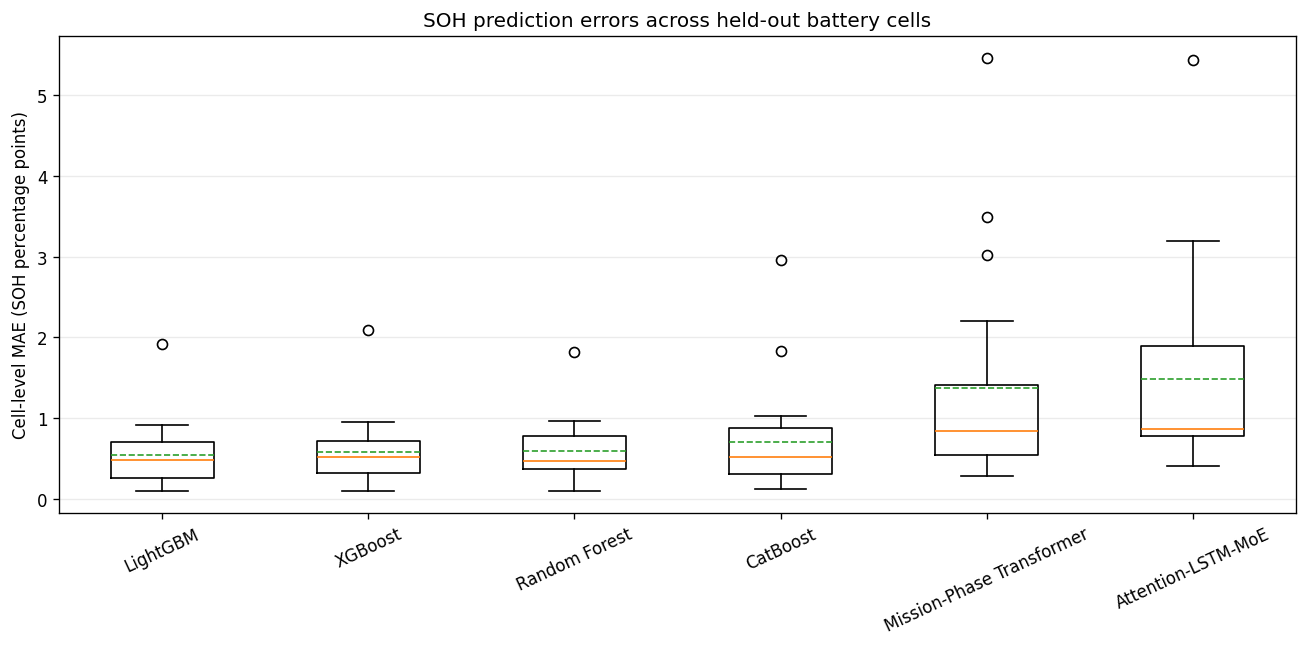

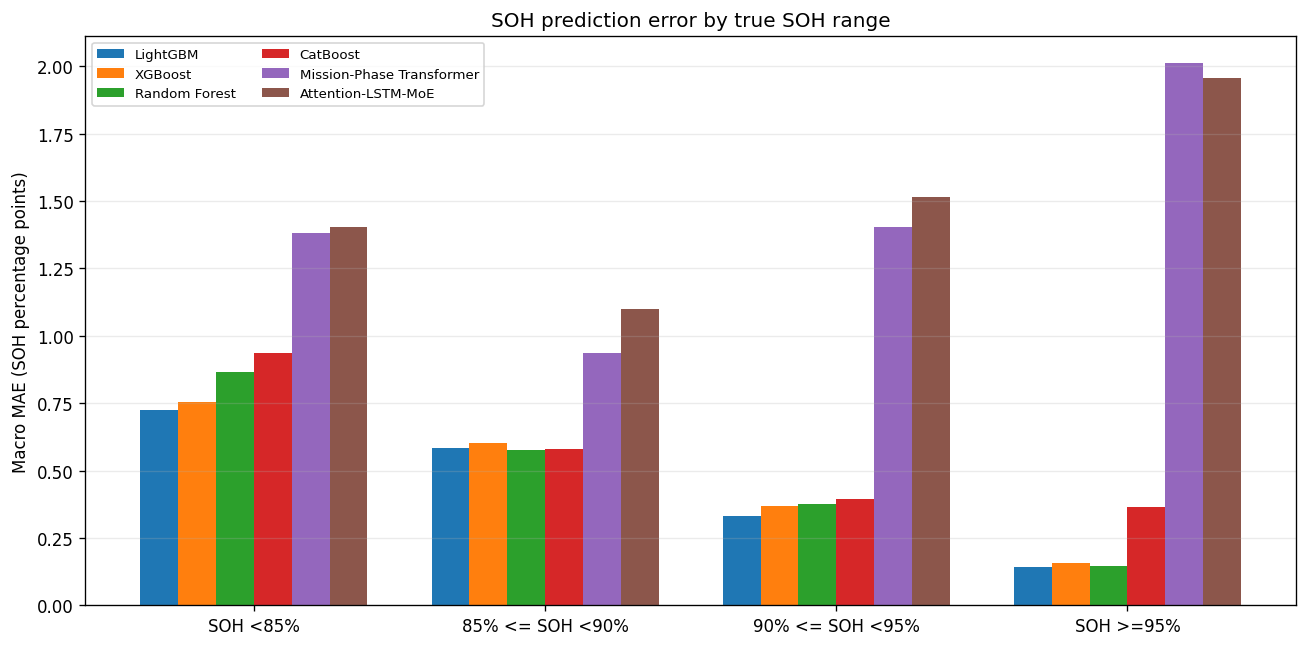

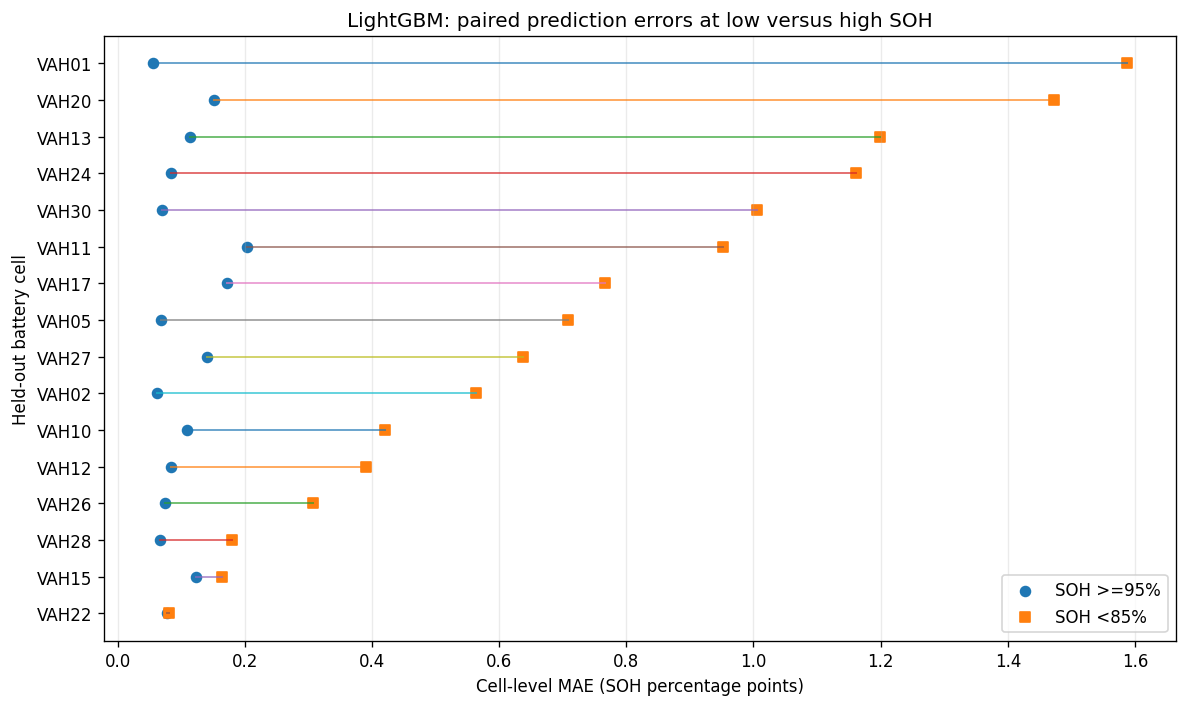


📁 FILE HASIL
figure1_cell_mae_distribution.png                193.6 KB
figure2_macro_mae_by_soh.png                     147.8 KB
figure3_lightgbm_low_vs_high_soh.png             171.9 KB
supplement_cell_level_mae.csv                    2.3 KB
supplement_cell_soh_strata.csv                   32.5 KB
supplement_macro_mae_by_soh.csv                  0.6 KB
table1_six_model_soh_metrics.csv                 1.2 KB
table2_wilcoxon_vs_lightgbm.csv                  0.8 KB
table3_low_vs_high_soh.csv                       0.8 KB

📌 CATATAN METODOLOGIS
Seluruh model dievaluasi menggunakan 18.513 pasangan cell_id–mission_id.
Label referensi LightGBM digunakan untuk menghitung seluruh error dan strata.
Perbedaan label asli DL terhadap referensi maksimum <= 1e-5 poin SOH.
Uji Wilcoxon memakai sel baterai sebagai unit analisis.
Koreksi Holm dilakukan terpisah untuk keluarga lima perbandingan model dan enam perbandingan rentang SOH.
Bootstrap CI pada Tabel 2 tidak dikoreksi untuk multipel komparasi.
G

In [64]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

# ============================================================
# TAHAP 3.28 — PAKET TABEL DAN GAMBAR SOH
# ============================================================

ROOT = Path("/content/gdrive_recovery/MyDrive")

TREE_FIXED = ROOT / "eVTOL_table5_work" / "final_fast_loco_fixed"
TREE_FAST = ROOT / "eVTOL_table5_work" / "final_fast"

DL_BASE = (
    ROOT / "eVTOL_benchmark_reproduction_v2"
    / "table3_full_run" / "soh"
)

OUT = ROOT / "eVTOL_manuscript_results" / "soh_six_model"

OUT.mkdir(parents=True, exist_ok=True)

TREE_FILES = {
    "Random Forest": TREE_FIXED / "random_forest_predictions.csv",
    "XGBoost": TREE_FIXED / "xgboost_predictions.csv",
    "LightGBM": TREE_FIXED / "lightgbm_predictions.csv",
    "CatBoost": TREE_FAST / "catboost_predictions.csv",
}

DL_MODELS = {
    "Mission-Phase Transformer": "mission_phase_transformer",
    "Attention-LSTM-MoE": "attention_lstm_moe",
}

ORDER = [
    "LightGBM",
    "XGBoost",
    "Random Forest",
    "CatBoost",
    "Mission-Phase Transformer",
    "Attention-LSTM-MoE",
]

KEYS = ["cell_id", "mission_id"]

GROUPS = [
    "SOH <85%",
    "85% <= SOH <90%",
    "90% <= SOH <95%",
    "SOH >=95%",
]

LOW = GROUPS[0]
HIGH = GROUPS[-1]

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "figure.dpi": 120,
    "savefig.dpi": 300,
})

print("=" * 80)
print("🔬 TAHAP 3.28 — PAKET HASIL SOH SIAP MANUSKRIP")
print("=" * 80)

print("\n📁 OUTPUT:", OUT)

# ============================================================
# 1. MUAT PREDIKSI
# ============================================================

predictions = {}

for model, path in TREE_FILES.items():

    df = pd.read_csv(path)

    predictions[model] = df[
        KEYS + ["y_true", "y_pred"]
    ].copy()

for model, folder in DL_MODELS.items():

    paths = sorted(
        (DL_BASE / folder).glob("*/predictions.csv")
    )

    assert len(paths) == 19, (
        f"{model}: jumlah fold tidak sesuai"
    )

    frames = []

    for path in paths:

        df = pd.read_csv(path)

        df = df.rename(
            columns={"test_cell": "cell_id"}
        )

        frames.append(
            df[KEYS + ["y_true", "y_pred"]].copy()
        )

    predictions[model] = pd.concat(
        frames,
        ignore_index=True
    )

# ============================================================
# 2. SAMAKAN REFERENSI SOH DAN VALIDASI
# ============================================================

ref = predictions["LightGBM"][
    KEYS + ["y_true"]
].copy()

ref["cell_id"] = ref["cell_id"].astype(str)
ref["mission_id"] = ref["mission_id"].astype(str)

ref = ref.rename(
    columns={"y_true": "reference_soh"}
)

assert len(ref) == 18513
assert not ref.duplicated(KEYS).any()

prepared = {}

for model, df in predictions.items():

    df = df.copy()

    df["cell_id"] = df["cell_id"].astype(str)
    df["mission_id"] = df["mission_id"].astype(str)

    assert not df.duplicated(KEYS).any()

    df = df.merge(
        ref,
        on=KEYS,
        how="inner",
        validate="one_to_one"
    )

    assert len(df) == len(ref)

    assert (
        df["y_true"] - df["reference_soh"]
    ).abs().max() <= 1e-5

    assert np.isfinite(
        df[["reference_soh", "y_pred"]].to_numpy()
    ).all()

    df["signed_error"] = (
        df["y_pred"] - df["reference_soh"]
    )

    df["abs_error"] = df["signed_error"].abs()

    df["soh_group"] = pd.cut(
        df["reference_soh"],
        bins=[-np.inf, 85, 90, 95, np.inf],
        labels=GROUPS,
        right=False,
    )

    prepared[model] = df

print("\n✅ Semua model: 18.513 sampel, 19 sel, label setara.")

# ============================================================
# 3. TABEL 1 — METRIK AGREGAT
# ============================================================

summary_rows = []
cell_rows = []

for model in ORDER:

    df = prepared[model]

    e = df["signed_error"].to_numpy()

    per_cell = (
        df.groupby("cell_id")["abs_error"]
        .mean()
    )

    summary_rows.append({
        "model": model,
        "samples": len(df),
        "cells": df["cell_id"].nunique(),
        "pooled_MAE": float(np.mean(np.abs(e))),
        "pooled_RMSE": float(np.sqrt(np.mean(e ** 2))),
        "macro_MAE": float(per_cell.mean()),
        "median_cell_MAE": float(per_cell.median()),
        "P90_cell_MAE": float(per_cell.quantile(0.90)),
        "worst_cell_MAE": float(per_cell.max()),
        "mean_signed_error": float(e.mean()),
        "overprediction_pct": float(
            100 * np.mean(e > 0)
        ),
    })

    for cell, value in per_cell.items():

        cell_rows.append({
            "model": model,
            "cell_id": cell,
            "cell_MAE": float(value),
        })

table1 = pd.DataFrame(summary_rows)

cell_mae = pd.DataFrame(cell_rows).pivot(
    index="cell_id",
    columns="model",
    values="cell_MAE"
)[ORDER]

table1.to_csv(
    OUT / "table1_six_model_soh_metrics.csv",
    index=False
)

cell_mae.to_csv(
    OUT / "supplement_cell_level_mae.csv"
)

print("\n" + "=" * 80)
print("📊 TABEL 1 — KINERJA ENAM MODEL")
print("=" * 80)

print(
    table1.round(5).to_string(index=False)
)

# ============================================================
# 4. TABEL 2 — WILCOXON VS LIGHTGBM
# ============================================================

rng = np.random.default_rng(42)

test_rows = []

for model in ORDER:

    if model == "LightGBM":
        continue

    delta = (
        cell_mae[model]
        - cell_mae["LightGBM"]
    ).to_numpy()

    p = float(
        wilcoxon(
            delta,
            alternative="two-sided",
            method="auto"
        ).pvalue
    )

    boot_idx = rng.integers(
        0,
        len(delta),
        size=(20000, len(delta))
    )

    boot_mean = delta[boot_idx].mean(axis=1)

    ci_low, ci_high = np.percentile(
        boot_mean, [2.5, 97.5]
    )

    test_rows.append({
        "comparison": model,
        "paired_cells": len(delta),
        "mean_MAE_advantage_LGBM": float(delta.mean()),
        "LGBM_wins": int((delta > 0).sum()),
        "other_wins": int((delta < 0).sum()),
        "wilcoxon_p": p,
        "bootstrap_95CI_low": float(ci_low),
        "bootstrap_95CI_high": float(ci_high),
    })

table2 = pd.DataFrame(test_rows)

pvals = table2["wilcoxon_p"].to_numpy()

order_idx = np.argsort(pvals)
m = len(pvals)

holm_sorted = np.minimum(
    1.0,
    np.maximum.accumulate(
        (m - np.arange(m)) * pvals[order_idx]
    )
)

holm = np.empty(m)
holm[order_idx] = holm_sorted

table2["holm_adjusted_p"] = holm
table2["significant_holm_0_05"] = holm < 0.05

table2.to_csv(
    OUT / "table2_wilcoxon_vs_lightgbm.csv",
    index=False
)

print("\n" + "=" * 80)
print("📊 TABEL 2 — PERBANDINGAN VS LIGHTGBM")
print("=" * 80)

print(
    table2.round(6).to_string(index=False)
)

# ============================================================
# 5. TABEL 3 — SOH RENDAH VS TINGGI
# ============================================================

stratum_rows = []
paired_rows = []

for model in ORDER:

    df = prepared[model]

    grouped = (
        df.groupby(
            ["cell_id", "soh_group"],
            observed=True
        )
        .agg(
            n=("abs_error", "size"),
            cell_MAE=("abs_error", "mean"),
            cell_bias=("signed_error", "mean"),
        )
        .reset_index()
    )

    grouped["model"] = model

    stratum_rows.append(grouped)

    wide = grouped.pivot(
        index="cell_id",
        columns="soh_group",
        values="cell_MAE"
    )

    paired = wide[[LOW, HIGH]].dropna()

    delta = (
        paired[LOW] - paired[HIGH]
    ).to_numpy()

    paired_rows.append({
        "model": model,
        "paired_cells": len(delta),
        "mean_MAE_low": float(paired[LOW].mean()),
        "mean_MAE_high": float(paired[HIGH].mean()),
        "mean_delta_low_minus_high": float(delta.mean()),
        "positive_differences": int((delta > 0).sum()),
        "wilcoxon_p": float(
            wilcoxon(
                delta,
                alternative="two-sided",
                method="auto"
            ).pvalue
        ),
    })

strata = pd.concat(
    stratum_rows,
    ignore_index=True
)

table3 = pd.DataFrame(paired_rows)

pvals = table3["wilcoxon_p"].to_numpy()

order_idx = np.argsort(pvals)
m = len(pvals)

holm_sorted = np.minimum(
    1.0,
    np.maximum.accumulate(
        (m - np.arange(m)) * pvals[order_idx]
    )
)

holm = np.empty(m)
holm[order_idx] = holm_sorted

table3["holm_adjusted_p"] = holm
table3["significant_holm_0_05"] = holm < 0.05

table3.to_csv(
    OUT / "table3_low_vs_high_soh.csv",
    index=False
)

strata.to_csv(
    OUT / "supplement_cell_soh_strata.csv",
    index=False
)

print("\n" + "=" * 80)
print("📊 TABEL 3 — SOH RENDAH VS TINGGI")
print("=" * 80)

print(
    table3.round(6).to_string(index=False)
)

# ============================================================
# 6. GAMBAR 1 — DISTRIBUSI MAE PER SEL
# ============================================================

fig, ax = plt.subplots(figsize=(11, 5.5))

data = [
    cell_mae[model].to_numpy()
    for model in ORDER
]

ax.boxplot(
    data,
    tick_labels=ORDER,
    showmeans=True,
    meanline=True,
)

ax.set_ylabel("Cell-level MAE (SOH percentage points)")
ax.set_title(
    "SOH prediction errors across held-out battery cells"
)

ax.tick_params(
    axis="x",
    rotation=25
)

ax.grid(
    axis="y",
    alpha=0.25
)

fig.tight_layout()

fig.savefig(
    OUT / "figure1_cell_mae_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ============================================================
# 7. GAMBAR 2 — MACRO MAE PER RENTANG SOH
# ============================================================

macro_strata = (
    strata.groupby(
        ["model", "soh_group"],
        observed=True
    )["cell_MAE"]
    .mean()
    .unstack("soh_group")
    .reindex(index=ORDER, columns=GROUPS)
)

macro_strata.to_csv(
    OUT / "supplement_macro_mae_by_soh.csv"
)

fig, ax = plt.subplots(figsize=(11, 5.5))

x = np.arange(len(GROUPS))
width = 0.13

for i, model in enumerate(ORDER):

    offset = (
        i - (len(ORDER) - 1) / 2
    ) * width

    ax.bar(
        x + offset,
        macro_strata.loc[model].to_numpy(),
        width,
        label=model,
    )

ax.set_xticks(x)
ax.set_xticklabels(GROUPS)

ax.set_ylabel(
    "Macro MAE (SOH percentage points)"
)

ax.set_title(
    "SOH prediction error by true SOH range"
)

ax.legend(
    fontsize=8,
    ncol=2
)

ax.grid(
    axis="y",
    alpha=0.25
)

fig.tight_layout()

fig.savefig(
    OUT / "figure2_macro_mae_by_soh.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ============================================================
# 8. GAMBAR 3 — PAIRED LIGHTGBM LOW VS HIGH
# ============================================================

lgbm_strata = strata[
    strata["model"] == "LightGBM"
]

wide = lgbm_strata.pivot(
    index="cell_id",
    columns="soh_group",
    values="cell_MAE"
)

paired = wide[[LOW, HIGH]].dropna()

paired = paired.sort_values(
    LOW,
    ascending=False
)

fig, ax = plt.subplots(figsize=(10, 6))

y = np.arange(len(paired))

for i, (_, row) in enumerate(
    paired.iterrows()
):

    ax.plot(
        [row[HIGH], row[LOW]],
        [i, i],
        linewidth=1.2,
        alpha=0.65,
    )

ax.scatter(
    paired[HIGH],
    y,
    label="SOH >=95%",
    marker="o",
    s=35,
)

ax.scatter(
    paired[LOW],
    y,
    label="SOH <85%",
    marker="s",
    s=35,
)

ax.set_yticks(y)
ax.set_yticklabels(paired.index)

ax.invert_yaxis()

ax.set_xlabel(
    "Cell-level MAE (SOH percentage points)"
)

ax.set_ylabel("Held-out battery cell")

ax.set_title(
    "LightGBM: paired prediction errors "
    "at low versus high SOH"
)

ax.legend()
ax.grid(
    axis="x",
    alpha=0.25
)

fig.tight_layout()

fig.savefig(
    OUT / "figure3_lightgbm_low_vs_high_soh.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ============================================================
# 9. DAFTAR FILE OUTPUT
# ============================================================

print("\n" + "=" * 80)
print("📁 FILE HASIL")
print("=" * 80)

for path in sorted(OUT.iterdir()):

    print(
        f"{path.name:48s} "
        f"{path.stat().st_size / 1024:.1f} KB"
    )

print("\n📌 CATATAN METODOLOGIS")
print(
    "Seluruh model dievaluasi menggunakan "
    "18.513 pasangan cell_id–mission_id."
)
print(
    "Label referensi LightGBM digunakan "
    "untuk menghitung seluruh error dan strata."
)
print(
    "Perbedaan label asli DL terhadap referensi "
    "maksimum <= 1e-5 poin SOH."
)
print(
    "Uji Wilcoxon memakai sel baterai "
    "sebagai unit analisis."
)
print(
    "Koreksi Holm dilakukan terpisah "
    "untuk keluarga lima perbandingan model "
    "dan enam perbandingan rentang SOH."
)
print(
    "Bootstrap CI pada Tabel 2 tidak "
    "dikoreksi untuk multipel komparasi."
)
print(
    "Gambar adalah visualisasi deskriptif, "
    "bukan validasi keselamatan operasional."
)

print("\n✅ TAHAP 3.28 SELESAI — TANPA TRAINING")

In [65]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

BASE = (
    ROOT
    / "eVTOL_benchmark_reproduction_v2"
    / "table3_full_run"
)

TASKS = ["rul90", "rul85", "rul80"]

MODELS = {
    "Mission-Phase Transformer": "mission_phase_transformer",
    "Attention-LSTM-MoE": "attention_lstm_moe",
}

print("=" * 80)
print("🔬 TAHAP 3.29 — AUDIT SUMBER PREDIKSI RUL")
print("=" * 80)

print("\n📁 ROOT:", BASE)
print("Root exists:", BASE.exists())

records = []

for task in TASKS:

    print("\n" + "=" * 80)
    print("TARGET:", task.upper())
    print("=" * 80)

    for model_name, model_folder in MODELS.items():

        folder = BASE / task / model_folder

        paths = sorted(
            folder.glob("*/predictions.csv")
        )

        print(f"\nMODEL: {model_name}")
        print("Folder exists:", folder.exists())
        print("Prediction files:", len(paths))

        if not paths:
            print("⚠️ Tidak ada predictions.csv ditemukan")
            continue

        frames = []

        for path in paths:

            df = pd.read_csv(path)

            frames.append(df)

            records.append({
                "task": task,
                "model": model_name,
                "fold_folder": path.parent.name,
                "rows": len(df),
                "columns": "|".join(df.columns),
                "file_size_kb": round(
                    path.stat().st_size / 1024, 2
                ),
            })

        combined = pd.concat(
            frames,
            ignore_index=True
        )

        print("Total rows:", len(combined))
        print("Columns:", list(combined.columns))
        print("Dtypes:")
        print(combined.dtypes.to_string())

        print("\nFirst 3 rows:")
        print(
            combined.head(3).to_string(index=False)
        )

        print("\nMissing values:")
        print(
            combined.isna().sum().to_string()
        )

        if {"y_true", "y_pred"}.issubset(
            combined.columns
        ):

            y_true = pd.to_numeric(
                combined["y_true"],
                errors="coerce"
            )

            y_pred = pd.to_numeric(
                combined["y_pred"],
                errors="coerce"
            )

            valid = (
                y_true.notna()
                & y_pred.notna()
            )

            if valid.any():

                e = (
                    y_pred[valid]
                    - y_true[valid]
                )

                mae = e.abs().mean()
                rmse = (e.pow(2).mean()) ** 0.5

                print("\nRecomputed metrics:")
                print("MAE:", round(float(mae), 6))
                print("RMSE:", round(float(rmse), 6))
                print("Valid rows:", int(valid.sum()))

        print("\nFold folders:")
        print(
            [p.parent.name for p in paths]
        )

print("\n" + "=" * 80)
print("📋 RINGKASAN FILE PER FOLD")
print("=" * 80)

audit = pd.DataFrame(records)

if not audit.empty:

    print(
        audit[
            [
                "task",
                "model",
                "fold_folder",
                "rows",
                "file_size_kb",
            ]
        ].to_string(index=False)
    )

    print("\n📊 AGREGASI PER TARGET DAN MODEL")

    grouped = (
        audit.groupby(["task", "model"])
        .agg(
            folds=("fold_folder", "nunique"),
            rows=("rows", "sum"),
        )
        .reset_index()
    )

    print(grouped.to_string(index=False))

print("\n📌 CATATAN")
print(
    "Tahap ini mengaudit sumber prediksi RUL, "
    "bukan menguji signifikansi model."
)
print(
    "Kesetaraan key antar-model akan diperiksa "
    "setelah struktur kolom terkonfirmasi."
)
print(
    "Jumlah sel RUL85 dan RUL80 dapat lebih "
    "sedikit karena ketersediaan label."
)

print("\n✅ TAHAP 3.29 SELESAI — TANPA TRAINING")

🔬 TAHAP 3.29 — AUDIT SUMBER PREDIKSI RUL

📁 ROOT: /content/gdrive_recovery/MyDrive/eVTOL_benchmark_reproduction_v2/table3_full_run
Root exists: True

TARGET: RUL90

MODEL: Mission-Phase Transformer
Folder exists: True
Prediction files: 19
Total rows: 5814
Columns: ['task', 'model', 'test_cell', 'mission_id', 'y_true', 'y_pred', 'error']
Dtypes:
task           object
model          object
test_cell      object
mission_id      int64
y_true        float64
y_pred        float64
error         float64

First 3 rows:
 task                     model test_cell  mission_id  y_true    y_pred      error
rul90 mission_phase_transformer     VAH01           1   321.0 264.81210 -56.187897
rul90 mission_phase_transformer     VAH01           2   320.0 259.34467 -60.655334
rul90 mission_phase_transformer     VAH01           3   319.0 260.73682 -58.263184

Missing values:
task          0
model         0
test_cell     0
mission_id    0
y_true        0
y_pred        0
error         0

Recomputed metrics:
MA

In [66]:
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

BASE = (
    ROOT
    / "eVTOL_benchmark_reproduction_v2"
    / "table3_full_run"
)

SOURCE = (
    ROOT
    / "eVTOL_Table3_source_recovery"
    / "health_mission_features_targets.csv"
)

TASKS = ["rul90", "rul85", "rul80"]

MODELS = {
    "Transformer": "mission_phase_transformer",
    "MoE": "attention_lstm_moe",
}

KEYS = ["cell_id", "mission_id"]

print("=" * 80)
print("🔬 TAHAP 3.30 — VALIDASI PASANGAN DAN LABEL RUL")
print("=" * 80)

print("\n📁 Dataset sumber:", SOURCE)
print("Dataset exists:", SOURCE.exists())

assert SOURCE.exists(), "Dataset sumber tidak ditemukan"

source = pd.read_csv(SOURCE)

print("\n📋 Kolom RUL pada dataset sumber:")

rul_cols = [
    c for c in source.columns
    if "rul" in c.lower()
]

print(rul_cols)

print("\n📋 Kolom identitas:")
print([
    c for c in source.columns
    if c in KEYS
])

assert set(KEYS).issubset(source.columns)

source["cell_id"] = source["cell_id"].astype(str)
source["mission_id"] = source["mission_id"].astype(str)

assert not source.duplicated(KEYS).any(), (
    "Dataset sumber memiliki duplikasi key"
)

# ==================================================
# 1. FUNGSI MEMUAT PREDIKSI
# ==================================================

def load_predictions(task, folder):

    paths = sorted(
        (BASE / task / folder).glob(
            "*/predictions.csv"
        )
    )

    assert paths, (
        f"Prediksi tidak ditemukan: {task}/{folder}"
    )

    frames = []

    for path in paths:

        df = pd.read_csv(path)

        df = df.rename(
            columns={"test_cell": "cell_id"}
        )

        required = set(
            KEYS + ["y_true", "y_pred", "error"]
        )

        assert required.issubset(df.columns), path

        df = df[
            KEYS + ["y_true", "y_pred", "error"]
        ].copy()

        df["cell_id"] = df["cell_id"].astype(str)
        df["mission_id"] = df["mission_id"].astype(str)

        df["fold_folder"] = path.parent.name

        frames.append(df)

    result = pd.concat(
        frames,
        ignore_index=True
    )

    assert not result.duplicated(KEYS).any(), (
        f"Duplikasi prediksi: {task}/{folder}"
    )

    assert (
        result["cell_id"]
        == result["fold_folder"]
    ).all(), (
        f"Identitas fold tidak konsisten: {task}/{folder}"
    )

    numeric_cols = ["y_true", "y_pred", "error"]

    assert np.isfinite(
        result[numeric_cols].to_numpy(
            dtype=float
        )
    ).all()

    return result

# ==================================================
# 2. VALIDASI KESETARAAN DUA MODEL
# ==================================================

records = []

for task in TASKS:

    print("\n" + "=" * 80)
    print("🎯 TARGET:", task.upper())
    print("=" * 80)

    tr = load_predictions(
        task,
        MODELS["Transformer"]
    )

    moe = load_predictions(
        task,
        MODELS["MoE"]
    )

    merged = tr.merge(
        moe,
        on=KEYS,
        how="outer",
        suffixes=("_tr", "_moe"),
        indicator=True,
        validate="one_to_one"
    )

    matched = (
        merged["_merge"] == "both"
    ).all()

    assert matched, (
        f"{task}: key Transformer dan MoE berbeda"
    )

    label_diff = np.abs(
        merged["y_true_tr"]
        - merged["y_true_moe"]
    )

    max_label_diff = float(
        label_diff.max()
    )

    assert max_label_diff <= 1e-8, (
        f"{task}: label kedua model berbeda"
    )

    tr_error_diff = np.abs(
        merged["error_tr"]
        - (
            merged["y_pred_tr"]
            - merged["y_true_tr"]
        )
    )

    moe_error_diff = np.abs(
        merged["error_moe"]
        - (
            merged["y_pred_moe"]
            - merged["y_true_moe"]
        )
    )

    print("Transformer rows:", len(tr))
    print("MoE rows:", len(moe))

    print(
        "Matched keys:",
        len(merged)
    )

    print(
        "Max label difference:",
        max_label_diff
    )

    print(
        "Max error-column discrepancy (Transformer):",
        float(tr_error_diff.max())
    )

    print(
        "Max error-column discrepancy (MoE):",
        float(moe_error_diff.max())
    )

    # --------------------------------------------------
    # 3. COCOKKAN TARGET DENGAN DATASET SUMBER
    # --------------------------------------------------

    threshold = task.replace("rul", "")

    candidate_cols = [
        c for c in source.columns
        if (
            "rul" in c.lower()
            and threshold in c.lower()
            and (
                "mission" in c.lower()
                or "remaining" in c.lower()
            )
            and "event" not in c.lower()
        )
    ]

    print(
        "\nCandidate source target columns:",
        candidate_cols
    )

    source_target_col = None

    expected = f"RUL{threshold}_missions"

    if expected in source.columns:
        source_target_col = expected

    elif len(candidate_cols) == 1:
        source_target_col = candidate_cols[0]

    if source_target_col is None:

        print(
            "⚠️ Kolom target sumber tidak dapat "
            "ditentukan otomatis."
        )

        source_match = np.nan
        source_max_diff = np.nan

    else:

        source_subset = source[
            KEYS + [source_target_col]
        ].copy()

        source_subset = source_subset.rename(
            columns={
                source_target_col: "source_rul"
            }
        )

        check = merged.merge(
            source_subset,
            on=KEYS,
            how="left",
            validate="one_to_one"
        )

        source_missing = int(
            check["source_rul"].isna().sum()
        )

        source_max_diff = float(
            np.abs(
                check["y_true_tr"]
                - check["source_rul"]
            ).max()
        )

        source_match = (
            source_missing == 0
            and source_max_diff <= 1e-8
        )

        print(
            "Source target column:",
            source_target_col
        )

        print(
            "Missing source targets:",
            source_missing
        )

        print(
            "Max difference vs source:",
            source_max_diff
        )

        print(
            "Source labels match:",
            source_match
        )

    records.append({
        "task": task,
        "transformer_rows": len(tr),
        "moe_rows": len(moe),
        "matched_keys": len(merged),
        "cells": merged["cell_id"].nunique(),
        "max_model_label_diff": max_label_diff,
        "max_transformer_error_discrepancy": float(
            tr_error_diff.max()
        ),
        "max_moe_error_discrepancy": float(
            moe_error_diff.max()
        ),
        "source_target_column": source_target_col,
        "source_labels_match": source_match,
        "max_source_label_diff": source_max_diff,
    })

# ==================================================
# 4. RINGKASAN
# ==================================================

audit = pd.DataFrame(records)

print("\n" + "=" * 80)
print("📊 RINGKASAN AUDIT RUL")
print("=" * 80)

print(
    audit.to_string(index=False)
)

print("\n📌 INTERPRETASI")
print(
    "Kesetaraan pasangan prediksi dan label "
    "diperiksa secara langsung."
)
print(
    "Kolom error diuji terhadap y_pred - y_true."
)
print(
    "Target sumber diperiksa terhadap "
    "RULxx_missions jika tersedia."
)
print(
    "RUL dinyatakan dalam jumlah misi "
    "jika cocok dengan kolom RULxx_missions."
)

print("\n✅ TAHAP 3.30 SELESAI — TANPA TRAINING")

🔬 TAHAP 3.30 — VALIDASI PASANGAN DAN LABEL RUL

📁 Dataset sumber: /content/gdrive_recovery/MyDrive/eVTOL_Table3_source_recovery/health_mission_features_targets.csv
Dataset exists: True

📋 Kolom RUL pada dataset sumber:
['RUL90_event_mission', 'RUL90_observed', 'RUL90_missions', 'RUL85_event_mission', 'RUL85_observed', 'RUL85_missions', 'RUL80_event_mission', 'RUL80_observed', 'RUL80_missions']

📋 Kolom identitas:
['cell_id', 'mission_id']

🎯 TARGET: RUL90
Transformer rows: 5814
MoE rows: 5814
Matched keys: 5814
Max label difference: 0.0
Max error-column discrepancy (Transformer): 3.000000003794412e-05
Max error-column discrepancy (MoE): 1.5000000026077487e-05

Candidate source target columns: ['RUL90_missions']
Source target column: RUL90_missions
Missing source targets: 0
Max difference vs source: 8.000000001118224e-06
Source labels match: False

🎯 TARGET: RUL85
Transformer rows: 9595
MoE rows: 9595
Matched keys: 9595
Max label difference: 0.0
Max error-column discrepancy (Transformer

In [67]:
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

BASE = (
    ROOT
    / "eVTOL_benchmark_reproduction_v2"
    / "table3_full_run"
)

SOURCE = (
    ROOT
    / "eVTOL_Table3_source_recovery"
    / "health_mission_features_targets.csv"
)

TASKS = ["rul90", "rul85", "rul80"]

print("=" * 80)
print("🔬 TAHAP 3.31 — AUDIT PRESISI LABEL RUL")
print("=" * 80)

source = pd.read_csv(SOURCE)

source["cell_id"] = source["cell_id"].astype(str)
source["mission_id"] = source["mission_id"].astype(str)

assert not source.duplicated(
    ["cell_id", "mission_id"]
).any()

records = []

for task in TASKS:

    threshold = task.replace("rul", "")

    source_col = f"RUL{threshold}_missions"

    paths = sorted(
        (
            BASE
            / task
            / "mission_phase_transformer"
        ).glob("*/predictions.csv")
    )

    assert paths, f"Tidak ada prediksi untuk {task}"

    frames = []

    for path in paths:

        df = pd.read_csv(path)

        df = df.rename(
            columns={"test_cell": "cell_id"}
        )

        frames.append(
            df[
                ["cell_id", "mission_id", "y_true"]
            ]
        )

    pred = pd.concat(
        frames,
        ignore_index=True
    )

    pred["cell_id"] = pred["cell_id"].astype(str)
    pred["mission_id"] = pred["mission_id"].astype(str)

    assert not pred.duplicated(
        ["cell_id", "mission_id"]
    ).any()

    merged = pred.merge(
        source[
            ["cell_id", "mission_id", source_col]
        ],
        on=["cell_id", "mission_id"],
        how="left",
        validate="one_to_one"
    )

    assert len(merged) == len(pred)
    assert merged[source_col].notna().all()

    y_pred_label = merged["y_true"].to_numpy(
        dtype=np.float64
    )

    y_source = merged[source_col].to_numpy(
        dtype=np.float64
    )

    diff = np.abs(y_pred_label - y_source)

    # Representasi float32 dari label sumber
    source_float32 = (
        y_source.astype(np.float32)
        .astype(np.float64)
    )

    diff_float32 = np.abs(
        y_pred_label - source_float32
    )

    # Periksa apakah label merupakan bilangan
    # misi yang mendekati integer
    source_integer_diff = np.abs(
        y_source - np.rint(y_source)
    )

    pred_integer_diff = np.abs(
        y_pred_label - np.rint(y_pred_label)
    )

    record = {
        "task": task,
        "n": len(merged),

        "max_abs_diff_source": float(
            diff.max()
        ),

        "mean_abs_diff_source": float(
            diff.mean()
        ),

        "median_abs_diff_source": float(
            np.median(diff)
        ),

        "P95_abs_diff_source": float(
            np.percentile(diff, 95)
        ),

        "exact_matches_source": int(
            np.sum(diff == 0)
        ),

        "within_1e-5": int(
            np.sum(diff <= 1e-5)
        ),

        "within_1e-4": int(
            np.sum(diff <= 1e-4)
        ),

        "within_1e-3": int(
            np.sum(diff <= 1e-3)
        ),

        "exact_matches_source_float32": int(
            np.sum(diff_float32 == 0)
        ),

        "max_diff_vs_source_float32": float(
            diff_float32.max()
        ),

        "max_source_integer_deviation": float(
            source_integer_diff.max()
        ),

        "max_pred_integer_deviation": float(
            pred_integer_diff.max()
        ),
    }

    for digits in [3, 4, 5, 6]:

        record[f"matches_rounded_{digits}dp"] = int(
            np.sum(
                np.round(y_pred_label, digits)
                == np.round(y_source, digits)
            )
        )

    records.append(record)

    print("\n" + "=" * 80)
    print("🎯", task.upper())
    print("=" * 80)

    print("Rows:", len(merged))

    print(
        "Max absolute difference:",
        record["max_abs_diff_source"]
    )

    print(
        "Mean absolute difference:",
        record["mean_abs_diff_source"]
    )

    print(
        "Exact matches vs source:",
        record["exact_matches_source"]
    )

    print(
        "Exact matches vs float32(source):",
        record["exact_matches_source_float32"]
    )

    print(
        "Max difference vs float32(source):",
        record["max_diff_vs_source_float32"]
    )

    print(
        "Max deviation from integer "
        "(source, predictions):",
        record["max_source_integer_deviation"],
        record["max_pred_integer_deviation"]
    )

    print("\nTop 5 largest differences:")

    top = merged.copy()

    top["abs_diff"] = diff

    print(
        top.sort_values(
            "abs_diff",
            ascending=False
        )[
            [
                "cell_id",
                "mission_id",
                "y_true",
                source_col,
                "abs_diff",
            ]
        ].head(5).to_string(index=False)
    )

summary = pd.DataFrame(records)

print("\n" + "=" * 80)
print("📊 RINGKASAN PRESISI")
print("=" * 80)

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.10f}"
    )
)

print("\n📌 INTERPRETASI")
print(
    "Kesetaraan key dan label antar-model "
    "sudah terbukti pada Tahap 3.30."
)
print(
    "Tahap ini memeriksa representasi numerik "
    "label terhadap dataset sumber."
)
print(
    "Kecocokan float32 atau pembulatan "
    "tidak otomatis membuktikan provenance."
)
print(
    "Perbedaan numerik harus dibandingkan "
    "dengan skala MAE model."
)

print("\n✅ TAHAP 3.31 SELESAI — TANPA TRAINING")

🔬 TAHAP 3.31 — AUDIT PRESISI LABEL RUL

🎯 RUL90
Rows: 5814
Max absolute difference: 8.000000001118224e-06
Mean absolute difference: 2.573099415564341e-07
Exact matches vs source: 5627
Exact matches vs float32(source): 5627
Max difference vs float32(source): 8.000000001118224e-06
Max deviation from integer (source, predictions): 0.0 8.000000001118224e-06

Top 5 largest differences:
cell_id mission_id    y_true  RUL90_missions  abs_diff
  VAH26        291 37.000008            37.0  0.000008
  VAH02        214 43.999992            44.0  0.000008
  VAH02        215 42.999992            43.0  0.000008
  VAH02        216 42.000008            42.0  0.000008
  VAH26        280 47.999992            48.0  0.000008

🎯 RUL85
Rows: 9595
Max absolute difference: 1.5000000004761205e-05
Mean absolute difference: 5.315268370303461e-07
Exact matches vs source: 9255
Exact matches vs float32(source): 9255
Max difference vs float32(source): 1.5000000004761205e-05
Max deviation from integer (source, predict

In [68]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

# ============================================================
# TAHAP 3.32 — STATISTIK BERPASANGAN FINAL RUL
# ============================================================

ROOT = Path("/content/gdrive_recovery/MyDrive")

BASE = (
    ROOT
    / "eVTOL_benchmark_reproduction_v2"
    / "table3_full_run"
)

SOURCE = (
    ROOT
    / "eVTOL_Table3_source_recovery"
    / "health_mission_features_targets.csv"
)

OUT = (
    ROOT
    / "eVTOL_manuscript_results"
    / "rul_two_model"
)

OUT.mkdir(parents=True, exist_ok=True)

TASKS = ["rul90", "rul85", "rul80"]

MODELS = {
    "Mission-Phase Transformer": "mission_phase_transformer",
    "Attention-LSTM-MoE": "attention_lstm_moe",
}

KEYS = ["cell_id", "mission_id"]

rng = np.random.default_rng(42)

print("=" * 80)
print("🔬 TAHAP 3.32 — STATISTIK FINAL RUL")
print("=" * 80)

print("\n📁 Output:", OUT)

# ============================================================
# 1. DATASET SUMBER
# ============================================================

source = pd.read_csv(SOURCE)

source["cell_id"] = source["cell_id"].astype(str)
source["mission_id"] = source["mission_id"].astype(str)

assert not source.duplicated(KEYS).any()

# ============================================================
# 2. FUNGSI MUAT PREDIKSI
# ============================================================

def load_predictions(task, folder):

    paths = sorted(
        (BASE / task / folder).glob(
            "*/predictions.csv"
        )
    )

    assert paths, (
        f"Tidak ada prediksi: {task}/{folder}"
    )

    frames = []

    for path in paths:

        df = pd.read_csv(path)

        df = df.rename(
            columns={"test_cell": "cell_id"}
        )

        required = KEYS + ["y_true", "y_pred"]

        assert set(required).issubset(df.columns)

        df = df[required].copy()

        df["cell_id"] = df["cell_id"].astype(str)
        df["mission_id"] = df["mission_id"].astype(str)

        assert (
            df["cell_id"] == path.parent.name
        ).all()

        frames.append(df)

    result = pd.concat(
        frames,
        ignore_index=True
    )

    assert not result.duplicated(KEYS).any()

    assert np.isfinite(
        result[["y_true", "y_pred"]].to_numpy(
            dtype=float
        )
    ).all()

    return result

# ============================================================
# 3. HITUNG METRIK DAN PERBANDINGAN
# ============================================================

summary_rows = []
comparison_rows = []
cell_rows = []

for task in TASKS:

    print("\n" + "=" * 80)
    print("🎯 TARGET:", task.upper())
    print("=" * 80)

    threshold = task.replace("rul", "")

    source_col = f"RUL{threshold}_missions"

    assert source_col in source.columns

    target_source = source[
        KEYS + [source_col]
    ].rename(
        columns={source_col: "reference_rul"}
    )

    prepared = {}

    for model_name, folder in MODELS.items():

        df = load_predictions(task, folder)

        df = df.merge(
            target_source,
            on=KEYS,
            how="left",
            validate="one_to_one"
        )

        assert df["reference_rul"].notna().all()

        max_label_diff = (
            df["y_true"] - df["reference_rul"]
        ).abs().max()

        assert max_label_diff <= 1e-3, (
            f"{task}/{model_name}: "
            "selisih label terlalu besar"
        )

        # Metrik final memakai label sumber
        df["error"] = (
            df["y_pred"] - df["reference_rul"]
        )

        df["abs_error"] = df["error"].abs()

        prepared[model_name] = df

        per_cell = (
            df.groupby("cell_id")["abs_error"]
            .mean()
        )

        for cell, mae in per_cell.items():

            cell_rows.append({
                "task": task.upper(),
                "model": model_name,
                "cell_id": cell,
                "cell_MAE": float(mae),
                "n": int(
                    (df["cell_id"] == cell).sum()
                ),
            })

        summary_rows.append({
            "task": task.upper(),
            "model": model_name,
            "samples": len(df),
            "cells": df["cell_id"].nunique(),
            "pooled_MAE": float(
                df["abs_error"].mean()
            ),
            "pooled_RMSE": float(
                np.sqrt(
                    np.mean(df["error"] ** 2)
                )
            ),
            "macro_MAE": float(
                per_cell.mean()
            ),
            "median_cell_MAE": float(
                per_cell.median()
            ),
            "P90_cell_MAE": float(
                per_cell.quantile(0.90)
            ),
            "worst_cell_MAE": float(
                per_cell.max()
            ),
            "mean_signed_error": float(
                df["error"].mean()
            ),
        })

    # --------------------------------------------------------
    # VALIDASI PASANGAN DAN LABEL ANTAR-MODEL
    # --------------------------------------------------------

    names = list(MODELS)

    tr = prepared[names[0]]
    moe = prepared[names[1]]

    matched = tr[
        KEYS + ["reference_rul", "y_true"]
    ].merge(
        moe[
            KEYS + ["reference_rul", "y_true"]
        ],
        on=KEYS,
        how="outer",
        suffixes=("_tr", "_moe"),
        indicator=True,
        validate="one_to_one"
    )

    assert (
        matched["_merge"] == "both"
    ).all()

    assert np.array_equal(
        matched["y_true_tr"].to_numpy(),
        matched["y_true_moe"].to_numpy()
    )

    assert np.array_equal(
        matched["reference_rul_tr"].to_numpy(),
        matched["reference_rul_moe"].to_numpy()
    )

    # --------------------------------------------------------
    # PERBANDINGAN MAE BERPASANGAN PER SEL
    # --------------------------------------------------------

    tr_cell = (
        tr.groupby("cell_id")["abs_error"]
        .mean()
    )

    moe_cell = (
        moe.groupby("cell_id")["abs_error"]
        .mean()
    )

    paired = pd.concat(
        [
            tr_cell.rename("transformer_MAE"),
            moe_cell.rename("moe_MAE"),
        ],
        axis=1
    ).dropna()

    assert len(paired) == tr["cell_id"].nunique()

    # Positif berarti MoE lebih baik
    delta = (
        paired["transformer_MAE"]
        - paired["moe_MAE"]
    ).to_numpy()

    p = float(
        wilcoxon(
            delta,
            alternative="two-sided",
            method="auto"
        ).pvalue
    )

    # Bootstrap pada unit sel
    bootstrap_indices = rng.integers(
        0,
        len(delta),
        size=(20000, len(delta))
    )

    bootstrap_means = (
        delta[bootstrap_indices].mean(axis=1)
    )

    ci_low, ci_high = np.percentile(
        bootstrap_means,
        [2.5, 97.5]
    )

    comparison_rows.append({
        "task": task.upper(),
        "paired_cells": len(delta),
        "mean_MAE_advantage_MoE": float(
            delta.mean()
        ),
        "median_MAE_advantage_MoE": float(
            np.median(delta)
        ),
        "MoE_wins": int((delta > 0).sum()),
        "Transformer_wins": int(
            (delta < 0).sum()
        ),
        "wilcoxon_p": p,
        "bootstrap_95CI_low": float(ci_low),
        "bootstrap_95CI_high": float(ci_high),
    })

# ============================================================
# 4. KOREKSI HOLM UNTUK TIGA TARGET
# ============================================================

summary = pd.DataFrame(summary_rows)

comparison = pd.DataFrame(
    comparison_rows
)

cell_results = pd.DataFrame(cell_rows)

pvals = comparison["wilcoxon_p"].to_numpy()

order = np.argsort(pvals)

m = len(pvals)

holm_sorted = np.minimum(
    1.0,
    np.maximum.accumulate(
        (m - np.arange(m)) * pvals[order]
    )
)

holm = np.empty(m)
holm[order] = holm_sorted

comparison["holm_adjusted_p"] = holm

comparison["significant_holm_0_05"] = (
    holm < 0.05
)

# ============================================================
# 5. SIMPAN HASIL
# ============================================================

summary.to_csv(
    OUT / "table_rul_model_metrics.csv",
    index=False
)

comparison.to_csv(
    OUT / "table_rul_paired_statistics.csv",
    index=False
)

cell_results.to_csv(
    OUT / "supplement_rul_cell_mae.csv",
    index=False
)

# ============================================================
# 6. OUTPUT
# ============================================================

print("\n" + "=" * 80)
print("📊 TABEL METRIK RUL")
print("=" * 80)

print(
    summary.round(5).to_string(index=False)
)

print("\n" + "=" * 80)
print("📈 UJI BERPASANGAN TRANSFORMER VS MoE")
print("=" * 80)

print(
    comparison.round(6).to_string(index=False)
)

print("\n" + "=" * 80)
print("📁 FILE TERSIMPAN")
print("=" * 80)

for path in sorted(OUT.iterdir()):

    print(
        path.name,
        f"({path.stat().st_size / 1024:.1f} KB)"
    )

print("\n📌 BATASAN")
print(
    "Perbandingan dilakukan pada sel dan misi "
    "yang identik untuk setiap target."
)
print(
    "Target RUL90, RUL85, dan RUL80 "
    "memiliki cakupan sel yang berbeda."
)
print(
    "Metrik dihitung ulang menggunakan "
    "label integer dari dataset sumber."
)
print(
    "Bootstrap menggunakan resampling sel."
)
print(
    "Holm mengoreksi tiga pengujian "
    "Transformer vs MoE."
)
print(
    "Confidence interval bootstrap tidak "
    "dikoreksi untuk pengujian berganda."
)

print("\n✅ TAHAP 3.32 SELESAI — TANPA TRAINING")

🔬 TAHAP 3.32 — STATISTIK FINAL RUL

📁 Output: /content/gdrive_recovery/MyDrive/eVTOL_manuscript_results/rul_two_model

🎯 TARGET: RUL90

🎯 TARGET: RUL85

🎯 TARGET: RUL80

📊 TABEL METRIK RUL
 task                     model  samples  cells  pooled_MAE  pooled_RMSE  macro_MAE  median_cell_MAE  P90_cell_MAE  worst_cell_MAE  mean_signed_error
RUL90 Mission-Phase Transformer     5814     19    36.86941     67.28679   34.81809         17.44948      68.28356       186.66262          -15.75390
RUL90        Attention-LSTM-MoE     5814     19    37.16960     55.16894   35.35878         23.53511      70.59827       106.04267           -2.03524
RUL85 Mission-Phase Transformer     9595     16    73.47596     95.47491   73.10431         58.81993     153.66186       211.21547           18.45654
RUL85        Attention-LSTM-MoE     9595     16    67.47845     89.40086   66.58578         55.34531     137.21990       197.00833           26.75487
RUL80 Mission-Phase Transformer     8257      8   175.46702  

In [69]:
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd

# ============================================================
# TAHAP 3.33 — FINAL QUALITY GATE HASIL PENELITIAN
# ============================================================

ROOT = Path("/content/gdrive_recovery/MyDrive")

SOH_DIR = (
    ROOT
    / "eVTOL_manuscript_results"
    / "soh_six_model"
)

RUL_DIR = (
    ROOT
    / "eVTOL_manuscript_results"
    / "rul_two_model"
)

OUT = ROOT / "eVTOL_manuscript_results"

SOH_FILES = [
    "table1_six_model_soh_metrics.csv",
    "table2_wilcoxon_vs_lightgbm.csv",
    "table3_low_vs_high_soh.csv",
    "supplement_cell_level_mae.csv",
    "supplement_cell_soh_strata.csv",
    "supplement_macro_mae_by_soh.csv",
    "figure1_cell_mae_distribution.png",
    "figure2_macro_mae_by_soh.png",
    "figure3_lightgbm_low_vs_high_soh.png",
]

RUL_FILES = [
    "table_rul_model_metrics.csv",
    "table_rul_paired_statistics.csv",
    "supplement_rul_cell_mae.csv",
]

print("=" * 80)
print("🔬 TAHAP 3.33 — FINAL QUALITY GATE")
print("=" * 80)

# ============================================================
# 1. VERIFIKASI FILE
# ============================================================

manifest = []
missing = []

for category, folder, filenames in [
    ("SOH", SOH_DIR, SOH_FILES),
    ("RUL", RUL_DIR, RUL_FILES),
]:

    for filename in filenames:

        path = folder / filename

        if not path.exists():
            missing.append(str(path))
            continue

        sha256 = hashlib.sha256(
            path.read_bytes()
        ).hexdigest()

        manifest.append({
            "category": category,
            "filename": filename,
            "relative_path": str(
                path.relative_to(OUT)
            ),
            "size_bytes": path.stat().st_size,
            "sha256": sha256,
        })

assert not missing, (
    "File tidak ditemukan:\n"
    + "\n".join(missing)
)

print(
    f"\n✅ {len(manifest)} artefak ditemukan."
)

# ============================================================
# 2. MUAT TABEL UTAMA
# ============================================================

soh_metrics = pd.read_csv(
    SOH_DIR / SOH_FILES[0]
)

soh_tests = pd.read_csv(
    SOH_DIR / SOH_FILES[1]
)

soh_strata = pd.read_csv(
    SOH_DIR / SOH_FILES[2]
)

rul_metrics = pd.read_csv(
    RUL_DIR / RUL_FILES[0]
)

rul_tests = pd.read_csv(
    RUL_DIR / RUL_FILES[1]
)

# ============================================================
# 3. PERIKSA STRUKTUR DAN NILAI
# ============================================================

assert len(soh_metrics) == 6
assert len(soh_tests) == 5
assert len(soh_strata) == 6

assert len(rul_metrics) == 6
assert len(rul_tests) == 3

assert (
    soh_metrics["samples"] == 18513
).all()

assert (
    soh_metrics["cells"] == 19
).all()

expected_rul = {
    "RUL90": (5814, 19),
    "RUL85": (9595, 16),
    "RUL80": (8257, 8),
}

for task, (samples, cells) in expected_rul.items():

    subset = rul_metrics[
        rul_metrics["task"] == task
    ]

    assert len(subset) == 2

    assert (
        subset["samples"] == samples
    ).all()

    assert (
        subset["cells"] == cells
    ).all()

tables = {
    "soh_metrics": soh_metrics,
    "soh_tests": soh_tests,
    "soh_strata": soh_strata,
    "rul_metrics": rul_metrics,
    "rul_tests": rul_tests,
}

for name, df in tables.items():

    assert not df.isna().any().any(), (
        f"Missing values: {name}"
    )

    numeric = df.select_dtypes(
        include="number"
    )

    assert np.isfinite(
        numeric.to_numpy()
    ).all(), (
        f"Non-finite values: {name}"
    )

print(
    "✅ Struktur, jumlah sampel, "
    "dan nilai numerik valid."
)

# ============================================================
# 4. VERIFIKASI KLAIM SIGNIFIKANSI
# ============================================================

for name, df in [
    ("SOH model comparisons", soh_tests),
    ("SOH strata comparisons", soh_strata),
    ("RUL model comparisons", rul_tests),
]:

    assert (
        df["significant_holm_0_05"].astype(str)
        .str.lower()
        .eq("true")
        ==
        (df["holm_adjusted_p"] < 0.05)
    ).all(), (
        f"Significance mismatch: {name}"
    )

print(
    "✅ Status signifikansi konsisten "
    "dengan Holm-adjusted p."
)

# ============================================================
# 5. VERIFIKASI TEMUAN UTAMA
# ============================================================

best_soh = soh_metrics.loc[
    soh_metrics["pooled_MAE"].idxmin(),
    "model"
]

assert best_soh == "LightGBM"

soh_sig = soh_tests.loc[
    soh_tests["significant_holm_0_05"],
    "comparison"
].tolist()

assert set(soh_sig) == {
    "Mission-Phase Transformer",
    "Attention-LSTM-MoE",
}

low_sig = soh_strata.loc[
    soh_strata["significant_holm_0_05"],
    "model"
].tolist()

assert set(low_sig) == {
    "Random Forest",
    "XGBoost",
    "LightGBM",
    "CatBoost",
}

assert not (
    rul_tests["significant_holm_0_05"]
).any()

print(
    "✅ Temuan utama konsisten "
    "dengan tabel statistik."
)

# ============================================================
# 6. SIMPAN MANIFEST
# ============================================================

manifest_df = pd.DataFrame(manifest)

manifest_path = (
    OUT / "artifact_manifest_sha256.csv"
)

manifest_df.to_csv(
    manifest_path,
    index=False
)

summary = {
    "status": "PASS",
    "artifact_count": len(manifest),
    "soh_models": 6,
    "soh_samples_per_model": 18513,
    "soh_cells": 19,
    "rul_tasks": {
        task: {
            "samples_per_model": samples,
            "cells": cells,
        }
        for task, (samples, cells)
        in expected_rul.items()
    },
    "best_soh_pooled_mae_model": best_soh,
    "soh_significant_vs_lightgbm": soh_sig,
    "soh_low_vs_high_significant": low_sig,
    "rul_significant_tasks": [],
    "notes": [
        "Tree-vs-DL comparison is pipeline-level.",
        "Wilcoxon inference uses held-out cells.",
        "Holm corrections are family-specific.",
        "Bootstrap intervals are not multiplicity-adjusted.",
        "RUL metrics use source integer labels.",
        "No operational eVTOL safety validation.",
    ],
}

summary_path = (
    OUT / "results_quality_gate.json"
)

summary_path.write_text(
    json.dumps(
        summary,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

# ============================================================
# 7. OUTPUT
# ============================================================

print("\n" + "=" * 80)
print("📋 MANIFEST ARTEFAK")
print("=" * 80)

print(
    manifest_df[
        [
            "category",
            "filename",
            "size_bytes",
        ]
    ].to_string(index=False)
)

print("\n" + "=" * 80)
print("🏁 RINGKASAN QUALITY GATE")
print("=" * 80)

print("Status:", summary["status"])

print(
    "SOH models:",
    summary["soh_models"]
)

print(
    "SOH samples/model:",
    summary["soh_samples_per_model"]
)

print(
    "SOH cells:",
    summary["soh_cells"]
)

print(
    "Best SOH pooled MAE:",
    summary["best_soh_pooled_mae_model"]
)

print(
    "Significant SOH comparisons:",
    summary["soh_significant_vs_lightgbm"]
)

print(
    "Significant SOH strata comparisons:",
    summary["soh_low_vs_high_significant"]
)

print(
    "Significant RUL comparisons:",
    summary["rul_significant_tasks"]
)

print("\n📁 Manifest:", manifest_path)
print("📁 Summary:", summary_path)

print("\n✅ TAHAP 3.33 SELESAI — QUALITY GATE PASS")

🔬 TAHAP 3.33 — FINAL QUALITY GATE

✅ 12 artefak ditemukan.
✅ Struktur, jumlah sampel, dan nilai numerik valid.
✅ Status signifikansi konsisten dengan Holm-adjusted p.
✅ Temuan utama konsisten dengan tabel statistik.

📋 MANIFEST ARTEFAK
category                             filename  size_bytes
     SOH     table1_six_model_soh_metrics.csv        1181
     SOH      table2_wilcoxon_vs_lightgbm.csv         792
     SOH           table3_low_vs_high_soh.csv         841
     SOH        supplement_cell_level_mae.csv        2382
     SOH       supplement_cell_soh_strata.csv       33324
     SOH      supplement_macro_mae_by_soh.csv         599
     SOH    figure1_cell_mae_distribution.png      198206
     SOH         figure2_macro_mae_by_soh.png      151376
     SOH figure3_lightgbm_low_vs_high_soh.png      176068
     RUL          table_rul_model_metrics.csv        1114
     RUL      table_rul_paired_statistics.csv         551
     RUL          supplement_rul_cell_mae.csv        4887

🏁 RINGKAS

In [70]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

OUT = (
    ROOT
    / "eVTOL_manuscript_results"
    / "literature_review"
)

OUT.mkdir(parents=True, exist_ok=True)

# ============================================================
# TAHAP 4.1 — KERANGKA MATRIKS KAJIAN LITERATUR
# ============================================================

columns = [
    "reference_id",
    "authors",
    "year",
    "title",
    "doi_or_url",
    "publication_venue",
    "battery_application",
    "dataset_name",
    "dataset_public",
    "number_of_cells",
    "target_SOH",
    "target_RUL",
    "prediction_horizon",
    "models_evaluated",
    "input_features",
    "temporal_history",
    "validation_protocol",
    "cell_independent_split",
    "leakage_controls",
    "evaluation_metrics",
    "statistical_tests",
    "degradation_stage_analysis",
    "eVTOL_or_UAM_relevance",
    "main_findings",
    "limitations",
    "relevance_to_our_study",
    "evidence_location",
    "verification_status",
]

matrix = pd.DataFrame(columns=columns)

matrix_path = (
    OUT / "literature_evidence_matrix.csv"
)

matrix.to_csv(
    matrix_path,
    index=False
)

# ============================================================
# KERANGKA RESEARCH GAP
# ============================================================

gaps = [
    {
        "gap_id": "G1",
        "theme": "Generalisasi antar-sel baterai",
        "research_question":
            "Apakah studi terdahulu menguji generalisasi "
            "pada baterai yang tidak muncul selama pelatihan?",
        "evidence_required":
            "Protokol train-test split dan identitas sel.",
        "our_study_position":
            "Evaluasi leave-one-cell-out pada 19 sel.",
        "status": "Belum diverifikasi terhadap literatur",
    },
    {
        "gap_id": "G2",
        "theme": "Perbandingan pipeline AI",
        "research_question":
            "Bagaimana studi terdahulu membandingkan "
            "model tree dan deep learning?",
        "evidence_required":
            "Fitur, preprocessing, tuning, dan protokol evaluasi.",
        "our_study_position":
            "Enam pipeline SOH dengan audit perbedaan fitur.",
        "status": "Belum diverifikasi terhadap literatur",
    },
    {
        "gap_id": "G3",
        "theme": "Performa pada SOH rendah",
        "research_question":
            "Apakah akurasi dilaporkan menurut "
            "tingkat degradasi baterai?",
        "evidence_required":
            "Evaluasi error pada rentang SOH tertentu.",
        "our_study_position":
            "Analisis SOH <85% versus SOH >=95%.",
        "status": "Belum diverifikasi terhadap literatur",
    },
    {
        "gap_id": "G4",
        "theme": "Ketidakpastian hasil komparatif",
        "research_question":
            "Apakah perbedaan performa model "
            "diuji secara statistik pada unit baterai?",
        "evidence_required":
            "Uji berpasangan, unit analisis, dan interval kepercayaan.",
        "our_study_position":
            "Wilcoxon per sel, Holm, dan bootstrap sel.",
        "status": "Belum diverifikasi terhadap literatur",
    },
    {
        "gap_id": "G5",
        "theme": "Relevansi eVTOL dan UAM Indonesia",
        "research_question":
            "Apa kebutuhan teknis dan regulasi yang "
            "relevan bagi penerapan prognostik baterai eVTOL?",
        "evidence_required":
            "Studi eVTOL, standar keselamatan, "
            "dan dokumen kebijakan yang dapat diverifikasi.",
        "our_study_position":
            "Pembahasan implikasi potensial, "
            "bukan validasi operasional.",
        "status": "Belum diverifikasi terhadap literatur",
    },
]

gap_df = pd.DataFrame(gaps)

gap_path = (
    OUT / "research_gap_evidence_plan.csv"
)

gap_df.to_csv(
    gap_path,
    index=False
)

print("=" * 80)
print("📚 TAHAP 4.1 — KERANGKA KAJIAN LITERATUR")
print("=" * 80)

print("\n📁 Folder:", OUT)

print("\n📋 Matriks literatur:")
print("Jumlah kolom:", len(matrix.columns))
print("Jumlah referensi:", len(matrix))

print("\n🎯 Tema research gap:")
print(
    gap_df[
        ["gap_id", "theme", "status"]
    ].to_string(index=False)
)

print("\n📁 File tersimpan:")
print(matrix_path)
print(gap_path)

print("\n📌 CATATAN")
print(
    "Matriks masih kosong karena artikel "
    "belum diverifikasi."
)
print(
    "Research gap masih berupa hipotesis "
    "yang memerlukan dukungan literatur."
)
print(
    "Jangan mengklaim novelty hanya "
    "berdasarkan matriks awal."
)

print("\n✅ TAHAP 4.1 SELESAI — TANPA TRAINING")

📚 TAHAP 4.1 — KERANGKA KAJIAN LITERATUR

📁 Folder: /content/gdrive_recovery/MyDrive/eVTOL_manuscript_results/literature_review

📋 Matriks literatur:
Jumlah kolom: 28
Jumlah referensi: 0

🎯 Tema research gap:
gap_id                             theme                                status
    G1    Generalisasi antar-sel baterai Belum diverifikasi terhadap literatur
    G2          Perbandingan pipeline AI Belum diverifikasi terhadap literatur
    G3          Performa pada SOH rendah Belum diverifikasi terhadap literatur
    G4   Ketidakpastian hasil komparatif Belum diverifikasi terhadap literatur
    G5 Relevansi eVTOL dan UAM Indonesia Belum diverifikasi terhadap literatur

📁 File tersimpan:
/content/gdrive_recovery/MyDrive/eVTOL_manuscript_results/literature_review/literature_evidence_matrix.csv
/content/gdrive_recovery/MyDrive/eVTOL_manuscript_results/literature_review/research_gap_evidence_plan.csv

📌 CATATAN
Matriks masih kosong karena artikel belum diverifikasi.
Research gap masih

In [71]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

OUT = (
    ROOT
    / "eVTOL_manuscript_results"
    / "literature_review"
)

MATRIX_PATH = OUT / "literature_evidence_matrix.csv"

assert MATRIX_PATH.exists(), "Matriks Tahap 4.1 tidak ditemukan"

matrix = pd.read_csv(MATRIX_PATH)

# Metadata bibliografi awal berdasarkan halaman penerbit.
# Detail metode dan hasil belum dianggap terverifikasi
# hanya dari judul atau abstrak.

references = [
    {
        "reference_id": "LIT001",
        "year": 2022,
        "title": (
            "Machine learning predictions of lithium-ion "
            "battery state-of-health for eVTOL applications"
        ),
        "doi_or_url": "https://doi.org/10.1016/j.jpowsour.2022.232051",
        "publication_venue": "Journal of Power Sources",
        "battery_application": "eVTOL",
        "target_SOH": "Yes",
        "verification_status": "Publisher metadata/abstract checked; full-text methods pending",
    },
    {
        "reference_id": "LIT002",
        "year": 2023,
        "title": (
            "Prognostics for Lithium-ion batteries for electric "
            "Vertical Take-off and Landing aircraft using "
            "data-driven machine learning"
        ),
        "doi_or_url": "https://doi.org/10.1016/j.egyai.2023.100233",
        "publication_venue": "Energy and AI",
        "battery_application": "eVTOL",
        "target_SOH": "Yes",
        "target_RUL": "Yes",
        "models_evaluated": "Machine-learning models; RF and XGBoost discussed",
        "verification_status": "Publisher metadata/abstract checked; full-text methods pending",
    },
    {
        "reference_id": "LIT003",
        "year": 2025,
        "title": (
            "Adaptive predictive Maintenance for the Batteries "
            "of Electric Vertical Take-off and Landing (eVTOL) "
            "Aircraft using Remaining Useful Life prognostics"
        ),
        "doi_or_url": (
            "https://rpsonline.com.sg/proceedings/"
            "esrel-sra-e2025/html/ESREL-SRA-E2025-P9886.html"
        ),
        "publication_venue": "ESREL-SRA-E 2025",
        "authors": "Mihaela Mitici; Simon van Oosterom",
        "battery_application": "eVTOL",
        "target_RUL": "Yes",
        "models_evaluated": "Mixture Density Networks",
        "verification_status": "Proceedings metadata/abstract checked; full-text methods pending",
    },
    {
        "reference_id": "LIT004",
        "year": 2025,
        "title": (
            "Predicting battery degradation for electric "
            "vertical take-off and landing (eVTOL) aircraft: "
            "A comprehensive review of methods, challenges, "
            "and future trends"
        ),
        "doi_or_url": "https://doi.org/10.1016/j.etran.2025.100477",
        "publication_venue": "eTransportation",
        "authors": (
            "Baoji Wang; Teng Xu; Bailin Zheng; "
            "Yue Kai; Kai Zhang"
        ),
        "battery_application": "eVTOL",
        "verification_status": "Publisher metadata/abstract checked; review details pending",
    },
    {
        "reference_id": "LIT005",
        "year": 2026,
        "title": (
            "Mission-Phase Feature Learning for eVTOL Li-Ion "
            "Battery Prognostics: A Leakage-Safe Cell-Held-Out "
            "Benchmark for SOC, SOH, and RUL"
        ),
        "doi_or_url": "https://doi.org/10.3390/batteries12090322",
        "publication_venue": "Batteries",
        "authors": "Su Yan; Musa Wiston",
        "battery_application": "eVTOL",
        "dataset_name": "CMU eVTOL battery dataset",
        "number_of_cells": 19,
        "target_SOH": "Yes",
        "target_RUL": "Yes",
        "validation_protocol": "Leave-one-cell-out",
        "models_evaluated": (
            "Tree ensembles; Mission-Phase Transformer; "
            "Attention-LSTM-MoE"
        ),
        "relevance_to_our_study": (
            "CRITICAL OVERLAP: dataset, target reconstruction, "
            "cell-held-out validation, model families, "
            "and RUL thresholds. Audit provenance and "
            "distinct contribution before novelty claims."
        ),
        "verification_status": (
            "Publisher article/abstract checked; "
            "CRITICAL full-text and code provenance audit pending"
        ),
    },
]

new_rows = pd.DataFrame(references)

# Pertahankan tepat 28 kolom matriks awal.
new_rows = new_rows.reindex(columns=matrix.columns)

# Jangan duplikasi referensi ketika cell dijalankan ulang.
existing_ids = set(
    matrix["reference_id"].dropna().astype(str)
)

new_rows = new_rows[
    ~new_rows["reference_id"].isin(existing_ids)
]

updated = pd.concat(
    [matrix, new_rows],
    ignore_index=True
)

assert updated["reference_id"].is_unique

updated.to_csv(
    MATRIX_PATH,
    index=False
)

# Catatan audit kebaruan yang terpisah.
audit_notes = pd.DataFrame([
    {
        "priority": "CRITICAL",
        "reference_id": "LIT005",
        "issue": "Overlap dengan benchmark eVTOL 2026",
        "required_action": (
            "Periksa full text, repository, konstruksi target, "
            "protokol LOCO, fitur, dan konfigurasi model. "
            "Pisahkan reproduksi dari kontribusi tambahan."
        ),
        "status": "OPEN",
    },
    {
        "priority": "HIGH",
        "reference_id": "LIT001-LIT004",
        "issue": "Research gap belum diverifikasi",
        "required_action": (
            "Audit metode dan keterbatasan dari full text; "
            "jangan menyimpulkan absennya suatu metode "
            "berdasarkan abstrak saja."
        ),
        "status": "OPEN",
    },
])

AUDIT_PATH = OUT / "novelty_provenance_audit.csv"

audit_notes.to_csv(
    AUDIT_PATH,
    index=False
)

print("=" * 80)
print("📚 TAHAP 4.2 — BIBLIOGRAFI AWAL")
print("=" * 80)

print("\nJumlah referensi:", len(updated))
print("Kolom matriks:", len(updated.columns))

print("\nReferensi:")
print(
    updated[
        ["reference_id", "year", "title", "verification_status"]
    ].to_string(index=False)
)

print("\n" + "=" * 80)
print("⚠️ AUDIT KEBARUAN DAN PROVENANCE")
print("=" * 80)

print(
    audit_notes.to_string(index=False)
)

print("\n📁 Matriks:", MATRIX_PATH)
print("📁 Audit:", AUDIT_PATH)

print("\n📌 CATATAN")
print("Metadata awal bukan pengganti audit full text.")
print("Kolom kosong berarti informasi belum diverifikasi.")
print("LIT005 harus diaudit sebelum klaim novelty ditulis.")

print("\n✅ TAHAP 4.2 SELESAI — TANPA TRAINING")

📚 TAHAP 4.2 — BIBLIOGRAFI AWAL

Jumlah referensi: 5
Kolom matriks: 28

Referensi:
reference_id year                                                                                                                                                        title                                                                      verification_status
      LIT001 2022                                                                   Machine learning predictions of lithium-ion battery state-of-health for eVTOL applications                           Publisher metadata/abstract checked; full-text methods pending
      LIT002 2023                                 Prognostics for Lithium-ion batteries for electric Vertical Take-off and Landing aircraft using data-driven machine learning                           Publisher metadata/abstract checked; full-text methods pending
      LIT003 2025         Adaptive predictive Maintenance for the Batteries of Electric Vertical Take-off and Landing (eVTOL) 

/tmp/ipykernel_2004/1904363509.py:137: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  updated = pd.concat(


In [72]:
from pathlib import Path
import subprocess
import json
import re
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

OUT = (
    ROOT
    / "eVTOL_manuscript_results"
    / "literature_review"
)

OUT.mkdir(parents=True, exist_ok=True)

REPO_NAME = (
    "Mission-Phase-Feature-Learning-for-"
    "eVTOL-Battery-Prognostics-with-ML"
)

KEYWORDS = [
    "github.com/MusaWiston",
    "Mission-Phase-Feature-Learning",
    "253d59e5bf030d10480c50654db5bb620dc2fe44",
    "Su Yan",
    "Musa Wiston",
]

print("=" * 80)
print("🔬 TAHAP 4.3 — AUDIT PROVENANCE LIT005")
print("=" * 80)

# ============================================================
# 1. PERIKSA FOLDER PROYEK UTAMA
# ============================================================

candidate_roots = [
    ROOT / "eVTOL_benchmark_reproduction_v2",
    ROOT / "eVTOL_table5_work",
    ROOT / "eVTOL_Table3_source_recovery",
    ROOT / REPO_NAME,
]

print("\n📁 FOLDER PROYEK")

for path in candidate_roots:
    print(
        f"{'FOUND' if path.exists() else 'MISSING'} "
        f"| {path}"
    )

# ============================================================
# 2. CARI REPOSITORY GIT DAN METADATA
# ============================================================

git_records = []

search_roots = [
    p for p in candidate_roots if p.exists()
]

for base in search_roots:

    git_dirs = []

    if (base / ".git").exists():
        git_dirs.append(base / ".git")

    # Batasi kedalaman agar tidak memindai seluruh Drive.
    for child in base.iterdir():
        if child.is_dir() and (child / ".git").exists():
            git_dirs.append(child / ".git")

    for git_dir in git_dirs:

        repo = git_dir.parent

        record = {
            "repo_path": str(repo),
            "head": None,
            "remote": None,
            "status": None,
        }

        for key, args in [
            ("head", ["rev-parse", "HEAD"]),
            ("remote", ["remote", "-v"]),
            ("status", ["status", "--short"]),
        ]:

            try:
                proc = subprocess.run(
                    ["git", "-C", str(repo)] + args,
                    capture_output=True,
                    text=True,
                    timeout=15,
                )

                if proc.returncode == 0:
                    record[key] = proc.stdout.strip()[:1000]

            except Exception as exc:
                record[key] = f"ERROR: {exc}"

        git_records.append(record)

print("\n🔗 GIT REPOSITORIES FOUND:", len(git_records))

for record in git_records:
    print(json.dumps(record, indent=2))

# ============================================================
# 3. INVENTARIS DOKUMEN PROVENANCE
# ============================================================

interesting_names = {
    "readme.md",
    "readme.txt",
    "requirements.txt",
    "pyproject.toml",
    "environment.yml",
    "environment.yaml",
    "metadata.json",
    "config.json",
    "run_config.json",
}

file_records = []

for base in search_roots:

    # Maksimal dua tingkat di bawah folder proyek.
    candidates = list(base.iterdir())

    for child in list(candidates):
        if child.is_dir():
            try:
                candidates.extend(child.iterdir())
            except OSError:
                pass

    for path in candidates:

        if not path.is_file():
            continue

        if (
            path.name.lower() in interesting_names
            or path.suffix.lower() in {".ipynb", ".yaml", ".yml"}
        ):

            file_records.append({
                "path": str(path),
                "size_kb": round(
                    path.stat().st_size / 1024, 2
                ),
                "extension": path.suffix.lower(),
            })

file_df = pd.DataFrame(file_records)

print("\n📋 FILE PROVENANCE TERDETEKSI:", len(file_df))

if not file_df.empty:
    print(
        file_df.head(40).to_string(index=False)
    )

# ============================================================
# 4. CARI PENANDA ASAL DALAM FILE TEKS KECIL
# ============================================================

matches = []

text_extensions = {
    ".md", ".txt", ".json", ".yaml",
    ".yml", ".toml", ".py", ".ipynb"
}

for record in file_records:

    path = Path(record["path"])

    if path.suffix.lower() not in text_extensions:
        continue

    # Jangan memuat notebook besar.
    if path.stat().st_size > 2_000_000:
        continue

    try:
        content = path.read_text(
            encoding="utf-8",
            errors="replace"
        )

    except Exception:
        continue

    for keyword in KEYWORDS:

        if keyword.lower() in content.lower():

            matches.append({
                "file": str(path),
                "keyword": keyword,
                "occurrences": len(
                    re.findall(
                        re.escape(keyword),
                        content,
                        flags=re.IGNORECASE
                    )
                ),
            })

matches_df = pd.DataFrame(matches)

print("\n🔎 PENANDA PROVENANCE DITEMUKAN:", len(matches))

if not matches_df.empty:
    print(
        matches_df.to_string(index=False)
    )

# ============================================================
# 5. SIMPAN HASIL AUDIT
# ============================================================

report = {
    "reference_id": "LIT005",
    "article_doi": "10.3390/batteries12090322",
    "article_repository": (
        "https://github.com/MusaWiston/"
        + REPO_NAME
    ),
    "known_reconstruction_commit": (
        "253d59e5bf030d10480c50654db5bb620dc2fe44"
    ),
    "candidate_roots": [
        {
            "path": str(p),
            "exists": p.exists()
        }
        for p in candidate_roots
    ],
    "git_repositories": git_records,
    "provenance_file_count": len(file_records),
    "keyword_matches": matches,
    "audit_status": (
        "PARTIAL — local inventory only; "
        "source-code lineage not yet established"
    ),
}

report_path = OUT / "lit005_local_provenance_inventory.json"

report_path.write_text(
    json.dumps(
        report,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

if not file_df.empty:
    file_df.to_csv(
        OUT / "lit005_provenance_files.csv",
        index=False
    )

if not matches_df.empty:
    matches_df.to_csv(
        OUT / "lit005_provenance_matches.csv",
        index=False
    )

print("\n" + "=" * 80)
print("📌 KESIMPULAN SEMENTARA")
print("=" * 80)

print(
    "Inventaris lokal selesai. "
    "Kesamaan asal kode belum otomatis terbukti."
)

print(
    "Perlu membedakan: reproduksi, "
    "modifikasi, dan analisis tambahan."
)

print("\n📁 Laporan:", report_path)

print("\n✅ TAHAP 4.3 SELESAI — TANPA TRAINING")

🔬 TAHAP 4.3 — AUDIT PROVENANCE LIT005

📁 FOLDER PROYEK
FOUND | /content/gdrive_recovery/MyDrive/eVTOL_benchmark_reproduction_v2
FOUND | /content/gdrive_recovery/MyDrive/eVTOL_table5_work
FOUND | /content/gdrive_recovery/MyDrive/eVTOL_Table3_source_recovery
MISSING | /content/gdrive_recovery/MyDrive/Mission-Phase-Feature-Learning-for-eVTOL-Battery-Prognostics-with-ML

🔗 GIT REPOSITORIES FOUND: 0

📋 FILE PROVENANCE TERDETEKSI: 0

🔎 PENANDA PROVENANCE DITEMUKAN: 0

📌 KESIMPULAN SEMENTARA
Inventaris lokal selesai. Kesamaan asal kode belum otomatis terbukti.
Perlu membedakan: reproduksi, modifikasi, dan analisis tambahan.

📁 Laporan: /content/gdrive_recovery/MyDrive/eVTOL_manuscript_results/literature_review/lit005_local_provenance_inventory.json

✅ TAHAP 4.3 SELESAI — TANPA TRAINING


In [73]:
from pathlib import Path
import os
import re
import json
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

SEARCH_ROOTS = [
    ROOT / "eVTOL_benchmark_reproduction_v2",
    ROOT / "eVTOL_table5_work",
    ROOT / "eVTOL_Table3_source_recovery",
]

OUT = (
    ROOT
    / "eVTOL_manuscript_results"
    / "literature_review"
)

OUT.mkdir(parents=True, exist_ok=True)

# Batas keamanan agar pencarian tetap terkendali.
MAX_FILES_PER_ROOT = 20000
MAX_TEXT_FILE_BYTES = 5_000_000
MAX_CONTEXT_MATCHES_PER_FILE = 5

TEXT_EXTENSIONS = {
    ".py", ".ipynb", ".md", ".txt",
    ".json", ".yaml", ".yml",
    ".toml", ".cfg", ".ini",
    ".sh", ".csv",
}

PROVENANCE_TERMS = {
    "repository_url": r"github\.com/[^\s\"'<>]+",
    "lit005_doi": r"10\.3390/batteries12090322",
    "known_commit": r"253d59e5bf030d10480c50654db5bb620dc2fe44",
    "author_musa": r"Musa\s+Wiston",
    "author_su": r"Su\s+Yan",
    "project_title": r"Mission.Phase.Feature.Learning",
    "model_transformer": r"mission_phase_transformer",
    "model_moe": r"attention_lstm_moe",
    "cell_holdout": r"leave.one.cell.out|cell.held.out|\bLOCO\b",
}

compiled = {
    key: re.compile(pattern, re.IGNORECASE)
    for key, pattern in PROVENANCE_TERMS.items()
}

inventory = []
matches = []
scan_stats = []

print("=" * 80)
print("🔬 TAHAP 4.4 — AUDIT REKURSIF PROVENANCE")
print("=" * 80)

for base in SEARCH_ROOTS:

    print(f"\n📁 Memindai: {base.name}")

    if not base.exists():
        print("⚠️ Folder tidak ditemukan")
        continue

    seen_files = 0
    text_scanned = 0
    skipped_large = 0
    hit_limit = False
    git_locations = []

    for current_dir, dirs, files in os.walk(base):

        current_path = Path(current_dir)

        # Catat .git, tetapi jangan masuk ke isinya.
        if ".git" in dirs:
            git_locations.append(
                str(current_path / ".git")
            )
            dirs.remove(".git")

        # Folder yang tidak relevan untuk provenance.
        dirs[:] = [
            d for d in dirs
            if d not in {
                "__pycache__",
                ".ipynb_checkpoints",
                "node_modules",
                ".venv",
                "venv",
            }
        ]

        for filename in files:

            seen_files += 1

            if seen_files > MAX_FILES_PER_ROOT:
                hit_limit = True
                break

            path = current_path / filename
            suffix = path.suffix.lower()

            try:
                size = path.stat().st_size
            except OSError:
                continue

            is_provenance_file = (
                suffix in {
                    ".py", ".ipynb", ".md",
                    ".yaml", ".yml", ".toml",
                    ".cfg", ".ini", ".sh",
                }
                or filename.lower() in {
                    "requirements.txt",
                    "readme",
                    "readme.txt",
                    "environment.txt",
                    "metadata.json",
                    "config.json",
                    "run_config.json",
                }
            )

            if is_provenance_file:
                inventory.append({
                    "project": base.name,
                    "path": str(path),
                    "size_bytes": size,
                    "extension": suffix,
                })

            if suffix not in TEXT_EXTENSIONS:
                continue

            if size > MAX_TEXT_FILE_BYTES:
                skipped_large += 1
                continue

            try:
                content = path.read_text(
                    encoding="utf-8",
                    errors="replace"
                )
                text_scanned += 1
            except OSError:
                continue

            file_match_count = 0

            for term, pattern in compiled.items():

                found = list(
                    pattern.finditer(content)
                )

                if not found:
                    continue

                # Hitung seluruh kemunculan, simpan
                # hanya beberapa konteks pertama.
                for match in found[
                    :MAX_CONTEXT_MATCHES_PER_FILE
                ]:

                    start = max(0, match.start() - 90)
                    end = min(
                        len(content),
                        match.end() + 90
                    )

                    context = content[
                        start:end
                    ].replace("\n", " ")

                    matches.append({
                        "project": base.name,
                        "file": str(path),
                        "term": term,
                        "matched_text": match.group(0)[:200],
                        "context": context[:400],
                        "total_term_occurrences": len(found),
                    })

                    file_match_count += 1

    scan_stats.append({
        "project": base.name,
        "files_seen": min(
            seen_files,
            MAX_FILES_PER_ROOT
        ),
        "text_files_scanned": text_scanned,
        "large_text_files_skipped": skipped_large,
        "git_locations": git_locations,
        "file_limit_reached": hit_limit,
    })

    print("Files seen:", min(seen_files, MAX_FILES_PER_ROOT))
    print("Text files scanned:", text_scanned)
    print("Large text files skipped:", skipped_large)
    print("Git locations:", len(git_locations))
    print("File limit reached:", hit_limit)

# ============================================================
# SIMPAN LAPORAN
# ============================================================

inventory_df = pd.DataFrame(
    inventory,
    columns=[
        "project", "path",
        "size_bytes", "extension"
    ]
)

matches_df = pd.DataFrame(
    matches,
    columns=[
        "project", "file", "term",
        "matched_text", "context",
        "total_term_occurrences"
    ]
)

stats_df = pd.DataFrame(scan_stats)

inventory_path = (
    OUT / "lit005_recursive_file_inventory.csv"
)

matches_path = (
    OUT / "lit005_recursive_provenance_matches.csv"
)

stats_path = (
    OUT / "lit005_recursive_scan_stats.csv"
)

inventory_df.to_csv(
    inventory_path,
    index=False
)

matches_df.to_csv(
    matches_path,
    index=False
)

stats_df.to_csv(
    stats_path,
    index=False
)

# ============================================================
# RINGKASAN
# ============================================================

print("\n" + "=" * 80)
print("📊 RINGKASAN AUDIT")
print("=" * 80)

print("\nDokumen provenance:", len(inventory_df))
print("Rekaman kecocokan:", len(matches_df))

if not inventory_df.empty:

    print("\n📄 CONTOH DOKUMEN")
    print(
        inventory_df[
            ["project", "path", "size_bytes"]
        ].head(20).to_string(index=False)
    )

if not matches_df.empty:

    print("\n🔎 JUMLAH TEMUAN PER KATEGORI")
    print(
        matches_df.groupby("term")
        .size()
        .sort_values(ascending=False)
        .to_string()
    )

    print("\n🔍 TEMUAN PRIORITAS TINGGI")

    priority_terms = [
        "repository_url",
        "lit005_doi",
        "known_commit",
        "author_musa",
        "author_su",
        "project_title",
    ]

    priority = matches_df[
        matches_df["term"].isin(priority_terms)
    ]

    if not priority.empty:
        print(
            priority[
                ["project", "term", "file", "context"]
            ].head(25).to_string(index=False)
        )
    else:
        print(
            "Belum ada penanda langsung "
            "repository, DOI, commit, atau penulis."
        )

print("\n📁 File hasil:")
print(inventory_path)
print(matches_path)
print(stats_path)

print("\n📌 BATASAN")
print(
    "Pencarian terbatas pada tiga folder "
    "eksperimen yang ditentukan."
)
print(
    "Tidak ditemukannya metadata Git "
    "bukan bukti independensi kode."
)
print(
    "Kecocokan nama model atau protokol "
    "bukan bukti kesamaan source code."
)
print(
    "File yang melewati batas ukuran "
    "tidak diperiksa isinya."
)

print("\n✅ TAHAP 4.4 SELESAI — TANPA TRAINING")

🔬 TAHAP 4.4 — AUDIT REKURSIF PROVENANCE

📁 Memindai: eVTOL_benchmark_reproduction_v2
Files seen: 656
Text files scanned: 527
Large text files skipped: 1
Git locations: 0
File limit reached: False

📁 Memindai: eVTOL_table5_work
Files seen: 59
Text files scanned: 57
Large text files skipped: 0
Git locations: 0
File limit reached: False

📁 Memindai: eVTOL_Table3_source_recovery
Files seen: 3
Text files scanned: 2
Large text files skipped: 1
Git locations: 0
File limit reached: False

📊 RINGKASAN AUDIT

Dokumen provenance: 4
Rekaman kecocokan: 1460

📄 CONTOH DOKUMEN
                        project                                                                                                      path  size_bytes
eVTOL_benchmark_reproduction_v2 /content/gdrive_recovery/MyDrive/eVTOL_benchmark_reproduction_v2/table3_full_run/table3_locked_results.md         939
eVTOL_benchmark_reproduction_v2    /content/gdrive_recovery/MyDrive/eVTOL_benchmark_reproduction_v2/paper_table3/table3_configurati

In [74]:
from pathlib import Path
import re
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

FILES = {
    "sequence_benchmark.py": (
        ROOT
        / "eVTOL_Table3_source_recovery"
        / "sequence_benchmark.py"
    ),
    "baseline_gate.py": (
        ROOT
        / "eVTOL_Table3_source_recovery"
        / "baseline_gate.py"
    ),
    "table3_locked_results.md": (
        ROOT
        / "eVTOL_benchmark_reproduction_v2"
        / "table3_full_run"
        / "table3_locked_results.md"
    ),
    "table3_configurations.md": (
        ROOT
        / "eVTOL_benchmark_reproduction_v2"
        / "paper_table3"
        / "table3_configurations.md"
    ),
}

OUT = (
    ROOT
    / "eVTOL_manuscript_results"
    / "literature_review"
)

OUT.mkdir(parents=True, exist_ok=True)

PATTERNS = {
    "model_definition": (
        r"class\s+\w+|nn\.Transformer|"
        r"MultiheadAttention|LSTM|Mixture|MoE"
    ),
    "dataset_and_targets": (
        r"read_csv|RUL90|RUL85|RUL80|"
        r"SOH_m_plus_5|y_true|target"
    ),
    "validation": (
        r"LOCO|leave.one.cell|held.out|"
        r"test_cell|train_cells|GroupShuffleSplit"
    ),
    "configuration": (
        r"seed|history|seq_len|feature_cols|"
        r"FEATURES|epochs|batch_size"
    ),
    "provenance": (
        r"github|doi\.org|10\.3390|"
        r"copyright|adapted|based on|"
        r"source code|original"
    ),
}

compiled = {
    name: re.compile(pattern, re.IGNORECASE)
    for name, pattern in PATTERNS.items()
}

records = []

print("=" * 80)
print("🔬 TAHAP 4.5 — AUDIT KODE DAN KONFIGURASI")
print("=" * 80)

for filename, path in FILES.items():

    print("\n" + "=" * 80)
    print("📄", filename)
    print("=" * 80)

    assert path.exists(), f"File tidak ditemukan: {path}"

    lines = path.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()

    print("Path:", path)
    print("Total lines:", len(lines))

    if path.suffix == ".md":

        print("\n--- ISI DOKUMEN ---")

        for number, line in enumerate(
            lines[:150],
            start=1
        ):
            print(f"{number:04d}: {line[:220]}")

    else:

        # Tampilkan header untuk melihat import,
        # komentar atribusi, dan struktur awal.
        print("\n--- HEADER KODE ---")

        for number, line in enumerate(
            lines[:35],
            start=1
        ):
            print(f"{number:04d}: {line[:220]}")

    print("\n--- TEMUAN BERDASARKAN KATEGORI ---")

    for category, pattern in compiled.items():

        hits = []

        for i, line in enumerate(lines):

            if pattern.search(line):

                hits.append((i + 1, line))

                records.append({
                    "file": filename,
                    "line_number": i + 1,
                    "category": category,
                    "content": line[:500],
                })

        print(
            f"\n{category}: {len(hits)} baris cocok"
        )

        for line_number, content in hits[:12]:

            print(
                f"{line_number:04d}: "
                f"{content[:200]}"
            )

        if len(hits) > 12:

            print(
                f"... {len(hits) - 12} "
                "baris lainnya disimpan ke CSV"
            )

# ============================================================
# SIMPAN INDEKS TEMUAN
# ============================================================

results = pd.DataFrame(
    records,
    columns=[
        "file",
        "line_number",
        "category",
        "content",
    ]
)

output_path = (
    OUT / "lit005_code_configuration_audit.csv"
)

results.to_csv(
    output_path,
    index=False
)

print("\n" + "=" * 80)
print("📊 RINGKASAN")
print("=" * 80)

if not results.empty:

    print(
        results.groupby(
            ["file", "category"]
        ).size().to_string()
    )

print("\n📁 Hasil audit:", output_path)

print("\n📌 BATASAN")
print(
    "Kecocokan kata kunci mengidentifikasi "
    "bagian kode yang relevan, bukan "
    "membuktikan asal kode."
)
print(
    "Kesamaan implementasi perlu dinilai "
    "dari struktur dan logika program."
)
print(
    "Metadata bibliografi tidak dapat "
    "digantikan oleh nama variabel."
)

print("\n✅ TAHAP 4.5 SELESAI — TANPA TRAINING")

🔬 TAHAP 4.5 — AUDIT KODE DAN KONFIGURASI

📄 sequence_benchmark.py
Path: /content/gdrive_recovery/MyDrive/eVTOL_Table3_source_recovery/sequence_benchmark.py
Total lines: 582

--- HEADER KODE ---
0001: #!/usr/bin/env python3
0002: """Leakage-safe outer-LOCO benchmark for the two prespecified sequence models.
0003: 
0004: The script uses the corrected 20-feature mission manifest, 20-mission causal
0005: histories, deterministic sample-balanced inner cell folds, and training-only
0006: imputation/scaling.  It writes every held-out prediction and fold log so that
0007: aggregate numbers are auditable rather than manuscript-only claims.
0008: """
0009: 
0010: from __future__ import annotations
0011: 
0012: import argparse
0013: import json
0014: import math
0015: from pathlib import Path
0016: import random
0017: import time
0018: 
0019: import numpy as np
0020: import pandas as pd
0021: import torch
0022: from torch import nn
0023: from torch.nn import functional as F
0024: from torch.nn.ut

In [75]:
from pathlib import Path
import os
import re
import json
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

OUT = ROOT / "eVTOL_manuscript_results" / "literature_review"
OUT.mkdir(parents=True, exist_ok=True)

# Folder yang relevan dengan rekonstruksi dan eksperimen.
SEARCH_ROOTS = [
    ROOT / "eVTOL_Table3_source_recovery",
    ROOT / "eVTOL_benchmark_reproduction_v2",
    ROOT / "eVTOL_table5_work",
    ROOT / "eVTOL_manuscript_results",
]

# Pola provenance: prioritaskan bukti asal, bukan nama model umum.
PATTERNS = {
    "github_url": r"https?://(?:www\.)?github\.com/[^\s\"'<>\\]+",
    "git_commit": r"\b[0-9a-f]{40}\b",
    "known_commit": r"253d59e5bf030d10480c50654db5bb620dc2fe44",
    "lit005_doi": r"10\.3390/batteries12090322",
    "lit005_title": r"Mission.Phase.Feature.Learning",
    "manuscript_reference": (
        r"corrected manuscript|original manuscript|"
        r"paper repository|source repository|"
        r"reconstructed from|adapted from"
    ),
    "dataset_source": (
        r"CMU.*eVTOL|eVTOL.*CMU|"
        r"data availability|dataset provenance"
    ),
}

COMPILED = {
    name: re.compile(pattern, re.IGNORECASE)
    for name, pattern in PATTERNS.items()
}

TEXT_EXTENSIONS = {
    ".py", ".ipynb", ".md", ".txt",
    ".json", ".yaml", ".yml",
    ".toml", ".cfg", ".ini", ".sh",
}

MAX_FILES_PER_ROOT = 15000
MAX_FILE_BYTES = 8_000_000
MAX_MATCHES_PER_PATTERN_PER_FILE = 3

records = []
stats = []

print("=" * 80)
print("🔬 TAHAP 4.6 — AUDIT SUMBER DATA DAN MANUSKRIP")
print("=" * 80)

for base in SEARCH_ROOTS:

    if not base.exists():
        continue

    seen = 0
    scanned = 0
    skipped_large = 0
    limit_reached = False

    for current_dir, dirs, files in os.walk(base):

        dirs[:] = [
            d for d in dirs
            if d not in {
                ".git", "__pycache__",
                ".ipynb_checkpoints",
                "node_modules", ".venv", "venv"
            }
        ]

        for filename in files:

            seen += 1

            if seen > MAX_FILES_PER_ROOT:
                limit_reached = True
                break

            path = Path(current_dir) / filename

            if path.suffix.lower() not in TEXT_EXTENSIONS:
                continue

            try:
                size = path.stat().st_size

                if size > MAX_FILE_BYTES:
                    skipped_large += 1
                    continue

                content = path.read_text(
                    encoding="utf-8",
                    errors="replace"
                )

            except (OSError, UnicodeError):
                continue

            scanned += 1

            for category, pattern in COMPILED.items():

                found = list(pattern.finditer(content))

                for match in found[
                    :MAX_MATCHES_PER_PATTERN_PER_FILE
                ]:

                    start = max(0, match.start() - 120)
                    end = min(len(content), match.end() + 120)

                    context = content[start:end]
                    context = context.replace("\n", " ")

                    records.append({
                        "project": base.name,
                        "file": str(path),
                        "category": category,
                        "match": match.group(0)[:250],
                        "context": context[:500],
                        "occurrences_in_file": len(found),
                    })

        if limit_reached:
            break

    stats.append({
        "project": base.name,
        "files_seen": min(seen, MAX_FILES_PER_ROOT),
        "text_files_scanned": scanned,
        "large_files_skipped": skipped_large,
        "limit_reached": limit_reached,
    })

    print(
        f"{base.name}: "
        f"{scanned} text files scanned, "
        f"{skipped_large} large files skipped"
    )

# ============================================================
# SIMPAN HASIL
# ============================================================

matches_df = pd.DataFrame(
    records,
    columns=[
        "project", "file", "category",
        "match", "context", "occurrences_in_file"
    ]
)

stats_df = pd.DataFrame(stats)

matches_path = OUT / "lit005_source_lineage_matches.csv"
stats_path = OUT / "lit005_source_lineage_scan_stats.csv"

matches_df.to_csv(matches_path, index=False)
stats_df.to_csv(stats_path, index=False)

# ============================================================
# TAMPILKAN TEMUAN
# ============================================================

print("\n" + "=" * 80)
print("📊 RINGKASAN")
print("=" * 80)

print("Total records:", len(matches_df))

if not matches_df.empty:

    print("\nTemuan per kategori:")
    print(
        matches_df.groupby("category")
        .size()
        .sort_values(ascending=False)
        .to_string()
    )

    priority = [
        "github_url",
        "known_commit",
        "lit005_doi",
        "lit005_title",
        "manuscript_reference",
    ]

    print("\n🔎 TEMUAN PRIORITAS")

    priority_df = matches_df[
        matches_df["category"].isin(priority)
    ]

    if not priority_df.empty:

        for _, row in priority_df.head(25).iterrows():

            print("\nCategory:", row["category"])
            print("File:", row["file"])
            print("Match:", row["match"])
            print("Context:", row["context"])

    else:
        print(
            "Belum ditemukan penanda "
            "langsung asal kode/manuskrip."
        )

print("\n📁 Output:")
print(matches_path)
print(stats_path)

print("\n📌 BATASAN")
print(
    "Kecocokan teks tidak membuktikan "
    "identitas source code."
)
print(
    "Tidak adanya kecocokan tidak "
    "membuktikan independensi implementasi."
)
print(
    "Audit ini tidak membandingkan "
    "kode lokal dengan repository eksternal."
)

print("\n✅ TAHAP 4.6 SELESAI — TANPA TRAINING")

🔬 TAHAP 4.6 — AUDIT SUMBER DATA DAN MANUSKRIP
eVTOL_Table3_source_recovery: 2 text files scanned, 0 large files skipped
eVTOL_benchmark_reproduction_v2: 261 text files scanned, 0 large files skipped
eVTOL_table5_work: 3 text files scanned, 0 large files skipped
eVTOL_manuscript_results: 2 text files scanned, 0 large files skipped

📊 RINGKASAN
Total records: 7

Temuan per kategori:
category
lit005_title            2
git_commit              1
github_url              1
known_commit            1
lit005_doi              1
manuscript_reference    1

🔎 TEMUAN PRIORITAS

Category: manuscript_reference
File: /content/gdrive_recovery/MyDrive/eVTOL_Table3_source_recovery/baseline_gate.py
Match: corrected manuscript
Context: from sklearn.metrics import mean_absolute_error, mean_squared_error   MANIFESTS = {     # Literal interpretation of the corrected manuscript's 20 mission-level     # descriptors (current and C-rate are end-of-mission causal summaries).     "manuscript20": [   

Category: githu

In [76]:
from pathlib import Path
import requests
import hashlib
import difflib
import json
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

OUT = (
    ROOT
    / "eVTOL_manuscript_results"
    / "literature_review"
)

OUT.mkdir(parents=True, exist_ok=True)

OWNER = "MusaWiston"

REPO = (
    "Mission-Phase-Feature-Learning-for-"
    "eVTOL-Battery-Prognostics-with-ML"
)

API = f"https://api.github.com/repos/{OWNER}/{REPO}"

LOCAL_FILES = {
    "sequence_benchmark.py": (
        ROOT
        / "eVTOL_Table3_source_recovery"
        / "sequence_benchmark.py"
    ),
    "baseline_gate.py": (
        ROOT
        / "eVTOL_Table3_source_recovery"
        / "baseline_gate.py"
    ),
}

print("=" * 80)
print("🔬 TAHAP 4.7 — PERBANDINGAN SOURCE CODE")
print("=" * 80)

session = requests.Session()
session.headers.update({
    "Accept": "application/vnd.github+json",
    "User-Agent": "eVTOL-academic-provenance-audit",
})

# ============================================================
# 1. VERIFIKASI REPOSITORY
# ============================================================

try:
    response = session.get(API, timeout=25)
    print("\nGitHub API status:", response.status_code)

    response.raise_for_status()
    repo_info = response.json()

except requests.RequestException as exc:
    print("\n⚠️ Repository tidak dapat diakses:")
    print(str(exc))
    print(
        "\nAudit perbandingan belum dapat dilakukan. "
        "Jangan menganggap repository tidak ada "
        "hanya berdasarkan kegagalan koneksi."
    )
    raise SystemExit

default_branch = repo_info["default_branch"]

print("Repository:", repo_info["full_name"])
print("Default branch:", default_branch)
print("Archived:", repo_info.get("archived"))
print("Last pushed:", repo_info.get("pushed_at"))

# ============================================================
# 2. AMBIL DAFTAR FILE REPOSITORY
# ============================================================

tree_url = (
    f"{API}/git/trees/{default_branch}?recursive=1"
)

response = session.get(tree_url, timeout=35)
response.raise_for_status()

tree_data = response.json()

assert not tree_data.get("truncated", False), (
    "GitHub API mengembalikan tree terpotong. "
    "Audit tidak boleh dianggap lengkap."
)

remote_files = [
    item
    for item in tree_data.get("tree", [])
    if item.get("type") == "blob"
    and item["path"].lower().endswith(".py")
]

print("\nPython files in repository:", len(remote_files))

# ============================================================
# 3. MUAT KODE LOKAL
# ============================================================

local_code = {}

for name, path in LOCAL_FILES.items():

    assert path.exists(), f"Missing: {path}"

    raw = path.read_bytes()

    local_code[name] = {
        "text": raw.decode(
            "utf-8",
            errors="replace"
        ),
        "sha256": hashlib.sha256(raw).hexdigest(),
        "path": str(path),
    }

# ============================================================
# 4. BANDINGKAN DENGAN KODE PUBLIK
# ============================================================

comparison = []

MAX_REMOTE_PY_FILES = 150
MAX_REMOTE_FILE_BYTES = 2_000_000

for item in remote_files[:MAX_REMOTE_PY_FILES]:

    remote_path = item["path"]

    # Raw content dari commit/branch yang ditentukan.
    raw_url = (
        f"https://raw.githubusercontent.com/"
        f"{OWNER}/{REPO}/{default_branch}/{remote_path}"
    )

    try:
        resp = session.get(raw_url, timeout=20)
        resp.raise_for_status()

        raw = resp.content

    except requests.RequestException:
        continue

    if len(raw) > MAX_REMOTE_FILE_BYTES:
        continue

    remote_text = raw.decode(
        "utf-8",
        errors="replace"
    )

    remote_sha256 = hashlib.sha256(raw).hexdigest()

    for local_name, local in local_code.items():

        ratio = difflib.SequenceMatcher(
            None,
            local["text"],
            remote_text,
            autojunk=False
        ).ratio()

        comparison.append({
            "local_file": local_name,
            "remote_file": remote_path,
            "exact_sha256_match": (
                local["sha256"] == remote_sha256
            ),
            "text_similarity_ratio": round(
                ratio, 6
            ),
            "local_sha256": local["sha256"],
            "remote_sha256": remote_sha256,
            "remote_url": raw_url,
        })

comparison_df = pd.DataFrame(comparison)

output_path = (
    OUT / "lit005_source_code_comparison.csv"
)

comparison_df.to_csv(
    output_path,
    index=False
)

# ============================================================
# 5. TAMPILKAN HASIL
# ============================================================

print("\n" + "=" * 80)
print("📊 HASIL PERBANDINGAN")
print("=" * 80)

if comparison_df.empty:

    print(
        "Tidak ada file Python yang berhasil "
        "dibandingkan."
    )

else:

    print(
        "\nExact SHA-256 matches:",
        int(
            comparison_df[
                "exact_sha256_match"
            ].sum()
        )
    )

    top_matches = (
        comparison_df
        .sort_values(
            "text_similarity_ratio",
            ascending=False
        )
        .groupby("local_file")
        .head(5)
    )

    print("\n🔎 KEMIRIPAN TERTINGGI")

    print(
        top_matches[
            [
                "local_file",
                "remote_file",
                "exact_sha256_match",
                "text_similarity_ratio",
            ]
        ].to_string(index=False)
    )

    print("\n📌 INTERPRETASI")
    print(
        "SHA-256 identik membuktikan "
        "isi file identik secara byte."
    )
    print(
        "Kemiripan teks tinggi menunjukkan "
        "perlunya audit struktur kode, "
        "bukan otomatis membuktikan penyalinan."
    )

print("\n📁 Hasil tersimpan:", output_path)

print("\n📌 BATASAN")
print(
    "Perbandingan dilakukan terhadap "
    "default branch saat pemeriksaan."
)
print(
    "Repository dapat berubah setelah "
    "eksperimen dijalankan."
)
print(
    "File Python yang diperiksa dibatasi "
    f"{MAX_REMOTE_PY_FILES} file."
)
print(
    "Audit ini tidak membandingkan "
    "riwayat commit atau file notebook."
)

print("\n✅ TAHAP 4.7 SELESAI — TANPA TRAINING")

🔬 TAHAP 4.7 — PERBANDINGAN SOURCE CODE

GitHub API status: 200
Repository: MusaWiston/Mission-Phase-Feature-Learning-for-eVTOL-Battery-Prognostics-with-ML
Default branch: main
Archived: False
Last pushed: 2026-09-02T06:03:15Z

Python files in repository: 17

📊 HASIL PERBANDINGAN

Exact SHA-256 matches: 2

🔎 KEMIRIPAN TERTINGGI
           local_file               remote_file  exact_sha256_match  text_similarity_ratio
sequence_benchmark.py     sequence_benchmark.py                True               1.000000
     baseline_gate.py          baseline_gate.py                True               1.000000
sequence_benchmark.py          baseline_gate.py               False               0.254161
     baseline_gate.py     sequence_benchmark.py               False               0.252620
sequence_benchmark.py    sequential_baseline.py               False               0.242099
     baseline_gate.py            reconstruct.py               False               0.199291
sequence_benchmark.py         batt

In [77]:
from pathlib import Path
import pandas as pd
import json
from datetime import datetime, timezone

ROOT = Path("/content/gdrive_recovery/MyDrive")
OUT = ROOT / "eVTOL_manuscript_results" / "literature_review"
OUT.mkdir(parents=True, exist_ok=True)

COMPARISON = OUT / "lit005_source_code_comparison.csv"

assert COMPARISON.exists(), (
    "Hasil Tahap 4.7 tidak ditemukan: "
    f"{COMPARISON}"
)

df = pd.read_csv(COMPARISON)

required = {
    "local_file",
    "remote_file",
    "exact_sha256_match",
    "text_similarity_ratio",
}

assert required.issubset(df.columns), (
    f"Kolom tidak lengkap: {required - set(df.columns)}"
)

# Normalisasi agar aman jika boolean dibaca sebagai string.
df["exact_sha256_match"] = (
    df["exact_sha256_match"]
    .astype(str)
    .str.lower()
    .eq("true")
)

expected = {
    "sequence_benchmark.py",
    "baseline_gate.py",
}

exact = df[
    df["exact_sha256_match"]
    & df["local_file"].eq(df["remote_file"])
]

verified = set(exact["local_file"])

assert expected.issubset(verified), (
    "Dua file identik yang dilaporkan Tahap 4.7 "
    "tidak terkonfirmasi dalam CSV."
)

# Matriks ini membedakan:
# 1. temuan yang sudah ada pada LIT005,
# 2. hasil tambahan kita,
# 3. kebaruan yang masih harus diuji.
rows = [
    {
        "component": "Sequence model implementation",
        "lit005_overlap": "DIRECT_CODE_IDENTITY",
        "our_evidence": (
            "SHA-256 identical: sequence_benchmark.py"
        ),
        "novelty_status": "NOT_NOVEL",
        "manuscript_action": (
            "Attribute implementation to LIT005 repository"
        ),
    },
    {
        "component": "Tree baseline implementation",
        "lit005_overlap": "DIRECT_CODE_IDENTITY",
        "our_evidence": (
            "SHA-256 identical: baseline_gate.py"
        ),
        "novelty_status": "NOT_NOVEL",
        "manuscript_action": (
            "Attribute source code; distinguish later "
            "tree pipelines from this baseline"
        ),
    },
    {
        "component": "LOCO evaluation and SOH/RUL targets",
        "lit005_overlap": "ALREADY_PUBLISHED",
        "our_evidence": (
            "19 cells; SOH +5 missions; "
            "RUL90/85/80"
        ),
        "novelty_status": "NOT_NOVEL",
        "manuscript_action": (
            "Cite LIT005; avoid claiming new protocol"
        ),
    },
    {
        "component": "Six-pipeline SOH comparison",
        "lit005_overlap": "SUBSTANTIAL",
        "our_evidence": (
            "Six local pipelines; tree 30 features; "
            "DL 20 features with history 20"
        ),
        "novelty_status": "ADDITIONAL_ANALYSIS_NOT_YET_NOVELTY",
        "manuscript_action": (
            "Present as pipeline comparison; "
            "do not claim architecture-only fairness"
        ),
    },
    {
        "component": "Paired Wilcoxon with Holm correction",
        "lit005_overlap": "STATISTICAL_ANALYSIS_OVERLAP",
        "our_evidence": (
            "19-cell SOH comparisons; "
            "threshold-specific RUL comparisons"
        ),
        "novelty_status": "POTENTIAL_INCREMENTAL_CONTRIBUTION",
        "manuscript_action": (
            "Verify exact tests in LIT005; "
            "report exploratory post-hoc reference"
        ),
    },
    {
        "component": "SOH degradation-strata analysis",
        "lit005_overlap": "REQUIRES_FULL_TEXT_CHECK",
        "our_evidence": (
            "Paired SOH<85 vs SOH>=95; "
            "16 eligible cells"
        ),
        "novelty_status": "POTENTIAL_INCREMENTAL_CONTRIBUTION",
        "manuscript_action": (
            "Verify whether identical stratification "
            "already exists in LIT005"
        ),
    },
    {
        "component": "RUL threshold comparisons",
        "lit005_overlap": "ALREADY_PUBLISHED",
        "our_evidence": (
            "RUL90: 19 cells; RUL85: 16; "
            "RUL80: 8"
        ),
        "novelty_status": "LIMITED_INCREMENTAL_CONTRIBUTION",
        "manuscript_action": (
            "Discuss paired uncertainty; "
            "do not claim threshold evaluation is new"
        ),
    },
    {
        "component": "Indonesia UAM implications",
        "lit005_overlap": "NOT_PRIMARY_FOCUS",
        "our_evidence": (
            "Contextual discussion planned; "
            "no Indonesian operational validation"
        ),
        "novelty_status": "CONTEXTUAL_CONTRIBUTION_ONLY",
        "manuscript_action": (
            "Ground in Indonesia-specific evidence; "
            "avoid deployment or safety-certification claims"
        ),
    },
]

matrix = pd.DataFrame(rows)

matrix_path = OUT / "lit005_contribution_overlap_decision.csv"
matrix.to_csv(matrix_path, index=False)

decision = {
    "audit_stage": "4.8",
    "audit_time_utc": datetime.now(timezone.utc).isoformat(),
    "reference_id": "LIT005",
    "doi": "10.3390/batteries12090322",
    "repository": (
        "https://github.com/MusaWiston/"
        "Mission-Phase-Feature-Learning-for-"
        "eVTOL-Battery-Prognostics-with-ML"
    ),
    "code_identity_confirmed": True,
    "identical_local_files": sorted(expected),
    "scope": (
        "Identity established against repository "
        "default branch at the time of Stage 4.7"
    ),
    "limitations": [
        "File identity does not establish authorship",
        "Historical commit lineage not established",
        "Other experiment scripts not fully compared",
        "Independent scientific novelty not established",
        "Six-pipeline comparison is not feature-matched",
    ],
    "recommended_study_position": (
        "Reproduction-based secondary comparative "
        "analysis with explicitly attributed code"
    ),
    "ready_for_outline": True,
    "ready_for_unqualified_novelty_claims": False,
}

decision_path = OUT / "lit005_provenance_decision.json"

decision_path.write_text(
    json.dumps(
        decision,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("=" * 78)
print("🔬 TAHAP 4.8 — PROVENANCE & CONTRIBUTION DECISION")
print("=" * 78)

print("\n✅ IDENTICAL SOURCE FILES")
print(
    exact[
        ["local_file", "remote_file", "text_similarity_ratio"]
    ].to_string(index=False)
)

print("\n📊 CONTRIBUTION MATRIX")
print(
    matrix[
        ["component", "novelty_status"]
    ].to_string(index=False)
)

print("\n📁 Saved:")
print(matrix_path)
print(decision_path)

print("\n📌 FINAL STATUS")
print("Code identity: CONFIRMED FOR TWO FILES")
print("Authorship/commit lineage: NOT ESTABLISHED")
print("Independent novelty: NOT YET ESTABLISHED")
print("Ready for manuscript outline: YES")

print("\n✅ TAHAP 4.8 SELESAI — TANPA TRAINING")

🔬 TAHAP 4.8 — PROVENANCE & CONTRIBUTION DECISION

✅ IDENTICAL SOURCE FILES
           local_file           remote_file  text_similarity_ratio
     baseline_gate.py      baseline_gate.py                    1.0
sequence_benchmark.py sequence_benchmark.py                    1.0

📊 CONTRIBUTION MATRIX
                           component                      novelty_status
       Sequence model implementation                           NOT_NOVEL
        Tree baseline implementation                           NOT_NOVEL
 LOCO evaluation and SOH/RUL targets                           NOT_NOVEL
         Six-pipeline SOH comparison ADDITIONAL_ANALYSIS_NOT_YET_NOVELTY
Paired Wilcoxon with Holm correction  POTENTIAL_INCREMENTAL_CONTRIBUTION
     SOH degradation-strata analysis  POTENTIAL_INCREMENTAL_CONTRIBUTION
           RUL threshold comparisons    LIMITED_INCREMENTAL_CONTRIBUTION
          Indonesia UAM implications        CONTEXTUAL_CONTRIBUTION_ONLY

📁 Saved:
/content/gdrive_recovery/MyDrive/e

In [78]:
from pathlib import Path
import json
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

RESULTS = ROOT / "eVTOL_manuscript_results"
SOH = RESULTS / "soh_six_model"
RUL = RESULTS / "rul_two_model"
LIT = RESULTS / "literature_review"
MANUSCRIPT = RESULTS / "manuscript"

MANUSCRIPT.mkdir(parents=True, exist_ok=True)

# ============================================================
# 1. VALIDASI ARTEFAK HASIL
# ============================================================

artifacts = {
    "SOH six-model metrics":
        SOH / "table1_six_model_soh_metrics.csv",

    "SOH paired Wilcoxon":
        SOH / "table2_wilcoxon_vs_lightgbm.csv",

    "SOH degradation strata":
        SOH / "table3_low_vs_high_soh.csv",

    "SOH cell-level MAE":
        SOH / "supplement_cell_level_mae.csv",

    "SOH cell strata":
        SOH / "supplement_cell_soh_strata.csv",

    "SOH macro MAE by strata":
        SOH / "supplement_macro_mae_by_soh.csv",

    "SOH cell distribution figure":
        SOH / "figure1_cell_mae_distribution.png",

    "SOH degradation figure":
        SOH / "figure2_macro_mae_by_soh.png",

    "SOH paired degradation figure":
        SOH / "figure3_lightgbm_low_vs_high_soh.png",

    "RUL model metrics":
        RUL / "table_rul_model_metrics.csv",

    "RUL paired statistics":
        RUL / "table_rul_paired_statistics.csv",

    "RUL cell-level MAE":
        RUL / "supplement_rul_cell_mae.csv",
}

checks = pd.DataFrame([
    {
        "artifact": name,
        "exists": path.exists(),
        "path": str(path),
    }
    for name, path in artifacts.items()
])

print("=" * 78)
print("📝 TAHAP 5.1 — MANUSCRIPT OUTLINE")
print("=" * 78)

print("\n📦 ARTEFAK HASIL")
print(
    checks[["artifact", "exists"]]
    .to_string(index=False)
)

missing = checks.loc[~checks["exists"]]

if not missing.empty:
    raise FileNotFoundError(
        "Artefak hilang:\n"
        + missing.to_string(index=False)
    )

# ============================================================
# 2. VALIDASI PROVENANCE
# ============================================================

provenance_path = (
    LIT / "lit005_provenance_decision.json"
)

assert provenance_path.exists(), (
    "Keputusan provenance Tahap 4.8 tidak ditemukan."
)

provenance = json.loads(
    provenance_path.read_text(encoding="utf-8")
)

assert provenance["code_identity_confirmed"] is True
assert provenance["ready_for_outline"] is True

# ============================================================
# 3. STRUKTUR MANUSKRIP
# ============================================================

outline = [
    {
        "section": "Title",
        "subsection": "Research positioning",
        "purpose": (
            "Comparative and secondary analysis of "
            "eVTOL battery prognostics with Indonesia "
            "UAM implications"
        ),
        "evidence": "Research scope and provenance audit",
    },
    {
        "section": "Abstract",
        "subsection": "Background, Methods, Results, Conclusion",
        "purpose": (
            "Summarize actual quantitative findings "
            "without claiming new AI architectures"
        ),
        "evidence": "Final SOH/RUL tables",
    },
    {
        "section": "1. Introduction",
        "subsection": "eVTOL battery prognostics",
        "purpose": (
            "Explain why SOH and RUL matter "
            "for eVTOL operations"
        ),
        "evidence": "Peer-reviewed literature",
    },
    {
        "section": "1. Introduction",
        "subsection": "Prior studies and research gap",
        "purpose": (
            "Position this work explicitly relative "
            "to LIT005 and earlier studies"
        ),
        "evidence": "Literature matrix and overlap audit",
    },
    {
        "section": "1. Introduction",
        "subsection": "Study objectives and contributions",
        "purpose": (
            "Define incremental evaluation contributions "
            "and avoid unsupported novelty claims"
        ),
        "evidence": "Contribution overlap decision",
    },
    {
        "section": "2. Materials and Methods",
        "subsection": "Dataset and reconstruction",
        "purpose": (
            "Describe cell coverage, mission features, "
            "SOH/RUL labels, and limitations"
        ),
        "evidence": "Source dataset and recovery scripts",
    },
    {
        "section": "2. Materials and Methods",
        "subsection": "Models and feature configurations",
        "purpose": (
            "Describe six SOH pipelines and "
            "two RUL sequence models"
        ),
        "evidence": "Code provenance and model configurations",
    },
    {
        "section": "2. Materials and Methods",
        "subsection": "LOCO validation and leakage controls",
        "purpose": (
            "Describe held-out-cell testing, "
            "training-only preprocessing, and "
            "pipeline comparability limits"
        ),
        "evidence": "Source code and leakage audit",
    },
    {
        "section": "2. Materials and Methods",
        "subsection": "Statistical analysis",
        "purpose": (
            "Define cell-level Wilcoxon tests, "
            "Holm correction, and bootstrap uncertainty"
        ),
        "evidence": "Statistical analysis artifacts",
    },
    {
        "section": "3. Results",
        "subsection": "SOH six-pipeline performance",
        "purpose": (
            "Present pooled and per-cell performance"
        ),
        "evidence": "SOH Table 1 and Figure 1",
    },
    {
        "section": "3. Results",
        "subsection": "Paired SOH model comparisons",
        "purpose": (
            "Report corrected paired inference"
        ),
        "evidence": "SOH Table 2",
    },
    {
        "section": "3. Results",
        "subsection": "Performance across SOH strata",
        "purpose": (
            "Analyze degradation-associated error patterns"
        ),
        "evidence": "SOH Table 3, Figures 2–3",
    },
    {
        "section": "3. Results",
        "subsection": "RUL90, RUL85, and RUL80",
        "purpose": (
            "Present target-specific coverage and "
            "paired model comparisons"
        ),
        "evidence": "RUL metrics and paired statistics",
    },
    {
        "section": "4. Discussion",
        "subsection": "Interpretation and relation to LIT005",
        "purpose": (
            "Distinguish reproduction from additional "
            "analysis and discuss comparability"
        ),
        "evidence": "Literature and results",
    },
    {
        "section": "4. Discussion",
        "subsection": "Implications for UAM in Indonesia",
        "purpose": (
            "Discuss research relevance without "
            "claiming local deployment validation"
        ),
        "evidence": "Indonesia-specific sources required",
    },
    {
        "section": "4. Discussion",
        "subsection": "Limitations",
        "purpose": (
            "Discuss shared code provenance, "
            "feature mismatch, small cell samples, "
            "and lab-to-field generalization"
        ),
        "evidence": "Quality gate and provenance audit",
    },
    {
        "section": "5. Conclusion",
        "subsection": "Main findings and future work",
        "purpose": (
            "Summarize supported conclusions "
            "and define follow-up validation needs"
        ),
        "evidence": "Verified results",
    },
]

outline_df = pd.DataFrame(outline)

outline_path = (
    MANUSCRIPT / "manuscript_outline.csv"
)

outline_df.to_csv(
    outline_path,
    index=False
)

# ============================================================
# 4. PETA TABEL DAN GAMBAR
# ============================================================

display_map = [
    {
        "display": "Table 1",
        "section": "3. Results",
        "content": "Six-pipeline SOH performance",
        "source": str(
            SOH / "table1_six_model_soh_metrics.csv"
        ),
    },
    {
        "display": "Table 2",
        "section": "3. Results",
        "content": "Paired SOH Wilcoxon-Holm comparisons",
        "source": str(
            SOH / "table2_wilcoxon_vs_lightgbm.csv"
        ),
    },
    {
        "display": "Table 3",
        "section": "3. Results",
        "content": "SOH degradation-strata comparisons",
        "source": str(
            SOH / "table3_low_vs_high_soh.csv"
        ),
    },
    {
        "display": "Table 4",
        "section": "3. Results",
        "content": "RUL90/85/80 performance",
        "source": str(
            RUL / "table_rul_model_metrics.csv"
        ),
    },
    {
        "display": "Table 5",
        "section": "3. Results",
        "content": "RUL paired statistics",
        "source": str(
            RUL / "table_rul_paired_statistics.csv"
        ),
    },
    {
        "display": "Figure 1",
        "section": "3. Results",
        "content": "Cell-level SOH error distribution",
        "source": str(
            SOH / "figure1_cell_mae_distribution.png"
        ),
    },
    {
        "display": "Figure 2",
        "section": "3. Results",
        "content": "SOH error across degradation strata",
        "source": str(
            SOH / "figure2_macro_mae_by_soh.png"
        ),
    },
    {
        "display": "Figure 3",
        "section": "3. Results",
        "content": "LightGBM low-vs-high SOH paired errors",
        "source": str(
            SOH / "figure3_lightgbm_low_vs_high_soh.png"
        ),
    },
]

display_df = pd.DataFrame(display_map)

display_path = (
    MANUSCRIPT / "manuscript_tables_figures_map.csv"
)

display_df.to_csv(
    display_path,
    index=False
)

# ============================================================
# 5. KLAIM YANG DIPERBOLEHKAN / DILARANG
# ============================================================

claims = [
    {
        "claim": "New AI architecture",
        "status": "PROHIBITED",
        "reason": "Sequence source code identical to LIT005",
    },
    {
        "claim": "First eVTOL battery LOCO benchmark",
        "status": "PROHIBITED",
        "reason": "LOCO already covered by LIT005",
    },
    {
        "claim": "LightGBM universally best",
        "status": "PROHIBITED",
        "reason": (
            "Observed pipeline ranking is "
            "dataset/protocol-specific"
        ),
    },
    {
        "claim": "Tree vs DL architecture superiority",
        "status": "PROHIBITED",
        "reason": (
            "Tree and DL input configurations differ"
        ),
    },
    {
        "claim": "Six-pipeline comparative findings",
        "status": "ALLOWED_WITH_SCOPE",
        "reason": (
            "Supported for evaluated pipelines "
            "and held-out cells"
        ),
    },
    {
        "claim": "SOH low-stratum error increase",
        "status": "ALLOWED_WITH_SCOPE",
        "reason": (
            "Supported by paired analysis "
            "for eligible cells"
        ),
    },
    {
        "claim": "RUL model equivalence",
        "status": "PROHIBITED",
        "reason": (
            "Non-significant tests do not "
            "establish equivalence"
        ),
    },
    {
        "claim": "Validated eVTOL operations in Indonesia",
        "status": "PROHIBITED",
        "reason": (
            "No Indonesian operational data"
        ),
    },
    {
        "claim": "Indonesia UAM research implications",
        "status": "ALLOWED_WITH_CITATIONS",
        "reason": (
            "Requires Indonesia-specific "
            "regulatory and operational evidence"
        ),
    },
]

claims_df = pd.DataFrame(claims)

claims_path = (
    MANUSCRIPT / "manuscript_claims_guardrails.csv"
)

claims_df.to_csv(
    claims_path,
    index=False
)

# ============================================================
# 6. RINGKASAN
# ============================================================

print("\n📑 MANUSCRIPT OUTLINE")
print(
    outline_df[
        ["section", "subsection"]
    ].to_string(index=False)
)

print("\n📊 TABLES AND FIGURES")
print(
    display_df[
        ["display", "content"]
    ].to_string(index=False)
)

print("\n⚖️ CLAIM GUARDRAILS")
print(
    claims_df[
        ["claim", "status"]
    ].to_string(index=False)
)

print("\n📁 OUTPUT")
print(outline_path)
print(display_path)
print(claims_path)

print("\n📌 STATUS")
print("Result artifacts verified:", len(artifacts))
print("Provenance decision verified: YES")
print("Outline sections:", len(outline_df))
print("Tables:", 5)
print("Figures:", 3)
print("Ready to draft Methods: YES")

print("\n✅ TAHAP 5.1 SELESAI — TANPA TRAINING")

📝 TAHAP 5.1 — MANUSCRIPT OUTLINE

📦 ARTEFAK HASIL
                     artifact  exists
        SOH six-model metrics    True
          SOH paired Wilcoxon    True
       SOH degradation strata    True
           SOH cell-level MAE    True
              SOH cell strata    True
      SOH macro MAE by strata    True
 SOH cell distribution figure    True
       SOH degradation figure    True
SOH paired degradation figure    True
            RUL model metrics    True
        RUL paired statistics    True
           RUL cell-level MAE    True

📑 MANUSCRIPT OUTLINE
                 section                               subsection
                   Title                     Research positioning
                Abstract Background, Methods, Results, Conclusion
         1. Introduction                eVTOL battery prognostics
         1. Introduction           Prior studies and research gap
         1. Introduction       Study objectives and contributions
2. Materials and Methods              

In [79]:
from pathlib import Path
import pandas as pd
import json
import re

ROOT = Path("/content/gdrive_recovery/MyDrive")

RESULTS = ROOT / "eVTOL_manuscript_results"
SOURCE = ROOT / "eVTOL_Table3_source_recovery"
REPRO = ROOT / "eVTOL_benchmark_reproduction_v2"
MANUSCRIPT = RESULTS / "manuscript"

MANUSCRIPT.mkdir(parents=True, exist_ok=True)

DATA_PATH = SOURCE / "health_mission_features_targets.csv"
CONFIG_PATH = (
    REPRO / "paper_table3" / "table3_configurations.md"
)

SOH_PATH = (
    RESULTS / "soh_six_model"
    / "table1_six_model_soh_metrics.csv"
)

RUL_PATH = (
    RESULTS / "rul_two_model"
    / "table_rul_model_metrics.csv"
)

PROVENANCE_PATH = (
    RESULTS / "literature_review"
    / "lit005_provenance_decision.json"
)

required = [
    DATA_PATH,
    CONFIG_PATH,
    SOH_PATH,
    RUL_PATH,
    PROVENANCE_PATH,
]

missing = [str(p) for p in required if not p.exists()]

if missing:
    raise FileNotFoundError(
        "File yang dibutuhkan belum tersedia:\n"
        + "\n".join(missing)
    )

print("=" * 78)
print("🔬 TAHAP 5.2 — METHODS EVIDENCE LOCK")
print("=" * 78)

# ============================================================
# 1. DATASET DAN CAKUPAN TARGET
# ============================================================

data = pd.read_csv(DATA_PATH)

print("\n📦 DATASET")
print("Rows:", len(data))
print("Columns:", len(data.columns))

if "cell_id" not in data.columns:
    raise ValueError("Kolom cell_id tidak ditemukan.")

print("Unique cells:", data["cell_id"].nunique())

target_columns = {
    "SOH +5 missions": "SOH_m_plus_5_pct",
    "RUL90": "RUL90_missions",
    "RUL85": "RUL85_missions",
    "RUL80": "RUL80_missions",
}

coverage = []

for label, column in target_columns.items():

    if column not in data.columns:
        coverage.append({
            "task": label,
            "target_column": column,
            "observations": None,
            "cells": None,
            "status": "MISSING",
        })
        continue

    valid = data.loc[data[column].notna()]

    coverage.append({
        "task": label,
        "target_column": column,
        "observations": len(valid),
        "cells": valid["cell_id"].nunique(),
        "status": "AVAILABLE",
    })

coverage_df = pd.DataFrame(coverage)

print("\n🎯 TARGET COVERAGE")
print(coverage_df.to_string(index=False))

# ============================================================
# 2. BACA KONFIGURASI BENCHMARK
# ============================================================

config_text = CONFIG_PATH.read_text(
    encoding="utf-8",
    errors="replace"
)

print("\n⚙️ BENCHMARK CONFIGURATION")
print(config_text[:7000])

# ============================================================
# 3. PERIKSA TABEL HASIL
# ============================================================

soh = pd.read_csv(SOH_PATH)
rul = pd.read_csv(RUL_PATH)

print("\n📊 SOH METRICS — COLUMN NAMES")
print(soh.columns.tolist())

print("\n📊 SOH METRICS — PREVIEW")
print(soh.head(10).to_string(index=False))

print("\n📊 RUL METRICS — COLUMN NAMES")
print(rul.columns.tolist())

print("\n📊 RUL METRICS — PREVIEW")
print(rul.head(10).to_string(index=False))

# ============================================================
# 4. SUMBER KODE
# ============================================================

provenance = json.loads(
    PROVENANCE_PATH.read_text(encoding="utf-8")
)

print("\n🔗 CODE PROVENANCE")
print("Repository:", provenance.get("repository"))
print(
    "Code identity confirmed:",
    provenance.get("code_identity_confirmed")
)
print(
    "Identical files:",
    provenance.get("identical_local_files")
)

# ============================================================
# 5. CATAT SPESIFIKASI METHODS
# ============================================================

methods_record = {
    "study_design": (
        "Reproduction-based secondary comparative "
        "analysis of eVTOL battery prognostics"
    ),
    "dataset_path": str(DATA_PATH),
    "dataset_rows": int(len(data)),
    "dataset_columns": int(len(data.columns)),
    "dataset_cells": int(data["cell_id"].nunique()),
    "target_coverage": coverage,
    "model_scope": {
        "SOH": (
            "Six evaluated pipelines: Random Forest, "
            "XGBoost, LightGBM, CatBoost, "
            "Mission-Phase Transformer, "
            "Attention-LSTM-MoE"
        ),
        "RUL": (
            "Mission-Phase Transformer and "
            "Attention-LSTM-MoE at 90%, 85%, 80%"
        ),
    },
    "feature_comparability": {
        "tree_pipeline": (
            "30 tabular features in evaluated "
            "six-pipeline SOH comparison"
        ),
        "sequence_pipeline": (
            "20 mission features with "
            "20-mission causal history"
        ),
        "interpretation": (
            "Pipeline-level comparison; "
            "not architecture-isolated"
        ),
    },
    "validation": (
        "Leave-one-cell-out evaluation; "
        "19 held-out cells for SOH"
    ),
    "statistical_methods": (
        "Cell-level paired Wilcoxon tests, "
        "Holm correction, cell bootstrap, "
        "SOH-stratified error analysis"
    ),
    "source_code_identity": {
        "confirmed": provenance.get(
            "code_identity_confirmed"
        ),
        "files": provenance.get(
            "identical_local_files"
        ),
        "repository": provenance.get(
            "repository"
        ),
    },
    "important_limitations": [
        "Shared source code with LIT005",
        "Tree and sequence inputs differ",
        "No independent Indonesian operational data",
        "RUL80 evaluated on eight eligible cells",
        "Non-significant tests do not establish equivalence",
        "Observed errors are not operational safety guarantees",
    ],
    "source_artifacts": [
        str(DATA_PATH),
        str(CONFIG_PATH),
        str(SOH_PATH),
        str(RUL_PATH),
        str(PROVENANCE_PATH),
    ],
}

json_path = (
    MANUSCRIPT / "methods_evidence_lock.json"
)

json_path.write_text(
    json.dumps(
        methods_record,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

coverage_path = (
    MANUSCRIPT / "methods_target_coverage.csv"
)

coverage_df.to_csv(
    coverage_path,
    index=False
)

# ============================================================
# 6. VALIDASI TARGET
# ============================================================

expected_coverage = {
    "SOH +5 missions": (18513, 19),
    "RUL90": (5814, 19),
    "RUL85": (9595, 16),
    "RUL80": (8257, 8),
}

mismatches = []

for row in coverage:

    expected = expected_coverage[row["task"]]
    observed = (
        row["observations"],
        row["cells"]
    )

    if observed != expected:
        mismatches.append({
            "task": row["task"],
            "expected": expected,
            "observed": observed,
        })

print("\n" + "=" * 78)
print("📋 METHODS EVIDENCE CHECK")
print("=" * 78)

if mismatches:
    print("⚠️ TARGET COVERAGE MISMATCH")
    for item in mismatches:
        print(item)
else:
    print("✅ All target coverage matches prior audit")

print("\n📁 SAVED")
print(json_path)
print(coverage_path)

print("\n📌 MANUSCRIPT READINESS")
print("Dataset inventory: COMPLETE")
print("Target coverage: CHECKED")
print("Model configurations: AVAILABLE")
print("Code provenance: DOCUMENTED")
print("Feature comparability limitation: DOCUMENTED")
print(
    "Methods evidence lock:",
    "PASS" if not mismatches else "REVIEW REQUIRED"
)

print("\n✅ TAHAP 5.2 SELESAI — TANPA TRAINING")

🔬 TAHAP 5.2 — METHODS EVIDENCE LOCK

📦 DATASET
Rows: 18862
Columns: 46
Unique cells: 19

🎯 TARGET COVERAGE
           task    target_column  observations  cells    status
SOH +5 missions SOH_m_plus_5_pct         18513     19 AVAILABLE
          RUL90   RUL90_missions          5814     19 AVAILABLE
          RUL85   RUL85_missions          9595     16 AVAILABLE
          RUL80   RUL80_missions          8257      8 AVAILABLE

⚙️ BENCHMARK CONFIGURATION
| Model Family                  | Evaluated Configuration                                                                                                                                                       | Benchmark Role                                |
|:------------------------------|:------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|:----------------------------------------------|
| Attention-LSTM-MoE         

In [80]:
from pathlib import Path
import json
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

MANUSCRIPT = (
    ROOT
    / "eVTOL_manuscript_results"
    / "manuscript"
)

EVIDENCE_PATH = (
    MANUSCRIPT
    / "methods_evidence_lock.json"
)

COVERAGE_PATH = (
    MANUSCRIPT
    / "methods_target_coverage.csv"
)

PROVENANCE_PATH = (
    ROOT
    / "eVTOL_manuscript_results"
    / "literature_review"
    / "lit005_provenance_decision.json"
)

assert EVIDENCE_PATH.exists()
assert COVERAGE_PATH.exists()
assert PROVENANCE_PATH.exists()

evidence = json.loads(
    EVIDENCE_PATH.read_text(encoding="utf-8")
)

provenance = json.loads(
    PROVENANCE_PATH.read_text(encoding="utf-8")
)

coverage = pd.read_csv(COVERAGE_PATH)

assert evidence["dataset_rows"] == 18862
assert evidence["dataset_cells"] == 19
assert provenance["code_identity_confirmed"] is True

expected = {
    "SOH +5 missions": (18513, 19),
    "RUL90": (5814, 19),
    "RUL85": (9595, 16),
    "RUL80": (8257, 8),
}

for task, (n, cells) in expected.items():

    row = coverage.loc[coverage["task"].eq(task)]

    assert len(row) == 1
    assert int(row.iloc[0]["observations"]) == n
    assert int(row.iloc[0]["cells"]) == cells

draft = """# 2. Materials and Methods

## 2.1. Desain Penelitian

Penelitian ini menggunakan pendekatan kuantitatif komparatif
berbasis reproduksi benchmark dan analisis sekunder untuk
mengevaluasi kinerja pipeline kecerdasan buatan dalam
prognostik baterai lithium-ion pada aplikasi electric
Vertical Take-Off and Landing (eVTOL). Evaluasi mencakup
dua tugas utama, yaitu prediksi State of Health (SOH)
lima misi ke depan dan estimasi Remaining Useful Life
(RUL) berdasarkan ambang SOH tertentu.

Penelitian ini tidak mengusulkan arsitektur kecerdasan
buatan baru. Sebagian implementasi benchmark direproduksi
menggunakan kode yang tersedia pada repository publik
penelitian terdahulu [LIT005]. Audit provenance menunjukkan
bahwa dua file implementasi lokal, yaitu
`sequence_benchmark.py` dan `baseline_gate.py`, identik
secara SHA-256 dengan file bernama sama pada repository
tersebut ketika pemeriksaan dilakukan. Temuan ini
menegaskan kesamaan isi kode, tetapi tidak digunakan
untuk menyimpulkan riwayat kepengarangan atau asal
kronologis pengembangan kode.

Fokus analisis tambahan penelitian ini adalah
perbandingan kinerja enam pipeline prediksi SOH,
evaluasi kesalahan pada tingkat sel, pengujian
statistik berpasangan, serta pemeriksaan perubahan
kesalahan prediksi pada rentang degradasi SOH yang
berbeda. Untuk tugas RUL, evaluasi dilakukan terhadap
dua model sekuensial pada tiga ambang kesehatan baterai.
Interpretasi diarahkan pada generalisasi antarsel,
bukan generalisasi langsung ke seluruh kondisi operasi
eVTOL di lapangan.

## 2.2. Dataset dan Definisi Target

Dataset analisis merupakan hasil rekonstruksi fitur
tingkat misi dan target prognostik baterai eVTOL.
Dataset yang digunakan berisi 18.862 baris observasi,
46 kolom, dan 19 sel baterai yang dipertahankan dalam
proses evaluasi. Setiap baris merepresentasikan
observasi tingkat misi, sehingga observasi dari sel
yang sama tidak diperlakukan sebagai unit independen
dalam penilaian generalisasi antarsel.

Tugas prediksi SOH menggunakan target
`SOH_m_plus_5_pct`, yaitu nilai SOH dalam satuan
persentase pada horizon lima misi setelah misi
pengamatan. Sebanyak 18.513 observasi dari 19 sel
memiliki label yang tersedia untuk evaluasi tugas
tersebut. Kesalahan prediksi SOH dilaporkan dalam
satuan poin persentase SOH.

Tugas estimasi RUL menggunakan tiga target,
yaitu `RUL90_missions`, `RUL85_missions`, dan
`RUL80_missions`. Masing-masing target menyatakan
sisa jumlah misi menuju ambang SOH 90%, 85%, dan
80%, sesuai definisi label pada dataset rekonstruksi.
Satuan RUL yang digunakan adalah jumlah misi,
bukan jam terbang atau jumlah siklus pengisian.

Cakupan label berbeda antarambang. Target RUL90
tersedia pada 5.814 observasi dari 19 sel, RUL85
pada 9.595 observasi dari 16 sel, dan RUL80 pada
8.257 observasi dari 8 sel. Perbedaan cakupan
tersebut diperhitungkan dalam interpretasi hasil.
Secara khusus, perbandingan besaran MAE antarambang
tidak diperlakukan sebagai perbandingan pada
populasi observasi yang identik.

Seluruh tugas dievaluasi menggunakan pemisahan
berbasis identitas sel melalui pendekatan
Leave-One-Cell-Out (LOCO). Dengan demikian,
observasi dari sel pengujian tidak digunakan
sebagai data pelatihan pada fold yang bersangkutan.
Rincian konfigurasi fitur, pelatihan, dan pengendalian
kebocoran informasi dijelaskan pada subbagian
berikutnya.

[CATATAN EDITORIAL: Tambahkan sitasi bibliografis
lengkap untuk sumber dataset asli, publikasi LIT005,
dan repository kode pada versi final manuskrip.
Uraian prosedur rekonstruksi dataset perlu
diperluas setelah verifikasi script sumber.]
"""

output_path = (
    MANUSCRIPT
    / "methods_2_1_2_2_draft.md"
)

output_path.write_text(
    draft,
    encoding="utf-8"
)

print("=" * 78)
print("✍️ TAHAP 6.1 — FIRST METHODS DRAFT")
print("=" * 78)

print("\n📄 FILE CREATED")
print(output_path)

print("\n📊 DOCUMENT STATUS")
print("Section 2.1: DRAFTED")
print("Section 2.2: DRAFTED")
print("Source attribution: INCLUDED")
print("Target coverage: VERIFIED")
print("LOCO design: INCLUDED")
print("Indonesia deployment claims: EXCLUDED")

print("\n📝 DRAFT PREVIEW")
print(draft[:3500])

print("\n📌 NEXT")
print(
    "Tahap 6.2: Model configurations, "
    "feature comparability, LOCO, "
    "and leakage controls."
)

print("\n✅ TAHAP 6.1 SELESAI — MANUSCRIPT WRITING STARTED")

✍️ TAHAP 6.1 — FIRST METHODS DRAFT

📄 FILE CREATED
/content/gdrive_recovery/MyDrive/eVTOL_manuscript_results/manuscript/methods_2_1_2_2_draft.md

📊 DOCUMENT STATUS
Section 2.1: DRAFTED
Section 2.2: DRAFTED
Source attribution: INCLUDED
Target coverage: VERIFIED
LOCO design: INCLUDED
Indonesia deployment claims: EXCLUDED

📝 DRAFT PREVIEW
# 2. Materials and Methods

## 2.1. Desain Penelitian

Penelitian ini menggunakan pendekatan kuantitatif komparatif
berbasis reproduksi benchmark dan analisis sekunder untuk
mengevaluasi kinerja pipeline kecerdasan buatan dalam
prognostik baterai lithium-ion pada aplikasi electric
Vertical Take-Off and Landing (eVTOL). Evaluasi mencakup
dua tugas utama, yaitu prediksi State of Health (SOH)
lima misi ke depan dan estimasi Remaining Useful Life
(RUL) berdasarkan ambang SOH tertentu.

Penelitian ini tidak mengusulkan arsitektur kecerdasan
buatan baru. Sebagian implementasi benchmark direproduksi
menggunakan kode yang tersedia pada repository publik
peneliti

In [81]:
from pathlib import Path
import json
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

RESULTS = ROOT / "eVTOL_manuscript_results"
MANUSCRIPT = RESULTS / "manuscript"
LITERATURE = RESULTS / "literature_review"

MANUSCRIPT.mkdir(parents=True, exist_ok=True)

PREVIOUS_DRAFT = MANUSCRIPT / "methods_2_1_2_2_draft.md"
EVIDENCE_PATH = MANUSCRIPT / "methods_evidence_lock.json"
PROVENANCE_PATH = LITERATURE / "lit005_provenance_decision.json"

assert PREVIOUS_DRAFT.exists(), "Draft Tahap 6.1 tidak ditemukan."
assert EVIDENCE_PATH.exists(), "Methods evidence lock tidak ditemukan."
assert PROVENANCE_PATH.exists(), "Provenance decision tidak ditemukan."

previous = PREVIOUS_DRAFT.read_text(encoding="utf-8")

evidence = json.loads(
    EVIDENCE_PATH.read_text(encoding="utf-8")
)

provenance = json.loads(
    PROVENANCE_PATH.read_text(encoding="utf-8")
)

assert evidence["dataset_cells"] == 19
assert provenance["code_identity_confirmed"] is True

# ============================================================
# 1. DRAFT SUBBAGIAN 2.3 DAN 2.4
# ============================================================

draft_23_24 = """
## 2.3. Model Kecerdasan Buatan dan Konfigurasi Fitur

Evaluasi prediksi SOH dilakukan terhadap enam pipeline
pembelajaran mesin dan pembelajaran mendalam, yaitu
Random Forest, XGBoost, LightGBM, CatBoost,
Mission-Phase Transformer, dan Attention-LSTM-MoE.
Keempat model pertama merupakan pendekatan berbasis
ensemble pohon keputusan, sedangkan dua model terakhir
menggunakan representasi sekuensial riwayat misi.

Pada eksperimen komparatif utama, pipeline berbasis
pohon menggunakan 30 fitur tabular yang tersedia
pada tingkat misi. Sebaliknya, kedua model sekuensial
menggunakan 20 fitur misi dengan panjang riwayat
maksimum 20 misi. Oleh karena itu, evaluasi enam
model diposisikan sebagai perbandingan pipeline
prediktif dengan konfigurasi representasi input
yang berbeda, bukan sebagai eksperimen terkontrol
untuk mengisolasi pengaruh arsitektur model.

Mission-Phase Transformer menggunakan dimensi
representasi 96, empat attention head, lapisan
feed-forward berdimensi 384, positional encoding
sinusoidal, dropout 0,15, dan attention pooling.
Berdasarkan dokumentasi konfigurasi benchmark,
arsitektur ini memiliki 160.417 parameter.

Attention-LSTM-MoE menggabungkan satu lapisan
Long Short-Term Memory (LSTM) dengan dimensi
tersembunyi 96, mekanisme attention yang
memperhitungkan masking, serta enam expert
dengan mekanisme pemilihan top-k sebesar dua.
Dokumentasi benchmark mencatat dropout 0,15
dan jumlah parameter 186.156.

Konfigurasi pelatihan model sekuensial yang
terdokumentasi mencakup optimizer AdamW,
learning rate 0,002, weight decay 0,0001,
batch size 64, maksimum 60 epoch, patience
early stopping sebesar delapan, dan seed 1337.
Pengaturan tersebut berasal dari spesifikasi
benchmark yang direproduksi dan tidak diklaim
sebagai rancangan arsitektur baru dalam penelitian ini.

Untuk estimasi RUL, evaluasi dibatasi pada
Mission-Phase Transformer dan Attention-LSTM-MoE.
Kedua model diuji pada tiga target, yaitu
RUL90, RUL85, dan RUL80, menggunakan satuan
jumlah misi.

[CATATAN VERIFIKASI: Parameter pelatihan dan
hyperparameter spesifik Random Forest, XGBoost,
LightGBM, serta CatBoost pada eksperimen enam
pipeline harus ditambahkan dari log atau
konfigurasi eksekusi masing-masing. Konfigurasi
history-matched tree controls pada benchmark
LIT005 tidak boleh diasumsikan identik dengan
pipeline tree 30 fitur yang dievaluasi di sini.]

## 2.4. Validasi Leave-One-Cell-Out dan Pengendalian
Kebocoran Informasi

Generalisasi antarsel dievaluasi menggunakan
protokol Leave-One-Cell-Out (LOCO). Pada setiap
iterasi, satu sel baterai ditetapkan sebagai
data pengujian, sedangkan sel lainnya digunakan
sebagai sumber data pelatihan dan, apabila
diperlukan, validasi internal. Prosedur ini
memisahkan observasi berdasarkan identitas sel
sehingga misi dari sel pengujian tidak muncul
dalam kelompok pelatihan pada iterasi yang sama.

Untuk model sekuensial, representasi input
dibentuk dari riwayat misi kausal dengan
panjang maksimum 20 langkah. Pembentukan
riwayat tersebut dirancang untuk menggunakan
informasi yang tersedia hingga misi pengamatan,
tanpa memasukkan observasi misi masa depan
ke dalam input prediktor.

Implementasi benchmark sekuensial juga
menerapkan imputasi dan penskalaan berdasarkan
data pelatihan pada fold yang bersangkutan.
Dengan demikian, statistik preprocessing
tidak dihitung menggunakan sel pengujian.
Pemilihan model sekuensial dilakukan melalui
validasi internal pada sel-sel pelatihan,
tanpa menggunakan statistik dari sel yang
ditahan sebagai data pengujian.

Untuk pipeline berbasis pohon, evaluasi
menggunakan prediksi held-out-cell yang
dihasilkan melalui prosedur LOCO. Namun,
karena konfigurasi fitur dan implementasi
pelatihan tidak identik dengan model
sekuensial, hasil komparatif ditafsirkan
pada tingkat pipeline, bukan sebagai
perbandingan arsitektur dengan informasi
input yang sepenuhnya setara.

Audit fitur sebelumnya juga mengidentifikasi
bahwa salah satu hasil CatBoost alternatif
mengandung fitur yang berkaitan dengan
informasi target masa depan. Hasil alternatif
tersebut dikeluarkan dari analisis utama.
Evaluasi CatBoost dalam tabel komparatif
menggunakan keluaran lama yang telah
dinyatakan valid dalam audit leakage.

Dengan pemisahan berbasis sel dan pengendalian
fitur tersebut, evaluasi ditujukan untuk
mengurangi risiko kebocoran informasi
antarsel dan penggunaan informasi masa depan.
Meskipun demikian, validasi LOCO tidak
menjamin generalisasi terhadap jenis baterai,
profil misi, kondisi lingkungan, atau
operasi eVTOL yang berbeda dari cakupan
dataset yang dianalisis.

[CATATAN VERIFIKASI: Dokumentasikan bukti
preprocessing per fold untuk setiap pipeline
tree dari log atau script eksekusi. Jangan
menyatakan bahwa seluruh pipeline memakai
mekanisme preprocessing yang identik
sebelum bukti tersebut diperiksa.]
"""

# ============================================================
# 2. GABUNGKAN DRAFT
# ============================================================

# Hapus catatan editorial terakhir dari Tahap 6.1
# agar catatan kerja tidak tersebar di tengah naskah.
editorial_marker = (
    "[CATATAN EDITORIAL: Tambahkan sitasi bibliografis"
)

if editorial_marker in previous:
    previous = previous.split(editorial_marker)[0].rstrip()

combined = (
    previous.rstrip()
    + "\n\n"
    + draft_23_24.strip()
    + "\n"
)

section_path = (
    MANUSCRIPT / "methods_2_3_2_4_draft.md"
)

combined_path = (
    MANUSCRIPT / "methods_2_1_to_2_4_combined.md"
)

section_path.write_text(
    draft_23_24.strip() + "\n",
    encoding="utf-8"
)

combined_path.write_text(
    combined,
    encoding="utf-8"
)

# ============================================================
# 3. DAFTAR DETAIL YANG BELUM TERKUNCI
# ============================================================

verification = pd.DataFrame([
    {
        "item": "RF hyperparameters",
        "status": "NEEDS_SOURCE_VERIFICATION",
        "reason": "30-feature tree pipeline configuration",
    },
    {
        "item": "XGBoost hyperparameters",
        "status": "NEEDS_SOURCE_VERIFICATION",
        "reason": "30-feature tree pipeline configuration",
    },
    {
        "item": "LightGBM hyperparameters",
        "status": "NEEDS_SOURCE_VERIFICATION",
        "reason": "30-feature tree pipeline configuration",
    },
    {
        "item": "CatBoost hyperparameters",
        "status": "NEEDS_SOURCE_VERIFICATION",
        "reason": "Use only leakage-safe historical run",
    },
    {
        "item": "Tree preprocessing per fold",
        "status": "NEEDS_SOURCE_VERIFICATION",
        "reason": "Do not infer from sequence implementation",
    },
    {
        "item": "Sequence architecture",
        "status": "DOCUMENTED",
        "reason": "Benchmark configuration available",
    },
    {
        "item": "Sequence causal history",
        "status": "DOCUMENTED",
        "reason": "20-mission history in source implementation",
    },
    {
        "item": "LOCO evaluation",
        "status": "DOCUMENTED",
        "reason": "Held-out-cell prediction artifacts available",
    },
    {
        "item": "CatBoost leakage exclusion",
        "status": "DOCUMENTED_IN_PRIOR_AUDIT",
        "reason": "Exclude future-target feature run",
    },
])

verification_path = (
    MANUSCRIPT / "methods_remaining_verification.csv"
)

verification.to_csv(
    verification_path,
    index=False
)

# ============================================================
# 4. RINGKASAN
# ============================================================

print("=" * 78)
print("✍️ TAHAP 6.2 — METHODS DRAFT")
print("=" * 78)

print("\n📄 CREATED")
print(section_path)
print(combined_path)
print(verification_path)

print("\n📑 SECTION STATUS")
print("2.1 Research design: DRAFTED")
print("2.2 Dataset and targets: DRAFTED")
print("2.3 Models and features: DRAFTED")
print("2.4 LOCO and leakage controls: DRAFTED")
print("2.5 Statistical analysis: NEXT")

print("\n🔎 REMAINING VERIFICATION")
print(
    verification[
        ["item", "status"]
    ].to_string(index=False)
)

print("\n📝 DRAFT PREVIEW")
print(draft_23_24[:2500])

print("\n📌 IMPORTANT")
print(
    "Draft ini belum final. Detail konfigurasi "
    "tree dan preprocessing masih memerlukan "
    "verifikasi sumber eksekusi."
)

print("\n✅ TAHAP 6.2 SELESAI — TANPA TRAINING")

✍️ TAHAP 6.2 — METHODS DRAFT

📄 CREATED
/content/gdrive_recovery/MyDrive/eVTOL_manuscript_results/manuscript/methods_2_3_2_4_draft.md
/content/gdrive_recovery/MyDrive/eVTOL_manuscript_results/manuscript/methods_2_1_to_2_4_combined.md
/content/gdrive_recovery/MyDrive/eVTOL_manuscript_results/manuscript/methods_remaining_verification.csv

📑 SECTION STATUS
2.1 Research design: DRAFTED
2.2 Dataset and targets: DRAFTED
2.3 Models and features: DRAFTED
2.4 LOCO and leakage controls: DRAFTED
2.5 Statistical analysis: NEXT

🔎 REMAINING VERIFICATION
                       item                    status
         RF hyperparameters NEEDS_SOURCE_VERIFICATION
    XGBoost hyperparameters NEEDS_SOURCE_VERIFICATION
   LightGBM hyperparameters NEEDS_SOURCE_VERIFICATION
   CatBoost hyperparameters NEEDS_SOURCE_VERIFICATION
Tree preprocessing per fold NEEDS_SOURCE_VERIFICATION
      Sequence architecture                DOCUMENTED
    Sequence causal history                DOCUMENTED
            LOCO eval

In [82]:
from pathlib import Path
import pandas as pd
import re

ROOT = Path("/content/gdrive_recovery/MyDrive")

RESULTS = ROOT / "eVTOL_manuscript_results"
MANUSCRIPT = RESULTS / "manuscript"
SOH = RESULTS / "soh_six_model"
RUL = RESULTS / "rul_two_model"

PREVIOUS = MANUSCRIPT / "methods_2_1_to_2_4_combined.md"

SOH_METRICS = SOH / "table1_six_model_soh_metrics.csv"
SOH_STATS = SOH / "table2_wilcoxon_vs_lightgbm.csv"
SOH_STRATA = SOH / "table3_low_vs_high_soh.csv"

RUL_METRICS = RUL / "table_rul_model_metrics.csv"
RUL_STATS = RUL / "table_rul_paired_statistics.csv"

required = [
    PREVIOUS,
    SOH_METRICS,
    SOH_STATS,
    SOH_STRATA,
    RUL_METRICS,
    RUL_STATS,
]

missing = [str(p) for p in required if not p.exists()]

if missing:
    raise FileNotFoundError(
        "File belum tersedia:\n" + "\n".join(missing)
    )

previous_text = PREVIOUS.read_text(encoding="utf-8")

soh_metrics = pd.read_csv(SOH_METRICS)
soh_stats = pd.read_csv(SOH_STATS)
soh_strata = pd.read_csv(SOH_STRATA)

rul_metrics = pd.read_csv(RUL_METRICS)
rul_stats = pd.read_csv(RUL_STATS)

# ============================================================
# 1. VALIDASI DASAR
# ============================================================

assert len(soh_metrics) == 6, (
    "Tabel SOH seharusnya memuat enam pipeline."
)

assert len(rul_metrics) == 6, (
    "Tabel RUL seharusnya memuat dua model x tiga target."
)

assert set(rul_metrics["task"]) == {
    "RUL90", "RUL85", "RUL80"
}

assert (soh_metrics["cells"] == 19).all()

expected_rul_cells = {
    "RUL90": 19,
    "RUL85": 16,
    "RUL80": 8,
}

for task, expected_cells in expected_rul_cells.items():

    subset = rul_metrics.loc[
        rul_metrics["task"].eq(task)
    ]

    assert len(subset) == 2
    assert (subset["cells"] == expected_cells).all()

print("=" * 78)
print("✍️ TAHAP 6.3 — STATISTICAL METHODS DRAFT")
print("=" * 78)

print("\n📊 SOH STATISTICS COLUMNS")
print(soh_stats.columns.tolist())

print("\n📊 SOH STRATA COLUMNS")
print(soh_strata.columns.tolist())

print("\n📊 RUL STATISTICS COLUMNS")
print(rul_stats.columns.tolist())

# ============================================================
# 2. DRAFT SUBBAGIAN 2.5
# ============================================================

draft_25 = """
## 2.5. Metrik Evaluasi dan Analisis Statistik

Kinerja prediksi dievaluasi menggunakan Mean Absolute
Error (MAE) dan Root Mean Squared Error (RMSE).
MAE dihitung sebagai rata-rata nilai absolut
selisih antara target aktual dan prediksi,
sedangkan RMSE merupakan akar kuadrat dari
rata-rata kesalahan kuadrat. Nilai MAE dan
RMSE yang dihitung dengan menggabungkan
seluruh observasi pengujian dilaporkan
sebagai metrik pooled.

Karena jumlah observasi dapat berbeda
antarsel, penelitian ini juga melaporkan
macro-MAE. Metrik tersebut dihitung dengan
terlebih dahulu menentukan MAE pada
masing-masing sel pengujian, kemudian
mengambil rata-rata tanpa pembobotan
berdasarkan jumlah observasi. Dengan
demikian, setiap sel memberikan kontribusi
yang sama terhadap macro-MAE.

Untuk menggambarkan heterogenitas
generalisasi antarsel, dilaporkan pula
median MAE antarsel, persentil ke-90
(P90) MAE antarsel, dan MAE sel terburuk.
Mean signed error digunakan untuk
menggambarkan arah rata-rata kesalahan
prediksi. Pada tugas SOH, proporsi
overprediction juga dilaporkan untuk
menggambarkan frekuensi prediksi yang
lebih tinggi daripada nilai aktual.

Perbandingan statistik antarmodel
dilakukan pada tingkat sel, bukan
pada tingkat observasi misi individual.
Untuk setiap pasangan model, selisih
MAE dihitung pada sel pengujian yang
sama. Uji Wilcoxon signed-rank
berpasangan digunakan untuk
mengevaluasi perbedaan distribusi
selisih tersebut.

Pada tugas SOH, LightGBM digunakan
sebagai model referensi dalam
perbandingan berpasangan. Karena
model referensi dipilih berdasarkan
hasil evaluasi yang telah diamati,
analisis ini diposisikan sebagai
analisis eksploratif, bukan
pengujian hipotesis konfirmatori
yang ditetapkan sebelum eksperimen.

Nilai p dari pengujian berganda
disesuaikan menggunakan prosedur
Holm sesuai keluarga perbandingan
yang digunakan dalam masing-masing
analisis. Interpretasi signifikansi
didasarkan pada nilai p yang telah
disesuaikan, dengan tingkat
signifikansi 0,05.

Ketidakpastian hasil dievaluasi
menggunakan bootstrap pada tingkat
sel. Resampling dilakukan terhadap
identitas sel, bukan terhadap
observasi misi individual, agar
struktur pengelompokan observasi
berdasarkan sel tetap diperhitungkan.
Interval bootstrap digunakan
sebagai ringkasan ketidakpastian
estimasi, bukan sebagai jaminan
kinerja pada populasi baterai
atau kondisi operasional yang
belum diamati.

Untuk mengevaluasi perubahan
kesalahan prediksi menurut
kondisi kesehatan baterai,
observasi SOH dikelompokkan
ke dalam strata kesehatan.
Analisis berpasangan membandingkan
MAE pada SOH rendah (<85%)
dengan SOH tinggi (≥95%)
untuk sel yang memiliki
observasi memadai pada kedua
strata. Dengan demikian,
jumlah sel yang dianalisis
pada perbandingan strata
dapat lebih kecil daripada
jumlah keseluruhan sel.

Pada tugas RUL, perbandingan
Mission-Phase Transformer
dan Attention-LSTM-MoE
dilakukan secara terpisah
untuk RUL90, RUL85, dan RUL80.
Jumlah sel yang tersedia
untuk ketiga target berbeda,
sehingga kesimpulan statistik
dibatasi pada cakupan sel
masing-masing target.

Hasil uji yang tidak signifikan
tidak ditafsirkan sebagai
bukti kesetaraan performa.
Selain itu, analisis ini
tidak digunakan untuk
menyimpulkan keamanan
operasional atau kesiapan
sertifikasi sistem prognostik
baterai eVTOL.
"""

# ============================================================
# 3. GABUNGKAN DENGAN METHODS SEBELUMNYA
# ============================================================

if re.search(
    r"(?m)^##\s+2\.5\.",
    previous_text
):
    raise ValueError(
        "Subbagian 2.5 sudah ada dalam draft sebelumnya. "
        "Hentikan untuk menghindari duplikasi."
    )

combined = (
    previous_text.rstrip()
    + "\n\n"
    + draft_25.strip()
    + "\n"
)

section_path = (
    MANUSCRIPT / "methods_2_5_statistics_draft.md"
)

combined_path = (
    MANUSCRIPT / "methods_2_1_to_2_5_combined.md"
)

section_path.write_text(
    draft_25.strip() + "\n",
    encoding="utf-8"
)

combined_path.write_text(
    combined,
    encoding="utf-8"
)

# ============================================================
# 4. CATAT BATAS INTERPRETASI
# ============================================================

guardrails = pd.DataFrame([
    {
        "topic": "Pooled vs macro metrics",
        "rule": (
            "Do not treat pooled mission observations "
            "as independent cells"
        ),
    },
    {
        "topic": "Wilcoxon paired tests",
        "rule": (
            "Use cell-level paired MAE differences"
        ),
    },
    {
        "topic": "LightGBM reference",
        "rule": (
            "Treat selection as post-hoc exploratory"
        ),
    },
    {
        "topic": "Holm adjustment",
        "rule": (
            "Interpret adjusted p-values within "
            "their defined test families"
        ),
    },
    {
        "topic": "Cell bootstrap",
        "rule": (
            "Preserve cell-level resampling unit"
        ),
    },
    {
        "topic": "SOH degradation strata",
        "rule": (
            "Compare low and high SOH only "
            "within eligible cells"
        ),
    },
    {
        "topic": "RUL target comparison",
        "rule": (
            "Do not compare target MAEs as if "
            "cell coverage were identical"
        ),
    },
    {
        "topic": "Non-significant results",
        "rule": (
            "Do not claim equivalence"
        ),
    },
])

guardrail_path = (
    MANUSCRIPT / "methods_statistics_guardrails.csv"
)

guardrails.to_csv(
    guardrail_path,
    index=False
)

# ============================================================
# 5. OUTPUT
# ============================================================

print("\n📄 FILES CREATED")
print(section_path)
print(combined_path)
print(guardrail_path)

print("\n📑 METHODS STATUS")
print("2.1 Research design: DRAFTED")
print("2.2 Dataset and targets: DRAFTED")
print("2.3 Models and features: DRAFTED")
print("2.4 LOCO and leakage controls: DRAFTED")
print("2.5 Statistical analysis: DRAFTED")

print("\n📊 SOURCE TABLES VERIFIED")
print("SOH pipelines:", len(soh_metrics))
print("RUL model-task combinations:", len(rul_metrics))
print("SOH paired-stat rows:", len(soh_stats))
print("SOH strata-stat rows:", len(soh_strata))
print("RUL paired-stat rows:", len(rul_stats))

print("\n📝 DRAFT PREVIEW")
print(draft_25[:2800])

print("\n📌 REMAINING METHODS WORK")
print(
    "Verify tree hyperparameters, tree preprocessing, "
    "and exact statistical implementation before "
    "calling Methods final."
)

print("\n✅ TAHAP 6.3 SELESAI — TANPA TRAINING")

✍️ TAHAP 6.3 — STATISTICAL METHODS DRAFT

📊 SOH STATISTICS COLUMNS
['comparison', 'paired_cells', 'mean_MAE_advantage_LGBM', 'LGBM_wins', 'other_wins', 'wilcoxon_p', 'bootstrap_95CI_low', 'bootstrap_95CI_high', 'holm_adjusted_p', 'significant_holm_0_05']

📊 SOH STRATA COLUMNS
['model', 'paired_cells', 'mean_MAE_low', 'mean_MAE_high', 'mean_delta_low_minus_high', 'positive_differences', 'wilcoxon_p', 'holm_adjusted_p', 'significant_holm_0_05']

📊 RUL STATISTICS COLUMNS
['task', 'paired_cells', 'mean_MAE_advantage_MoE', 'median_MAE_advantage_MoE', 'MoE_wins', 'Transformer_wins', 'wilcoxon_p', 'bootstrap_95CI_low', 'bootstrap_95CI_high', 'holm_adjusted_p', 'significant_holm_0_05']

📄 FILES CREATED
/content/gdrive_recovery/MyDrive/eVTOL_manuscript_results/manuscript/methods_2_5_statistics_draft.md
/content/gdrive_recovery/MyDrive/eVTOL_manuscript_results/manuscript/methods_2_1_to_2_5_combined.md
/content/gdrive_recovery/MyDrive/eVTOL_manuscript_results/manuscript/methods_statistics_guardra

In [83]:
from pathlib import Path
import pandas as pd
import re
import json

ROOT = Path("/content/gdrive_recovery/MyDrive")
TREE_ROOT = ROOT / "eVTOL_table5_work"

OUT = (
    ROOT
    / "eVTOL_manuscript_results"
    / "manuscript"
)

OUT.mkdir(parents=True, exist_ok=True)

assert TREE_ROOT.exists(), (
    f"Folder eksperimen tree tidak ditemukan: {TREE_ROOT}"
)

print("=" * 78)
print("🔬 TAHAP 6.4 — TREE CONFIGURATION SOURCE AUDIT")
print("=" * 78)

# ============================================================
# 1. CARI FILE TEKS YANG RELEVAN
# ============================================================

extensions = {
    ".py", ".json", ".yaml", ".yml",
    ".txt", ".md", ".toml", ".ini",
    ".log", ".sh"
}

files = [
    p for p in TREE_ROOT.rglob("*")
    if p.is_file()
    and p.suffix.lower() in extensions
    and p.stat().st_size <= 2_000_000
]

print("\n📁 Text/source files:", len(files))

# ============================================================
# 2. POLA KONFIGURASI
# ============================================================

patterns = {
    "random_forest": [
        r"RandomForestRegressor",
        r"RandomForest",
        r"n_estimators",
        r"max_features",
        r"min_samples_leaf",
    ],
    "xgboost": [
        r"XGBRegressor",
        r"XGBoost",
        r"colsample_bytree",
        r"subsample",
        r"reg_lambda",
    ],
    "lightgbm": [
        r"LGBMRegressor",
        r"LightGBM",
        r"num_leaves",
        r"min_child_samples",
        r"learning_rate",
    ],
    "catboost": [
        r"CatBoostRegressor",
        r"CatBoost",
        r"iterations",
        r"depth",
        r"l2_leaf_reg",
    ],
    "preprocessing": [
        r"SimpleImputer",
        r"StandardScaler",
        r"RobustScaler",
        r"MinMaxScaler",
        r"fit_transform",
        r"fillna",
        r"dropna",
        r"train_idx",
        r"test_idx",
    ],
    "validation": [
        r"LeaveOneGroupOut",
        r"LeaveOneOut",
        r"cell_id",
        r"held.out",
        r"test_cell",
        r"GroupKFold",
    ],
}

compiled = {
    group: [
        re.compile(pattern, re.IGNORECASE)
        for pattern in group_patterns
    ]
    for group, group_patterns in patterns.items()
}

# ============================================================
# 3. AMBIL POTONGAN SUMBER + NOMOR BARIS
# ============================================================

records = []

for path in files:

    try:
        content = path.read_text(
            encoding="utf-8",
            errors="replace"
        )
    except Exception:
        continue

    lines = content.splitlines()

    for line_number, line in enumerate(lines, start=1):

        groups = [
            group
            for group, regexes in compiled.items()
            if any(rx.search(line) for rx in regexes)
        ]

        if not groups:
            continue

        for group in groups:
            records.append({
                "file": str(path.relative_to(TREE_ROOT)),
                "line": line_number,
                "category": group,
                "source_text": line.strip()[:400],
            })

audit = pd.DataFrame(
    records,
    columns=[
        "file",
        "line",
        "category",
        "source_text",
    ]
)

audit_path = OUT / "tree_configuration_source_audit.csv"

audit.to_csv(
    audit_path,
    index=False
)

# ============================================================
# 4. TAMPILKAN SUMBER PALING RELEVAN
# ============================================================

print("\n📊 MATCH COUNTS")

if audit.empty:
    print("Tidak ditemukan kecocokan pola.")
else:
    print(
        audit.groupby("category")
        .size()
        .sort_values(ascending=False)
        .to_string()
    )

print("\n📄 SOURCE FILES WITH MOST MATCHES")

if not audit.empty:
    print(
        audit.groupby("file")
        .size()
        .sort_values(ascending=False)
        .head(15)
        .to_string()
    )

print("\n🔎 MODEL CONSTRUCTOR / PARAMETER EVIDENCE")

if not audit.empty:

    model_audit = audit[
        audit["category"].isin([
            "random_forest",
            "xgboost",
            "lightgbm",
            "catboost",
        ])
    ]

    print(
        model_audit[
            ["file", "line", "category", "source_text"]
        ]
        .head(90)
        .to_string(index=False)
    )

print("\n🔎 PREPROCESSING / VALIDATION EVIDENCE")

if not audit.empty:

    method_audit = audit[
        audit["category"].isin([
            "preprocessing",
            "validation",
        ])
    ]

    print(
        method_audit[
            ["file", "line", "category", "source_text"]
        ]
        .head(60)
        .to_string(index=False)
    )

# ============================================================
# 5. SIMPAN RINGKASAN
# ============================================================

summary = {
    "stage": "6.4",
    "scope": str(TREE_ROOT),
    "text_files_scanned": len(files),
    "matching_lines": len(audit),
    "categories": (
        audit.groupby("category")
        .size()
        .to_dict()
        if not audit.empty else {}
    ),
    "limitations": [
        "Keyword matches are not proof of executed configuration",
        "Source files may contain unused experimental variants",
        "Runtime parameters must be checked against run logs",
        "CatBoost leakage-safe and invalid runs must be separated",
    ],
    "training_performed": False,
}

summary_path = OUT / "tree_configuration_source_audit.json"

summary_path.write_text(
    json.dumps(
        summary,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("\n📁 SAVED")
print(audit_path)
print(summary_path)

print("\n📌 INTERPRETATION RULE")
print(
    "Source-code matches are candidate evidence. "
    "Do not assume every matched setting was executed."
)

print("\n✅ TAHAP 6.4 SELESAI — TANPA TRAINING")

🔬 TAHAP 6.4 — TREE CONFIGURATION SOURCE AUDIT

📁 Text/source files: 4

📊 MATCH COUNTS
category
validation       2
preprocessing    1

📄 SOURCE FILES WITH MOST MATCHES
file
final_fast_loco_fixed/experiment_manifest.json          2
final_fast_loco_fixed/catboost_feature_manifest.json    1

🔎 MODEL CONSTRUCTOR / PARAMETER EVIDENCE
Empty DataFrame
Columns: [file, line, category, source_text]
Index: []

🔎 PREPROCESSING / VALIDATION EVIDENCE
                                                file  line      category                                                                     source_text
      final_fast_loco_fixed/experiment_manifest.json    52    validation                                                                      "cell_id",
      final_fast_loco_fixed/experiment_manifest.json    57 preprocessing "imputation": "SimpleImputer(strategy='median'), fitted on training fold only",
final_fast_loco_fixed/catboost_feature_manifest.json    52    validation                             

In [84]:
from pathlib import Path
import json
import pandas as pd

ROOT = Path("/content/gdrive_recovery/MyDrive")

TREE_ROOT = ROOT / "eVTOL_table5_work"

OUT = (
    ROOT
    / "eVTOL_manuscript_results"
    / "manuscript"
)

OUT.mkdir(parents=True, exist_ok=True)

FIXED = TREE_ROOT / "final_fast_loco_fixed"
FAST = TREE_ROOT / "final_fast"

print("=" * 78)
print("🔬 TAHAP 6.5 — TREE MANIFEST & METADATA VERIFICATION")
print("=" * 78)

# ============================================================
# 1. PERIKSA STRUKTUR FOLDER
# ============================================================

for folder in [FIXED, FAST]:

    print(f"\n📁 FOLDER: {folder.name}")
    print("Exists:", folder.exists())

    if not folder.exists():
        continue

    files = sorted([
        p for p in folder.rglob("*")
        if p.is_file()
    ])

    print("Total files:", len(files))

    for p in files[:60]:
        print(
            " -",
            str(p.relative_to(folder)),
            f"({p.stat().st_size:,} bytes)"
        )

# ============================================================
# 2. BACA MANIFEST UTAMA SECARA LENGKAP
# ============================================================

manifest_paths = [
    FIXED / "experiment_manifest.json",
    FIXED / "catboost_feature_manifest.json",
]

manifest_records = []

for path in manifest_paths:

    print("\n" + "=" * 78)
    print("📄 MANIFEST:", path.name)
    print("=" * 78)

    if not path.exists():
        print("NOT FOUND")
        continue

    try:
        data = json.loads(
            path.read_text(encoding="utf-8")
        )

        print(
            json.dumps(
                data,
                indent=2,
                ensure_ascii=False
            )[:20000]
        )

        manifest_records.append({
            "file": str(path),
            "status": "PARSED",
            "top_level_keys": list(data.keys())
            if isinstance(data, dict)
            else [],
        })

    except Exception as exc:

        print("READ ERROR:", str(exc))

        manifest_records.append({
            "file": str(path),
            "status": f"ERROR: {exc}",
            "top_level_keys": [],
        })

# ============================================================
# 3. CARI METADATA TAMBAHAN
# ============================================================

metadata_keywords = (
    "config",
    "param",
    "manifest",
    "metadata",
    "summary",
    "setting",
    "log",
)

metadata_files = []

for folder in [FIXED, FAST]:

    if not folder.exists():
        continue

    for path in folder.rglob("*"):

        if not path.is_file():
            continue

        name = path.name.lower()

        if any(
            keyword in name
            for keyword in metadata_keywords
        ):
            metadata_files.append(path)

print("\n" + "=" * 78)
print("🔎 ADDITIONAL METADATA FILES")
print("=" * 78)

for path in sorted(set(metadata_files)):

    print(
        str(path.relative_to(TREE_ROOT)),
        f"({path.stat().st_size:,} bytes)"
    )

    if (
        path.suffix.lower()
        in {".json", ".txt", ".md", ".yaml", ".yml", ".log"}
        and path.stat().st_size < 100_000
    ):

        try:
            content = path.read_text(
                encoding="utf-8",
                errors="replace"
            )

            print(content[:3500])

        except Exception as exc:
            print("READ ERROR:", exc)

# ============================================================
# 4. CATAT SUMBER PREDIKSI
# ============================================================

prediction_sources = [
    {
        "model": "Random Forest",
        "source": FIXED / "random_forest_predictions.csv",
        "status": "VALIDATED_PREVIOUSLY",
    },
    {
        "model": "XGBoost",
        "source": FIXED / "xgboost_predictions.csv",
        "status": "VALIDATED_PREVIOUSLY",
    },
    {
        "model": "LightGBM",
        "source": FIXED / "lightgbm_predictions.csv",
        "status": "VALIDATED_PREVIOUSLY",
    },
    {
        "model": "CatBoost",
        "source": FAST / "catboost_predictions.csv",
        "status": "VALIDATED_PREVIOUSLY",
    },
    {
        "model": "CatBoost alternative",
        "source": FIXED / "catboost_loco_predictions.csv",
        "status": "EXCLUDED_FUTURE_TARGET_LEAKAGE",
    },
]

sources_df = pd.DataFrame([
    {
        "model": item["model"],
        "path": str(item["source"]),
        "exists": item["source"].exists(),
        "status": item["status"],
    }
    for item in prediction_sources
])

print("\n📊 PREDICTION SOURCE MAP")
print(
    sources_df.to_string(index=False)
)

# ============================================================
# 5. SIMPAN AUDIT
# ============================================================

sources_path = (
    OUT / "tree_prediction_source_map.csv"
)

sources_df.to_csv(
    sources_path,
    index=False
)

audit = {
    "stage": "6.5",
    "manifest_files": manifest_records,
    "additional_metadata_files": [
        str(p)
        for p in sorted(set(metadata_files))
    ],
    "prediction_sources": sources_df.to_dict(
        orient="records"
    ),
    "interpretation": (
        "Manifest settings describe intended configuration; "
        "they do not independently prove executed parameters."
    ),
    "training_performed": False,
}

audit_path = (
    OUT / "tree_manifest_metadata_verification.json"
)

audit_path.write_text(
    json.dumps(
        audit,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("\n📁 SAVED")
print(sources_path)
print(audit_path)

print("\n📌 STATUS")
print("Manifest inspection: COMPLETE")
print("Prediction source mapping: COMPLETE")
print("Training performed: NO")

print("\n✅ TAHAP 6.5 SELESAI — TANPA TRAINING")

🔬 TAHAP 6.5 — TREE MANIFEST & METADATA VERIFICATION

📁 FOLDER: final_fast_loco_fixed
Exists: True
Total files: 14
 - catboost_feature_manifest.json (1,332 bytes)
 - catboost_loco_fold_metrics.csv (1,250 bytes)
 - catboost_loco_per_cell_metrics.csv (951 bytes)
 - catboost_loco_predictions.csv (1,155,013 bytes)
 - catboost_loco_summary.csv (281 bytes)
 - experiment_manifest.json (1,396 bytes)
 - lightgbm_fold_metrics.csv (1,184 bytes)
 - lightgbm_predictions.csv (1,058,107 bytes)
 - random_forest_fold_metrics.csv (1,273 bytes)
 - random_forest_predictions.csv (1,150,776 bytes)
 - soh_feature_audit_candidates.json (1,224 bytes)
 - table5_loco_summary.csv (564 bytes)
 - xgboost_fold_metrics.csv (1,159 bytes)
 - xgboost_predictions.csv (878,764 bytes)

📁 FOLDER: final_fast
Exists: True
Total files: 10
 - catboost_fold_metrics.csv (1,122 bytes)
 - catboost_predictions.csv (1,013,373 bytes)
 - catboost_summary.csv (193 bytes)
 - lightgbm_fold_metrics.csv (1,117 bytes)
 - lightgbm_predictions.

In [85]:
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/content/gdrive_recovery/MyDrive")

RESULTS = ROOT / "eVTOL_manuscript_results"
SOH = RESULTS / "soh_six_model"
MANUSCRIPT = RESULTS / "manuscript"

MANUSCRIPT.mkdir(parents=True, exist_ok=True)

METRICS_PATH = SOH / "table1_six_model_soh_metrics.csv"
STATS_PATH = SOH / "table2_wilcoxon_vs_lightgbm.csv"

assert METRICS_PATH.exists()
assert STATS_PATH.exists()

metrics = pd.read_csv(METRICS_PATH)
stats = pd.read_csv(STATS_PATH)

# ============================================================
# 1. VALIDASI DATA
# ============================================================

assert len(metrics) == 6
assert len(stats) == 5

assert (metrics["samples"] == 18513).all()
assert (metrics["cells"] == 19).all()

required_metrics = [
    "model",
    "pooled_MAE",
    "pooled_RMSE",
    "macro_MAE",
    "median_cell_MAE",
    "P90_cell_MAE",
    "worst_cell_MAE",
]

required_stats = [
    "comparison",
    "paired_cells",
    "mean_MAE_advantage_LGBM",
    "wilcoxon_p",
    "holm_adjusted_p",
    "significant_holm_0_05",
]

assert set(required_metrics).issubset(metrics.columns)
assert set(required_stats).issubset(stats.columns)

assert (stats["paired_cells"] == 19).all()

metrics = metrics.sort_values(
    "pooled_MAE"
).reset_index(drop=True)

best = metrics.iloc[0]

assert best["model"] == "LightGBM", (
    "Model dengan pooled MAE terendah berubah. "
    "Periksa tabel sebelum melanjutkan."
)

# ============================================================
# 2. FORMAT ANGKA
# ============================================================

def fmt(value, digits=3):
    return f"{float(value):.{digits}f}".replace(".", ",")

def model_sentence(row):
    return (
        f"{row['model']} "
        f"(MAE {fmt(row['pooled_MAE'])}; "
        f"RMSE {fmt(row['pooled_RMSE'])}; "
        f"macro-MAE {fmt(row['macro_MAE'])})"
    )

ranked_models = "; ".join(
    model_sentence(row)
    for _, row in metrics.iterrows()
)

# ============================================================
# 3. BACA HASIL UJI STATISTIK
# ============================================================

def to_bool(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    return str(value).strip().lower() in {
        "true", "1", "yes"
    }

stats["is_significant"] = (
    stats["significant_holm_0_05"].map(to_bool)
)

significant = stats.loc[
    stats["is_significant"]
]

nonsignificant = stats.loc[
    ~stats["is_significant"]
]

def stats_sentence(row):
    return (
        f"{row['comparison']} "
        f"(p Holm = {fmt(row['holm_adjusted_p'], 6)})"
    )

significant_text = "; ".join(
    stats_sentence(row)
    for _, row in significant.iterrows()
)

nonsignificant_text = "; ".join(
    stats_sentence(row)
    for _, row in nonsignificant.iterrows()
)

# ============================================================
# 4. SUSUN DRAFT RESULTS
# ============================================================

draft = f"""# 3. Results

## 3.1. Kinerja Prediksi SOH pada Enam Pipeline

Evaluasi prediksi State of Health (SOH) lima misi
ke depan dilakukan terhadap enam pipeline dengan
cakupan pengujian yang sama, yaitu 18.513
observasi dari 19 sel baterai. Ringkasan
kinerja masing-masing pipeline disajikan
pada Tabel 1.

Berdasarkan pooled Mean Absolute Error (MAE),
LightGBM menghasilkan nilai kesalahan
terendah sebesar {fmt(best['pooled_MAE'])}
poin persentase SOH, dengan pooled RMSE
sebesar {fmt(best['pooled_RMSE'])}
dan macro-MAE sebesar
{fmt(best['macro_MAE'])}.

Urutan kinerja berdasarkan pooled MAE adalah
sebagai berikut: {ranked_models}.

Perbedaan antara pooled MAE dan macro-MAE
menunjukkan pentingnya mempertimbangkan
distribusi kesalahan antarsel. Pooled MAE
memberikan bobot lebih besar kepada sel
yang memiliki lebih banyak observasi,
sedangkan macro-MAE memberikan bobot
yang sama kepada setiap sel.

Pada LightGBM, median MAE antarsel
adalah {fmt(best['median_cell_MAE'])},
P90 MAE antarsel sebesar
{fmt(best['P90_cell_MAE'])},
dan MAE sel terburuk mencapai
{fmt(best['worst_cell_MAE'])}.
Hasil ini memperlihatkan bahwa
kesalahan pada sebagian sel dapat
lebih tinggi daripada nilai rata-rata
keseluruhan. Distribusi kesalahan
antarsel divisualisasikan pada
Gambar 1.

Peringkat tersebut menggambarkan
kinerja pipeline pada dataset dan
protokol evaluasi yang digunakan.
Karena model berbasis pohon dan
model sekuensial menggunakan
representasi fitur yang berbeda,
hasil ini tidak ditafsirkan
sebagai bukti keunggulan
intrinsik suatu arsitektur.

## 3.2. Perbandingan Statistik Berpasangan terhadap LightGBM

Perbandingan statistik dilakukan
menggunakan MAE tingkat sel
pada 19 sel pengujian yang sama.
LightGBM digunakan sebagai
referensi eksploratif karena
memperoleh pooled MAE terendah
pada evaluasi deskriptif.
Hasil uji Wilcoxon berpasangan
dengan koreksi Holm disajikan
pada Tabel 2.

Perbandingan yang menunjukkan
perbedaan signifikan setelah
koreksi Holm adalah:
{significant_text if significant_text else
'tidak ada perbandingan yang signifikan'}.

Sementara itu, perbandingan
yang tidak menunjukkan
perbedaan signifikan setelah
koreksi Holm adalah:
{nonsignificant_text if nonsignificant_text else
'tidak ada perbandingan yang tidak signifikan'}.

Dengan demikian, keunggulan
deskriptif LightGBM berdasarkan
pooled MAE tidak dapat
digeneralisasikan menjadi
klaim bahwa LightGBM
secara statistik lebih baik
daripada seluruh pipeline
pembelajaran mesin lainnya.

Interpretasi uji statistik
juga mempertimbangkan bahwa
LightGBM dipilih sebagai
model referensi setelah
hasil evaluasi diamati.
Oleh karena itu,
pengujian ini diperlakukan
sebagai analisis eksploratif,
bukan sebagai pengujian
konfirmatori yang
ditentukan sebelum eksperimen.

Hasil yang tidak signifikan
tidak dianggap sebagai
bukti kesetaraan performa.
Selain itu, perbedaan
yang signifikan tidak
menghilangkan keterbatasan
kesetaraan representasi
fitur antarpipeline.
"""

# ============================================================
# 5. SIMPAN DRAFT
# ============================================================

output_path = (
    MANUSCRIPT
    / "results_3_1_3_2_soh_draft.md"
)

output_path.write_text(
    draft,
    encoding="utf-8"
)

# Simpan juga snapshot tabel sumber untuk
# mempermudah pemeriksaan saat penyuntingan.
metrics_snapshot = (
    MANUSCRIPT
    / "results_3_1_metrics_snapshot.csv"
)

stats_snapshot = (
    MANUSCRIPT
    / "results_3_2_stats_snapshot.csv"
)

metrics.to_csv(metrics_snapshot, index=False)
stats.to_csv(stats_snapshot, index=False)

# ============================================================
# 6. OUTPUT
# ============================================================

print("=" * 78)
print("✍️ TAHAP 7.1 — SOH RESULTS DRAFT")
print("=" * 78)

print("\n📊 SOH PERFORMANCE RANKING")
print(
    metrics[
        [
            "model",
            "pooled_MAE",
            "macro_MAE",
            "worst_cell_MAE",
        ]
    ].to_string(index=False)
)

print("\n⚖️ PAIRED STATISTICS")
print(
    stats[
        [
            "comparison",
            "paired_cells",
            "holm_adjusted_p",
            "is_significant",
        ]
    ].to_string(index=False)
)

print("\n📄 FILE CREATED")
print(output_path)
print(metrics_snapshot)
print(stats_snapshot)

print("\n📝 DRAFT PREVIEW")
print(draft[:3500])

print("\n📌 STATUS")
print("Results 3.1: DRAFTED")
print("Results 3.2: DRAFTED")
print("Statistics: READ FROM VERIFIED CSV")
print("Model training: NOT PERFORMED")

print("\n✅ TAHAP 7.1 SELESAI — TANPA TRAINING")

✍️ TAHAP 7.1 — SOH RESULTS DRAFT

📊 SOH PERFORMANCE RANKING
                    model  pooled_MAE  macro_MAE  worst_cell_MAE
                 LightGBM    0.525101   0.544597        1.924715
                  XGBoost    0.571072   0.582537        2.094553
            Random Forest    0.599901   0.591775        1.823650
                 CatBoost    0.804183   0.712724        2.952953
Mission-Phase Transformer    1.374355   1.375024        5.456126
       Attention-LSTM-MoE    1.434482   1.488137        5.427888

⚖️ PAIRED STATISTICS
               comparison  paired_cells  holm_adjusted_p  is_significant
                  XGBoost            19         0.246376           False
            Random Forest            19         0.246376           False
                 CatBoost            19         0.239628           False
Mission-Phase Transformer            19         0.000290            True
       Attention-LSTM-MoE            19         0.000038            True

📄 FILE CREATED
/content/

In [86]:
from pathlib import Path
import pandas as pd
import numpy as np
import re

ROOT = Path("/content/gdrive_recovery/MyDrive")

RESULTS = ROOT / "eVTOL_manuscript_results"
SOH = RESULTS / "soh_six_model"
MANUSCRIPT = RESULTS / "manuscript"

MANUSCRIPT.mkdir(parents=True, exist_ok=True)

STRATA_PATH = SOH / "table3_low_vs_high_soh.csv"

PREVIOUS_PATH = (
    MANUSCRIPT / "results_3_1_3_2_soh_draft.md"
)

assert STRATA_PATH.exists(), (
    "Tabel analisis strata SOH tidak ditemukan."
)

assert PREVIOUS_PATH.exists(), (
    "Draft Results 3.1–3.2 tidak ditemukan."
)

strata = pd.read_csv(STRATA_PATH)

previous = PREVIOUS_PATH.read_text(
    encoding="utf-8"
)

print("=" * 78)
print("✍️ TAHAP 7.2 — SOH DEGRADATION RESULTS")
print("=" * 78)

# ============================================================
# 1. VALIDASI TABEL
# ============================================================

required = {
    "model",
    "paired_cells",
    "mean_MAE_low",
    "mean_MAE_high",
    "mean_delta_low_minus_high",
    "positive_differences",
    "wilcoxon_p",
    "holm_adjusted_p",
    "significant_holm_0_05",
}

assert required.issubset(strata.columns), (
    "Kolom yang hilang: "
    f"{required - set(strata.columns)}"
)

assert len(strata) == 6, (
    "Analisis strata seharusnya memuat enam pipeline."
)

assert (strata["paired_cells"] == 16).all(), (
    "Jumlah sel berpasangan berubah dari audit sebelumnya."
)

assert (
    strata["positive_differences"]
    <= strata["paired_cells"]
).all()

def to_bool(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)

    return str(value).strip().lower() in {
        "true", "1", "yes"
    }

strata["significant"] = (
    strata["significant_holm_0_05"].map(to_bool)
)

strata = strata.sort_values(
    "mean_delta_low_minus_high",
    ascending=False
).reset_index(drop=True)

def fmt(value, digits=3):
    return f"{float(value):.{digits}f}".replace(".", ",")

# ============================================================
# 2. BANGUN NARASI BERDASARKAN HASIL
# ============================================================

significant = strata.loc[strata["significant"]]
nonsignificant = strata.loc[~strata["significant"]]

def describe_model(row):
    return (
        f"{row['model']} "
        f"(MAE rendah {fmt(row['mean_MAE_low'])}; "
        f"MAE tinggi {fmt(row['mean_MAE_high'])}; "
        f"selisih {fmt(row['mean_delta_low_minus_high'])}; "
        f"p Holm {fmt(row['holm_adjusted_p'], 6)})"
    )

sig_text = "; ".join(
    describe_model(row)
    for _, row in significant.iterrows()
)

nonsig_text = "; ".join(
    describe_model(row)
    for _, row in nonsignificant.iterrows()
)

# ============================================================
# 3. DRAFT RESULTS 3.3
# ============================================================

draft = f"""
## 3.3. Perubahan Kesalahan Prediksi pada Tingkat
Kesehatan Baterai yang Berbeda

Untuk mengevaluasi hubungan antara tingkat
kesehatan baterai dan kesalahan prediksi,
observasi dikelompokkan berdasarkan
nilai State of Health (SOH).
Analisis berpasangan membandingkan
kondisi SOH rendah (<85%) dengan
kondisi SOH tinggi (≥95%)
pada 16 sel yang memiliki
observasi memenuhi syarat
pada kedua kelompok.

Ringkasan hasil analisis
disajikan pada Tabel 3,
sedangkan pola kesalahan
menurut strata SOH
divisualisasikan pada
Gambar 2.

Pipeline yang menunjukkan
perbedaan signifikan setelah
koreksi Holm adalah:
{sig_text if sig_text else
'tidak ada pipeline yang signifikan'}.

Sementara itu, pipeline
yang tidak menunjukkan
perbedaan signifikan
setelah koreksi Holm adalah:
{nonsig_text if nonsig_text else
'tidak ada pipeline yang tidak signifikan'}.

Besaran selisih dihitung
sebagai MAE pada SOH rendah
dikurangi MAE pada SOH tinggi.
Nilai positif menunjukkan
bahwa kesalahan rata-rata
lebih besar pada kondisi
SOH rendah.

Hasil ini mengindikasikan
bahwa pada pipeline tertentu,
penurunan tingkat kesehatan
baterai berkaitan dengan
peningkatan kesalahan prediksi.
Namun, analisis ini bersifat
observasional dan tidak
mengisolasi pengaruh kausal
degradasi SOH dari faktor
lain, seperti usia misi,
perbedaan distribusi data,
atau karakteristik individual
sel baterai.

Tidak ditemukannya perbedaan
signifikan pada suatu pipeline
tidak membuktikan bahwa
kinerjanya konstan pada
seluruh tingkat SOH.
Interpretasi juga perlu
mempertimbangkan besarnya
kesalahan absolut dan
heterogenitas antarsel,
bukan hanya nilai p.

Untuk LightGBM, perbandingan
kesalahan tingkat sel pada
kedua strata divisualisasikan
lebih lanjut pada Gambar 3.
Visualisasi tersebut digunakan
untuk memperlihatkan
arah perubahan kesalahan
pada sel yang sama,
tanpa menganggap observasi
misi individual sebagai
replikasi statistik independen.
"""

# ============================================================
# 4. GABUNGKAN RESULTS
# ============================================================

if re.search(
    r"(?m)^##\s+3\.3\.",
    previous
):
    raise ValueError(
        "Subbagian 3.3 sudah ada. "
        "Hentikan untuk menghindari duplikasi."
    )

combined = (
    previous.rstrip()
    + "\n\n"
    + draft.strip()
    + "\n"
)

section_path = (
    MANUSCRIPT
    / "results_3_3_soh_degradation_draft.md"
)

combined_path = (
    MANUSCRIPT
    / "results_3_1_to_3_3_combined.md"
)

section_path.write_text(
    draft.strip() + "\n",
    encoding="utf-8"
)

combined_path.write_text(
    combined,
    encoding="utf-8"
)

# ============================================================
# 5. RINGKASAN
# ============================================================

print("\n📊 SOH STRATA RESULTS")

print(
    strata[
        [
            "model",
            "paired_cells",
            "mean_MAE_low",
            "mean_MAE_high",
            "mean_delta_low_minus_high",
            "positive_differences",
            "holm_adjusted_p",
            "significant",
        ]
    ].to_string(index=False)
)

print("\n📄 FILES CREATED")
print(section_path)
print(combined_path)

print("\n📝 DRAFT PREVIEW")
print(draft[:3200])

print("\n📌 STATUS")
print("Results 3.1: DRAFTED")
print("Results 3.2: DRAFTED")
print("Results 3.3: DRAFTED")
print("Statistics: READ FROM VERIFIED CSV")
print("Model training: NOT PERFORMED")

print("\n📌 NEXT")
print(
    "Tahap 7.3: Results RUL90, "
    "RUL85, and RUL80."
)

print("\n✅ TAHAP 7.2 SELESAI — TANPA TRAINING")

✍️ TAHAP 7.2 — SOH DEGRADATION RESULTS

📊 SOH STRATA RESULTS
                    model  paired_cells  mean_MAE_low  mean_MAE_high  mean_delta_low_minus_high  positive_differences  holm_adjusted_p  significant
            Random Forest            16      0.865840       0.107452                   0.758388                    15         0.000305         True
                 CatBoost            16      0.937445       0.216993                   0.720452                    14         0.001740         True
                  XGBoost            16      0.756278       0.109772                   0.646506                    15         0.000305         True
                 LightGBM            16      0.724916       0.103638                   0.621278                    16         0.000183         True
       Attention-LSTM-MoE            16      1.403598       1.836086                  -0.432488                    11         0.927490        False
Mission-Phase Transformer            16      1.3824

In [87]:
from pathlib import Path
import pandas as pd
import numpy as np
import re

ROOT = Path("/content/gdrive_recovery/MyDrive")

RESULTS = ROOT / "eVTOL_manuscript_results"
RUL = RESULTS / "rul_two_model"
MANUSCRIPT = RESULTS / "manuscript"

MANUSCRIPT.mkdir(parents=True, exist_ok=True)

METRICS_PATH = RUL / "table_rul_model_metrics.csv"
STATS_PATH = RUL / "table_rul_paired_statistics.csv"

PREVIOUS_PATH = (
    MANUSCRIPT / "results_3_1_to_3_3_combined.md"
)

for path in [METRICS_PATH, STATS_PATH, PREVIOUS_PATH]:
    assert path.exists(), f"File tidak ditemukan: {path}"

metrics = pd.read_csv(METRICS_PATH)
stats = pd.read_csv(STATS_PATH)

previous = PREVIOUS_PATH.read_text(encoding="utf-8")

print("=" * 78)
print("✍️ TAHAP 7.3 — RUL RESULTS DRAFT")
print("=" * 78)

# ============================================================
# 1. VALIDASI STRUKTUR DATA
# ============================================================

required_metrics = {
    "task",
    "model",
    "samples",
    "cells",
    "pooled_MAE",
    "pooled_RMSE",
    "macro_MAE",
    "median_cell_MAE",
    "P90_cell_MAE",
    "worst_cell_MAE",
    "mean_signed_error",
}

required_stats = {
    "task",
    "paired_cells",
    "mean_MAE_advantage_MoE",
    "median_MAE_advantage_MoE",
    "MoE_wins",
    "Transformer_wins",
    "wilcoxon_p",
    "bootstrap_95CI_low",
    "bootstrap_95CI_high",
    "holm_adjusted_p",
    "significant_holm_0_05",
}

assert required_metrics.issubset(metrics.columns), (
    f"Kolom metrics hilang: "
    f"{required_metrics - set(metrics.columns)}"
)

assert required_stats.issubset(stats.columns), (
    f"Kolom statistics hilang: "
    f"{required_stats - set(stats.columns)}"
)

assert len(metrics) == 6
assert len(stats) == 3

expected_coverage = {
    "RUL90": {"samples": 5814, "cells": 19},
    "RUL85": {"samples": 9595, "cells": 16},
    "RUL80": {"samples": 8257, "cells": 8},
}

assert set(metrics["task"]) == set(expected_coverage)
assert set(stats["task"]) == set(expected_coverage)

for task, expected in expected_coverage.items():

    subset = metrics.loc[metrics["task"].eq(task)]
    stat_row = stats.loc[stats["task"].eq(task)]

    assert len(subset) == 2
    assert len(stat_row) == 1

    assert (
        subset["samples"] == expected["samples"]
    ).all()

    assert (
        subset["cells"] == expected["cells"]
    ).all()

    assert (
        int(stat_row.iloc[0]["paired_cells"])
        == expected["cells"]
    )

    assert (
        int(stat_row.iloc[0]["MoE_wins"])
        + int(stat_row.iloc[0]["Transformer_wins"])
        <= expected["cells"]
    )

def fmt(value, digits=3):
    return f"{float(value):.{digits}f}".replace(".", ",")

def to_bool(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)

    return str(value).strip().lower() in {
        "true", "1", "yes"
    }

stats["significant"] = (
    stats["significant_holm_0_05"].map(to_bool)
)

# ============================================================
# 2. IDENTIFIKASI MODEL BERDASARKAN NAMA
# ============================================================

def get_model_row(task, kind):

    subset = metrics.loc[
        metrics["task"].eq(task)
    ]

    if kind == "transformer":
        matched = subset.loc[
            subset["model"]
            .str.contains("Transformer", case=False, na=False)
        ]

    elif kind == "moe":
        matched = subset.loc[
            subset["model"]
            .str.contains("MoE", case=False, na=False)
        ]

    else:
        raise ValueError("Unknown model kind")

    assert len(matched) == 1, (
        f"Model {kind} pada {task} "
        f"tidak teridentifikasi secara unik."
    )

    return matched.iloc[0]

# ============================================================
# 3. SUSUN NARASI KINERJA RUL
# ============================================================

performance_paragraphs = []

for task in ["RUL90", "RUL85", "RUL80"]:

    coverage = expected_coverage[task]

    transformer = get_model_row(task, "transformer")
    moe = get_model_row(task, "moe")

    paragraph = f"""
Pada target {task}, evaluasi mencakup
{coverage['samples']:,} observasi dari
{coverage['cells']} sel baterai.
Mission-Phase Transformer menghasilkan
pooled MAE sebesar
{fmt(transformer['pooled_MAE'])} misi,
pooled RMSE sebesar
{fmt(transformer['pooled_RMSE'])} misi,
dan macro-MAE sebesar
{fmt(transformer['macro_MAE'])} misi.
Attention-LSTM-MoE menghasilkan
pooled MAE sebesar
{fmt(moe['pooled_MAE'])} misi,
pooled RMSE sebesar
{fmt(moe['pooled_RMSE'])} misi,
dan macro-MAE sebesar
{fmt(moe['macro_MAE'])} misi.
"""

    performance_paragraphs.append(
        " ".join(paragraph.split())
        .replace(
            f"{coverage['samples']:,}",
            f"{coverage['samples']:,}".replace(",", ".")
        )
    )

performance_text = "\n\n".join(performance_paragraphs)

# ============================================================
# 4. SUSUN NARASI STATISTIK
# ============================================================

stat_paragraphs = []

for task in ["RUL90", "RUL85", "RUL80"]:

    row = stats.loc[
        stats["task"].eq(task)
    ].iloc[0]

    advantage = float(
        row["mean_MAE_advantage_MoE"]
    )

    if advantage > 0:
        direction = (
            "Rata-rata selisih MAE tingkat sel "
            "secara deskriptif menguntungkan MoE"
        )
    elif advantage < 0:
        direction = (
            "Rata-rata selisih MAE tingkat sel "
            "secara deskriptif menguntungkan Transformer"
        )
    else:
        direction = (
            "Rata-rata selisih MAE tingkat sel "
            "bernilai nol"
        )

    significance = (
        "signifikan"
        if bool(row["significant"])
        else "tidak signifikan"
    )

    paragraph = f"""
Pada {task}, selisih MAE tingkat sel
didefinisikan sebagai MAE Transformer
dikurangi MAE Attention-LSTM-MoE.
Rata-rata selisih adalah
{fmt(advantage)} misi,
dengan median selisih
{fmt(row['median_MAE_advantage_MoE'])} misi.
{direction}.
MoE memiliki MAE lebih rendah pada
{int(row['MoE_wins'])} sel,
sedangkan Transformer memiliki
MAE lebih rendah pada
{int(row['Transformer_wins'])} sel.
Uji Wilcoxon berpasangan
menghasilkan p terkoreksi Holm
sebesar {fmt(row['holm_adjusted_p'], 6)},
sehingga hasilnya {significance}
pada taraf 0,05.
Interval bootstrap 95%
untuk rata-rata selisih adalah
[{fmt(row['bootstrap_95CI_low'])};
{fmt(row['bootstrap_95CI_high'])}] misi.
"""

    stat_paragraphs.append(
        " ".join(paragraph.split())
    )

statistics_text = "\n\n".join(stat_paragraphs)

# ============================================================
# 5. DRAFT RESULTS 3.4–3.5
# ============================================================

draft = f"""
## 3.4. Kinerja Estimasi RUL pada Tiga Ambang SOH

Estimasi Remaining Useful Life (RUL)
dievaluasi pada tiga ambang kesehatan
baterai, yaitu SOH 90%, 85%, dan 80%.
Dua model sekuensial yang dibandingkan
adalah Mission-Phase Transformer
dan Attention-LSTM-MoE.
Kesalahan prediksi dinyatakan dalam
jumlah misi. Ringkasan hasil
disajikan pada Tabel 4.

{performance_text}

Cakupan evaluasi berbeda antarambang,
baik dari segi jumlah observasi
maupun jumlah sel baterai.
Oleh karena itu, perbedaan
besaran MAE antara RUL90,
RUL85, dan RUL80 tidak
ditafsirkan sebagai bukti
bahwa suatu ambang secara
intrinsik lebih sulit diprediksi.
Perbandingan lintas ambang
memerlukan pertimbangan terhadap
perbedaan populasi evaluasi,
distribusi target, dan
karakteristik sel yang tersedia.

Selain metrik pooled,
macro-MAE digunakan untuk
mempertimbangkan variasi
jumlah observasi antarsel.
Distribusi MAE tingkat sel
juga perlu diperhatikan
karena kesalahan rata-rata
dapat menyembunyikan
kinerja yang kurang baik
pada sel tertentu.

## 3.5. Perbandingan Statistik Model Sekuensial
untuk Estimasi RUL

Perbandingan statistik dilakukan
secara terpisah untuk setiap
ambang RUL menggunakan MAE
berpasangan pada tingkat sel.
Selisih didefinisikan sebagai
MAE Mission-Phase Transformer
dikurangi MAE Attention-LSTM-MoE.
Dengan demikian, selisih positif
menunjukkan keunggulan MoE,
sedangkan selisih negatif
menunjukkan keunggulan Transformer.

Hasil uji Wilcoxon berpasangan,
koreksi Holm, dan interval
bootstrap tingkat sel
disajikan pada Tabel 5.

{statistics_text}

Secara keseluruhan, pengujian
berpasangan tidak menunjukkan
perbedaan yang signifikan
antara kedua model setelah
koreksi Holm pada ketiga
ambang RUL.

Temuan ini tidak digunakan
untuk menyimpulkan bahwa
kedua model memiliki
performa yang setara.
Jumlah sel yang relatif
terbatas, terutama pada
RUL80, serta lebar
interval bootstrap
membatasi ketepatan
estimasi perbedaan
kinerja antarmodel.

Interpretasi hasil RUL
juga dibatasi pada satuan
jumlah misi dan populasi
sel yang tersedia dalam
dataset rekonstruksi.
Hasil ini tidak secara
langsung menunjukkan
ketepatan prediksi
dalam jam terbang,
kelayakan sertifikasi,
atau keselamatan
operasional eVTOL.
"""

# ============================================================
# 6. GABUNGKAN RESULTS
# ============================================================

if re.search(
    r"(?m)^##\s+3\.[45]\.",
    previous
):
    raise ValueError(
        "Subbagian 3.4 atau 3.5 sudah ada. "
        "Hentikan untuk mencegah duplikasi."
    )

combined = (
    previous.rstrip()
    + "\n\n"
    + draft.strip()
    + "\n"
)

section_path = (
    MANUSCRIPT
    / "results_3_4_3_5_rul_draft.md"
)

combined_path = (
    MANUSCRIPT
    / "results_3_1_to_3_5_combined.md"
)

section_path.write_text(
    draft.strip() + "\n",
    encoding="utf-8"
)

combined_path.write_text(
    combined,
    encoding="utf-8"
)

# ============================================================
# 7. OUTPUT
# ============================================================

print("\n📊 RUL PERFORMANCE")

print(
    metrics[
        [
            "task",
            "model",
            "samples",
            "cells",
            "pooled_MAE",
            "pooled_RMSE",
            "macro_MAE",
        ]
    ].to_string(index=False)
)

print("\n⚖️ RUL PAIRED STATISTICS")

print(
    stats[
        [
            "task",
            "paired_cells",
            "mean_MAE_advantage_MoE",
            "MoE_wins",
            "Transformer_wins",
            "holm_adjusted_p",
            "significant",
        ]
    ].to_string(index=False)
)

print("\n📄 FILES CREATED")
print(section_path)
print(combined_path)

print("\n📝 DRAFT PREVIEW")
print(draft[:4200])

print("\n📌 STATUS")
print("Results 3.1–3.3: DRAFTED")
print("Results 3.4: DRAFTED")
print("Results 3.5: DRAFTED")
print("Statistics: READ FROM VERIFIED CSV")
print("Training: NOT PERFORMED")

print("\n📌 NEXT")
print(
    "Tahap 8.1: Discussion — "
    "interpretation, literature comparison, "
    "and limitations."
)

print("\n✅ TAHAP 7.3 SELESAI — TANPA TRAINING")

✍️ TAHAP 7.3 — RUL RESULTS DRAFT

📊 RUL PERFORMANCE
 task                     model  samples  cells  pooled_MAE  pooled_RMSE  macro_MAE
RUL90 Mission-Phase Transformer     5814     19   36.869410    67.286792  34.818092
RUL90        Attention-LSTM-MoE     5814     19   37.169595    55.168945  35.358778
RUL85 Mission-Phase Transformer     9595     16   73.475964    95.474907  73.104311
RUL85        Attention-LSTM-MoE     9595     16   67.478452    89.400861  66.585784
RUL80 Mission-Phase Transformer     8257      8  175.467016   233.326444 160.021477
RUL80        Attention-LSTM-MoE     8257      8  180.636283   222.322977 167.873754

⚖️ RUL PAIRED STATISTICS
 task  paired_cells  mean_MAE_advantage_MoE  MoE_wins  Transformer_wins  holm_adjusted_p  significant
RUL90            19               -0.540686         9                10         0.747192        False
RUL85            16                6.518527         8                 8         0.747192        False
RUL80             8         

In [88]:
from pathlib import Path
import pandas as pd
import numpy as np
import re

ROOT = Path("/content/gdrive_recovery/MyDrive")

RESULTS = ROOT / "eVTOL_manuscript_results"
MANUSCRIPT = RESULTS / "manuscript"
SOH = RESULTS / "soh_six_model"
RUL = RESULTS / "rul_two_model"

MANUSCRIPT.mkdir(parents=True, exist_ok=True)

RESULTS_DRAFT = (
    MANUSCRIPT / "results_3_1_to_3_5_combined.md"
)

SOH_METRICS = SOH / "table1_six_model_soh_metrics.csv"
SOH_STATS = SOH / "table2_wilcoxon_vs_lightgbm.csv"
SOH_STRATA = SOH / "table3_low_vs_high_soh.csv"

RUL_METRICS = RUL / "table_rul_model_metrics.csv"
RUL_STATS = RUL / "table_rul_paired_statistics.csv"

required_files = [
    RESULTS_DRAFT,
    SOH_METRICS,
    SOH_STATS,
    SOH_STRATA,
    RUL_METRICS,
    RUL_STATS,
]

for path in required_files:
    assert path.exists(), f"File tidak ditemukan: {path}"

results_text = RESULTS_DRAFT.read_text(
    encoding="utf-8"
)

for section in ["3.1", "3.2", "3.3", "3.4", "3.5"]:
    assert re.search(
        rf"(?m)^##\s+{re.escape(section)}\.",
        results_text
    ), f"Results {section} belum ditemukan."

soh_metrics = pd.read_csv(SOH_METRICS)
soh_stats = pd.read_csv(SOH_STATS)
soh_strata = pd.read_csv(SOH_STRATA)

rul_metrics = pd.read_csv(RUL_METRICS)
rul_stats = pd.read_csv(RUL_STATS)

# ============================================================
# 1. VALIDASI TEMUAN YANG AKAN DIBAHAS
# ============================================================

assert len(soh_metrics) == 6
assert len(soh_stats) == 5
assert len(soh_strata) == 6

assert len(rul_metrics) == 6
assert len(rul_stats) == 3

best_soh = soh_metrics.sort_values(
    "pooled_MAE"
).iloc[0]

assert best_soh["model"] == "LightGBM"

def to_bool(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    return str(value).strip().lower() in {
        "true", "1", "yes"
    }

soh_stats["significant"] = (
    soh_stats["significant_holm_0_05"].map(to_bool)
)

soh_strata["significant"] = (
    soh_strata["significant_holm_0_05"].map(to_bool)
)

rul_stats["significant"] = (
    rul_stats["significant_holm_0_05"].map(to_bool)
)

assert soh_stats["significant"].sum() == 2
assert soh_strata["significant"].sum() == 4
assert rul_stats["significant"].sum() == 0

assert (
    soh_strata["paired_cells"] == 16
).all()

assert set(rul_stats["task"]) == {
    "RUL90", "RUL85", "RUL80"
}

# ============================================================
# 2. SUSUN DISCUSSION
# ============================================================

draft = """
# 4. Discussion

## 4.1. Interpretasi Perbandingan Pipeline Prediksi SOH

Hasil evaluasi menunjukkan bahwa LightGBM
menghasilkan pooled MAE terendah untuk
prediksi SOH lima misi ke depan pada
dataset dan protokol Leave-One-Cell-Out
(LOCO) yang digunakan. Secara deskriptif,
keempat pipeline berbasis pohon
menghasilkan MAE lebih rendah
daripada kedua pipeline sekuensial.

Namun, hasil tersebut tidak dapat
langsung diartikan sebagai bukti
keunggulan intrinsik arsitektur
berbasis pohon. Pipeline tree
menggunakan representasi 30 fitur
tabular tingkat misi, sedangkan
model sekuensial menggunakan
20 fitur misi dengan riwayat
maksimum 20 misi. Perbedaan
representasi input tersebut
merupakan faktor pembaur
dalam perbandingan arsitektur.

Hasil uji Wilcoxon berpasangan
menunjukkan bahwa perbedaan
LightGBM terhadap Transformer
dan Attention-LSTM-MoE
signifikan setelah koreksi Holm.
Sebaliknya, perbandingan
LightGBM terhadap XGBoost,
Random Forest, dan CatBoost
tidak signifikan.

Dengan demikian, pemeringkatan
berdasarkan pooled MAE perlu
dibedakan dari bukti statistik
perbedaan kinerja pada tingkat
sel. Tidak signifikannya
perbandingan antarmodel tree
tidak membuktikan bahwa
model-model tersebut setara.

Penelitian terdahulu yang
menjadi sumber benchmark
[LIT005] telah mengembangkan
evaluasi prognostik baterai
eVTOL dengan pendekatan
validasi berbasis sel dan
model sekuensial. Karena itu,
penggunaan LOCO dan kedua
arsitektur sekuensial dalam
penelitian ini diposisikan
sebagai reproduksi dan
analisis sekunder, bukan
kontribusi arsitektural baru.

Kontribusi analitis yang
dapat dievaluasi lebih lanjut
terletak pada penyajian
perbandingan enam pipeline
SOH, pemeriksaan distribusi
kesalahan antarsel, serta
pengujian statistik
berpasangan. Namun,
tingkat kebaruan relatif
terhadap seluruh literatur
belum dapat dipastikan
hanya dari hasil eksperimen
ini.

## 4.2. Kesalahan Prediksi pada Kondisi Degradasi SOH

Analisis berdasarkan strata
kesehatan baterai menunjukkan
bahwa keempat pipeline
berbasis pohon memiliki
MAE tingkat sel yang
lebih tinggi pada
SOH <85% dibandingkan
SOH ≥95%. Perbedaan
tersebut signifikan
setelah koreksi Holm
pada 16 sel yang
memenuhi kriteria
analisis berpasangan.

Temuan ini menunjukkan
bahwa akurasi rata-rata
yang baik pada keseluruhan
dataset tidak selalu
menggambarkan kinerja
pada kondisi kesehatan
baterai yang lebih rendah.
Oleh karena itu,
pelaporan pooled MAE
saja tidak cukup
untuk mengevaluasi
heterogenitas kesalahan
prognostik.

Pada kedua model sekuensial,
perbandingan strata
tidak menunjukkan
perbedaan signifikan.
Namun, hasil tersebut
tidak membuktikan
bahwa kinerja model
sekuensial stabil
sepanjang proses
degradasi baterai.
Besaran kesalahan
absolut dan variasi
antarsel tetap perlu
dipertimbangkan.

Hubungan antara SOH
rendah dan peningkatan
kesalahan tidak
ditafsirkan secara
kausal. Perubahan
kondisi SOH dapat
berkaitan dengan
usia penggunaan,
distribusi observasi,
dan karakteristik
sel yang berbeda.
Penelitian ini
tidak dirancang
untuk memisahkan
pengaruh faktor-faktor
tersebut secara
eksperimental.

Secara metodologis,
temuan ini mendukung
pentingnya evaluasi
yang tidak hanya
melaporkan kesalahan
agregat, tetapi juga
menyajikan kinerja
pada rentang kesehatan
baterai yang relevan
bagi keputusan
pemeliharaan.

## 4.3. Interpretasi Hasil Estimasi RUL

Hasil estimasi RUL
memperlihatkan bahwa
keunggulan deskriptif
antara Mission-Phase
Transformer dan
Attention-LSTM-MoE
berubah menurut
ambang SOH yang
dievaluasi. Transformer
menghasilkan pooled MAE
lebih rendah pada
RUL90 dan RUL80,
sedangkan MoE
menghasilkan pooled MAE
lebih rendah pada
RUL85.

Meskipun demikian,
uji Wilcoxon
berpasangan tidak
menunjukkan perbedaan
signifikan antara
kedua model pada
ketiga ambang setelah
koreksi Holm.
Hasil ini tidak
mendukung klaim
bahwa salah satu
model secara konsisten
lebih unggul
pada estimasi RUL.

Interpretasi perlu
mempertimbangkan
cakupan sel yang
berbeda pada
masing-masing target.
RUL90 mencakup
19 sel, RUL85
mencakup 16 sel,
dan RUL80 hanya
mencakup delapan sel.
Karena populasi
evaluasi berbeda,
peningkatan MAE
dari RUL90 ke
RUL80 tidak
dapat langsung
diartikan sebagai
bukti peningkatan
kesulitan prediksi
akibat ambang
SOH yang lebih rendah.

Pada beberapa target,
peringkat model
berdasarkan MAE
juga berbeda dari
peringkat berdasarkan
RMSE. Hal ini
menunjukkan bahwa
kesimpulan mengenai
kinerja prognostik
bergantung pada
aspek distribusi
kesalahan yang
menjadi perhatian.

Secara keseluruhan,
hasil RUL menekankan
pentingnya pelaporan
beberapa metrik,
analisis pada tingkat
sel, dan ketidakpastian
estimasi. Karena
RUL dinyatakan
dalam jumlah misi,
hasil tersebut
tidak boleh
ditafsirkan sebagai
prediksi jam terbang
atau siklus pengisian
tanpa konversi
dan validasi tambahan.
"""

# ============================================================
# 3. SIMPAN DRAFT
# ============================================================

section_path = (
    MANUSCRIPT
    / "discussion_4_1_to_4_3_draft.md"
)

section_path.write_text(
    draft.strip() + "\n",
    encoding="utf-8"
)

# ============================================================
# 4. CATAT BATAS KLAIM
# ============================================================

guardrails = pd.DataFrame([
    {
        "topic": "SOH model ranking",
        "guardrail": (
            "Compare pipelines, not isolated architectures"
        ),
    },
    {
        "topic": "Statistical significance",
        "guardrail": (
            "Post-hoc LightGBM reference is exploratory"
        ),
    },
    {
        "topic": "SOH strata",
        "guardrail": (
            "Association, not causal degradation effect"
        ),
    },
    {
        "topic": "Sequence stability",
        "guardrail": (
            "Non-significant strata result is not stability proof"
        ),
    },
    {
        "topic": "RUL thresholds",
        "guardrail": (
            "Different cell populations across thresholds"
        ),
    },
    {
        "topic": "RUL model comparison",
        "guardrail": (
            "Non-significant result is not equivalence"
        ),
    },
    {
        "topic": "Literature novelty",
        "guardrail": (
            "LIT005 owns benchmark and sequence architectures"
        ),
    },
    {
        "topic": "Indonesia deployment",
        "guardrail": (
            "No operational or certification validation"
        ),
    },
])

guardrail_path = (
    MANUSCRIPT
    / "discussion_claim_guardrails.csv"
)

guardrails.to_csv(
    guardrail_path,
    index=False
)

# ============================================================
# 5. OUTPUT
# ============================================================

print("\n📊 VERIFIED FINDINGS")
print(
    "Best SOH pooled MAE:",
    best_soh["model"],
    round(best_soh["pooled_MAE"], 6)
)

print(
    "Significant SOH comparisons:",
    int(soh_stats["significant"].sum()),
    "of",
    len(soh_stats)
)

print(
    "Significant SOH strata tests:",
    int(soh_strata["significant"].sum()),
    "of",
    len(soh_strata)
)

print(
    "Significant RUL comparisons:",
    int(rul_stats["significant"].sum()),
    "of",
    len(rul_stats)
)

print("\n📄 FILES CREATED")
print(section_path)
print(guardrail_path)

print("\n📝 DRAFT PREVIEW")
print(draft[:3500])

print("\n📌 STATUS")
print("Discussion 4.1: DRAFTED")
print("Discussion 4.2: DRAFTED")
print("Discussion 4.3: DRAFTED")
print("Literature comparison: LIMITED TO VERIFIED CONTEXT")
print("Training: NOT PERFORMED")

print("\n📌 NEXT")
print(
    "Tahap 8.2: Limitations, reproducibility, "
    "and implications for Indonesian UAM."
)

print("\n✅ TAHAP 8.1 SELESAI — TANPA TRAINING")


📊 VERIFIED FINDINGS
Best SOH pooled MAE: LightGBM 0.525101
Significant SOH comparisons: 2 of 5
Significant SOH strata tests: 4 of 6
Significant RUL comparisons: 0 of 3

📄 FILES CREATED
/content/gdrive_recovery/MyDrive/eVTOL_manuscript_results/manuscript/discussion_4_1_to_4_3_draft.md
/content/gdrive_recovery/MyDrive/eVTOL_manuscript_results/manuscript/discussion_claim_guardrails.csv

📝 DRAFT PREVIEW

# 4. Discussion

## 4.1. Interpretasi Perbandingan Pipeline Prediksi SOH

Hasil evaluasi menunjukkan bahwa LightGBM
menghasilkan pooled MAE terendah untuk
prediksi SOH lima misi ke depan pada
dataset dan protokol Leave-One-Cell-Out
(LOCO) yang digunakan. Secara deskriptif,
keempat pipeline berbasis pohon
menghasilkan MAE lebih rendah
daripada kedua pipeline sekuensial.

Namun, hasil tersebut tidak dapat
langsung diartikan sebagai bukti
keunggulan intrinsik arsitektur
berbasis pohon. Pipeline tree
menggunakan representasi 30 fitur
tabular tingkat misi, sedangkan
model sekuensial menggunaka

In [89]:
from pathlib import Path
import json
import pandas as pd
import re

ROOT = Path("/content/gdrive_recovery/MyDrive")

RESULTS = ROOT / "eVTOL_manuscript_results"
MANUSCRIPT = RESULTS / "manuscript"
LITERATURE = RESULTS / "literature_review"

MANUSCRIPT.mkdir(parents=True, exist_ok=True)

PREVIOUS = (
    MANUSCRIPT / "discussion_4_1_to_4_3_draft.md"
)

METHODS = (
    MANUSCRIPT / "methods_2_1_to_2_5_combined.md"
)

RESULTS_DRAFT = (
    MANUSCRIPT / "results_3_1_to_3_5_combined.md"
)

COVERAGE = (
    MANUSCRIPT / "methods_target_coverage.csv"
)

PROVENANCE = (
    LITERATURE / "lit005_provenance_decision.json"
)

TREE_AUDIT = (
    MANUSCRIPT / "tree_manifest_metadata_verification.json"
)

required_files = [
    PREVIOUS,
    METHODS,
    RESULTS_DRAFT,
    COVERAGE,
    PROVENANCE,
    TREE_AUDIT,
]

for path in required_files:
    assert path.exists(), (
        f"File yang dibutuhkan tidak ditemukan: {path}"
    )

previous_text = PREVIOUS.read_text(encoding="utf-8")

methods_text = METHODS.read_text(encoding="utf-8")
results_text = RESULTS_DRAFT.read_text(encoding="utf-8")

coverage = pd.read_csv(COVERAGE)

provenance = json.loads(
    PROVENANCE.read_text(encoding="utf-8")
)

tree_audit = json.loads(
    TREE_AUDIT.read_text(encoding="utf-8")
)

# ============================================================
# 1. VALIDASI DOKUMEN
# ============================================================

for section in ["4.1", "4.2", "4.3"]:
    assert re.search(
        rf"(?m)^##\s+{re.escape(section)}\.",
        previous_text
    ), f"Discussion {section} tidak ditemukan."

for section in ["2.1", "2.2", "2.3", "2.4", "2.5"]:
    assert re.search(
        rf"(?m)^##\s+{re.escape(section)}\.",
        methods_text
    ), f"Methods {section} tidak ditemukan."

for section in ["3.1", "3.2", "3.3", "3.4", "3.5"]:
    assert re.search(
        rf"(?m)^##\s+{re.escape(section)}\.",
        results_text
    ), f"Results {section} tidak ditemukan."

assert provenance["code_identity_confirmed"] is True

assert tree_audit["training_performed"] is False

print("=" * 78)
print("✍️ TAHAP 8.2 — DISCUSSION LIMITATIONS & UAM")
print("=" * 78)

print("\n📊 TARGET COVERAGE")
print(coverage.to_string(index=False))

# ============================================================
# 2. DRAFT DISCUSSION 4.4–4.6
# ============================================================

draft = """
## 4.4. Keterbatasan Penelitian

Penelitian ini memiliki sejumlah
keterbatasan yang perlu dipertimbangkan
dalam interpretasi hasil.

Pertama, evaluasi dilakukan pada
dataset rekonstruksi yang mencakup
19 sel baterai. Meskipun protokol
Leave-One-Cell-Out memungkinkan
pengujian generalisasi antarsel,
jumlah sel tersebut belum cukup
untuk mewakili seluruh variasi
kimia baterai, desain paket,
profil operasi, dan kondisi
lingkungan yang mungkin
ditemui pada aplikasi eVTOL.

Keterbatasan cakupan menjadi
lebih menonjol pada estimasi
Remaining Useful Life (RUL).
Target RUL90 mencakup 19 sel,
RUL85 mencakup 16 sel,
sedangkan RUL80 hanya
mencakup delapan sel.
Perbedaan populasi evaluasi
ini membatasi perbandingan
langsung tingkat kesalahan
antarambang SOH.

Kedua, perbandingan enam
pipeline SOH tidak sepenuhnya
mengisolasi pengaruh
arsitektur model.
Pipeline berbasis pohon
menggunakan 30 fitur
tabular, sedangkan
model sekuensial
menggunakan 20 fitur
dengan riwayat maksimum
20 misi. Karena
representasi input
berbeda, peringkat
kinerja mencerminkan
kombinasi pemilihan
fitur, representasi
data, dan model.

Ketiga, penelitian ini
merupakan analisis
sekunder atas dataset
rekonstruksi dan
implementasi benchmark
yang telah tersedia.
Validitas hasil tetap
bergantung pada
ketepatan rekonstruksi
fitur, definisi label,
serta kesesuaian
prosedur evaluasi
dengan artefak
yang dianalisis.

Keempat, tidak seluruh
hyperparameter model
berbasis pohon dapat
diverifikasi dari
artefak eksekusi
yang tersimpan.
Manifest eksperimen
mendokumentasikan
fitur, pemisahan
berbasis sel,
dan imputasi median
yang dinyatakan
dipasang pada data
pelatihan setiap fold.
Namun, dokumentasi
tersebut tidak
secara independen
membuktikan seluruh
konfigurasi runtime.

Kelima, analisis
statistik menggunakan
jumlah sel yang
relatif terbatas.
Pengujian yang
tidak signifikan
tidak dapat
digunakan untuk
menyimpulkan
kesetaraan model.
Pemilihan LightGBM
sebagai referensi
berdasarkan hasil
yang telah diamati
juga menjadikan
perbandingan tersebut
bersifat eksploratif.

Terakhir, penelitian
ini tidak mencakup
validasi pada
sistem baterai
eVTOL operasional,
pengujian keselamatan
penerbangan,
atau evaluasi
kesiapan sertifikasi.
Hasilnya dibatasi
pada kinerja
prediktif dalam
lingkup dataset
dan protokol
yang dianalisis.

## 4.5. Reproduksibilitas dan Atribusi Benchmark

Implementasi model
sekuensial dan
sebagian komponen
benchmark mengacu
pada penelitian
terdahulu [LIT005].
Audit provenance
menunjukkan bahwa
file lokal
`sequence_benchmark.py`
dan `baseline_gate.py`
memiliki nilai
SHA-256 yang identik
dengan file
bernama sama
pada repository
publik LIT005
ketika audit
dilakukan.

Kesamaan tersebut
mendukung
identifikasi
isi kode yang
digunakan dalam
reproduksi,
tetapi tidak
digunakan
untuk menyimpulkan
kepengarangan
atau kronologi
pengembangan kode.

Penelitian ini
tidak mengklaim
arsitektur
Mission-Phase
Transformer,
Attention-LSTM-MoE,
atau protokol
Leave-One-Cell-Out
sebagai kontribusi
metodologis baru.

Nilai tambah
analitis yang
dibahas dalam
manuskrip ini
berfokus pada
perbandingan
enam pipeline
SOH, evaluasi
distribusi
kesalahan
antarsel,
pengujian
berpasangan,
dan analisis
berdasarkan
strata SOH.
Kebaruan
relatif terhadap
literatur lain
tetap memerlukan
penelaahan
bibliografis
lebih lanjut.

Audit fitur
juga digunakan
untuk mengecualikan
salah satu
hasil CatBoost
alternatif yang
memasukkan
variabel terkait
target masa depan.
Hasil CatBoost
dalam analisis
utama berasal
dari artefak
prediksi lain
yang sebelumnya
telah lolos
pemeriksaan
kebocoran fitur.

Untuk mendukung
reproduksibilitas,
manuskrip akhir
perlu mencantumkan
sumber dataset,
sitasi LIT005,
repository kode,
definisi target,
daftar fitur,
protokol LOCO,
dan keterbatasan
konfigurasi
model yang
belum dapat
diverifikasi.

## 4.6. Implikasi bagi Pengembangan
Urban Air Mobility di Indonesia

Pengembangan
Urban Air Mobility
(UAM) membutuhkan
pendekatan
pemantauan kondisi
baterai yang
dapat mendukung
perencanaan
pemeliharaan
dan pengelolaan
ketidakpastian
kinerja sistem
energi.

Dalam konteks
tersebut,
hasil penelitian
ini memberikan
indikasi
metodologis
mengenai
pentingnya
evaluasi
generalisasi
antarsel,
pelaporan
kesalahan
pada kondisi
SOH rendah,
dan penilaian
ketidakpastian
estimasi RUL.

Temuan bahwa
kesalahan
pipeline tree
meningkat
pada strata
SOH rendah
menunjukkan
perlunya
memeriksa
kinerja
model di
luar kondisi
kesehatan
baterai yang
dominan
dalam dataset.
Hal ini
relevan sebagai
pertimbangan
desain evaluasi
untuk riset
pemeliharaan
prediktif,
bukan sebagai
bukti bahwa
model tertentu
telah memenuhi
persyaratan
keselamatan
penerbangan.

Selain itu,
perbedaan
cakupan target
RUL menegaskan
pentingnya
ketersediaan
data degradasi
yang memadai
pada berbagai
ambang
kesehatan
baterai.
Pengembangan
dataset yang
lebih beragam
dan representatif
menjadi kebutuhan
sebelum hasil
benchmark
dapat diuji
pada konteks
operasi yang
lebih luas.

Bagi agenda
penelitian UAM
di Indonesia,
langkah
lanjutan
yang relevan
mencakup
pengumpulan
data baterai
pada profil
misi yang
sesuai,
pengujian
pada lebih
banyak sel
dan kondisi
lingkungan,
serta evaluasi
integrasi
prediksi
dengan
prosedur
pemeliharaan.

Penelitian
ini tidak
menyediakan
bukti empiris
tentang
kinerja model
pada armada
eVTOL di
Indonesia.
Oleh karena
itu,
implikasi
yang dibahas
bersifat
prospektif
dan tidak
digunakan
untuk
menyimpulkan
kesiapan
implementasi
komersial
atau
sertifikasi
penerbangan.
"""

# ============================================================
# 3. GABUNGKAN DISCUSSION
# ============================================================

for section in ["4.4", "4.5", "4.6"]:
    assert not re.search(
        rf"(?m)^##\s+{re.escape(section)}\.",
        previous_text
    ), (
        f"Subbagian {section} sudah ada. "
        "Hentikan untuk mencegah duplikasi."
    )

combined = (
    previous_text.rstrip()
    + "\n\n"
    + draft.strip()
    + "\n"
)

section_path = (
    MANUSCRIPT
    / "discussion_4_4_to_4_6_draft.md"
)

combined_path = (
    MANUSCRIPT
    / "discussion_4_1_to_4_6_combined.md"
)

section_path.write_text(
    draft.strip() + "\n",
    encoding="utf-8"
)

combined_path.write_text(
    combined,
    encoding="utf-8"
)

# ============================================================
# 4. OUTPUT
# ============================================================

print("\n📄 FILES CREATED")
print(section_path)
print(combined_path)

print("\n📑 DISCUSSION STATUS")
print("4.1 SOH model comparison: DRAFTED")
print("4.2 SOH degradation: DRAFTED")
print("4.3 RUL interpretation: DRAFTED")
print("4.4 Limitations: DRAFTED")
print("4.5 Reproducibility: DRAFTED")
print("4.6 Indonesian UAM implications: DRAFTED")

print("\n📝 DRAFT PREVIEW")
print(draft[:3500])

print("\n📌 IMPORTANT")
print(
    "Discussion is a draft. "
    "Bibliographic citations and "
    "final source verification remain pending."
)

print("\n📌 NEXT")
print(
    "Tahap 9.1: Introduction — "
    "research context, gap, objectives, "
    "and contribution boundaries."
)

print("\n✅ TAHAP 8.2 SELESAI — TANPA TRAINING")

✍️ TAHAP 8.2 — DISCUSSION LIMITATIONS & UAM

📊 TARGET COVERAGE
           task    target_column  observations  cells    status
SOH +5 missions SOH_m_plus_5_pct         18513     19 AVAILABLE
          RUL90   RUL90_missions          5814     19 AVAILABLE
          RUL85   RUL85_missions          9595     16 AVAILABLE
          RUL80   RUL80_missions          8257      8 AVAILABLE

📄 FILES CREATED
/content/gdrive_recovery/MyDrive/eVTOL_manuscript_results/manuscript/discussion_4_4_to_4_6_draft.md
/content/gdrive_recovery/MyDrive/eVTOL_manuscript_results/manuscript/discussion_4_1_to_4_6_combined.md

📑 DISCUSSION STATUS
4.1 SOH model comparison: DRAFTED
4.2 SOH degradation: DRAFTED
4.3 RUL interpretation: DRAFTED
4.4 Limitations: DRAFTED
4.5 Reproducibility: DRAFTED
4.6 Indonesian UAM implications: DRAFTED

📝 DRAFT PREVIEW

## 4.4. Keterbatasan Penelitian

Penelitian ini memiliki sejumlah
keterbatasan yang perlu dipertimbangkan
dalam interpretasi hasil.

Pertama, evaluasi dilakukan pada
da

In [90]:
from pathlib import Path
import pandas as pd
import json
import re

ROOT = Path("/content/gdrive_recovery/MyDrive")

RESULTS = ROOT / "eVTOL_manuscript_results"
MANUSCRIPT = RESULTS / "manuscript"
LITERATURE = RESULTS / "literature_review"

MANUSCRIPT.mkdir(parents=True, exist_ok=True)

MATRIX_PATH = (
    LITERATURE / "literature_evidence_matrix.csv"
)

GAP_PATH = (
    LITERATURE / "research_gap_evidence_plan.csv"
)

METHODS_PATH = (
    MANUSCRIPT / "methods_2_1_to_2_5_combined.md"
)

RESULTS_PATH = (
    MANUSCRIPT / "results_3_1_to_3_5_combined.md"
)

DISCUSSION_PATH = (
    MANUSCRIPT / "discussion_4_1_to_4_6_combined.md"
)

required_files = [
    MATRIX_PATH,
    GAP_PATH,
    METHODS_PATH,
    RESULTS_PATH,
    DISCUSSION_PATH,
]

for path in required_files:
    assert path.exists(), (
        f"File belum ditemukan: {path}"
    )

matrix = pd.read_csv(MATRIX_PATH)
gap = pd.read_csv(GAP_PATH)

methods_text = METHODS_PATH.read_text(
    encoding="utf-8"
)

results_text = RESULTS_PATH.read_text(
    encoding="utf-8"
)

discussion_text = DISCUSSION_PATH.read_text(
    encoding="utf-8"
)

print("=" * 78)
print("✍️ TAHAP 9.1 — INTRODUCTION EVIDENCE-BASED DRAFT")
print("=" * 78)

# ============================================================
# 1. VERIFIKASI KELENGKAPAN MANUSKRIP
# ============================================================

for number in ["2.1", "2.2", "2.3", "2.4", "2.5"]:
    assert re.search(
        rf"(?m)^##\s+{re.escape(number)}\.",
        methods_text
    ), f"Methods {number} belum tersedia."

for number in ["3.1", "3.2", "3.3", "3.4", "3.5"]:
    assert re.search(
        rf"(?m)^##\s+{re.escape(number)}\.",
        results_text
    ), f"Results {number} belum tersedia."

for number in ["4.1", "4.2", "4.3",
               "4.4", "4.5", "4.6"]:
    assert re.search(
        rf"(?m)^##\s+{re.escape(number)}\.",
        discussion_text
    ), f"Discussion {number} belum tersedia."

# ============================================================
# 2. TAMPILKAN BUKTI LITERATUR YANG TERSEDIA
# ============================================================

print("\n📚 LITERATURE MATRIX")
print("Rows:", len(matrix))
print("Columns:", list(matrix.columns))

with pd.option_context(
    "display.max_columns", None,
    "display.max_colwidth", 100,
    "display.width", 200
):
    print(matrix.to_string(index=False, max_rows=12))

print("\n🔎 RESEARCH GAP EVIDENCE PLAN")
print("Rows:", len(gap))
print("Columns:", list(gap.columns))

with pd.option_context(
    "display.max_columns", None,
    "display.max_colwidth", 100,
    "display.width", 200
):
    print(gap.to_string(index=False, max_rows=15))

# ============================================================
# 3. SUSUN INTRODUCTION DENGAN KLAIM TERBATAS
# ============================================================

draft = """
# 1. Introduction

## 1.1. Latar Belakang

Electric Vertical Take-Off and Landing (eVTOL)
merupakan salah satu platform yang dibahas
dalam pengembangan Urban Air Mobility (UAM).
Pada sistem penerbangan berbasis energi listrik,
kondisi baterai merupakan aspek penting dalam
perencanaan penggunaan dan pemeliharaan sistem
penyimpanan energi.

Dua indikator yang relevan untuk pemantauan
degradasi baterai adalah State of Health (SOH)
dan Remaining Useful Life (RUL). SOH
menggambarkan kondisi kesehatan baterai
relatif terhadap kondisi acuannya, sedangkan
RUL berkaitan dengan perkiraan sisa penggunaan
sebelum suatu ambang kondisi tercapai.
Definisi operasional kedua target tersebut
bergantung pada dataset dan prosedur
pembentukan label yang digunakan.

Penelitian mengenai prognostik baterai untuk
aplikasi eVTOL telah membahas pemanfaatan
metode pembelajaran mesin untuk prediksi SOH
dan RUL [LIT001; LIT002]. Literatur lain
juga membahas pendekatan pemeliharaan
prediktif dan tantangan pengembangan metode
prediksi degradasi baterai eVTOL
[LIT003; LIT004].

Meskipun metrik kesalahan agregat
memungkinkan perbandingan awal kinerja model,
evaluasi prognostik juga perlu
mempertimbangkan kemampuan generalisasi
ke sel baterai yang tidak digunakan
dalam pelatihan, variasi kesalahan
antarsel, serta perilaku model
pada tingkat kesehatan baterai
yang berbeda.

## 1.2. Penelitian Terdahulu dan Celah Evaluasi

Studi terdahulu telah menempatkan
pembelajaran mesin sebagai salah satu
pendekatan untuk prognostik baterai
eVTOL [LIT001; LIT002].
Kajian terkait pemeliharaan prediktif
dan tinjauan perkembangan bidang ini
memberikan konteks tambahan mengenai
kebutuhan evaluasi dan tantangan
penerapannya [LIT003; LIT004].

Secara khusus, penelitian
Mission-Phase Feature Learning
for eVTOL Li-Ion Battery Prognostics
[LIT005] telah menyediakan benchmark
prognostik yang mencakup prediksi
SOH dan RUL, evaluasi berbasis
sel, serta implementasi model
sekuensial. Dengan demikian,
arsitektur sekuensial dan
pendekatan validasi
Leave-One-Cell-Out (LOCO)
bukan merupakan inovasi
yang diperkenalkan
oleh penelitian ini.

Penelitian ini berangkat
dari kebutuhan untuk
menganalisis hasil benchmark
secara lebih terperinci,
khususnya melalui
perbandingan kinerja
beberapa pipeline,
penilaian heterogenitas
kesalahan antarsel,
dan pengujian
perbedaan kinerja
secara berpasangan.

Celah yang dikaji
bersifat evaluatif:
sejauh mana kesimpulan
berdasarkan metrik
kesalahan agregat
tetap didukung
ketika variasi
antarsel dan
tingkat degradasi
baterai turut
dipertimbangkan.

Rumusan tersebut
tidak dimaksudkan
sebagai klaim
bahwa pendekatan
evaluasi serupa
belum pernah
digunakan dalam
seluruh literatur.
Tingkat kebaruan
relatif tetap
bergantung pada
verifikasi
bibliografis akhir.

## 1.3. Tujuan Penelitian

Penelitian ini bertujuan
menganalisis secara
komparatif kinerja
dan generalisasi
pipeline kecerdasan
buatan untuk
prognostik baterai
eVTOL berdasarkan
artefak benchmark
dan dataset
rekonstruksi
yang tersedia.

Secara khusus,
analisis diarahkan
untuk:

1. Membandingkan
   kinerja enam
   pipeline prediksi
   SOH lima misi
   ke depan, yaitu
   Random Forest,
   XGBoost,
   LightGBM,
   CatBoost,
   Mission-Phase
   Transformer,
   dan
   Attention-LSTM-MoE.

2. Mengevaluasi
   variasi kesalahan
   prediksi SOH
   antarsel dan
   pada strata
   kesehatan
   baterai yang
   berbeda.

3. Menguji
   perbedaan
   MAE tingkat
   sel secara
   berpasangan
   dengan
   mempertimbangkan
   koreksi
   pengujian
   berganda.

4. Membandingkan
   hasil estimasi
   RUL pada
   ambang SOH
   90%, 85%,
   dan 80%
   menggunakan
   dua pipeline
   sekuensial.

5. Mengidentifikasi
   keterbatasan
   interpretasi
   dan relevansi
   metodologis
   hasil untuk
   agenda
   penelitian UAM
   di Indonesia.

## 1.4. Ruang Lingkup dan Kontribusi

Penelitian ini
merupakan analisis
kuantitatif sekunder
yang menggunakan
hasil prediksi,
metadata eksperimen,
dan implementasi
benchmark yang
telah tersedia.
Protokol evaluasi
berbasis sel
digunakan untuk
menilai kinerja
pada sel yang
tidak disertakan
dalam pelatihan.

Kontribusi yang
dibahas terutama
berupa sintesis
komparatif enam
pipeline prediksi
SOH, pelaporan
kesalahan pada
tingkat sel,
analisis strata
SOH, serta
interpretasi
pengujian
statistik
berpasangan.
Analisis RUL
digunakan sebagai
pelengkap untuk
menilai konsistensi
kinerja model
sekuensial
pada beberapa
definisi ambang.

Perbandingan
pipeline SOH
tidak dirancang
sebagai eksperimen
yang sepenuhnya
mengendalikan
representasi input:
model berbasis
pohon menggunakan
30 fitur tabular,
sedangkan model
sekuensial
menggunakan
20 fitur misi
dengan riwayat
hingga 20 misi.
Oleh karena itu,
hasilnya
ditafsirkan
sebagai perbandingan
pipeline,
bukan isolasi
pengaruh arsitektur.

Penelitian ini
tidak mengklaim
pengembangan
arsitektur
baru, kepemilikan
benchmark
terdahulu,
atau validasi
operasional
pada armada
eVTOL di Indonesia.
Implikasi bagi
UAM Indonesia
dibahas sebagai
arah pengembangan
evaluasi dan
penelitian
lanjutan,
bukan sebagai
bukti kesiapan
implementasi
penerbangan.
"""

# ============================================================
# 4. CATAT STATUS BUKTI
# ============================================================

evidence_status = pd.DataFrame([
    {
        "claim_area": "eVTOL battery prognostics context",
        "references": "LIT001; LIT002; LIT003; LIT004",
        "status": "BIBLIOGRAPHIC_FINAL_CHECK_PENDING",
        "guardrail": (
            "Do not add unverified numerical or regulatory claims."
        ),
    },
    {
        "claim_area": "Existing LOCO and sequence benchmark",
        "references": "LIT005",
        "status": "PREVIOUSLY_AUDITED",
        "guardrail": (
            "No new architecture or benchmark ownership claim."
        ),
    },
    {
        "claim_area": "Six-pipeline SOH comparison",
        "references": "Internal verified result artifacts",
        "status": "SUPPORTED_BY_RESULTS",
        "guardrail": (
            "Pipeline-level comparison; input features differ."
        ),
    },
    {
        "claim_area": "SOH degradation strata",
        "references": "Internal verified strata table",
        "status": "SUPPORTED_BY_RESULTS",
        "guardrail": (
            "Observational association, not causality."
        ),
    },
    {
        "claim_area": "Indonesia UAM relevance",
        "references": "Prospective discussion",
        "status": "CONTEXTUAL_NOT_EMPIRICALLY_TESTED",
        "guardrail": (
            "No Indonesian fleet, certification, or safety claim."
        ),
    },
    {
        "claim_area": "Research novelty",
        "references": "LIT001-LIT005 and provenance audit",
        "status": "FINAL_LITERATURE_CHECK_PENDING",
        "guardrail": (
            "Do not claim first-ever methods or analyses."
        ),
    },
])

# ============================================================
# 5. SIMPAN ARTIFAK
# ============================================================

INTRO_PATH = (
    MANUSCRIPT / "introduction_1_1_to_1_4_draft.md"
)

EVIDENCE_PATH = (
    MANUSCRIPT / "introduction_claim_evidence_status.csv"
)

INTRO_PATH.write_text(
    draft.strip() + "\n",
    encoding="utf-8"
)

evidence_status.to_csv(
    EVIDENCE_PATH,
    index=False
)

# ============================================================
# 6. OUTPUT
# ============================================================

print("\n📄 FILES CREATED")
print(INTRO_PATH)
print(EVIDENCE_PATH)

print("\n📑 INTRODUCTION STATUS")
print("1.1 Background: DRAFTED")
print("1.2 Prior work and evaluation gap: DRAFTED")
print("1.3 Research objectives: DRAFTED")
print("1.4 Scope and contribution: DRAFTED")

print("\n📝 DRAFT PREVIEW")
print(draft[:5000])

print("\n⚠️ REMAINING CHECKS")
print(
    "LIT001-LIT005 bibliography and claim-level "
    "citation verification remain pending."
)
print(
    "Introduction does not claim a novel architecture, "
    "new LOCO protocol, or operational Indonesian validation."
)

print("\n📌 NEXT")
print(
    "Tahap 9.2: Conclusion and Abstract, "
    "followed by manuscript consistency audit."
)

print("\n✅ TAHAP 9.1 SELESAI — TANPA TRAINING")

✍️ TAHAP 9.1 — INTRODUCTION EVIDENCE-BASED DRAFT

📚 LITERATURE MATRIX
Rows: 5
Columns: ['reference_id', 'authors', 'year', 'title', 'doi_or_url', 'publication_venue', 'battery_application', 'dataset_name', 'dataset_public', 'number_of_cells', 'target_SOH', 'target_RUL', 'prediction_horizon', 'models_evaluated', 'input_features', 'temporal_history', 'validation_protocol', 'cell_independent_split', 'leakage_controls', 'evaluation_metrics', 'statistical_tests', 'degradation_stage_analysis', 'eVTOL_or_UAM_relevance', 'main_findings', 'limitations', 'relevance_to_our_study', 'evidence_location', 'verification_status']
reference_id                                               authors  year                                                                                                                                                        title                                                                           doi_or_url        publication_venue battery_application              datase